In [1]:
from pathlib import Path

# Location shown in your screenshot.
DATA_DIR = Path("data/archive")

if not DATA_DIR.exists():
    raise FileNotFoundError(
        "data/archive was not found. Open the notebook from the project folder."
    )

total_files = 0

for split in ["TrainData", "ValidData", "TestData"]:
    split_dir = DATA_DIR / split
    print(f"\n{split}")

    if not split_dir.exists():
        print("  Folder missing")
        continue

    for folder in sorted(split_dir.iterdir()):
        if folder.is_dir():
            files = [
                path for path in folder.rglob("*")
                if path.is_file()
            ]
            total_files += len(files)

            extensions = sorted({path.suffix for path in files})
            print(f"  {folder.name}: {len(files)} files")
            print(f"  File extensions: {extensions}")

print("\nTotal files in these subfolders:", total_files)


TrainData
  img: 3799 files
  File extensions: ['.h5']
  mask: 3799 files
  File extensions: ['.h5']

ValidData
  img: 245 files
  File extensions: ['.h5']

TestData
  img: 800 files
  File extensions: ['.h5']

Total files in these subfolders: 8643


In [2]:
import h5py

# Select the first image and mask by filename.
image_files = sorted((DATA_DIR / "TrainData" / "img").glob("*.h5"))
mask_files = sorted((DATA_DIR / "TrainData" / "mask").glob("*.h5"))

def inspect_h5(path):
    print(f"\nFile: {path.name}")

    with h5py.File(path, "r") as h5_file:
        def show_dataset(name, item):
            if isinstance(item, h5py.Dataset):
                print(
                    f"  Dataset: {name} | "
                    f"Shape: {item.shape} | "
                    f"Data type: {item.dtype}"
                )

        h5_file.visititems(show_dataset)

inspect_h5(image_files[0])
inspect_h5(mask_files[0])


File: image_1.h5
  Dataset: img | Shape: (128, 128, 14) | Data type: float64

File: mask_1.h5
  Dataset: mask | Shape: (128, 128) | Data type: uint8


In [3]:
import numpy as np

# Explicitly select image 1 and its corresponding mask 1.
image_path = DATA_DIR / "TrainData" / "img" / "image_1.h5"
mask_path = DATA_DIR / "TrainData" / "mask" / "mask_1.h5"

with h5py.File(image_path, "r") as h5_file:
    image = h5_file["img"][:]

with h5py.File(mask_path, "r") as h5_file:
    mask = h5_file["mask"][:]

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("NaN values in image:", np.isnan(image).sum())
print("Infinite values in image:", np.isinf(image).sum())

labels, counts = np.unique(mask, return_counts=True)

print("\nMask values:")
for label, count in zip(labels, counts):
    percentage = 100 * count / mask.size
    print(f"Label {label}: {count:,} pixels ({percentage:.2f}%)")

Image shape: (128, 128, 14)
Mask shape: (128, 128)
NaN values in image: 0
Infinite values in image: 0

Mask values:
Label 0: 15,979 pixels (97.53%)
Label 1: 405 pixels (2.47%)


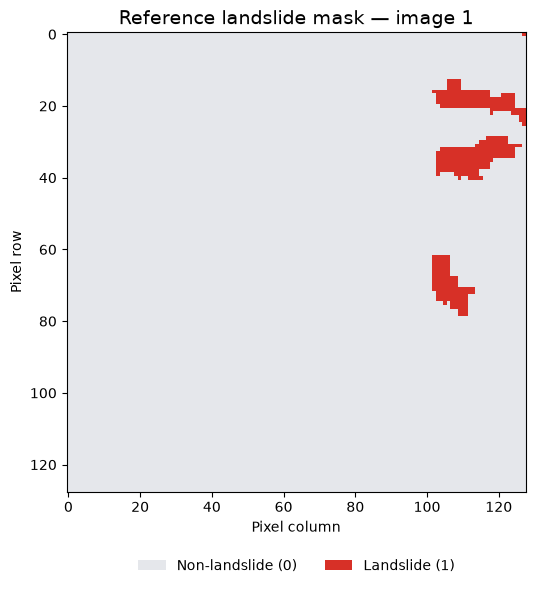

In [4]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

mask_colors = ListedColormap(["#e5e7eb", "#d73027"])

fig, ax = plt.subplots(figsize=(7, 6))

ax.imshow(
    mask,
    cmap=mask_colors,
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

ax.set_title("Reference landslide mask — image 1", fontsize=14)
ax.set_xlabel("Pixel column")
ax.set_ylabel("Pixel row")

ax.legend(
    handles=[
        Patch(facecolor="#e5e7eb", label="Non-landslide (0)"),
        Patch(facecolor="#d73027", label="Landslide (1)")
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=False
)

plt.tight_layout()
plt.show()

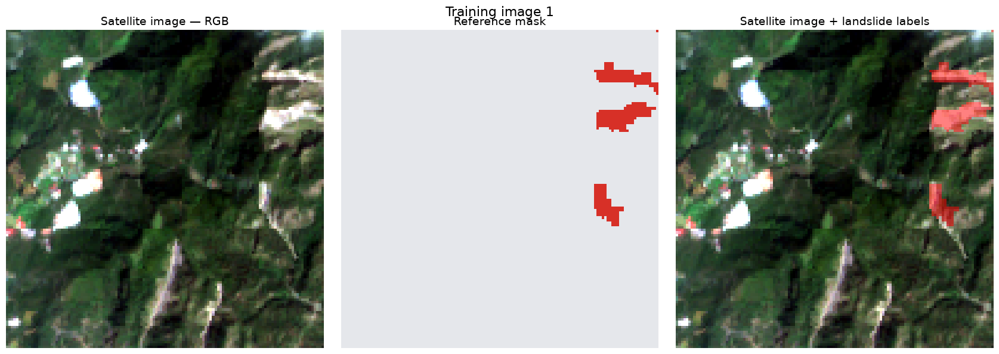

In [5]:
# Select red, green and blue bands.
# Dataset bands B4, B3, B2 correspond to Python indices 3, 2, 1.
rgb = image[:, :, [3, 2, 1]].astype(float)

# Improve contrast for display only.
low = np.percentile(rgb, 2, axis=(0, 1))
high = np.percentile(rgb, 98, axis=(0, 1))

rgb_display = np.clip(
    (rgb - low) / np.maximum(high - low, 1e-8),
    0,
    1
)

fig, axes = plt.subplots(1, 3, figsize=(17, 6))

axes[0].imshow(rgb_display)
axes[0].set_title("Satellite image — RGB", fontsize=14)

axes[1].imshow(
    mask,
    cmap=mask_colors,
    vmin=0,
    vmax=1,
    interpolation="nearest"
)
axes[1].set_title("Reference mask", fontsize=14)

axes[2].imshow(rgb_display)

# Red overlay only where the reference mask equals 1.
overlay = np.zeros((*mask.shape, 4))
overlay[mask == 1] = [1, 0, 0, 0.5]

axes[2].imshow(overlay)
axes[2].set_title("Satellite image + landslide labels", fontsize=14)

for ax in axes:
    ax.axis("off")

fig.suptitle("Training image 1", fontsize=16)
plt.tight_layout()
plt.show()

The RGB image and reference mask were displayed together. Landslide annotations cover 2.47% of this patch. Bright appearance alone does not distinguish all labelled landslide pixels from the background.

In [6]:
# Extract identifiers from the filenames.
image_ids = {
    path.stem.removeprefix("image_")
    for path in image_files
}

mask_ids = {
    path.stem.removeprefix("mask_")
    for path in mask_files
}

# Compare image and mask identifiers.
missing_masks = image_ids - mask_ids
missing_images = mask_ids - image_ids
matched_ids = image_ids & mask_ids

print("Training images:", len(image_files))
print("Training masks:", len(mask_files))
print("Matched identifiers:", len(matched_ids))
print("Images without masks:", len(missing_masks))
print("Masks without images:", len(missing_images))

if missing_masks:
    print("Example unmatched image IDs:", sorted(missing_masks)[:10])

if missing_images:
    print("Example unmatched mask IDs:", sorted(missing_images)[:10])

Training images: 3799
Training masks: 3799
Matched identifiers: 3799
Images without masks: 0
Masks without images: 0


All 3,799 training images have masks with matching identifiers. No unmatched images or masks were found. This confirms filename pairing; file integrity, dimensions, and label validity still require verification.

In [7]:
#Data Integrity Audit
import pandas as pd

audit_rows = []

# Numeric sorting: 1, 2, 3, ... rather than 1, 10, 100, ...
ordered_ids = sorted(matched_ids, key=int)

for position, sample_id in enumerate(ordered_ids, start=1):
    row = {"sample_id": sample_id}

    image_path = (
        DATA_DIR / "TrainData" / "img" / f"image_{sample_id}.h5"
    )
    mask_path = (
        DATA_DIR / "TrainData" / "mask" / f"mask_{sample_id}.h5"
    )

    try:
        # Load one pair at a time.
        with h5py.File(image_path, "r") as h5_file:
            current_image = h5_file["img"][:]

        with h5py.File(mask_path, "r") as h5_file:
            current_mask = h5_file["mask"][:]

        labels = np.unique(current_mask)

        row.update({
            "read_ok": True,
            "image_shape": str(current_image.shape),
            "mask_shape": str(current_mask.shape),
            "shape_ok": (
                current_image.shape == (128, 128, 14)
                and current_mask.shape == (128, 128)
            ),
            "nan_count": int(np.isnan(current_image).sum()),
            "inf_count": int(np.isinf(current_image).sum()),
            "labels_ok": bool(np.isin(labels, [0, 1]).all()),
            "mask_values": str(labels.tolist()),
            "total_pixels": int(current_mask.size),
            "landslide_pixels": int((current_mask == 1).sum()),
            "landslide_percent": float(
                100 * (current_mask == 1).sum() / current_mask.size
            ),
            "error": ""
        })

    except Exception as exc:
        row.update({
            "read_ok": False,
            "error": f"{type(exc).__name__}: {exc}"
        })

    audit_rows.append(row)

    if position % 500 == 0 or position == len(ordered_ids):
        print(f"Checked {position:,} / {len(ordered_ids):,} pairs")

audit_df = pd.DataFrame(audit_rows)

print("\nAudit preview:")
display(audit_df.head())

print("\nSuccessfully read pairs:", int(audit_df["read_ok"].sum()))
print("Unreadable pairs:", int((~audit_df["read_ok"]).sum()))

Checked 500 / 3,799 pairs
Checked 1,000 / 3,799 pairs
Checked 1,500 / 3,799 pairs
Checked 2,000 / 3,799 pairs
Checked 2,500 / 3,799 pairs
Checked 3,000 / 3,799 pairs
Checked 3,500 / 3,799 pairs
Checked 3,799 / 3,799 pairs

Audit preview:


,sample_id,read_ok,image_shape,mask_shape,shape_ok,nan_count,inf_count,labels_ok,mask_values,total_pixels,landslide_pixels,landslide_percent,error
0,1,True,"(128, 128, 14)","(128, 128)",True,0,0,True,"[0, 1]",16384,405,2.471924,
1,2,True,"(128, 128, 14)","(128, 128)",True,0,0,True,"[0, 1]",16384,937,5.718994,
2,3,True,"(128, 128, 14)","(128, 128)",True,0,0,True,[0],16384,0,0.000000,
3,4,True,"(128, 128, 14)","(128, 128)",True,0,0,True,"[0, 1]",16384,211,1.287842,
4,5,True,"(128, 128, 14)","(128, 128)",True,0,0,True,"[0, 1]",16384,265,1.617432,



Successfully read pairs: 3799
Unreadable pairs: 0


This audit checks file readability, expected dimensions, non-finite image values, and mask labels. It also records landslide coverage per patch without modifying the data.

In [8]:
# All pairs were readable in the previous output.
readable = audit_df.loc[audit_df["read_ok"]].copy()

summary = pd.Series({
    "Readable pairs": len(readable),
    "Pairs with unexpected dimensions":
        int((~readable["shape_ok"]).sum()),
    "Images containing NaN":
        int((readable["nan_count"] > 0).sum()),
    "Images containing infinity":
        int((readable["inf_count"] > 0).sum()),
    "Masks with unexpected labels":
        int((~readable["labels_ok"]).sum()),
    "Patches without landslide pixels":
        int((readable["landslide_pixels"] == 0).sum()),
    "Patches with landslide pixels":
        int((readable["landslide_pixels"] > 0).sum())
}, name="Count")

display(summary.to_frame())

# Show any pairs requiring further investigation.
issue_rows = readable.loc[
    (~readable["shape_ok"])
    | (readable["nan_count"] > 0)
    | (readable["inf_count"] > 0)
    | (~readable["labels_ok"])
]

print("\nPairs requiring investigation:", len(issue_rows))

if not issue_rows.empty:
    display(issue_rows.head(10))

,Count
Readable pairs,3799
Pairs with unexpected dimensions,0
Images containing NaN,0
Images containing infinity,0
Masks with unexpected labels,0
Patches without landslide pixels,1568
Patches with landslide pixels,2231



Pairs requiring investigation: 0


All 3,799 training image–mask pairs passed the readability, dimension, non-finite-value, and label checks. Of these, 1,568 patches (41.3%) contain no labelled landslide pixels, while 2,231 (58.7%) contain at least one. Annotation accuracy, duplication, and spatial overlap remain to be assessed.

In [10]:
#Pixel-level Class Balance
total_pixels = int(readable["total_pixels"].sum())
positive_pixels = int(readable["landslide_pixels"].sum())
negative_pixels = total_pixels - positive_pixels

class_balance = pd.DataFrame({
    "Class": ["Non-landslide (0)", "Landslide (1)"],
    "Pixel count": [negative_pixels, positive_pixels]
})

class_balance["Percentage"] = (
    100 * class_balance["Pixel count"] / total_pixels
)

# Format a separate copy for display.
balance_display = class_balance.copy()

balance_display["Pixel count"] = balance_display["Pixel count"].map(
    lambda value: f"{value:,}"
)
balance_display["Percentage"] = balance_display["Percentage"].map(
    lambda value: f"{value:.2f}%"
)

display(balance_display)

print(f"Total labelled pixels: {total_pixels:,}")

if positive_pixels > 0:
    ratio = negative_pixels / positive_pixels
    print(f"Non-landslide / landslide ratio: {ratio:.2f} to 1")

,Class,Pixel count,Percentage
0,Non-landslide (0),"60,800,026",97.68%
1,Landslide (1),"1,442,790",2.32%


Total labelled pixels: 62,242,816
Non-landslide / landslide ratio: 42.14 to 1


Across the 3,799 labelled patches, landslide pixels account for 2.32% of 62,242,816 pixels, with a non-landslide-to-landslide ratio of 42.14:1. An all-negative classifier would achieve 97.68% accuracy but zero landslide recall, demonstrating why accuracy alone is misleading.

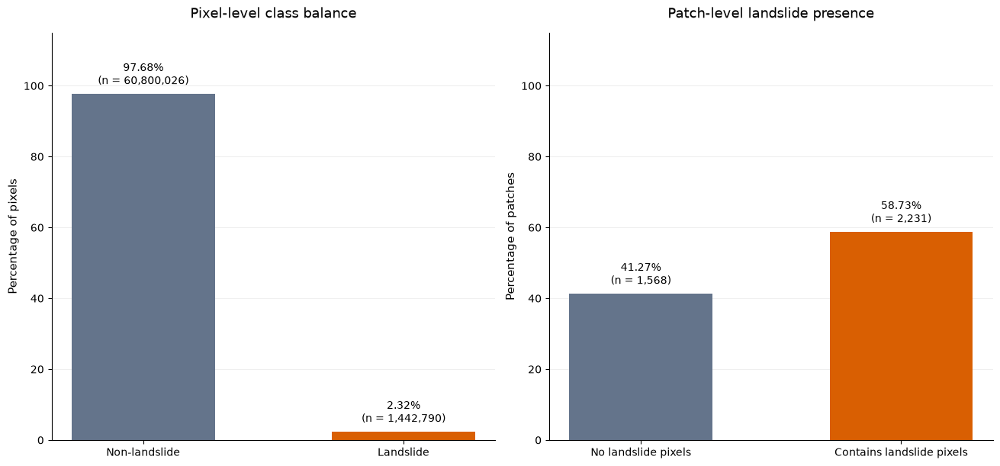

In [11]:
#Pixel-level Balance · Patch-level Presence
import matplotlib.pyplot as plt

# Counts calculated from the existing audit results.
pixel_counts = [negative_pixels, positive_pixels]

patch_counts = [
    int((readable["landslide_pixels"] == 0).sum()),
    int((readable["landslide_pixels"] > 0).sum())
]

colors = ["#64748b", "#d95f02"]

fig, axes = plt.subplots(
    1, 2, figsize=(13, 6), layout="constrained"
)

panels = [
    (
        axes[0],
        ["Non-landslide", "Landslide"],
        pixel_counts,
        "Pixel-level class balance",
        "Percentage of pixels"
    ),
    (
        axes[1],
        ["No landslide pixels", "Contains landslide pixels"],
        patch_counts,
        "Patch-level landslide presence",
        "Percentage of patches"
    )
]

for ax, labels, counts, title, ylabel in panels:
    percentages = [100 * count / sum(counts) for count in counts]

    bars = ax.bar(
        labels, percentages, color=colors, width=0.55
    )

    for bar, count, percentage in zip(bars, counts, percentages):
        ax.annotate(
            f"{percentage:.2f}%\n(n = {count:,})",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10
        )

    ax.set_title(title, fontsize=13, pad=14)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_ylim(0, 115)
    ax.set_yticks(range(0, 101, 20))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.show()

Landslide pixels represent only 2.32% of all labelled pixels, although 58.73% of patches contain some landslide. This highlights strong pixel-level imbalance and the need to evaluate both landslide detection and false alarms.

Patches containing landslide   2,231.00
Minimum coverage (%)               0.01
25th percentile (%)                0.60
Median coverage (%)                2.04
75th percentile (%)                5.16
Maximum coverage (%)              47.53


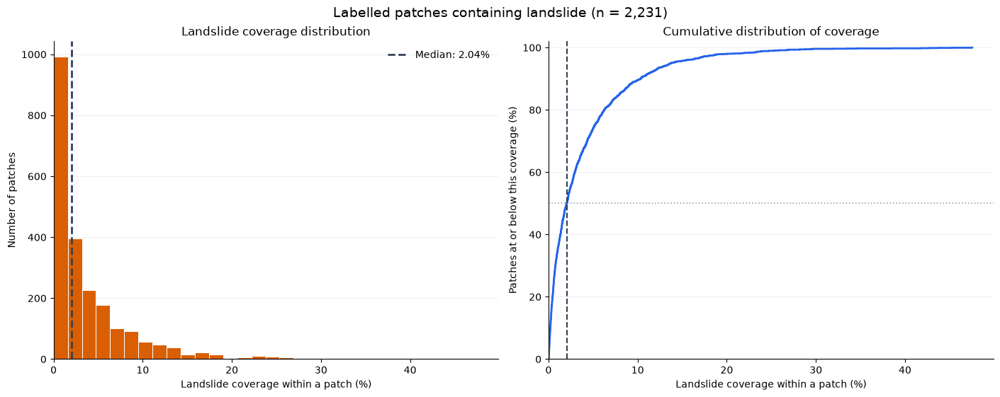

In [12]:
#Landslide Coverage Distribution
# Select coverage values for patches containing landslide.
positive_coverage = readable.loc[
    readable["landslide_pixels"] > 0,
    "landslide_percent"
].to_numpy()

median_coverage = float(np.median(positive_coverage))

# Summary calculated from the existing audit table.
coverage_summary = pd.Series({
    "Patches containing landslide": len(positive_coverage),
    "Minimum coverage (%)": positive_coverage.min(),
    "25th percentile (%)": np.percentile(positive_coverage, 25),
    "Median coverage (%)": median_coverage,
    "75th percentile (%)": np.percentile(positive_coverage, 75),
    "Maximum coverage (%)": positive_coverage.max()
})

print(coverage_summary.to_string(float_format=lambda x: f"{x:,.2f}"))

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5.5), layout="constrained"
)

# Histogram.
axes[0].hist(
    positive_coverage,
    bins=30,
    color="#d95f02",
    edgecolor="white",
    linewidth=0.7
)

axes[0].axvline(
    median_coverage,
    color="#334155",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_coverage:.2f}%"
)

axes[0].set_title("Landslide coverage distribution")
axes[0].set_xlabel("Landslide coverage within a patch (%)")
axes[0].set_ylabel("Number of patches")
axes[0].legend(frameon=False)

# Empirical cumulative distribution.
sorted_coverage = np.sort(positive_coverage)
cumulative_percent = (
    100 * np.arange(1, len(sorted_coverage) + 1)
    / len(sorted_coverage)
)

axes[1].step(
    np.r_[0, sorted_coverage],
    np.r_[0, cumulative_percent],
    where="post",
    color="#2563eb",
    linewidth=2
)

axes[1].axhline(
    50, color="#94a3b8", linestyle=":", linewidth=1.2
)
axes[1].axvline(
    median_coverage,
    color="#334155",
    linestyle="--",
    linewidth=1.5
)

axes[1].set_title("Cumulative distribution of coverage")
axes[1].set_xlabel("Landslide coverage within a patch (%)")
axes[1].set_ylabel("Patches at or below this coverage (%)")
axes[1].set_ylim(0, 102)
axes[1].set_yticks(range(0, 101, 20))

for ax in axes:
    ax.set_xlim(left=0)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    f"Labelled patches containing landslide (n = {len(positive_coverage):,})",
    fontsize=14
)

plt.show()

Among the 2,231 landslide-positive patches, median labelled coverage is 2.04%, and 75% have coverage at or below approximately 5.16%. The distribution is strongly right-skewed, supporting coverage-stratified error analysis. These values describe patch coverage, not individual landslide size.

In [13]:
#Exact Duplicate Detection
import hashlib

def array_hash(array):
    """Hash the shape, data type and exact array content."""
    hasher = hashlib.sha256()
    hasher.update(str(array.shape).encode())
    hasher.update(array.dtype.str.encode())
    hasher.update(np.ascontiguousarray(array).tobytes())
    return hasher.hexdigest()


hash_rows = []

for position, sample_id in enumerate(ordered_ids, start=1):
    image_path = (
        DATA_DIR / "TrainData" / "img" / f"image_{sample_id}.h5"
    )
    mask_path = (
        DATA_DIR / "TrainData" / "mask" / f"mask_{sample_id}.h5"
    )

    with h5py.File(image_path, "r") as h5_file:
        current_image = h5_file["img"][:]

    with h5py.File(mask_path, "r") as h5_file:
        current_mask = h5_file["mask"][:]

    hash_rows.append({
        "sample_id": sample_id,
        "image_hash": array_hash(current_image),
        "mask_hash": array_hash(current_mask)
    })

    if position % 500 == 0 or position == len(ordered_ids):
        print(f"Checked {position:,} / {len(ordered_ids):,} pairs")

hash_df = pd.DataFrame(hash_rows)

duplicate_rows = hash_df.loc[
    hash_df.duplicated("image_hash", keep=False)
].copy()

duplicate_groups = (
    duplicate_rows.groupby("image_hash")
    .agg(
        sample_ids=("sample_id", list),
        image_count=("sample_id", "size"),
        distinct_masks=("mask_hash", "nunique")
    )
    .reset_index(drop=True)
)

print("\nExact duplicate image groups:", len(duplicate_groups))
print("Images belonging to these groups:", len(duplicate_rows))

if not duplicate_groups.empty:
    display(duplicate_groups.head(20))

Checked 500 / 3,799 pairs
Checked 1,000 / 3,799 pairs
Checked 1,500 / 3,799 pairs
Checked 2,000 / 3,799 pairs
Checked 2,500 / 3,799 pairs
Checked 3,000 / 3,799 pairs
Checked 3,500 / 3,799 pairs
Checked 3,799 / 3,799 pairs

Exact duplicate image groups: 0
Images belonging to these groups: 0


No exact duplicate image arrays were detected among the 3,799 labelled training patches. No duplicate removal was required based on this check. Spatial overlap, near-duplicates, and duplication across the supplied dataset splits remain unassessed.

In [14]:
#Metadata investigation
def inspect_metadata(path):
    """Display file-level and internal-object metadata."""
    print(f"\nFile: {path.name}")

    with h5py.File(path, "r") as h5_file:
        print("File attributes:", dict(h5_file.attrs))

        def show_metadata(name, item):
            print(f"\nObject: {name}")
            print("Attributes:", dict(item.attrs))

            if isinstance(item, h5py.Dataset):
                print("Shape:", item.shape)
                print("Data type:", item.dtype)

        h5_file.visititems(show_metadata)


# Inspect three image files and one corresponding mask.
for sample_id in ["1", "100", "1000"]:
    path = (
        DATA_DIR / "TrainData" / "img" / f"image_{sample_id}.h5"
    )
    inspect_metadata(path)

inspect_metadata(
    DATA_DIR / "TrainData" / "mask" / "mask_1.h5"
)


File: image_1.h5
File attributes: {}

Object: img
Attributes: {}
Shape: (128, 128, 14)
Data type: float64

File: image_100.h5
File attributes: {}

Object: img
Attributes: {}
Shape: (128, 128, 14)
Data type: float64

File: image_1000.h5
File attributes: {}

Object: img
Attributes: {}
Shape: (128, 128, 14)
Data type: float64

File: mask_1.h5
File attributes: {}

Object: mask
Attributes: {}
Shape: (128, 128)
Data type: uint8


In [15]:
#Geographic Metadata Audit
import re
from collections import Counter
from pathlib import Path

import h5py

# Dataset folder defined earlier.
search_root = Path(DATA_DIR)

if not search_root.exists():
    raise FileNotFoundError(f"Dataset folder not found: {search_root}")

all_paths = sorted(
    path for path in search_root.rglob("*")
    if path.is_file()
)

# Terms used to flag potentially relevant metadata.
geo_pattern = re.compile(
    r"latitude|longitude|coordinate|geotransform|"
    r"transform|projection|epsg|crs|wkt|"
    r"geolocation|bounding|bounds|bbox|"
    r"easting|northing|spatial|region|location|"
    r"acquisition|scene|tile|(^|[/_\s])(lat|lon|lng|x|y)($|[/_\s])",
    flags=re.IGNORECASE
)

metadata_hits = []
attribute_rows = []
h5_errors = []
object_signatures = Counter()

# Keep previews short, even if an attribute contains a large array.
def short_preview(value, limit=250):
    if isinstance(value, bytes):
        text = value[:limit].decode("utf-8", errors="replace")
    elif isinstance(value, np.ndarray):
        text = (
            f"shape={value.shape}, dtype={value.dtype}, "
            f"first values={value.reshape(-1)[:8].tolist()}"
        )
    else:
        text = str(value)

    return text[:limit]


def inspect_attributes(obj, relative_path, object_name):
    for key in obj.attrs:
        value = obj.attrs[key]
        preview = short_preview(value)

        record = {
            "file": relative_path,
            "object": object_name,
            "attribute": key,
            "value_preview": preview
        }
        attribute_rows.append(record)

        if geo_pattern.search(f"{key} {preview}"):
            metadata_hits.append({
                **record,
                "match_type": "Potential geographic attribute"
            })


h5_paths = [
    path for path in all_paths
    if path.suffix.lower() in {".h5", ".hdf5", ".hdf"}
]

for position, path in enumerate(h5_paths, start=1):
    relative_path = str(path.relative_to(search_root))

    try:
        with h5py.File(path, "r") as h5_file:
            inspect_attributes(h5_file, relative_path, "/")

            def inspect_object(name, obj):
                inspect_attributes(obj, relative_path, name)

                if isinstance(obj, h5py.Dataset):
                    object_signatures[
                        (name, str(obj.shape), str(obj.dtype))
                    ] += 1

                    if geo_pattern.search(name):
                        # Read only small candidate datasets.
                        preview = (
                            short_preview(obj[()])
                            if obj.size <= 100
                            else "Not loaded: dataset has more than 100 elements"
                        )

                        metadata_hits.append({
                            "file": relative_path,
                            "object": name,
                            "attribute": "",
                            "value_preview": preview,
                            "match_type": "Potential geographic dataset"
                        })

            h5_file.visititems(inspect_object)

    except Exception as exc:
        h5_errors.append({
            "file": relative_path,
            "error": f"{type(exc).__name__}: {exc}"
        })

    if position % 1000 == 0 or position == len(h5_paths):
        print(f"Inspected {position:,} / {len(h5_paths):,} HDF5 files")


# List all non-HDF5 files: possible documentation or sidecars.
sidecar_paths = [
    path for path in all_paths
    if path.suffix.lower() not in {".h5", ".hdf5", ".hdf"}
]

sidecar_df = pd.DataFrame([
    {
        "file": str(path.relative_to(search_root)),
        "extension": path.suffix.lower(),
        "size_bytes": path.stat().st_size
    }
    for path in sidecar_paths
], columns=["file", "extension", "size_bytes"])

# Search small text files for relevant terms.
text_extensions = {
    ".txt", ".md", ".csv", ".tsv", ".json", ".geojson",
    ".xml", ".yaml", ".yml", ".prj", ".wld",
    ".tfw", ".jgw", ".pgw"
}

text_hits = []

for path in sidecar_paths:
    if (
        path.suffix.lower() in text_extensions
        and path.stat().st_size <= 2_000_000
    ):
        content = path.read_text(encoding="utf-8", errors="replace")

        for line_number, line in enumerate(content.splitlines(), start=1):
            if geo_pattern.search(line):
                text_hits.append({
                    "file": str(path.relative_to(search_root)),
                    "line": line_number,
                    "text_preview": line[:250]
                })

metadata_hits_df = pd.DataFrame(metadata_hits)
attributes_df = pd.DataFrame(attribute_rows)
text_hits_df = pd.DataFrame(text_hits)
metadata_errors_df = pd.DataFrame(h5_errors)

structure_df = pd.DataFrame([
    {
        "dataset_name": name,
        "shape": shape,
        "dtype": dtype,
        "file_count": count
    }
    for (name, shape, dtype), count in object_signatures.items()
])

print("\nSUMMARY")
print("Search folder:", search_root.resolve())
print("Total files:", len(all_paths))
print("HDF5 files inspected:", len(h5_paths))
print("HDF5 read errors:", len(h5_errors))
print("Attributes found:", len(attribute_rows))
print("Potential geographic metadata matches:", len(metadata_hits))
print("Non-HDF5 files:", len(sidecar_paths))
print("Relevant text lines:", len(text_hits))

print("\nInternal dataset structures:")
display(structure_df)

if not metadata_hits_df.empty:
    print("\nPotential metadata matches — first 30:")
    display(metadata_hits_df.head(30))

if not sidecar_df.empty:
    print("\nNon-HDF5 files — first 30:")
    display(sidecar_df.head(30))

if not text_hits_df.empty:
    print("\nText matches — first 30:")
    display(text_hits_df.head(30))

if not metadata_errors_df.empty:
    print("\nFiles that could not be inspected:")
    display(metadata_errors_df.head(30))

Inspected 1,000 / 8,643 HDF5 files
Inspected 2,000 / 8,643 HDF5 files
Inspected 3,000 / 8,643 HDF5 files
Inspected 4,000 / 8,643 HDF5 files
Inspected 5,000 / 8,643 HDF5 files
Inspected 6,000 / 8,643 HDF5 files
Inspected 7,000 / 8,643 HDF5 files
Inspected 8,000 / 8,643 HDF5 files
Inspected 8,643 / 8,643 HDF5 files

SUMMARY
Search folder: C:\Users\hadid\Ramen\ds-ml-project-template\data\archive
Total files: 8643
HDF5 files inspected: 8643
HDF5 read errors: 0
Attributes found: 0
Potential geographic metadata matches: 0
Non-HDF5 files: 0
Relevant text lines: 0

Internal dataset structures:


,dataset_name,shape,dtype,file_count
0,img,"(128, 128, 14)",float64,4844
1,mask,"(128, 128)",uint8,3799


All 8,643 extracted HDF5 files were inspected without structural read errors. No attributes, coordinate-related dataset names, or sidecar files were found. Exact patch locations and geographic independence cannot be established from this release. Evaluation will therefore be described as held-out patch evaluation, not verified geographic generalisation.

In [16]:
#Development Set · Final Test Set
from sklearn.model_selection import train_test_split

# Fixed choices for reproducibility.
RANDOM_STATE = 43
TEST_SIZE = 0.20

# Build one record per labelled patch.
split_manifest = audit_df[
    ["sample_id", "landslide_pixels"]
].copy()

split_manifest["sample_id"] = (
    split_manifest["sample_id"].astype(str)
)

split_manifest["has_landslide"] = (
    split_manifest["landslide_pixels"] > 0
).astype(int)

# Split whole patches, preserving landslide presence proportions.
dev_ids, test_ids = train_test_split(
    split_manifest["sample_id"].to_numpy(),
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=split_manifest["has_landslide"].to_numpy()
)

split_manifest["split"] = np.where(
    split_manifest["sample_id"].isin(test_ids),
    "final_test",
    "development"
)

# Verify separation and completeness.
assert set(dev_ids).isdisjoint(set(test_ids))
assert len(dev_ids) + len(test_ids) == len(split_manifest)
assert split_manifest["sample_id"].is_unique

print("Development patches:", len(dev_ids))
print("Final test patches:", len(test_ids))
print("Shared patch identifiers:", len(set(dev_ids) & set(test_ids)))
print("Random state:", RANDOM_STATE)

Development patches: 3039
Final test patches: 760
Shared patch identifiers: 0
Random state: 43


The labelled dataset was split into 3,039 development patches and 760 final-test patches, with no shared identifiers. No model has been trained yet.

In [17]:
#Feature Range Inspection
# Names follow the documented channel order.
FEATURE_NAMES = [
    "B1", "B2", "B3", "B4", "B5", "B6",
    "B7", "B8", "B9", "B10", "B11", "B12",
    "Slope", "Elevation"
]

# Manually selected sizes for this exploratory sample.
N_EDA_PATCHES = 100
PIXELS_PER_PATCH = 256

rng_eda = np.random.default_rng(RANDOM_STATE)

selected_eda_ids = rng_eda.choice(
    np.asarray(dev_ids),
    size=min(N_EDA_PATCHES, len(dev_ids)),
    replace=False
)

sampled_features = []

for sample_id in selected_eda_ids:
    path = (
        DATA_DIR / "TrainData" / "img" / f"image_{sample_id}.h5"
    )

    with h5py.File(path, "r") as h5_file:
        patch = h5_file["img"][:]

    # Each row becomes one pixel; columns remain the 14 channels.
    pixel_features = patch.reshape(-1, len(FEATURE_NAMES))

    selected_pixels = rng_eda.choice(
        len(pixel_features),
        size=min(PIXELS_PER_PATCH, len(pixel_features)),
        replace=False
    )

    sampled_features.append(pixel_features[selected_pixels])

eda_features = pd.DataFrame(
    np.vstack(sampled_features),
    columns=FEATURE_NAMES
)

feature_summary = pd.DataFrame({
    "Minimum": eda_features.min(),
    "1st percentile": eda_features.quantile(0.01),
    "Median": eda_features.median(),
    "99th percentile": eda_features.quantile(0.99),
    "Maximum": eda_features.max()
})

print("Development patches sampled:", len(selected_eda_ids))
print("Pixels sampled:", len(eda_features))
print(
    "Overlap with final-test patch IDs:",
    len(set(selected_eda_ids) & set(test_ids))
)

display(feature_summary.round(4))

Development patches sampled: 100
Pixels sampled: 25600
Overlap with final-test patch IDs: 0


,Minimum,1st percentile,Median,99th percentile,Maximum
B1,0.6863,0.7231,0.8922,1.3438,2.4806
B2,0.5942,0.6463,0.8634,1.6820,4.1776
B3,0.4160,0.5050,0.8954,2.0214,5.2184
B4,0.3369,0.3976,0.7952,3.2976,8.3608
B5,0.1719,0.2617,0.9863,2.4882,5.2628
B6,0.0963,0.1337,1.0700,1.8595,2.4313
B7,0.0658,0.1066,1.0508,1.9266,2.4683
B8,0.0567,0.0891,1.0637,2.0126,2.7476
B9,0.0608,0.0933,1.1527,2.3825,3.2593
B10,0.2210,0.6631,0.9947,3.5367,10.6102


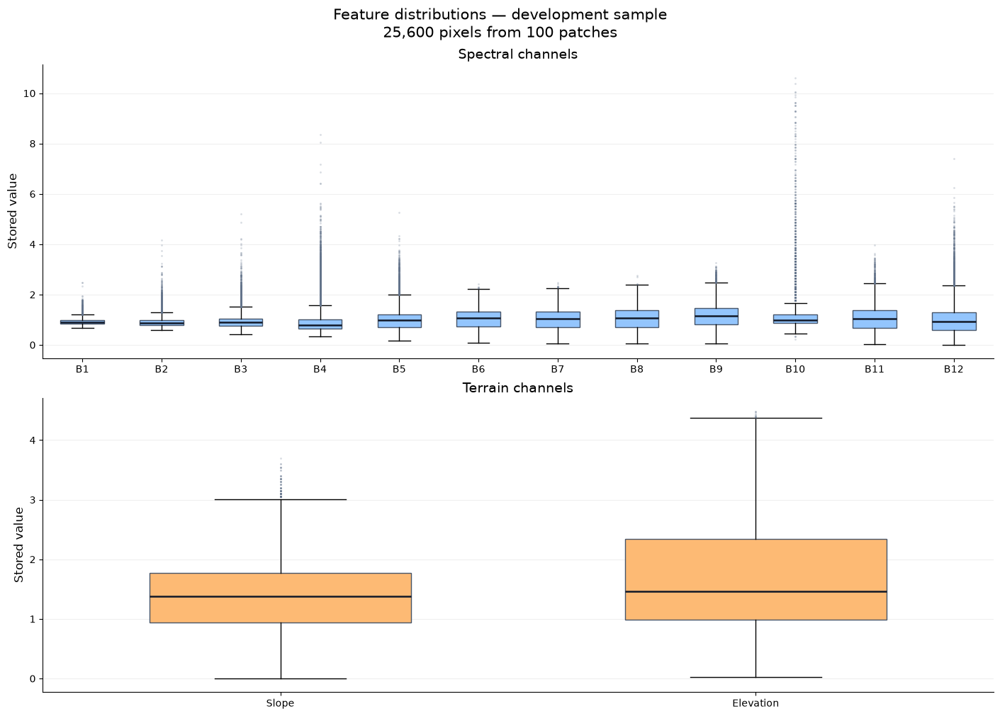

In [18]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 10),
    layout="constrained"
)

feature_groups = [
    (
        FEATURE_NAMES[:12],
        "Spectral channels",
        "#93c5fd"
    ),
    (
        FEATURE_NAMES[12:],
        "Terrain channels",
        "#fdba74"
    )
]

for ax, (columns, title, color) in zip(axes, feature_groups):
    values = [
        eda_features[column].to_numpy()
        for column in columns
    ]

    boxes = ax.boxplot(
        values,
        patch_artist=True,
        widths=0.55,
        whis=1.5,
        showfliers=True,
        medianprops={
            "color": "#111827",
            "linewidth": 1.8
        },
        flierprops={
            "marker": ".",
            "markersize": 2,
            "markeredgecolor": "#64748b",
            "alpha": 0.25
        }
    )

    for box in boxes["boxes"]:
        box.set_facecolor(color)
        box.set_edgecolor("#475569")

    ax.set_xticks(range(1, len(columns) + 1))
    ax.set_xticklabels(columns)
    ax.set_title(title, fontsize=14)
    ax.set_ylabel("Stored value", fontsize=12)

    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Feature distributions — development sample\n"
    f"{len(eda_features):,} pixels from "
    f"{len(selected_eda_ids):,} patches",
    fontsize=15
)

plt.show()

Feature distributions differ in spread and tail behaviour. Several spectral channels contain high-valued observations that require investigation rather than automatic removal. These pooled plots do not establish class separation or predictive importance.

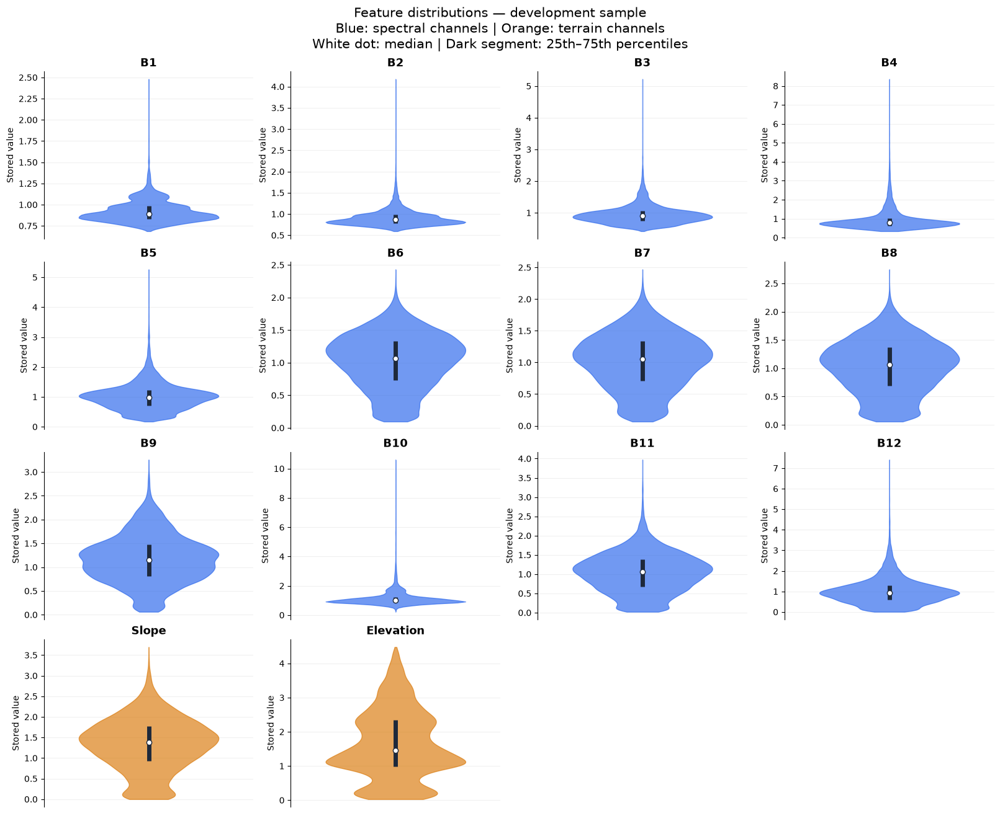

In [19]:
fig, axes = plt.subplots(
    4, 4,
    figsize=(16, 13),
    layout="constrained"
)

for index, (ax, feature) in enumerate(
    zip(axes.flat, FEATURE_NAMES)
):
    values = eda_features[feature].to_numpy()

    color = "#2563eb" if index < 12 else "#d97706"

    violin = ax.violinplot(
        values,
        positions=[1],
        widths=0.8,
        showmeans=False,
        showmedians=False,
        showextrema=False,
        points=150
    )

    for body in violin["bodies"]:
        body.set_facecolor(color)
        body.set_edgecolor(color)
        body.set_alpha(0.65)

    q25, median, q75 = np.percentile(values, [25, 50, 75])

    ax.vlines(
        1, q25, q75,
        color="#1e293b",
        linewidth=5,
        zorder=3
    )

    ax.scatter(
        1, median,
        s=35,
        color="white",
        edgecolor="#1e293b",
        zorder=4
    )

    ax.set_title(feature, fontsize=13, fontweight="bold")
    ax.set_xticks([])
    ax.set_xlim(0.4, 1.6)
    ax.set_ylabel("Stored value", fontsize=10)

    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.18)

    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)

# Hide the two unused panels.
for ax in axes.flat[len(FEATURE_NAMES):]:
    ax.set_visible(False)

fig.suptitle(
    "Feature distributions — development sample\n"
    "Blue: spectral channels | Orange: terrain channels\n"
    "White dot: median | Dark segment: 25th–75th percentiles",
    fontsize=15
)

plt.show()

Violin plots reveal long upper tails in several spectral channels and multiple density peaks in the stored elevation values. These patterns describe the sampled inputs; they do not establish geographic groups, data errors, or predictive importance.

Original slope = stored slope × 20.29228266

Original elevation = stored elevation × 772.83144788
The dataset contributor documents division by per-channel mean values. Stored slope and elevation are therefore scaled ratios, not directly degrees or metres. Conversion to physical units remains conditional on verifying the downloaded release and original units.

In [20]:
#Class-wise Feature Analysis
rng_class_eda = np.random.default_rng(RANDOM_STATE)

labeled_parts = []

for sample_id in selected_eda_ids:
    image_path = (
        DATA_DIR / "TrainData" / "img" / f"image_{sample_id}.h5"
    )
    mask_path = (
        DATA_DIR / "TrainData" / "mask" / f"mask_{sample_id}.h5"
    )

    with h5py.File(image_path, "r") as h5_file:
        patch_image = h5_file["img"][:]

    with h5py.File(mask_path, "r") as h5_file:
        patch_mask = h5_file["mask"][:]

    features_flat = patch_image.reshape(-1, len(FEATURE_NAMES))
    labels_flat = patch_mask.reshape(-1)

    # The same positions select both features and labels.
    positions = rng_class_eda.choice(
        len(labels_flat),
        size=PIXELS_PER_PATCH,
        replace=False
    )

    patch_sample = pd.DataFrame(
        features_flat[positions],
        columns=FEATURE_NAMES
    )

    patch_sample["target"] = labels_flat[positions]
    patch_sample["sample_id"] = str(sample_id)

    labeled_parts.append(patch_sample)

eda_labeled = pd.concat(labeled_parts, ignore_index=True)

assert len(eda_labeled) == (
    len(selected_eda_ids) * PIXELS_PER_PATCH
)
assert set(eda_labeled["sample_id"]).isdisjoint(
    set(map(str, test_ids))
)

print("Sampled pixels:", len(eda_labeled))
print("Development patches:", eda_labeled["sample_id"].nunique())

print("\nSampled pixels per class:")
print(eda_labeled["target"].value_counts().sort_index())

print("\nMedian stored values by class:")
display(
    eda_labeled.groupby("target")[FEATURE_NAMES]
    .median()
    .T
    .rename(columns={
        0: "Non-landslide",
        1: "Landslide"
    })
    .round(4)
)

Sampled pixels: 25600
Development patches: 100

Sampled pixels per class:
target
0    24777
1      823
Name: count, dtype: int64

Median stored values by class:


target,Non-landslide,Landslide
B1,0.8886,1.1000
B2,0.8586,1.3060
B3,0.8878,1.5375
B4,0.7840,2.2553
B5,0.9739,1.7233
B6,1.0738,0.9801
B7,1.0610,0.8564
B8,1.0792,0.8371
B9,1.1571,1.0340
B10,0.9947,1.1052


The exploratory sample contains 823 landslide pixels (3.21%). Landslide pixels show higher median stored values in B4, B12, slope, and elevation, and lower values in B8. These differences require distribution-level and model-based evaluation before drawing predictive conclusions.

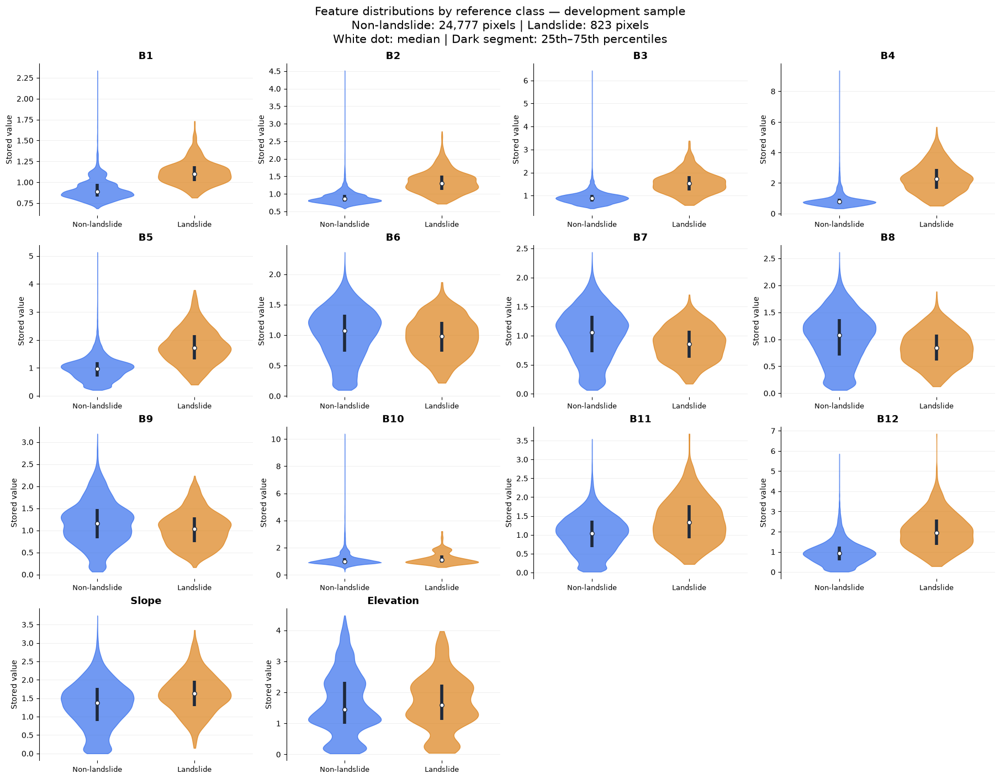

In [21]:
#Class-wise Violin Plots
class_colors = ["#2563eb", "#d97706"]
class_labels = ["Non-landslide", "Landslide"]

class_counts = (
    eda_labeled["target"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

fig, axes = plt.subplots(
    4, 4,
    figsize=(18, 14),
    layout="constrained"
)

for ax, feature in zip(axes.flat, FEATURE_NAMES):
    for position, class_value in enumerate([0, 1], start=1):
        values = eda_labeled.loc[
            eda_labeled["target"] == class_value,
            feature
        ].to_numpy()

        violin = ax.violinplot(
            values,
            positions=[position],
            widths=0.75,
            showextrema=False,
            points=150
        )

        for body in violin["bodies"]:
            body.set_facecolor(class_colors[class_value])
            body.set_edgecolor(class_colors[class_value])
            body.set_alpha(0.65)

        q25, median, q75 = np.percentile(
            values, [25, 50, 75]
        )

        ax.vlines(
            position, q25, q75,
            color="#1e293b",
            linewidth=4,
            zorder=3
        )

        ax.scatter(
            position, median,
            color="white",
            edgecolor="#1e293b",
            s=28,
            zorder=4
        )

    ax.set_title(feature, fontsize=13, fontweight="bold")
    ax.set_xticks([1, 2])
    ax.set_xticklabels(class_labels, fontsize=9)
    ax.set_xlim(0.4, 2.6)
    ax.set_ylabel("Stored value", fontsize=10)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.18)

    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)

for ax in axes.flat[len(FEATURE_NAMES):]:
    ax.set_visible(False)

fig.suptitle(
    "Feature distributions by reference class — development sample\n"
    f"Non-landslide: {class_counts[0]:,} pixels | "
    f"Landslide: {class_counts[1]:,} pixels\n"
    "White dot: median | Dark segment: 25th–75th percentiles",
    fontsize=15
)

plt.show()

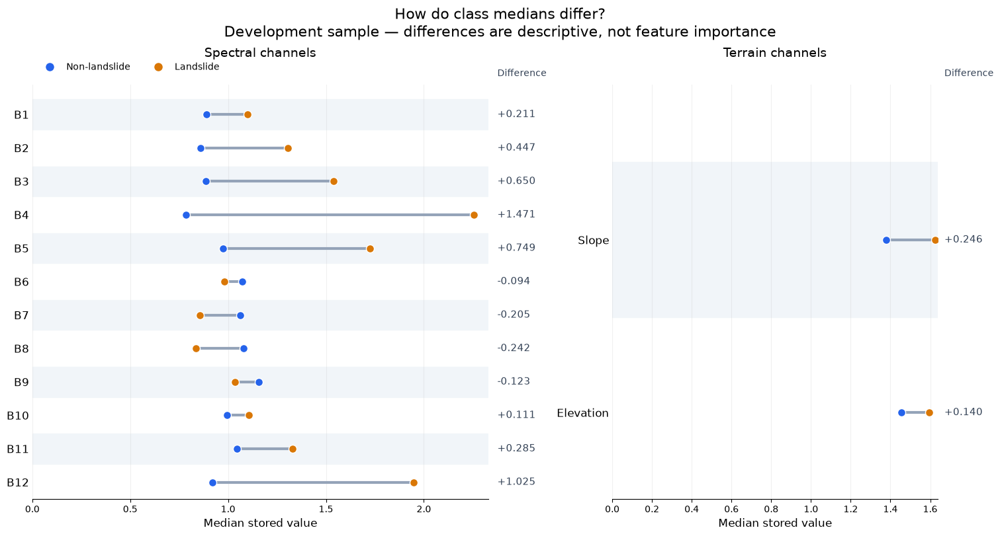

In [22]:
#Dumbbell Plot
from matplotlib.lines import Line2D

# Calculate medians from the existing labelled development sample.
class_medians = (
    eda_labeled.groupby("target")[FEATURE_NAMES]
    .median()
    .T
)

class_medians.columns = ["Non-landslide", "Landslide"]

class_medians["Difference"] = (
    class_medians["Landslide"]
    - class_medians["Non-landslide"]
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 8),
    gridspec_kw={"width_ratios": [1.4, 1]},
    layout="constrained"
)

groups = [
    (FEATURE_NAMES[:12], "Spectral channels"),
    (FEATURE_NAMES[12:], "Terrain channels")
]

for ax, (features, title) in zip(axes, groups):
    table = class_medians.loc[features]
    y_positions = np.arange(len(features))

    # Subtle alternating row backgrounds.
    for row in y_positions:
        if row % 2 == 0:
            ax.axhspan(
                row - 0.45, row + 0.45,
                color="#f1f5f9", zorder=0
            )

    for row, feature in enumerate(features):
        negative_median = table.loc[feature, "Non-landslide"]
        positive_median = table.loc[feature, "Landslide"]

        ax.plot(
            [negative_median, positive_median],
            [row, row],
            color="#94a3b8",
            linewidth=3,
            zorder=2
        )

        ax.text(
            1.02, row,
            f'{table.loc[feature, "Difference"]:+.3f}',
            transform=ax.get_yaxis_transform(),
            va="center",
            fontsize=11,
            color="#334155"
        )

    ax.scatter(
        table["Non-landslide"], y_positions,
        color="#2563eb", s=75,
        edgecolor="white", linewidth=1,
        zorder=3
    )

    ax.scatter(
        table["Landslide"], y_positions,
        color="#d97706", s=75,
        edgecolor="white", linewidth=1,
        zorder=4
    )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(features, fontsize=12)
    ax.set_ylim(len(features) - 0.5, -0.9)
    ax.set_xlim(left=0)
    ax.margins(x=0.15)
    ax.set_xlabel("Median stored value", fontsize=12)
    ax.set_title(title, fontsize=14, pad=30)

    ax.text(
        1.02, 1.02, "Difference",
        transform=ax.transAxes,
        fontsize=10,
        color="#334155"
    )

    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.18)
    ax.tick_params(axis="y", length=0)

    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)

legend_handles = [
    Line2D(
        [0], [0], marker="o", linestyle="",
        color="#2563eb", markersize=8,
        label="Non-landslide"
    ),
    Line2D(
        [0], [0], marker="o", linestyle="",
        color="#d97706", markersize=8,
        label="Landslide"
    )
]

axes[0].legend(
    handles=legend_handles,
    loc="lower left",
    bbox_to_anchor=(0, 1.01),
    ncol=2,
    frameon=False
)

fig.suptitle(
    "How do class medians differ?\n"
    "Development sample — differences are descriptive, not feature importance",
    fontsize=16
)

plt.show()

Landslide pixels have higher sampled medians in B4, B12, slope, and elevation, and lower medians in B6–B9. These are descriptive differences in stored values, not measures of predictive importance or statistical significance.

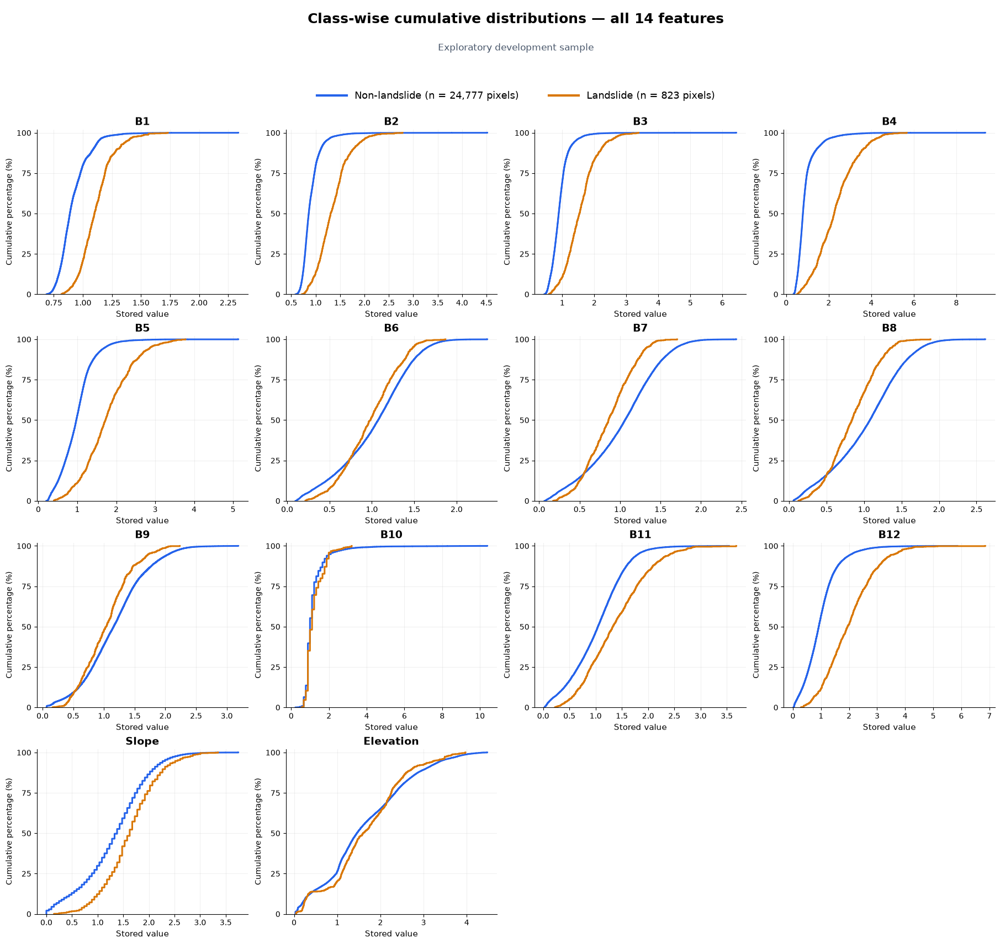

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

class_settings = [
    (0, "Non-landslide", "#2563eb"),
    (1, "Landslide", "#d97706")
]

class_counts = (
    eda_labeled["target"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

# Separate header area prevents legend/title overlap.
fig = plt.figure(figsize=(18, 17), layout="constrained")

grid = fig.add_gridspec(
    5, 4,
    height_ratios=[0.65, 1, 1, 1, 1]
)

header = fig.add_subplot(grid[0, :])
header.set_axis_off()

header.text(
    0.5, 0.93,
    "Class-wise cumulative distributions — all 14 features",
    transform=header.transAxes,
    ha="center",
    va="top",
    fontsize=18,
    fontweight="bold"
)

header.text(
    0.5, 0.60,
    "Exploratory development sample",
    transform=header.transAxes,
    ha="center",
    va="center",
    fontsize=12,
    color="#475569"
)

legend_handles = [
    Line2D(
        [0], [0],
        color=color,
        linewidth=3,
        label=f"{label} (n = {class_counts[class_value]:,} pixels)"
    )
    for class_value, label, color in class_settings
]

header.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=2,
    frameon=False,
    fontsize=13,
    handlelength=3,
    columnspacing=3
)

for index, feature in enumerate(FEATURE_NAMES):
    row = 1 + index // 4
    column = index % 4

    ax = fig.add_subplot(grid[row, column])

    for class_value, label, color in class_settings:
        values = np.sort(
            eda_labeled.loc[
                eda_labeled["target"] == class_value,
                feature
            ].to_numpy()
        )

        cumulative_percent = (
            100 * np.arange(1, len(values) + 1) / len(values)
        )

        ax.step(
            np.r_[values[0], values],
            np.r_[0, cumulative_percent],
            where="post",
            color=color,
            linewidth=2.2
        )

    ax.set_title(feature, fontsize=14, fontweight="bold")
    ax.set_xlabel("Stored value", fontsize=11)
    ax.set_ylabel("Cumulative percentage (%)", fontsize=10)

    ax.set_ylim(0, 102)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.tick_params(axis="both", labelsize=10)

    ax.set_axisbelow(True)
    ax.grid(alpha=0.18)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.show()

Several spectral channels show clearer class-distribution differences than the terrain channels in this exploratory sample. B10 has closely aligned ECDFs, while elevation shows crossing distributions. These observations guide further investigation, not feature exclusion or claims of predictive performance.

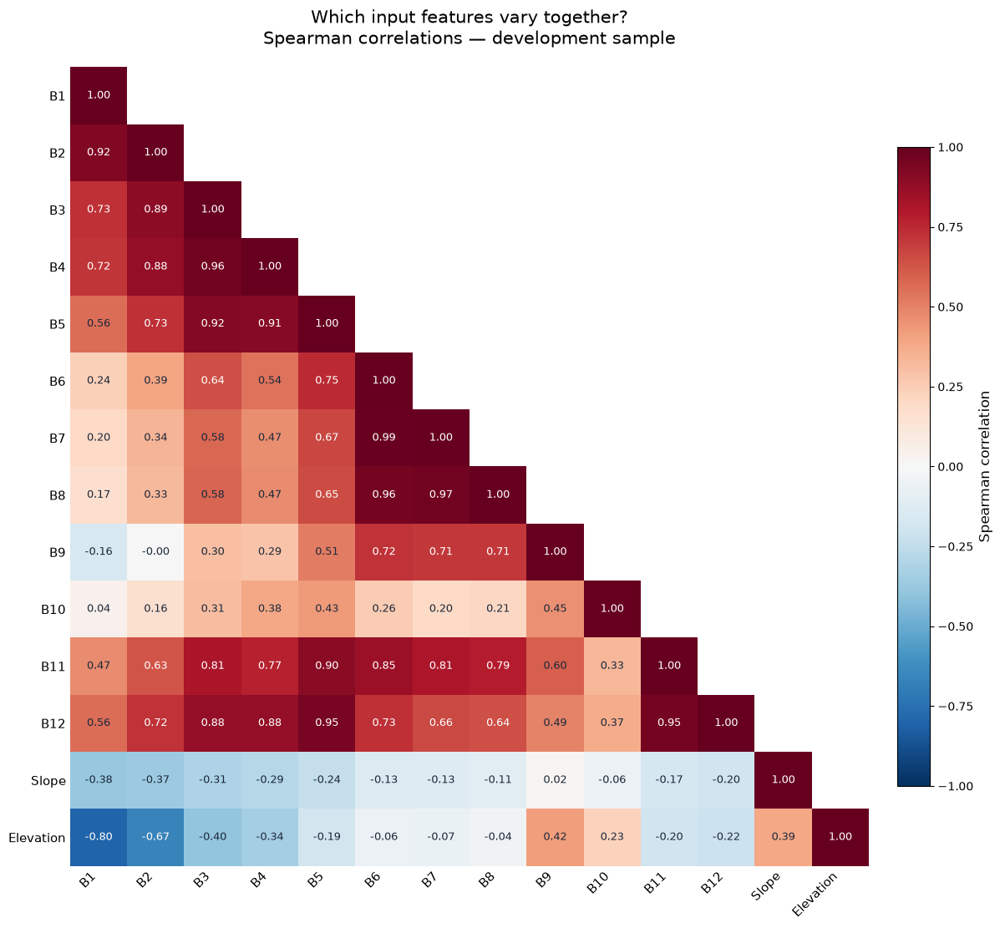

In [26]:
#Spearman Correlation
# Use only the 14 input features from the development sample.
spearman_corr = eda_labeled[FEATURE_NAMES].corr(
    method="spearman"
)

# Show the lower triangle to avoid repeating every relationship.
upper_triangle = np.triu(
    np.ones(spearman_corr.shape, dtype=bool),
    k=1
)

plot_values = np.ma.array(
    spearman_corr.to_numpy(),
    mask=upper_triangle
)

fig, ax = plt.subplots(
    figsize=(13, 11),
    layout="constrained"
)

heatmap = ax.imshow(
    plot_values,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    interpolation="nearest"
)

positions = np.arange(len(FEATURE_NAMES))

ax.set_xticks(positions)
ax.set_yticks(positions)
ax.set_xticklabels(
    FEATURE_NAMES, rotation=45, ha="right", fontsize=11
)
ax.set_yticklabels(FEATURE_NAMES, fontsize=11)

# Write the calculated correlations inside the visible cells.
for row in range(len(FEATURE_NAMES)):
    for column in range(row + 1):
        value = spearman_corr.iloc[row, column]

        ax.text(
            column,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if abs(value) >= 0.6 else "#1e293b"
        )

colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    shrink=0.8,
    pad=0.03
)
colorbar.set_label("Spearman correlation", fontsize=12)

ax.set_title(
    "Which input features vary together?\n"
    "Spearman correlations — development sample",
    fontsize=15,
    pad=20
)

ax.tick_params(length=0)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.show()

Strong positive rank correlations occur among several spectral channels, particularly B6–B7 (0.99). Elevation is strongly negatively correlated with B1 (−0.80). These relationships suggest shared information but do not establish causality, feature importance, or grounds for automatic removal.

In [27]:
#Nested Cross-Validation
from sklearn.model_selection import StratifiedKFold

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 3

# One row per development patch.
dev_manifest = (
    split_manifest.loc[
        split_manifest["split"] == "development",
        ["sample_id", "has_landslide"]
    ]
    .copy()
    .reset_index(drop=True)
)

dev_manifest["sample_id"] = (
    dev_manifest["sample_id"].astype(str)
)

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

nested_splits = []
fold_summary = []

for fold_number, (train_idx, eval_idx) in enumerate(
    outer_cv.split(
        dev_manifest["sample_id"],
        dev_manifest["has_landslide"]
    ),
    start=1
):
    outer_train = dev_manifest.iloc[train_idx].reset_index(drop=True)
    outer_eval = dev_manifest.iloc[eval_idx].reset_index(drop=True)

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE + fold_number
    )

    inner_splits = []

    for inner_train_idx, inner_val_idx in inner_cv.split(
        outer_train["sample_id"],
        outer_train["has_landslide"]
    ):
        inner_train_ids = (
            outer_train.iloc[inner_train_idx]["sample_id"].to_numpy()
        )
        inner_val_ids = (
            outer_train.iloc[inner_val_idx]["sample_id"].to_numpy()
        )

        assert set(inner_train_ids).isdisjoint(inner_val_ids)

        inner_splits.append({
            "train_ids": inner_train_ids,
            "validation_ids": inner_val_ids
        })

    outer_train_ids = outer_train["sample_id"].to_numpy()
    outer_eval_ids = outer_eval["sample_id"].to_numpy()

    assert set(outer_train_ids).isdisjoint(outer_eval_ids)
    assert set(outer_train_ids).isdisjoint(map(str, test_ids))
    assert set(outer_eval_ids).isdisjoint(map(str, test_ids))

    nested_splits.append({
        "outer_fold": fold_number,
        "train_ids": outer_train_ids,
        "evaluation_ids": outer_eval_ids,
        "inner_splits": inner_splits
    })

    fold_summary.append({
        "Outer fold": fold_number,
        "Training patches": len(outer_train),
        "Evaluation patches": len(outer_eval),
        "Evaluation positive patches": int(
            outer_eval["has_landslide"].sum()
        ),
        "Inner folds": len(inner_splits)
    })

# Every development patch must appear once in outer evaluation.
all_evaluation_ids = np.concatenate([
    fold["evaluation_ids"] for fold in nested_splits
])

assert len(all_evaluation_ids) == len(dev_manifest)
assert len(set(all_evaluation_ids)) == len(dev_manifest)

display(pd.DataFrame(fold_summary))

print("Final-test patches included: 0")
print("Every development patch has exactly one outer evaluation assignment.")

,Outer fold,Training patches,Evaluation patches,Evaluation positive patches,Inner folds
0,1,2431,608,357,3
1,2,2431,608,357,3
2,3,2431,608,357,3
3,4,2431,608,357,3
4,5,2432,607,357,3


Final-test patches included: 0
Every development patch has exactly one outer evaluation assignment.


Five outer folds were created, each with three inner folds. Outer evaluation sets contain 607–608 patches, including 357 landslide-positive patches each. Every development patch appears once in outer evaluation, and the final test set is excluded.

In [28]:
# Predefined evaluation choices; no model is trained here.
PRIMARY_METRIC = "F2"
BETA = 2

# Candidate probability thresholds for inner validation.
THRESHOLDS = np.unique(
    np.concatenate([
        np.array([0.001, 0.005]),
        np.arange(1, 100) / 100
    ])
)

SECONDARY_METRICS = [
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "IoU",
    "Average precision"
]

print("Primary metric:", PRIMARY_METRIC)
print("Beta:", BETA)
print("Number of candidate thresholds:", len(THRESHOLDS))
print("Threshold range:", THRESHOLDS.min(), "to", THRESHOLDS.max())
print("Secondary metrics:", ", ".join(SECONDARY_METRICS))

Primary metric: F2
Beta: 2
Number of candidate thresholds: 101
Threshold range: 0.001 to 0.99
Secondary metrics: Precision, Recall, Specificity, F1, IoU, Average precision


In [29]:
def metrics_from_counts(tn, fp, fn, tp, beta=BETA):
    """Calculate binary classification metrics from pixel counts."""

    counts = np.asarray([tn, fp, fn, tp], dtype=float)

    if not np.isfinite(counts).all() or (counts < 0).any():
        raise ValueError("Counts must be finite and non-negative.")

    if not np.isfinite(beta) or beta <= 0:
        raise ValueError("Beta must be finite and positive.")

    def safe_divide(numerator, denominator):
        return (
            numerator / denominator
            if denominator > 0
            else np.nan
        )

    precision = safe_divide(tp, tp + fp)
    recall = safe_divide(tp, tp + fn)
    specificity = safe_divide(tn, tn + fp)

    f1 = safe_divide(
        2 * tp,
        2 * tp + fp + fn
    )

    f_beta = safe_divide(
        (1 + beta**2) * tp,
        (1 + beta**2) * tp + beta**2 * fn + fp
    )

    iou = safe_divide(tp, tp + fp + fn)

    balanced_accuracy = (
        (recall + specificity) / 2
        if np.isfinite(recall) and np.isfinite(specificity)
        else np.nan
    )

    return {
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1": f1,
        f"F{beta:g}": f_beta,
        "IoU": iou,
        "Balanced accuracy": balanced_accuracy,
        "Accuracy": safe_divide(
            tp + tn,
            tp + tn + fp + fn
        )
    }


print(f"Metric function ready. Current beta: {BETA}")

Metric function ready. Current beta: 2


In [30]:
#Baseline Models
# Index the audit table by patch identifier.
audit_by_id = audit_df.copy()
audit_by_id["sample_id"] = audit_by_id["sample_id"].astype(str)
audit_by_id = audit_by_id.set_index("sample_id")

baseline_rows = []

for fold in nested_splits:
    evaluation_ids = list(map(str, fold["evaluation_ids"]))
    fold_audit = audit_by_id.loc[evaluation_ids]

    total = int(fold_audit["total_pixels"].sum())
    positive = int(fold_audit["landslide_pixels"].sum())
    negative = total - positive

    # Order of counts: TN, FP, FN, TP.
    baseline_counts = {
        "Always non-landslide": (negative, 0, positive, 0),
        "Always landslide": (0, negative, 0, positive)
    }

    for model_name, counts in baseline_counts.items():
        scores = metrics_from_counts(*counts)

        baseline_rows.append({
            "Outer fold": fold["outer_fold"],
            "Model": model_name,
            **scores
        })

baseline_results = pd.DataFrame(baseline_rows)

metrics_to_show = [
    "F2", "Recall", "Precision", "Specificity", "F1", "IoU", "Accuracy"
]

print("Baseline results for each outer fold:")
display(
    baseline_results[
        ["Outer fold", "Model"] + metrics_to_show
    ].round(4)
)

print("\nMean scores across the five outer folds:")
display(
    baseline_results.groupby("Model")[metrics_to_show]
    .mean()
    .round(4)
)

print("\nFinal-test patches used: 0")

Baseline results for each outer fold:


,Outer fold,Model,F2,Recall,Precision,Specificity,F1,IoU,Accuracy
0,1,Always non-landslide,0.0000,0.0,NaN,1.0,0.0000,0.0000,0.9749
1,1,Always landslide,0.1142,1.0,0.0251,0.0,0.0490,0.0251,0.0251
2,2,Always non-landslide,0.0000,0.0,NaN,1.0,0.0000,0.0000,0.9771
3,2,Always landslide,0.1051,1.0,0.0229,0.0,0.0449,0.0229,0.0229
4,3,Always non-landslide,0.0000,0.0,NaN,1.0,0.0000,0.0000,0.9774
5,3,Always landslide,0.1036,1.0,0.0226,0.0,0.0442,0.0226,0.0226
6,4,Always non-landslide,0.0000,0.0,NaN,1.0,0.0000,0.0000,0.9755
7,4,Always landslide,0.1118,1.0,0.0245,0.0,0.0479,0.0245,0.0245
8,5,Always non-landslide,0.0000,0.0,NaN,1.0,0.0000,0.0000,0.9770
9,5,Always landslide,0.1054,1.0,0.0230,0.0,0.0450,0.0230,0.0230



Mean scores across the five outer folds:


,F2,Recall,Precision,Specificity,F1,IoU,Accuracy
Model,,,,,,,
Always landslide,0.108,1.0,0.0236,0.0,0.0462,0.0236,0.0236
Always non-landslide,0.000,0.0,NaN,1.0,0.0000,0.0000,0.9764



Final-test patches used: 0


The all-negative baseline achieves 97.64% mean accuracy but zero landslide recall. The all-positive baseline achieves perfect recall but only 2.36% precision and a mean F2 of approximately 0.108. These provide reference scores for learned models; the final test set remains unused.An F2 of 0.108 is low, as expected for an all-positive baseline with many false alarms. It is a reference score, not the performance of a trained model. 

In [31]:
TRAIN_PIXELS_PER_PATCH = 128

# Sort identifiers for a reproducible processing order.
development_ids = sorted(map(str, dev_ids), key=int)

n_sampled_pixels = (
    len(development_ids) * TRAIN_PIXELS_PER_PATCH
)

X_dev_pixels = np.empty(
    (n_sampled_pixels, len(FEATURE_NAMES)),
    dtype=np.float32
)

y_dev_pixels = np.empty(
    n_sampled_pixels,
    dtype=np.uint8
)

pixel_patch_ids = np.empty(
    n_sampled_pixels,
    dtype=object
)

for position, sample_id in enumerate(development_ids):
    image_path = (
        DATA_DIR / "TrainData" / "img" / f"image_{sample_id}.h5"
    )
    mask_path = (
        DATA_DIR / "TrainData" / "mask" / f"mask_{sample_id}.h5"
    )

    with h5py.File(image_path, "r") as h5_file:
        patch_features = h5_file["img"][:].reshape(
            -1, len(FEATURE_NAMES)
        )

    with h5py.File(mask_path, "r") as h5_file:
        patch_labels = h5_file["mask"][:].reshape(-1)

    # Each patch has a stable sampling seed.
    patch_rng = np.random.default_rng(
        np.random.SeedSequence([RANDOM_STATE, int(sample_id)])
    )

    selected_positions = patch_rng.choice(
        len(patch_labels),
        size=TRAIN_PIXELS_PER_PATCH,
        replace=False
    )

    start = position * TRAIN_PIXELS_PER_PATCH
    stop = start + TRAIN_PIXELS_PER_PATCH

    X_dev_pixels[start:stop] = patch_features[selected_positions]
    y_dev_pixels[start:stop] = patch_labels[selected_positions]
    pixel_patch_ids[start:stop] = sample_id

    completed = position + 1

    if completed % 500 == 0 or completed == len(development_ids):
        print(
            f"Sampled {completed:,} / "
            f"{len(development_ids):,} development patches"
        )

assert set(pixel_patch_ids).isdisjoint(map(str, test_ids))
assert np.isfinite(X_dev_pixels).all()

labels, counts = np.unique(y_dev_pixels, return_counts=True)

print("\nFeature array shape:", X_dev_pixels.shape)
print("Label array shape:", y_dev_pixels.shape)
print("Represented patches:", len(set(pixel_patch_ids)))
print("Final-test patches included: 0")

for label, count in zip(labels, counts):
    percentage = 100 * count / len(y_dev_pixels)
    print(f"Class {label}: {count:,} pixels ({percentage:.2f}%)")

Sampled 500 / 3,039 development patches
Sampled 1,000 / 3,039 development patches
Sampled 1,500 / 3,039 development patches
Sampled 2,000 / 3,039 development patches
Sampled 2,500 / 3,039 development patches
Sampled 3,000 / 3,039 development patches
Sampled 3,039 / 3,039 development patches

Feature array shape: (388992, 14)
Label array shape: (388992,)
Represented patches: 3039
Final-test patches included: 0
Class 0: 379,712 pixels (97.61%)
Class 1: 9,280 pixels (2.39%)


Reproducible sampling produced 388,992 pixels from all 3,039 development patches, including 9,280 landslide pixels (2.39%). Patch identifiers are preserved, and no final-test patches were included.

In [32]:
# Count sampled positive pixels for every development patch.
sampled_positive_counts = (
    pd.DataFrame({
        "sample_id": pixel_patch_ids,
        "positive": y_dev_pixels
    })
    .groupby("sample_id")["positive"]
    .sum()
    .rename("sampled_positive_pixels")
)

sampling_audit = (
    audit_by_id.loc[
        development_ids,
        ["landslide_pixels", "landslide_percent"]
    ]
    .join(sampled_positive_counts)
)

assert sampling_audit["sampled_positive_pixels"].notna().all()

sampling_audit["originally_positive"] = (
    sampling_audit["landslide_pixels"] > 0
)

sampling_audit["positive_captured"] = (
    sampling_audit["sampled_positive_pixels"] > 0
)

missed_positive_patches = sampling_audit.loc[
    sampling_audit["originally_positive"]
    & ~sampling_audit["positive_captured"]
]

n_positive_patches = int(
    sampling_audit["originally_positive"].sum()
)

n_captured = int(
    (
        sampling_audit["originally_positive"]
        & sampling_audit["positive_captured"]
    ).sum()
)

print("Development patches with actual landslide:", n_positive_patches)
print("Patches with sampled landslide pixels:", n_captured)
print(
    "Positive patches with no sampled landslide pixels:",
    len(missed_positive_patches)
)

if n_positive_patches > 0:
    print(
        "Positive-patch capture rate:",
        f"{100 * n_captured / n_positive_patches:.2f}%"
    )

if not missed_positive_patches.empty:
    print("\nCoverage in positive patches missed by sampling:")
    display(
        missed_positive_patches["landslide_percent"]
        .describe()
        .round(4)
        .to_frame("Original landslide coverage (%)")
    )

Development patches with actual landslide: 1785
Patches with sampled landslide pixels: 1356
Positive patches with no sampled landslide pixels: 429
Positive-patch capture rate: 75.97%

Coverage in positive patches missed by sampling:


,Original landslide coverage (%)
count,429.0000
mean,0.4646
std,0.4852
min,0.0061
25%,0.1404
50%,0.3174
75%,0.6165
max,3.7292


Uniform sampling of 128 pixels per patch captured positive pixels in 75.97% of landslide-positive development patches. It missed positive pixels in 429 patches, whose median landslide coverage was 0.3174%. The training-sample design requires further assessment before finalisation.

In [33]:
#Expected Positive-Patch Capture
from scipy.special import gammaln

# Development data only.
dev_pixel_counts = audit_by_id.loc[
    development_ids,
    ["total_pixels", "landslide_pixels"]
]

positive_patches = dev_pixel_counts.loc[
    dev_pixel_counts["landslide_pixels"] > 0
]

N = positive_patches["total_pixels"].to_numpy(dtype=np.int64)
K = positive_patches["landslide_pixels"].to_numpy(dtype=np.int64)

# Candidate sample sizes selected for comparison.
SAMPLE_SIZES = [128, 256, 512, 1024, 2048, 4096]

coverage_rows = []

for sample_size in SAMPLE_SIZES:
    # Probability of selecting no positive pixel.
    probability_zero = np.zeros(len(positive_patches))

    possible_zero = sample_size <= (N - K)

    n_total = N[possible_zero]
    n_negative = (N - K)[possible_zero]

    # Exact sampling-without-replacement probability,
    # evaluated in log space for numerical stability.
    log_probability_zero = (
        gammaln(n_negative + 1)
        - gammaln(n_negative - sample_size + 1)
        + gammaln(n_total - sample_size + 1)
        - gammaln(n_total + 1)
    )

    probability_zero[possible_zero] = np.clip(
        np.exp(log_probability_zero), 0, 1
    )

    probability_captured = 1 - probability_zero

    coverage_rows.append({
        "Pixels per patch": sample_size,
        "Total sampled development pixels":
            len(development_ids) * sample_size,
        "Expected positive patches captured":
            probability_captured.sum(),
        "Expected positive patches missed":
            probability_zero.sum(),
        "Expected capture (%)":
            100 * probability_captured.mean()
    })

sampling_comparison = pd.DataFrame(coverage_rows)

display(sampling_comparison.round(2))

print(
    "\nObserved capture at 128 pixels:",
    f"{100 * n_captured / n_positive_patches:.2f}%"
)

,Pixels per patch,Total sampled development pixels,Expected positive patches captured,Expected positive patches missed,Expected capture (%)
0,128,388992,1349.72,435.28,75.61
1,256,777984,1512.73,272.27,84.75
2,512,1555968,1630.84,154.16,91.36
3,1024,3111936,1707.54,77.46,95.66
4,2048,6223872,1751.37,33.63,98.12
5,4096,12447744,1772.83,12.17,99.32



Observed capture at 128 pixels: 75.97%


Larger uniform samples improve expected positive-patch capture with diminishing returns. Sizes of 512 and 1,024 pixels per patch are candidates for validation-based comparison, not established optimal choices.

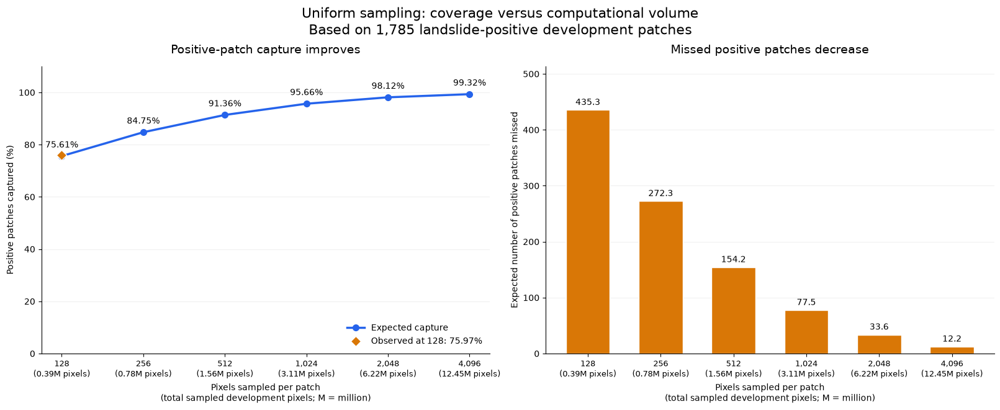

In [34]:
#Sampling Trade-off
comparison = sampling_comparison.sort_values(
    "Pixels per patch"
).copy()

sample_sizes = comparison["Pixels per patch"].to_numpy()
x_positions = np.arange(len(comparison))

tick_labels = [
    f"{size:,}\n({total / 1_000_000:.2f}M pixels)"
    for size, total in zip(
        sample_sizes,
        comparison["Total sampled development pixels"]
    )
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6.5),
    layout="constrained"
)

# Panel 1: expected capture.
capture = comparison["Expected capture (%)"].to_numpy()

axes[0].plot(
    x_positions,
    capture,
    marker="o",
    markersize=7,
    linewidth=2.5,
    color="#2563eb",
    label="Expected capture"
)

observed_capture = 100 * n_captured / n_positive_patches

axes[0].scatter(
    x_positions[0],
    observed_capture,
    marker="D",
    s=70,
    color="#d97706",
    edgecolor="white",
    zorder=4,
    label=f"Observed at 128: {observed_capture:.2f}%"
)

for x, value in zip(x_positions, capture):
    axes[0].annotate(
        f"{value:.2f}%",
        (x, value),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

axes[0].set_title(
    "Positive-patch capture improves",
    fontsize=14,
    pad=15
)
axes[0].set_ylabel("Positive patches captured (%)")
axes[0].set_ylim(0, 110)
axes[0].set_yticks(range(0, 101, 20))
axes[0].legend(loc="lower right", frameon=False)

# Panel 2: expected missed positive patches.
missed = comparison["Expected positive patches missed"].to_numpy()

axes[1].bar(
    x_positions,
    missed,
    color="#d97706",
    width=0.6,
    edgecolor="white"
)

for x, value in zip(x_positions, missed):
    axes[1].annotate(
        f"{value:.1f}",
        (x, value),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

axes[1].set_title(
    "Missed positive patches decrease",
    fontsize=14,
    pad=15
)
axes[1].set_ylabel("Expected number of positive patches missed")
axes[1].set_ylim(0, missed.max() * 1.18)

for ax in axes:
    ax.set_xticks(x_positions)
    ax.set_xticklabels(tick_labels, fontsize=9)
    ax.set_xlabel(
        "Pixels sampled per patch\n"
        "(total sampled development pixels; M = million)",
        fontsize=10
    )

    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.18)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Uniform sampling: coverage versus computational volume\n"
    f"Based on {n_positive_patches:,} landslide-positive development patches",
    fontsize=16
)

plt.show()

Increasing sampling from 512 to 1,024 pixels per patch doubles sample volume and raises expected positive-patch capture from 91.36% to 95.66%. Both sizes remain candidates for validation-based comparison; no optimal size has been established.

In [35]:
#Nested Samples
MAX_PIXELS_PER_PATCH = 1024

sampled_patch_ids = np.asarray(development_ids)

# Keep the patch dimension explicit:
# patches × sampled pixels × features.
X_patch_samples = np.empty(
    (
        len(sampled_patch_ids),
        MAX_PIXELS_PER_PATCH,
        len(FEATURE_NAMES)
    ),
    dtype=np.float32
)

y_patch_samples = np.empty(
    (len(sampled_patch_ids), MAX_PIXELS_PER_PATCH),
    dtype=np.uint8
)

for patch_index, sample_id in enumerate(sampled_patch_ids):
    image_path = (
        DATA_DIR / "TrainData" / "img" / f"image_{sample_id}.h5"
    )
    mask_path = (
        DATA_DIR / "TrainData" / "mask" / f"mask_{sample_id}.h5"
    )

    with h5py.File(image_path, "r") as h5_file:
        features = h5_file["img"][:].reshape(
            -1, len(FEATURE_NAMES)
        )

    with h5py.File(mask_path, "r") as h5_file:
        labels = h5_file["mask"][:].reshape(-1)

    patch_rng = np.random.default_rng(
        np.random.SeedSequence([RANDOM_STATE, int(sample_id)])
    )

    positions = patch_rng.choice(
        len(labels),
        size=MAX_PIXELS_PER_PATCH,
        replace=False
    )

    X_patch_samples[patch_index] = features[positions]
    y_patch_samples[patch_index] = labels[positions]

    completed = patch_index + 1

    if completed % 500 == 0 or completed == len(sampled_patch_ids):
        print(
            f"Prepared {completed:,} / "
            f"{len(sampled_patch_ids):,} development patches"
        )

assert set(sampled_patch_ids).isdisjoint(map(str, test_ids))
assert np.isfinite(X_patch_samples).all()

# Compare actual coverage for the two nested samples.
sampling_actual_rows = []

originally_positive = (
    audit_by_id.loc[
        sampled_patch_ids, "landslide_pixels"
    ].to_numpy() > 0
)

for sample_size in [512, 1024]:
    sample_labels = y_patch_samples[:, :sample_size]

    positive_captured = (sample_labels == 1).any(axis=1)

    captured_count = int(
        (originally_positive & positive_captured).sum()
    )

    sampling_actual_rows.append({
        "Pixels per patch": sample_size,
        "Total sampled pixels": sample_labels.size,
        "Positive pixels": int((sample_labels == 1).sum()),
        "Positive pixels (%)":
            100 * (sample_labels == 1).mean(),
        "Positive patches captured": captured_count,
        "Positive patches missed":
            int(originally_positive.sum()) - captured_count,
        "Actual capture (%)":
            100 * captured_count / originally_positive.sum()
    })

sampling_actual = pd.DataFrame(sampling_actual_rows)

print("\nActual sampling results:")
display(sampling_actual.round(2))

print("\nFeature array shape:", X_patch_samples.shape)
print("Label array shape:", y_patch_samples.shape)

memory_mib = (
    X_patch_samples.nbytes + y_patch_samples.nbytes
) / 1024**2

print(f"Sample arrays memory: {memory_mib:.1f} MiB")
print("Final-test patches included: 0")

Prepared 500 / 3,039 development patches
Prepared 1,000 / 3,039 development patches
Prepared 1,500 / 3,039 development patches
Prepared 2,000 / 3,039 development patches
Prepared 2,500 / 3,039 development patches
Prepared 3,000 / 3,039 development patches
Prepared 3,039 / 3,039 development patches

Actual sampling results:


,Pixels per patch,Total sampled pixels,Positive pixels,Positive pixels (%),Positive patches captured,Positive patches missed,Actual capture (%)
0,512,1555968,36915,2.37,1634,151,91.54
1,1024,3111936,73530,2.36,1713,72,95.97



Feature array shape: (3039, 1024, 14)
Label array shape: (3039, 1024)
Sample arrays memory: 169.2 MiB
Final-test patches included: 0


The 512- and 1,024-pixel samples captured positive pixels in 91.54% and 95.97% of landslide-positive development patches, respectively. Both retain all 3,039 patches and exclude the final test set. The optimal training sample size remains to be evaluated.

### 1. Logistic Regression

In [36]:
#1. Logistic Regression · StandardScaler · Pipeline
from time import perf_counter

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PILOT_SAMPLE_SIZE = 512

# First inner split within the first outer fold.
pilot_split = nested_splits[0]["inner_splits"][0]

pilot_train_ids = set(map(str, pilot_split["train_ids"]))
pilot_val_ids = set(map(str, pilot_split["validation_ids"]))

train_patch_selector = np.isin(
    sampled_patch_ids,
    list(pilot_train_ids)
)

assert pilot_train_ids.isdisjoint(pilot_val_ids)
assert pilot_train_ids.isdisjoint(map(str, test_ids))

# Select training patches first, then flatten their sampled pixels.
X_pilot_train = X_patch_samples[
    train_patch_selector, :PILOT_SAMPLE_SIZE, :
].reshape(-1, len(FEATURE_NAMES))

y_pilot_train = y_patch_samples[
    train_patch_selector, :PILOT_SAMPLE_SIZE
].reshape(-1)

lr_pilot = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=1000,
        class_weight=None
    ))
])

start_time = perf_counter()

lr_pilot.fit(X_pilot_train, y_pilot_train)

pilot_fit_seconds = perf_counter() - start_time

print("Pilot training patches:", int(train_patch_selector.sum()))
print("Reserved inner-validation patches:", len(pilot_val_ids))
print("Training pixels:", len(y_pilot_train))
print("Input features:", X_pilot_train.shape[1])
print(
    "Training landslide pixels:",
    int((y_pilot_train == 1).sum())
)
print(f"Training time: {pilot_fit_seconds:.2f} seconds")
print(
    "Solver iterations:",
    lr_pilot.named_steps["classifier"].n_iter_
)
print("Final-test patches used: 0")

Pilot training patches: 1620
Reserved inner-validation patches: 811
Training pixels: 829440
Input features: 14
Training landslide pixels: 19548
Training time: 1.25 seconds
Solver iterations: [54]
Final-test patches used: 0


The pilot logistic regression fitted 829,440 sampled pixels from 1,620 patches in 1.25 seconds, using 54 solver iterations. No convergence warning is visible. Validation performance remains to be measured.

In [38]:
import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix

# Explicit reference threshold; not selected by validation.
TRAIN_THRESHOLD = 0.50

# Access the already fitted classifier.
classifier = lr_pilot.named_steps["classifier"]

# --------------------------------------------------
# 1. Coefficients and intercept
# --------------------------------------------------
lr_coefficients = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Coefficient": classifier.coef_[0]
})

lr_coefficients["Absolute coefficient"] = (
    lr_coefficients["Coefficient"].abs()
)

print(f"Intercept: {classifier.intercept_[0]:.6f}")
print("\nCoefficients on the standardised feature scale:")

display(
    lr_coefficients.sort_values(
        "Absolute coefficient",
        ascending=False
    ).round(5)
)

# --------------------------------------------------
# 2. Training probabilities and explicit threshold
# --------------------------------------------------
positive_column = int(
    np.flatnonzero(lr_pilot.classes_ == 1)[0]
)

train_probabilities = lr_pilot.predict_proba(
    X_pilot_train
)[:, positive_column]

train_predictions = (
    train_probabilities >= TRAIN_THRESHOLD
).astype(np.uint8)

# --------------------------------------------------
# 3. Confusion matrix
# --------------------------------------------------
train_confusion = confusion_matrix(
    y_pilot_train,
    train_predictions,
    labels=[0, 1]
)

tn_train, fp_train, fn_train, tp_train = (
    train_confusion.ravel()
)

confusion_table = pd.DataFrame(
    train_confusion,
    index=["Actual non-landslide", "Actual landslide"],
    columns=["Predicted non-landslide", "Predicted landslide"]
)

print(f"\nTraining threshold: {TRAIN_THRESHOLD:.2f}")
print("Training pixels:", len(y_pilot_train))
print("\nTraining confusion matrix:")

display(confusion_table)

# --------------------------------------------------
# 4. Training metrics
# --------------------------------------------------
lr_training_metrics = metrics_from_counts(
    tn_train,
    fp_train,
    fn_train,
    tp_train
)

metric_names = [
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "F2",
    "IoU",
    "Balanced accuracy",
    "Accuracy"
]

training_scores = pd.DataFrame({
    "Metric": metric_names,
    "Score": [
        lr_training_metrics[name]
        for name in metric_names
    ]
})

print("\nTraining scores — values between 0 and 1:")
display(training_scores.round(5))

print("\nNo model refitting was performed.")
print("These results describe sampled training pixels only.")

Intercept: -6.490713

Coefficients on the standardised feature scale:


,Feature,Coefficient,Absolute coefficient
6,B7,-4.51726,4.51726
5,B6,2.44945,2.44945
1,B2,-2.42431,2.42431
2,B3,2.31790,2.31790
10,B11,-1.32432,1.32432
4,B5,1.18224,1.18224
11,B12,1.13753,1.13753
8,B9,1.13603,1.13603
7,B8,-1.05450,1.05450
12,Slope,1.02827,1.02827



Training threshold: 0.50
Training pixels: 829440

Training confusion matrix:


,Predicted non-landslide,Predicted landslide
Actual non-landslide,806839,3053
Actual landslide,11923,7625



Training scores — values between 0 and 1:


,Metric,Score
0,Precision,0.71409
1,Recall,0.39007
2,Specificity,0.99623
3,F1,0.50453
4,F2,0.42900
5,IoU,0.33737
6,Balanced accuracy,0.69315
7,Accuracy,0.98194



No model refitting was performed.
These results describe sampled training pixels only.


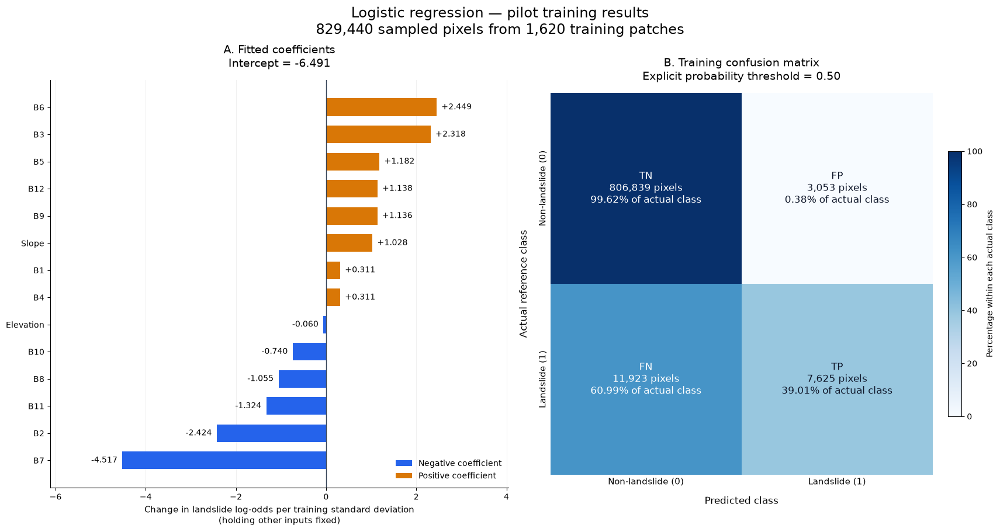

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Patch
from sklearn.metrics import confusion_matrix

TRAIN_THRESHOLD = 0.50

classifier = lr_pilot.named_steps["classifier"]

# Read fitted coefficients.
coefficient_plot = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Coefficient": classifier.coef_[0]
}).sort_values("Coefficient")

# Predict training probabilities using the fitted pipeline.
positive_column = int(
    np.flatnonzero(lr_pilot.classes_ == 1)[0]
)

train_probabilities = lr_pilot.predict_proba(
    X_pilot_train
)[:, positive_column]

train_predictions = (
    train_probabilities >= TRAIN_THRESHOLD
).astype(np.uint8)

train_confusion = confusion_matrix(
    y_pilot_train,
    train_predictions,
    labels=[0, 1]
)

row_totals = train_confusion.sum(axis=1, keepdims=True)

row_percentages = np.divide(
    100.0 * train_confusion,
    row_totals,
    out=np.zeros_like(train_confusion, dtype=float),
    where=row_totals != 0
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 9),
    gridspec_kw={"width_ratios": [1.2, 1]},
    layout="constrained"
)

# --------------------------------------------------
# A. Signed standardised coefficients
# --------------------------------------------------
ax = axes[0]

colors = np.where(
    coefficient_plot["Coefficient"] >= 0,
    "#d97706",
    "#2563eb"
)

bars = ax.barh(
    coefficient_plot["Feature"],
    coefficient_plot["Coefficient"],
    color=colors,
    height=0.65
)

ax.axvline(0, color="#334155", linewidth=1)

for bar, value in zip(
    bars, coefficient_plot["Coefficient"]
):
    ax.annotate(
        f"{value:+.3f}",
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(6 if value >= 0 else -6, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=10
    )

ax.margins(x=0.23)
ax.set_title(
    "A. Fitted coefficients\n"
    f"Intercept = {classifier.intercept_[0]:.3f}",
    fontsize=14,
    pad=16
)

ax.set_xlabel(
    "Change in landslide log-odds per training standard deviation\n"
    "(holding other inputs fixed)",
    fontsize=11
)

ax.legend(
    handles=[
        Patch(facecolor="#2563eb", label="Negative coefficient"),
        Patch(facecolor="#d97706", label="Positive coefficient")
    ],
    loc="lower right",
    frameon=False,
    fontsize=10
)

ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.18)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# --------------------------------------------------
# B. Confusion matrix: counts and row percentages
# --------------------------------------------------
ax = axes[1]

heatmap = ax.imshow(
    row_percentages,
    cmap="Blues",
    vmin=0,
    vmax=100
)

cell_names = np.array([
    ["TN", "FP"],
    ["FN", "TP"]
])

for row in range(2):
    for column in range(2):
        percentage = row_percentages[row, column]

        ax.text(
            column,
            row,
            f"{cell_names[row, column]}\n"
            f"{train_confusion[row, column]:,} pixels\n"
            f"{percentage:.2f}% of actual class",
            ha="center",
            va="center",
            fontsize=12,
            color="white" if percentage >= 55 else "#0f172a"
        )

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(
    ["Non-landslide (0)", "Landslide (1)"],
    fontsize=11
)
ax.set_yticklabels(
    ["Non-landslide (0)", "Landslide (1)"],
    fontsize=11,
    rotation=90,
    va="center"
)

ax.set_xlabel("Predicted class", fontsize=12, labelpad=12)
ax.set_ylabel("Actual reference class", fontsize=12, labelpad=12)
ax.set_title(
    f"B. Training confusion matrix\n"
    f"Explicit probability threshold = {TRAIN_THRESHOLD:.2f}",
    fontsize=14,
    pad=16
)

colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    shrink=0.65,
    pad=0.04
)
colorbar.set_label("Percentage within each actual class")

ax.tick_params(length=0)

for spine in ax.spines.values():
    spine.set_visible(False)

fig.suptitle(
    "Logistic regression — pilot training results\n"
    f"{len(y_pilot_train):,} sampled pixels from "
    f"{int(train_patch_selector.sum()):,} training patches",
    fontsize=17
)

plt.show()

At threshold 0.50, the pilot correctly identifies 39.01% of training landslide pixels and misses 60.99%. The false-positive rate among non-landslide pixels is 0.38%. These training diagnostics do not establish generalisation performance.

Predicted 100 / 811 validation patches
Predicted 200 / 811 validation patches
Predicted 300 / 811 validation patches
Predicted 400 / 811 validation patches
Predicted 500 / 811 validation patches
Predicted 600 / 811 validation patches
Predicted 700 / 811 validation patches
Predicted 800 / 811 validation patches
Predicted 811 / 811 validation patches

Validation patches: 811
Validation pixels: 13,287,424
Threshold: 0.50
Loading and evaluation time: 2.91 seconds


,Training sample,Full inner validation
Precision,0.71409,0.63755
Recall,0.39007,0.40820
Specificity,0.99623,0.99455
F1,0.50453,0.49772
F2,0.42900,0.43984
IoU,0.33737,0.33131
Balanced accuracy,0.69315,0.70137
Accuracy,0.98194,0.98111


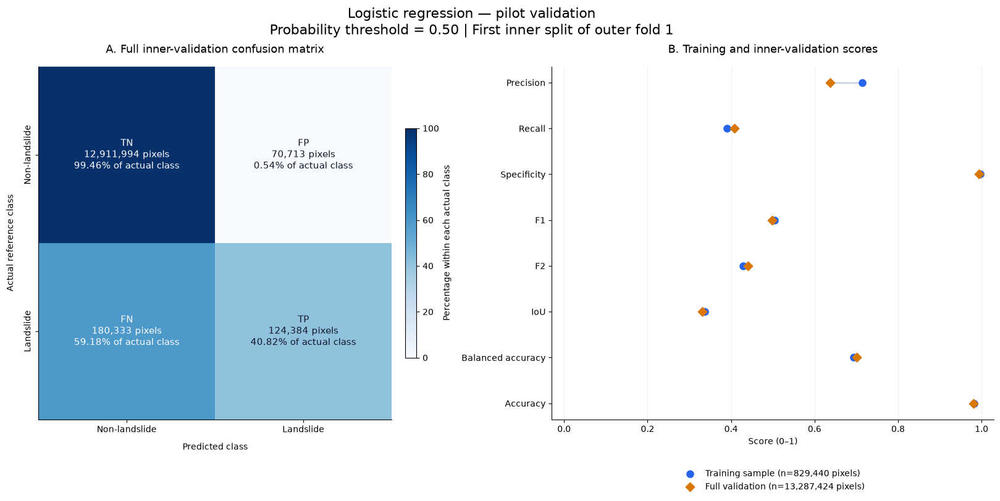

Outer-evaluation patches used: 0
Final-test patches used: 0


In [40]:
#Inner Validation
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

VALIDATION_THRESHOLD = 0.50

validation_ids = sorted(pilot_val_ids, key=int)

# Verify separation before prediction.
assert set(validation_ids).isdisjoint(pilot_train_ids)
assert set(validation_ids).isdisjoint(
    nested_splits[0]["evaluation_ids"]
)
assert set(validation_ids).isdisjoint(map(str, test_ids))

n_validation_pixels = int(
    audit_by_id.loc[validation_ids, "total_pixels"].sum()
)

y_pilot_val_full = np.empty(
    n_validation_pixels, dtype=np.uint8
)
p_pilot_val_full = np.empty(
    n_validation_pixels, dtype=np.float64
)

positive_column = int(
    np.flatnonzero(lr_pilot.classes_ == 1)[0]
)

offset = 0
start_time = perf_counter()

# Predict complete patches, one at a time.
for position, sample_id in enumerate(validation_ids, start=1):
    image_path = (
        DATA_DIR / "TrainData" / "img" / f"image_{sample_id}.h5"
    )
    mask_path = (
        DATA_DIR / "TrainData" / "mask" / f"mask_{sample_id}.h5"
    )

    with h5py.File(image_path, "r") as h5_file:
        features = h5_file["img"][:].reshape(
            -1, len(FEATURE_NAMES)
        )

    with h5py.File(mask_path, "r") as h5_file:
        labels = h5_file["mask"][:].reshape(-1)

    probabilities = lr_pilot.predict_proba(
        features
    )[:, positive_column]

    stop = offset + len(labels)
    y_pilot_val_full[offset:stop] = labels
    p_pilot_val_full[offset:stop] = probabilities
    offset = stop

    if position % 100 == 0 or position == len(validation_ids):
        print(
            f"Predicted {position:,} / "
            f"{len(validation_ids):,} validation patches"
        )

assert offset == n_validation_pixels
assert np.isfinite(p_pilot_val_full).all()

# Calculate validation confusion counts.
actual_positive = y_pilot_val_full == 1
predicted_positive = (
    p_pilot_val_full >= VALIDATION_THRESHOLD
)

tp = int(np.count_nonzero(actual_positive & predicted_positive))
fp = int(np.count_nonzero(~actual_positive & predicted_positive))
fn = int(actual_positive.sum()) - tp
tn = n_validation_pixels - tp - fp - fn

lr_validation_metrics = metrics_from_counts(tn, fp, fn, tp)

validation_confusion = np.array([
    [tn, fp],
    [fn, tp]
])

# Training and validation use the same reference threshold.
assert TRAIN_THRESHOLD == VALIDATION_THRESHOLD

metric_names = [
    "Precision", "Recall", "Specificity",
    "F1", "F2", "IoU", "Balanced accuracy", "Accuracy"
]

pilot_comparison = pd.DataFrame({
    "Training sample": [
        lr_training_metrics[name] for name in metric_names
    ],
    "Full inner validation": [
        lr_validation_metrics[name] for name in metric_names
    ]
}, index=metric_names)

print(f"\nValidation patches: {len(validation_ids):,}")
print(f"Validation pixels: {n_validation_pixels:,}")
print(f"Threshold: {VALIDATION_THRESHOLD:.2f}")
print(
    f"Loading and evaluation time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

display(pilot_comparison.round(5))

# --------------------------------------------------
# Visual diagnostics
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2, figsize=(17, 8), layout="constrained"
)

# A. Confusion matrix with counts and row percentages.
row_totals = validation_confusion.sum(axis=1, keepdims=True)

row_percentages = np.divide(
    100.0 * validation_confusion,
    row_totals,
    out=np.zeros_like(validation_confusion, dtype=float),
    where=row_totals != 0
)

heatmap = axes[0].imshow(
    row_percentages,
    cmap="Blues",
    vmin=0,
    vmax=100
)

cell_names = [["TN", "FP"], ["FN", "TP"]]

for row in range(2):
    for column in range(2):
        percentage = row_percentages[row, column]

        axes[0].text(
            column, row,
            f"{cell_names[row][column]}\n"
            f"{validation_confusion[row, column]:,} pixels\n"
            f"{percentage:.2f}% of actual class",
            ha="center",
            va="center",
            fontsize=11,
            color="white" if percentage >= 55 else "#0f172a"
        )

axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(["Non-landslide", "Landslide"])
axes[0].set_yticklabels(
    ["Non-landslide", "Landslide"],
    rotation=90,
    va="center"
)
axes[0].set_xlabel("Predicted class", labelpad=10)
axes[0].set_ylabel("Actual reference class", labelpad=10)
axes[0].set_title(
    "A. Full inner-validation confusion matrix",
    fontsize=13,
    pad=16
)

colorbar = fig.colorbar(
    heatmap, ax=axes[0], shrink=0.65, pad=0.03
)
colorbar.set_label("Percentage within each actual class")

# B. Training-versus-validation metric comparison.
y_positions = np.arange(len(metric_names))

for row, metric in enumerate(metric_names):
    axes[1].plot(
        pilot_comparison.loc[metric].to_numpy(),
        [row, row],
        color="#cbd5e1",
        linewidth=2,
        zorder=1
    )

axes[1].scatter(
    pilot_comparison["Training sample"],
    y_positions,
    color="#2563eb",
    s=65,
    label=f"Training sample (n={len(y_pilot_train):,} pixels)",
    zorder=3
)

axes[1].scatter(
    pilot_comparison["Full inner validation"],
    y_positions,
    color="#d97706",
    marker="D",
    s=55,
    label=f"Full validation (n={n_validation_pixels:,} pixels)",
    zorder=4
)

axes[1].set_yticks(y_positions)
axes[1].set_yticklabels(metric_names)
axes[1].invert_yaxis()
axes[1].set_xlim(-0.03, 1.03)
axes[1].set_xticks(np.linspace(0, 1, 6))
axes[1].set_xlabel("Score (0–1)")
axes[1].set_title(
    "B. Training and inner-validation scores",
    fontsize=13,
    pad=16
)
axes[1].grid(axis="x", alpha=0.18)
axes[1].set_axisbelow(True)
axes[1].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    frameon=False,
    fontsize=10
)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Logistic regression — pilot validation\n"
    f"Probability threshold = {VALIDATION_THRESHOLD:.2f} | "
    "First inner split of outer fold 1",
    fontsize=16
)

plt.show()

print("Outer-evaluation patches used: 0")
print("Final-test patches used: 0")

At threshold 0.50, full inner-validation F2 is 0.4398, precision is 63.76%, and recall is 40.82%. The model misses 59.18% of labelled landslide pixels. Threshold analysis is warranted; outer evaluation and the final test set remain unused.

Preliminary best threshold: 0.100

Reference and selected threshold:


,Threshold,F2,F1,IoU,Precision,Recall,Specificity
11,0.1,0.61807,0.48927,0.32386,0.36314,0.74963,0.96914
51,0.5,0.43984,0.49772,0.33131,0.63755,0.40820,0.99455


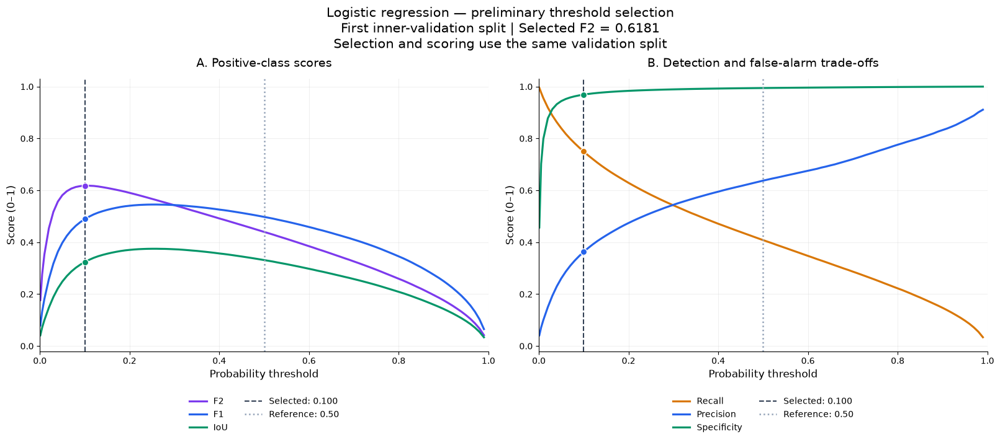

In [41]:
#Threshold Analysis
# Sort stored validation probabilities separately by actual class.
positive_probabilities = np.sort(
    p_pilot_val_full[y_pilot_val_full == 1]
)

negative_probabilities = np.sort(
    p_pilot_val_full[y_pilot_val_full == 0]
)

n_positive = len(positive_probabilities)
n_negative = len(negative_probabilities)

threshold_rows = []

for threshold in THRESHOLDS:
    # Prediction rule: probability >= threshold.
    fn = int(np.searchsorted(
        positive_probabilities, threshold, side="left"
    ))
    tn = int(np.searchsorted(
        negative_probabilities, threshold, side="left"
    ))

    tp = n_positive - fn
    fp = n_negative - tn

    threshold_rows.append({
        "Threshold": float(threshold),
        **metrics_from_counts(tn, fp, fn, tp)
    })

pilot_threshold_results = pd.DataFrame(threshold_rows)

# Selection rule:
# highest F2, then highest precision.
# If both remain equal, prefer the higher threshold.
ranked_thresholds = pilot_threshold_results.sort_values(
    ["F2", "Precision", "Threshold"],
    ascending=[False, False, False],
    na_position="last"
)

pilot_best_threshold = float(
    ranked_thresholds.iloc[0]["Threshold"]
)

print(
    "Preliminary best threshold:",
    f"{pilot_best_threshold:.3f}"
)

comparison_rows = pilot_threshold_results.loc[
    np.isclose(pilot_threshold_results["Threshold"], 0.50)
    | np.isclose(
        pilot_threshold_results["Threshold"],
        pilot_best_threshold
    ),
    [
        "Threshold", "F2", "F1", "IoU",
        "Precision", "Recall", "Specificity"
    ]
].sort_values("Threshold")

print("\nReference and selected threshold:")
display(comparison_rows.round(5))

# Confirm the reference counts match the previous evaluation.
reference_row = pilot_threshold_results.loc[
    np.isclose(pilot_threshold_results["Threshold"], 0.50)
].iloc[0]

for name in ["TN", "FP", "FN", "TP"]:
    assert int(reference_row[name]) == int(
        lr_validation_metrics[name]
    )

# --------------------------------------------------
# Plot threshold trade-offs.
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    layout="constrained"
)

panels = [
    (
        axes[0],
        [
            ("F2", "#7c3aed"),
            ("F1", "#2563eb"),
            ("IoU", "#059669")
        ],
        "A. Positive-class scores"
    ),
    (
        axes[1],
        [
            ("Recall", "#d97706"),
            ("Precision", "#2563eb"),
            ("Specificity", "#059669")
        ],
        "B. Detection and false-alarm trade-offs"
    )
]

best_row = ranked_thresholds.iloc[0]

for ax, metric_settings, title in panels:
    for metric, color in metric_settings:
        ax.plot(
            pilot_threshold_results["Threshold"],
            pilot_threshold_results[metric],
            color=color,
            linewidth=2.3,
            label=metric
        )

        ax.scatter(
            pilot_best_threshold,
            best_row[metric],
            color=color,
            edgecolor="white",
            s=55,
            zorder=5
        )

    ax.axvline(
        pilot_best_threshold,
        color="#334155",
        linestyle="--",
        linewidth=1.5,
        label=f"Selected: {pilot_best_threshold:.3f}"
    )

    ax.axvline(
        0.50,
        color="#94a3b8",
        linestyle=":",
        linewidth=1.8,
        label="Reference: 0.50"
    )

    ax.set_title(title, fontsize=14, pad=14)
    ax.set_xlabel("Probability threshold", fontsize=12)
    ax.set_ylabel("Score (0–1)", fontsize=12)
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.02, 1.03)
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.set_yticks(np.linspace(0, 1, 6))

    ax.set_axisbelow(True)
    ax.grid(alpha=0.18)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.14),
        ncol=2,
        frameon=False,
        fontsize=10
    )

fig.suptitle(
    "Logistic regression — preliminary threshold selection\n"
    f"First inner-validation split | "
    f"Selected F2 = {best_row['F2']:.4f}\n"
    "Selection and scoring use the same validation split",
    fontsize=15
)

plt.show()

# Temporary sorted copies are no longer needed.
del positive_probabilities, negative_probabilities

On this inner-validation split, threshold 0.10 maximises grid-search F2 at 0.6181, increasing recall to 74.96% while reducing precision to 36.31%. F1 and IoU decrease slightly. This is a preliminary selection result, not an independent performance estimate.

In [42]:
#Inner-CV Selection
def evaluate_full_patches_at_thresholds(
    model,
    patch_ids,
    thresholds
):
    """Evaluate all pixels of specified patches at fixed thresholds."""

    thresholds = np.asarray(thresholds, dtype=float)

    tn_total = np.zeros(len(thresholds), dtype=np.int64)
    fp_total = np.zeros(len(thresholds), dtype=np.int64)
    fn_total = np.zeros(len(thresholds), dtype=np.int64)
    tp_total = np.zeros(len(thresholds), dtype=np.int64)

    positive_column = int(
        np.flatnonzero(model.classes_ == 1)[0]
    )

    for sample_id in sorted(map(str, patch_ids), key=int):
        image_path = (
            DATA_DIR / "TrainData" / "img" / f"image_{sample_id}.h5"
        )
        mask_path = (
            DATA_DIR / "TrainData" / "mask" / f"mask_{sample_id}.h5"
        )

        with h5py.File(image_path, "r") as h5_file:
            features = h5_file["img"][:].reshape(
                -1, len(FEATURE_NAMES)
            )

        with h5py.File(mask_path, "r") as h5_file:
            labels = h5_file["mask"][:].reshape(-1)

        probabilities = model.predict_proba(
            features
        )[:, positive_column]

        if not np.isfinite(probabilities).all():
            raise ValueError(
                f"Non-finite probabilities in patch {sample_id}"
            )

        positive_probs = np.sort(probabilities[labels == 1])
        negative_probs = np.sort(probabilities[labels == 0])

        # Counts for the rule: probability >= threshold.
        fn = np.searchsorted(
            positive_probs, thresholds, side="left"
        )
        tn = np.searchsorted(
            negative_probs, thresholds, side="left"
        )

        tp = len(positive_probs) - fn
        fp = len(negative_probs) - tn

        tn_total += tn
        fp_total += fp
        fn_total += fn
        tp_total += tp

    results = []

    for index, threshold in enumerate(thresholds):
        results.append({
            "Threshold": float(threshold),
            **metrics_from_counts(
                tn_total[index],
                fp_total[index],
                fn_total[index],
                tp_total[index]
            )
        })

    return pd.DataFrame(results)


print("Full-patch threshold evaluation function is ready.")

Full-patch threshold evaluation function is ready.


A reusable evaluator is defined for complete patches across the fixed threshold grid. It aggregates pixel confusion counts without retaining full-dataset probabilities. No new model has been fitted or selected in this step.

In [43]:
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
import warnings

sample_size_candidates = [512, 1024]

lr_inner_tables = []
lr_inner_runtime_rows = []

outer_fold = nested_splits[0]

for sample_size in sample_size_candidates:
    for inner_number, inner_split in enumerate(
        outer_fold["inner_splits"],
        start=1
    ):
        training_ids = set(map(str, inner_split["train_ids"]))
        validation_ids = set(
            map(str, inner_split["validation_ids"])
        )

        assert training_ids.isdisjoint(validation_ids)
        assert validation_ids.isdisjoint(
            map(str, outer_fold["evaluation_ids"])
        )

        selector = np.isin(
            sampled_patch_ids,
            list(training_ids)
        )

        X_inner_train = X_patch_samples[
            selector, :sample_size, :
        ].reshape(-1, len(FEATURE_NAMES))

        y_inner_train = y_patch_samples[
            selector, :sample_size
        ].reshape(-1)

        # Clone creates an unfitted model with the same settings.
        current_model = clone(lr_pilot)

        print(
            f"\nSample size {sample_size} | "
            f"Inner fold {inner_number}/3",
            flush=True
        )

        fit_start = perf_counter()

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)

            current_model.fit(
                X_inner_train,
                y_inner_train
            )

        fit_seconds = perf_counter() - fit_start

        convergence_warning = any(
            issubclass(item.category, ConvergenceWarning)
            for item in caught
        )

        # Display all captured warnings rather than hiding them.
        for item in caught:
            print(
                f"{item.category.__name__}: {item.message}"
            )

        evaluation_start = perf_counter()

        fold_results = evaluate_full_patches_at_thresholds(
            current_model,
            validation_ids,
            THRESHOLDS
        )

        evaluation_seconds = (
            perf_counter() - evaluation_start
        )

        fold_results["Pixels per patch"] = sample_size
        fold_results["Inner fold"] = inner_number

        lr_inner_tables.append(fold_results)

        lr_inner_runtime_rows.append({
            "Pixels per patch": sample_size,
            "Inner fold": inner_number,
            "Training pixels": len(y_inner_train),
            "Training patches": int(selector.sum()),
            "Validation patches": len(validation_ids),
            "Fit seconds": fit_seconds,
            "Full-validation seconds": evaluation_seconds,
            "Convergence warning": convergence_warning
        })

        print(
            f"Completed | Fit: {fit_seconds:.2f}s | "
            f"Validation: {evaluation_seconds:.2f}s",
            flush=True
        )

        del X_inner_train, y_inner_train, current_model

lr_inner_results = pd.concat(
    lr_inner_tables,
    ignore_index=True
)

lr_inner_runtime = pd.DataFrame(lr_inner_runtime_rows)

print("\nRun summary:")
display(lr_inner_runtime.round(2))

print("\nThreshold-result rows:", len(lr_inner_results))
print("Expected rows:", 2 * 3 * len(THRESHOLDS))
print("Outer-evaluation patches used: 0")
print("Final-test patches used: 0")


Sample size 512 | Inner fold 1/3
Completed | Fit: 1.27s | Validation: 3.04s

Sample size 512 | Inner fold 2/3
Completed | Fit: 1.30s | Validation: 7.75s

Sample size 512 | Inner fold 3/3
Completed | Fit: 11.77s | Validation: 28.30s

Sample size 1024 | Inner fold 1/3
Completed | Fit: 13.60s | Validation: 3.01s

Sample size 1024 | Inner fold 2/3
Completed | Fit: 2.84s | Validation: 2.97s

Sample size 1024 | Inner fold 3/3
Completed | Fit: 26.43s | Validation: 13.79s

Run summary:


,Pixels per patch,Inner fold,Training pixels,Training patches,Validation patches,Fit seconds,Full-validation seconds,Convergence warning
0,512,1,829440,1620,811,1.27,3.04,False
1,512,2,829952,1621,810,1.30,7.75,False
2,512,3,829952,1621,810,11.77,28.30,False
3,1024,1,1658880,1620,811,13.60,3.01,False
4,1024,2,1659904,1621,810,2.84,2.97,False
5,1024,3,1659904,1621,810,26.43,13.79,False



Threshold-result rows: 606
Expected rows: 606
Outer-evaluation patches used: 0
Final-test patches used: 0


The previous pilot used one inner fold and one sample size. The new experiment uses all three inner folds and two sample sizes to support joint sample-size and threshold selection.

Best common threshold for each sample size:


,Pixels per patch,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_F1,Mean_IoU
11,512,0.1,0.62638,0.02321,0.39242,0.73942,0.97253,0.51105,0.34402
112,1024,0.1,0.62613,0.02366,0.39225,0.73869,0.97258,0.51096,0.34389



Selected setting within outer fold 1:
Pixels per training patch: 512
Threshold: 0.100
Mean inner F2: 0.62638


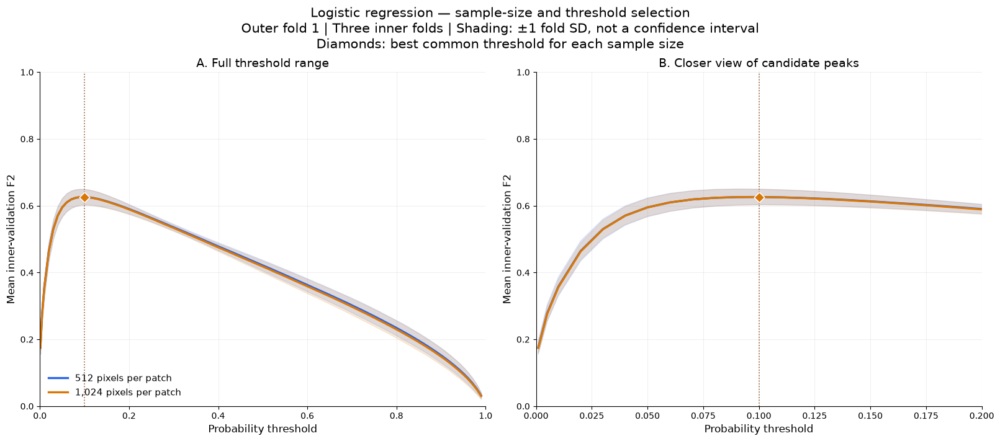

In [44]:
#Mean Inner-CV F2 · Standard Deviation
# Summarise the three inner folds at each common threshold.
lr_inner_summary = (
    lr_inner_results
    .groupby(["Pixels per patch", "Threshold"], as_index=False)
    .agg(
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_F1=("F1", "mean"),
        Mean_IoU=("IoU", "mean"),
        Fold_count=("F2", "count")
    )
)

assert (lr_inner_summary["Fold_count"] == 3).all()

# Within each sample size:
# maximise mean F2, then mean precision, then threshold.
ranked_summary = lr_inner_summary.sort_values(
    [
        "Mean_F2",
        "Mean_precision",
        "Pixels per patch",
        "Threshold"
    ],
    ascending=[False, False, True, False],
    na_position="last"
)

best_per_size = (
    ranked_summary
    .drop_duplicates("Pixels per patch")
    .sort_values("Pixels per patch")
)

# If F2 and precision are exactly tied between sample sizes,
# prefer the smaller sample.
selected_lr_setting = ranked_summary.iloc[0]

selected_lr_sample_size = int(
    selected_lr_setting["Pixels per patch"]
)
selected_lr_threshold = float(
    selected_lr_setting["Threshold"]
)

print("Best common threshold for each sample size:")
display(
    best_per_size[
        [
            "Pixels per patch", "Threshold",
            "Mean_F2", "SD_F2",
            "Mean_precision", "Mean_recall",
            "Mean_specificity", "Mean_F1", "Mean_IoU"
        ]
    ].round(5)
)

print("\nSelected setting within outer fold 1:")
print("Pixels per training patch:", selected_lr_sample_size)
print("Threshold:", f"{selected_lr_threshold:.3f}")
print("Mean inner F2:", f"{selected_lr_setting['Mean_F2']:.5f}")

# --------------------------------------------------
# Curves: broad view and a closer view.
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    layout="constrained"
)

sample_colors = {
    512: "#2563eb",
    1024: "#d97706"
}

for sample_size, color in sample_colors.items():
    curve = (
        lr_inner_summary.loc[
            lr_inner_summary["Pixels per patch"] == sample_size
        ]
        .sort_values("Threshold")
    )

    x = curve["Threshold"].to_numpy()
    mean = curve["Mean_F2"].to_numpy()
    sd = curve["SD_F2"].to_numpy()

    best = best_per_size.loc[
        best_per_size["Pixels per patch"] == sample_size
    ].iloc[0]

    for ax in axes:
        ax.plot(
            x, mean,
            color=color,
            linewidth=2.4,
            label=f"{sample_size:,} pixels per patch"
        )

        ax.fill_between(
            x,
            np.clip(mean - sd, 0, 1),
            np.clip(mean + sd, 0, 1),
            color=color,
            alpha=0.14
        )

        ax.scatter(
            best["Threshold"],
            best["Mean_F2"],
            color=color,
            marker="D",
            edgecolor="white",
            s=70,
            zorder=5
        )

        ax.axvline(
            best["Threshold"],
            color=color,
            linestyle=":",
            linewidth=1.2,
            alpha=0.8
        )

axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].set_title("A. Full threshold range", fontsize=14)

# Zoom only changes the display, not the selection.
zoom_limit = min(
    1.0,
    max(0.20, 2 * best_per_size["Threshold"].max())
)

axes[1].set_xlim(0, zoom_limit)
axes[1].set_ylim(0, 1)
axes[1].set_title("B. Closer view of candidate peaks", fontsize=14)

for ax in axes:
    ax.set_xlabel("Probability threshold", fontsize=12)
    ax.set_ylabel("Mean inner-validation F2", fontsize=12)
    ax.grid(alpha=0.18)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].legend(
    loc="lower left",
    frameon=False,
    fontsize=11
)

fig.suptitle(
    "Logistic regression — sample-size and threshold selection\n"
    "Outer fold 1 | Three inner folds | "
    "Shading: ±1 fold SD, not a confidence interval\n"
    "Diamonds: best common threshold for each sample size",
    fontsize=15
)

plt.show()

With the current logistic-regression settings, 512 pixels per patch and threshold 0.10 achieve the highest mean inner F2 (0.62638). The 1,024-pixel result is nearly identical (0.62613), so no meaningful superiority has been established. Outer performance remains unmeasured.

In [45]:
#Hyperparameter Tuning, Regularisation · Class Weighting
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
import warnings

C_CANDIDATES = [0.1, 1.0, 10.0]
WEIGHT_CANDIDATES = [None, "balanced"]

# Reuse the six completed runs: C=1, no class weighting.
cached_results = lr_inner_results.copy()
cached_results["C"] = 1.0
cached_results["Class weight"] = "None"

lr_tuning_tables = [cached_results]
lr_tuning_runtime_rows = []

outer_fold = nested_splits[0]
new_run = 0
total_new_runs = 30

for sample_size in [512, 1024]:
    for C_value in C_CANDIDATES:
        for weight in WEIGHT_CANDIDATES:

            # These runs already exist in cached_results.
            if C_value == 1.0 and weight is None:
                continue

            weight_label = "None" if weight is None else weight

            for inner_number, inner_split in enumerate(
                outer_fold["inner_splits"],
                start=1
            ):
                training_ids = set(
                    map(str, inner_split["train_ids"])
                )
                validation_ids = set(
                    map(str, inner_split["validation_ids"])
                )

                assert training_ids.isdisjoint(validation_ids)
                assert training_ids.isdisjoint(map(str, test_ids))
                assert validation_ids.isdisjoint(map(str, test_ids))

                selector = np.isin(
                    sampled_patch_ids,
                    list(training_ids)
                )

                X_train_current = X_patch_samples[
                    selector, :sample_size, :
                ].reshape(-1, len(FEATURE_NAMES))

                y_train_current = y_patch_samples[
                    selector, :sample_size
                ].reshape(-1)

                model = clone(lr_pilot).set_params(
                    classifier__C=C_value,
                    classifier__class_weight=weight
                )

                new_run += 1

                print(
                    f"\nRun {new_run}/{total_new_runs} | "
                    f"Pixels={sample_size}, C={C_value}, "
                    f"Weight={weight_label}, Inner={inner_number}",
                    flush=True
                )

                start = perf_counter()

                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter(
                        "always", ConvergenceWarning
                    )
                    model.fit(X_train_current, y_train_current)

                fit_seconds = perf_counter() - start

                convergence_warning = any(
                    issubclass(w.category, ConvergenceWarning)
                    for w in caught
                )

                for warning in caught:
                    print(
                        f"{warning.category.__name__}: "
                        f"{warning.message}"
                    )

                start = perf_counter()

                scores = evaluate_full_patches_at_thresholds(
                    model,
                    validation_ids,
                    THRESHOLDS
                )

                evaluation_seconds = perf_counter() - start

                scores["Pixels per patch"] = sample_size
                scores["Inner fold"] = inner_number
                scores["C"] = C_value
                scores["Class weight"] = weight_label

                lr_tuning_tables.append(scores)

                lr_tuning_runtime_rows.append({
                    "Pixels per patch": sample_size,
                    "C": C_value,
                    "Class weight": weight_label,
                    "Inner fold": inner_number,
                    "Fit seconds": fit_seconds,
                    "Validation seconds": evaluation_seconds,
                    "Convergence warning": convergence_warning
                })

                print(
                    f"Completed | Fit={fit_seconds:.2f}s | "
                    f"Validation={evaluation_seconds:.2f}s",
                    flush=True
                )

                del X_train_current, y_train_current, model

lr_tuning_results = pd.concat(
    lr_tuning_tables,
    ignore_index=True
)

lr_tuning_runtime = pd.DataFrame(
    lr_tuning_runtime_rows
)

# Verify that all settings, folds and thresholds are represented once.
key_columns = [
    "Pixels per patch", "C", "Class weight",
    "Inner fold", "Threshold"
]

assert not lr_tuning_results.duplicated(key_columns).any()
assert len(lr_tuning_results) == 12 * 3 * len(THRESHOLDS)

print("\nNew-run summary:")
display(lr_tuning_runtime.round(2))

print("\nNew fits completed:", new_run)
print("Total threshold-result rows:", len(lr_tuning_results))
print(
    "New runs with convergence warnings:",
    int(lr_tuning_runtime["Convergence warning"].sum())
)
print("Outer-evaluation patches used: 0")
print("Final-test patches used: 0")



Run 1/30 | Pixels=512, C=0.1, Weight=None, Inner=1
Completed | Fit=1.29s | Validation=3.05s

Run 2/30 | Pixels=512, C=0.1, Weight=None, Inner=2
Completed | Fit=1.33s | Validation=3.01s

Run 3/30 | Pixels=512, C=0.1, Weight=None, Inner=3
Completed | Fit=1.31s | Validation=29.93s

Run 4/30 | Pixels=512, C=0.1, Weight=balanced, Inner=1
Completed | Fit=10.80s | Validation=33.32s

Run 5/30 | Pixels=512, C=0.1, Weight=balanced, Inner=2
Completed | Fit=1.74s | Validation=3.02s

Run 6/30 | Pixels=512, C=0.1, Weight=balanced, Inner=3
Completed | Fit=1.74s | Validation=3.06s

Run 7/30 | Pixels=512, C=1.0, Weight=balanced, Inner=1
Completed | Fit=1.59s | Validation=3.07s

Run 8/30 | Pixels=512, C=1.0, Weight=balanced, Inner=2
Completed | Fit=1.92s | Validation=3.02s

Run 9/30 | Pixels=512, C=1.0, Weight=balanced, Inner=3
Completed | Fit=1.80s | Validation=3.07s

Run 10/30 | Pixels=512, C=10.0, Weight=None, Inner=1
Completed | Fit=1.27s | Validation=3.01s

Run 11/30 | Pixels=512, C=10.0, Weight=N

,Pixels per patch,C,Class weight,Inner fold,Fit seconds,Validation seconds,Convergence warning
0,512,0.1,None,1,1.29,3.05,False
1,512,0.1,None,2,1.33,3.01,False
2,512,0.1,None,3,1.31,29.93,False
3,512,0.1,balanced,1,10.80,33.32,False
4,512,0.1,balanced,2,1.74,3.02,False
5,512,0.1,balanced,3,1.74,3.06,False
6,512,1.0,balanced,1,1.59,3.07,False
7,512,1.0,balanced,2,1.92,3.02,False
8,512,1.0,balanced,3,1.80,3.07,False
9,512,10.0,None,1,1.27,3.01,False



New fits completed: 30
Total threshold-result rows: 3636
New runs with convergence warnings: 0
Outer-evaluation patches used: 0
Final-test patches used: 0


All 30 new fits completed without convergence warnings. Including six cached runs, the search produced the expected 3,636 threshold-result rows. Performance-based ranking remains to be calculated; outer evaluation and the final test set are unused.

Settings ranked by mean inner-validation F2:


,Rank,Pixels per patch,C,Class weight,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_F1,Mean_IoU
0,1,512,0.1,None,0.10,0.62675,0.02364,0.39368,0.73881,0.97271,0.51204,0.34492
1,2,512,1.0,None,0.10,0.62638,0.02321,0.39242,0.73942,0.97253,0.51105,0.34402
2,3,512,10.0,None,0.10,0.62636,0.02326,0.39229,0.73943,0.97253,0.51098,0.34395
3,4,1024,0.1,None,0.10,0.62635,0.02394,0.39260,0.73887,0.97261,0.51125,0.34418
4,5,1024,10.0,None,0.10,0.62616,0.02360,0.39149,0.73953,0.97245,0.51046,0.34345
5,6,1024,1.0,None,0.10,0.62613,0.02366,0.39225,0.73869,0.97258,0.51096,0.34389
6,7,512,0.1,balanced,0.76,0.62251,0.03569,0.32296,0.81420,0.95911,0.46132,0.30064
7,8,512,1.0,balanced,0.76,0.62250,0.03561,0.32286,0.81435,0.95908,0.46124,0.30057
8,9,512,10.0,balanced,0.76,0.62250,0.03566,0.32282,0.81442,0.95907,0.46121,0.30054
9,10,1024,0.1,balanced,0.76,0.62184,0.03603,0.32164,0.81473,0.95884,0.46010,0.29960



Selected within outer fold 1:
Pixels per patch: 512
C: 0.1
Class weight: None
Threshold: 0.100
Mean inner F2: 0.62675


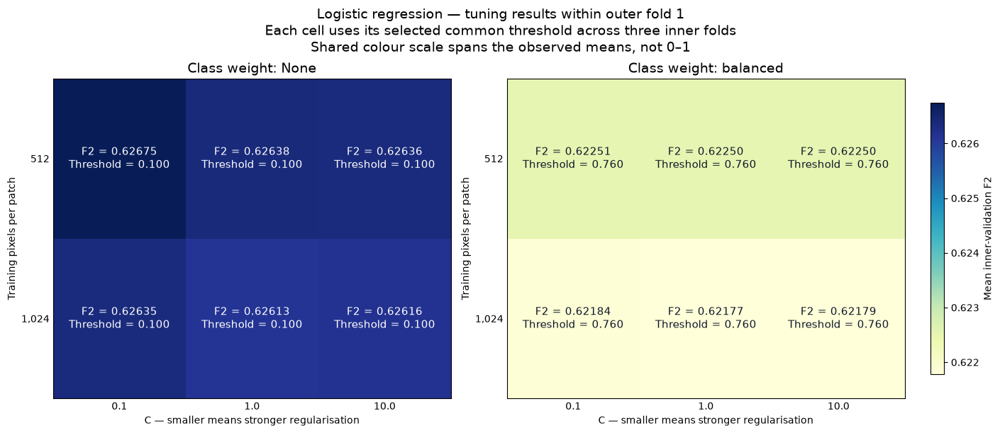

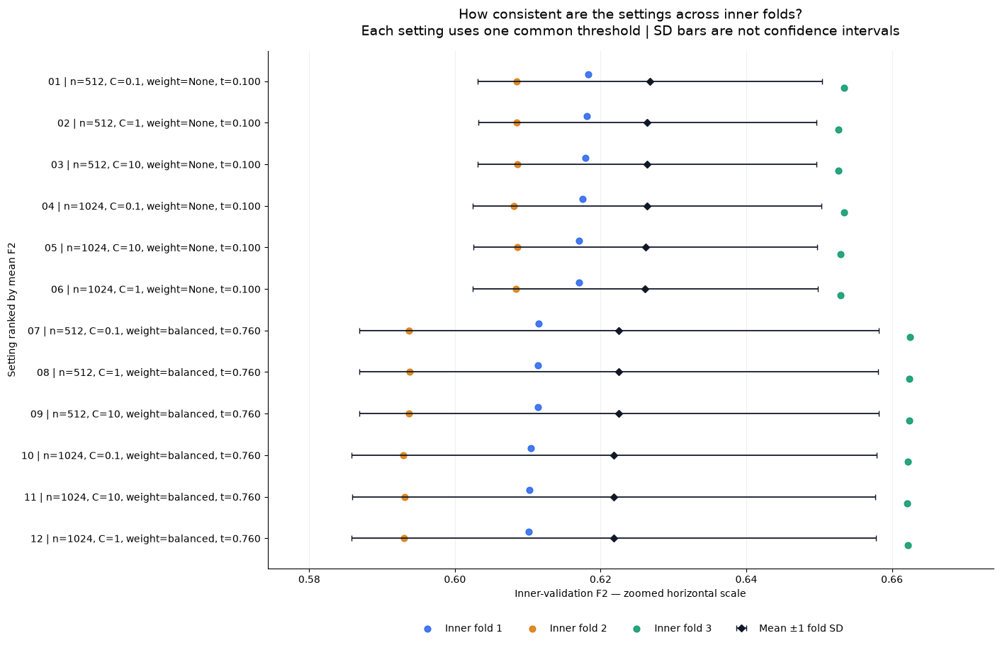

In [46]:
#Hyperparameter Selection
# --------------------------------------------------
# 1. Aggregate inner-fold scores at each threshold.
# --------------------------------------------------
setting_columns = [
    "Pixels per patch", "C", "Class weight"
]

lr_tuning_summary = (
    lr_tuning_results
    .groupby(
        setting_columns + ["Threshold"],
        as_index=False
    )
    .agg(
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_F1=("F1", "mean"),
        Mean_IoU=("IoU", "mean"),
        Fold_count=("F2", "count")
    )
)

assert (lr_tuning_summary["Fold_count"] == 3).all()

# Best common threshold within each setting.
lr_best_settings = (
    lr_tuning_summary
    .sort_values(
        ["Mean_F2", "Mean_precision", "Threshold"],
        ascending=[False, False, False],
        kind="stable",
        na_position="last"
    )
    .drop_duplicates(setting_columns)
    .sort_values(
        [
            "Mean_F2",
            "Mean_precision",
            "Pixels per patch",
            "C",
            "Class weight"
        ],
        ascending=[False, False, True, True, True],
        kind="stable"
    )
    .reset_index(drop=True)
)

lr_best_settings.insert(
    0, "Rank", np.arange(1, len(lr_best_settings) + 1)
)

print("Settings ranked by mean inner-validation F2:")
display(
    lr_best_settings[
        [
            "Rank", *setting_columns, "Threshold",
            "Mean_F2", "SD_F2",
            "Mean_precision", "Mean_recall",
            "Mean_specificity", "Mean_F1", "Mean_IoU"
        ]
    ].round(5)
)

# Preserve selected settings for later use.
lr_selected_tuned = lr_best_settings.iloc[0].copy()

print("\nSelected within outer fold 1:")
print("Pixels per patch:", int(lr_selected_tuned["Pixels per patch"]))
print("C:", lr_selected_tuned["C"])
print("Class weight:", lr_selected_tuned["Class weight"])
print("Threshold:", f"{lr_selected_tuned['Threshold']:.3f}")
print("Mean inner F2:", f"{lr_selected_tuned['Mean_F2']:.5f}")

# --------------------------------------------------
# 2. Heatmaps: best mean F2 for each setting.
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    layout="constrained"
)

vmin = lr_best_settings["Mean_F2"].min()
vmax = lr_best_settings["Mean_F2"].max()

if np.isclose(vmin, vmax, rtol=0, atol=1e-12):
    vmin -= 0.001
    vmax += 0.001

for ax, weight_label in zip(axes, ["None", "balanced"]):
    subset = lr_best_settings.loc[
        lr_best_settings["Class weight"] == weight_label
    ]

    score_matrix = (
        subset.pivot(
            index="Pixels per patch",
            columns="C",
            values="Mean_F2"
        )
        .reindex(index=[512, 1024], columns=C_CANDIDATES)
    )

    threshold_matrix = (
        subset.pivot(
            index="Pixels per patch",
            columns="C",
            values="Threshold"
        )
        .reindex(index=[512, 1024], columns=C_CANDIDATES)
    )

    heatmap = ax.imshow(
        score_matrix.to_numpy(),
        cmap="YlGnBu",
        vmin=vmin,
        vmax=vmax,
        aspect="auto"
    )

    for row in range(2):
        for column in range(len(C_CANDIDATES)):
            value = score_matrix.iloc[row, column]
            threshold = threshold_matrix.iloc[row, column]

            relative_color = (value - vmin) / (vmax - vmin)

            ax.text(
                column, row,
                f"F2 = {value:.5f}\n"
                f"Threshold = {threshold:.3f}",
                ha="center",
                va="center",
                fontsize=11,
                color="white" if relative_color > 0.6 else "#0f172a"
            )

    ax.set_xticks(range(len(C_CANDIDATES)))
    ax.set_xticklabels([str(c) for c in C_CANDIDATES])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["512", "1,024"])
    ax.set_xlabel("C — smaller means stronger regularisation")
    ax.set_ylabel("Training pixels per patch")
    ax.set_title(f"Class weight: {weight_label}", fontsize=14)
    ax.tick_params(length=0)

colorbar = fig.colorbar(
    heatmap,
    ax=list(axes),
    shrink=0.85,
    pad=0.03
)
colorbar.set_label("Mean inner-validation F2")

fig.suptitle(
    "Logistic regression — tuning results within outer fold 1\n"
    "Each cell uses its selected common threshold across three inner folds\n"
    "Shared colour scale spans the observed means, not 0–1",
    fontsize=14
)

plt.show()

# --------------------------------------------------
# 3. Fold-level scores at each setting's common threshold.
# --------------------------------------------------
selected_thresholds = lr_best_settings[
    setting_columns + ["Threshold", "Rank"]
]

lr_selected_fold_scores = lr_tuning_results.merge(
    selected_thresholds,
    on=setting_columns + ["Threshold"],
    how="inner",
    validate="many_to_one"
)

assert len(lr_selected_fold_scores) == 12 * 3

fig, ax = plt.subplots(
    figsize=(14, 9),
    layout="constrained"
)

fold_colors = {
    1: "#2563eb",
    2: "#d97706",
    3: "#059669"
}
fold_offsets = {1: -0.16, 2: 0, 3: 0.16}

for fold_number in [1, 2, 3]:
    points = lr_selected_fold_scores.loc[
        lr_selected_fold_scores["Inner fold"] == fold_number
    ]

    ax.scatter(
        points["F2"],
        points["Rank"] - 1 + fold_offsets[fold_number],
        color=fold_colors[fold_number],
        s=40,
        alpha=0.85,
        label=f"Inner fold {fold_number}",
        zorder=3
    )

ax.errorbar(
    lr_best_settings["Mean_F2"],
    lr_best_settings["Rank"] - 1,
    xerr=lr_best_settings["SD_F2"],
    fmt="D",
    color="#111827",
    markersize=5,
    elinewidth=1.3,
    capsize=3,
    label="Mean ±1 fold SD",
    zorder=4
)

row_labels = [
    f"{int(row['Rank']):02d} | "
    f"n={int(row['Pixels per patch'])}, "
    f"C={row['C']:g}, "
    f"weight={row['Class weight']}, "
    f"t={row['Threshold']:.3f}"
    for _, row in lr_best_settings.iterrows()
]

ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels, fontsize=10)
ax.invert_yaxis()

# Zoom to the observed scores and SD ranges.
lower = min(
    lr_selected_fold_scores["F2"].min(),
    (lr_best_settings["Mean_F2"] - lr_best_settings["SD_F2"]).min()
)
upper = max(
    lr_selected_fold_scores["F2"].max(),
    (lr_best_settings["Mean_F2"] + lr_best_settings["SD_F2"]).max()
)

padding = max(0.005, (upper - lower) * 0.15)

ax.set_xlim(
    max(0, lower - padding),
    min(1, upper + padding)
)

ax.set_xlabel("Inner-validation F2 — zoomed horizontal scale")
ax.set_ylabel("Setting ranked by mean F2")

ax.set_title(
    "How consistent are the settings across inner folds?\n"
    "Each setting uses one common threshold | "
    "SD bars are not confidence intervals",
    fontsize=14,
    pad=16
)

ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.18)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.09),
    ncol=4,
    frameon=False
)

plt.show()

Within outer fold 1, the selected uncalibrated logistic regression uses 512 pixels per patch, C=0.1, no class weighting, and threshold 0.10, achieving mean inner F2=0.62675. Differences between settings are small relative to fold variability. Balanced weighting improves recall but reduces precision and mean F2.

In [47]:
#Calibration
CALIBRATION_FRACTION = 0.20

presence_by_id = (
    dev_manifest.set_index("sample_id")["has_landslide"]
)

lr_calibration_splits = []
calibration_split_rows = []

for inner_number, inner_split in enumerate(
    nested_splits[0]["inner_splits"],
    start=1
):
    inner_training_ids = np.asarray(
        list(map(str, inner_split["train_ids"]))
    )

    validation_ids = np.asarray(
        list(map(str, inner_split["validation_ids"]))
    )

    fitting_ids, calibration_ids = train_test_split(
        inner_training_ids,
        test_size=CALIBRATION_FRACTION,
        random_state=RANDOM_STATE + 100 + inner_number,
        stratify=presence_by_id.loc[
            inner_training_ids
        ].to_numpy()
    )

    fitting_set = set(fitting_ids)
    calibration_set = set(calibration_ids)
    validation_set = set(validation_ids)

    assert fitting_set.isdisjoint(calibration_set)
    assert fitting_set.isdisjoint(validation_set)
    assert calibration_set.isdisjoint(validation_set)

    all_inner_ids = (
        fitting_set | calibration_set | validation_set
    )

    assert all_inner_ids.isdisjoint(
        map(str, nested_splits[0]["evaluation_ids"])
    )
    assert all_inner_ids.isdisjoint(map(str, test_ids))

    lr_calibration_splits.append({
        "inner_fold": inner_number,
        "fitting_ids": fitting_ids,
        "calibration_ids": calibration_ids,
        "validation_ids": validation_ids
    })

    calibration_split_rows.append({
        "Inner fold": inner_number,
        "Model-fitting patches": len(fitting_ids),
        "Calibration patches": len(calibration_ids),
        "Validation patches": len(validation_ids)
    })

display(pd.DataFrame(calibration_split_rows))

print("Outer-evaluation patches used: 0")
print("Final-test patches used: 0")

,Inner fold,Model-fitting patches,Calibration patches,Validation patches
0,1,1296,324,811
1,2,1296,325,810
2,3,1296,325,810


Outer-evaluation patches used: 0
Final-test patches used: 0


A calibration fraction of 0.20 reserves 20% of each inner-training partition for probability calibration. In inner fold 1, this gives 1,296 fitting patches and 324 calibration patches; the 811 validation patches remain separate.

In [48]:
#Sigmoid / Platt · Isotonic Calibration
from sklearn.isotonic import IsotonicRegression
from sklearn.exceptions import ConvergenceWarning
import warnings

calibration_sample_size = int(
    lr_selected_tuned["Pixels per patch"]
)
calibration_base_C = float(lr_selected_tuned["C"])

selected_weight = lr_selected_tuned["Class weight"]
calibration_base_weight = (
    None if selected_weight == "None" else selected_weight
)

# Weak regularisation for the one-dimensional Platt model.
PLATT_C = 1_000_000.0

lr_calibration_models = []
calibration_fit_rows = []

for split in lr_calibration_splits:
    fitting_selector = np.isin(
        sampled_patch_ids, split["fitting_ids"]
    )
    calibration_selector = np.isin(
        sampled_patch_ids, split["calibration_ids"]
    )

    assert not np.any(
        fitting_selector & calibration_selector
    )

    X_fit = X_patch_samples[
        fitting_selector, :calibration_sample_size, :
    ].reshape(-1, len(FEATURE_NAMES))

    y_fit = y_patch_samples[
        fitting_selector, :calibration_sample_size
    ].reshape(-1)

    X_cal = X_patch_samples[
        calibration_selector, :calibration_sample_size, :
    ].reshape(-1, len(FEATURE_NAMES))

    y_cal = y_patch_samples[
        calibration_selector, :calibration_sample_size
    ].reshape(-1)

    assert np.unique(y_cal).size == 2

    base_model = clone(lr_pilot).set_params(
        classifier__C=calibration_base_C,
        classifier__class_weight=calibration_base_weight
    )

    sigmoid_model = LogisticRegression(
        C=PLATT_C,
        solver="lbfgs",
        max_iter=1000,
        class_weight=None
    )

    isotonic_model = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip"
    )

    start = perf_counter()

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)

        # Fit the base model on fitting patches only.
        base_model.fit(X_fit, y_fit)

        # Obtain scores for separate calibration patches.
        calibration_scores = base_model.decision_function(
            X_cal
        )

        sigmoid_model.fit(
            calibration_scores.reshape(-1, 1),
            y_cal
        )

        isotonic_model.fit(
            calibration_scores,
            y_cal
        )

    warning_count = sum(
        issubclass(w.category, ConvergenceWarning)
        for w in caught
    )

    for warning in caught:
        print(
            f"{warning.category.__name__}: {warning.message}"
        )

    lr_calibration_models.append({
        "inner_fold": split["inner_fold"],
        "base_model": base_model,
        "sigmoid_model": sigmoid_model,
        "isotonic_model": isotonic_model,
        "validation_ids": split["validation_ids"]
    })

    calibration_fit_rows.append({
        "Inner fold": split["inner_fold"],
        "Fitting patches": int(fitting_selector.sum()),
        "Calibration patches": int(calibration_selector.sum()),
        "Fitting pixels": len(y_fit),
        "Calibration pixels": len(y_cal),
        "Calibration positive pixels": int((y_cal == 1).sum()),
        "Calibration positive (%)": 100 * (y_cal == 1).mean(),
        "Convergence warnings": warning_count,
        "Fit seconds": perf_counter() - start
    })

    print(
        f"Inner fold {split['inner_fold']}: "
        "base model and calibrators fitted",
        flush=True
    )

    del X_fit, y_fit, X_cal, y_cal, calibration_scores

calibration_fit_summary = pd.DataFrame(
    calibration_fit_rows
)

display(calibration_fit_summary.round(3))

print("Pixels sampled per patch:", calibration_sample_size)
print("Base-model C:", calibration_base_C)
print("Base-model class weight:", calibration_base_weight)
print("Validation patches used for fitting: 0")
print("Outer-evaluation patches used: 0")
print("Final-test patches used: 0")

Inner fold 1: base model and calibrators fitted
Inner fold 2: base model and calibrators fitted
Inner fold 3: base model and calibrators fitted


,Inner fold,Fitting patches,Calibration patches,Fitting pixels,Calibration pixels,Calibration positive pixels,Calibration positive (%),Convergence warnings,Fit seconds
0,1,1296,324,663552,165888,4439,2.676,0,1.072
1,2,1296,325,663552,166400,3973,2.388,0,1.139
2,3,1296,325,663552,166400,3538,2.126,0,1.127


Pixels sampled per patch: 512
Base-model C: 0.1
Base-model class weight: None
Validation patches used for fitting: 0
Outer-evaluation patches used: 0
Final-test patches used: 0


All three base-model/calibrator sets fitted without convergence warnings. Calibration samples retain their observed class proportions. Whether sigmoid or isotonic calibration improves held-out probability quality remains to be assessed.

In [49]:
#Brier Score · Log Loss
from scipy.special import expit

CALIBRATION_METHODS = ["Uncalibrated", "Sigmoid", "Isotonic"]

# Fixed bins for reliability diagrams.
PROBABILITY_BIN_EDGES = np.linspace(0, 1, 21)
N_PROBABILITY_BINS = len(PROBABILITY_BIN_EDGES) - 1

calibration_quality_rows = []
calibration_threshold_tables = []
calibration_bin_rows = []

for bundle in lr_calibration_models:
    fold_number = bundle["inner_fold"]

    accumulators = {
        method: {
            "n": 0,
            "positives": 0,
            "squared_error": 0.0,
            "log_loss_sum": 0.0,
            "tn": np.zeros(len(THRESHOLDS), dtype=np.int64),
            "fp": np.zeros(len(THRESHOLDS), dtype=np.int64),
            "fn": np.zeros(len(THRESHOLDS), dtype=np.int64),
            "tp": np.zeros(len(THRESHOLDS), dtype=np.int64),
            "bin_count": np.zeros(N_PROBABILITY_BINS, dtype=np.int64),
            "bin_probability_sum": np.zeros(N_PROBABILITY_BINS),
            "bin_positive_sum": np.zeros(N_PROBABILITY_BINS)
        }
        for method in CALIBRATION_METHODS
    }

    validation_ids = sorted(
        map(str, bundle["validation_ids"]),
        key=int
    )

    for position, sample_id in enumerate(validation_ids, start=1):
        image_path = (
            DATA_DIR / "TrainData" / "img" / f"image_{sample_id}.h5"
        )
        mask_path = (
            DATA_DIR / "TrainData" / "mask" / f"mask_{sample_id}.h5"
        )

        with h5py.File(image_path, "r") as h5_file:
            features = h5_file["img"][:].reshape(
                -1, len(FEATURE_NAMES)
            )

        with h5py.File(mask_path, "r") as h5_file:
            labels = h5_file["mask"][:].reshape(-1)

        raw_scores = bundle["base_model"].decision_function(features)

        sigmoid_column = int(np.flatnonzero(
            bundle["sigmoid_model"].classes_ == 1
        )[0])

        method_probabilities = {
            "Uncalibrated": expit(raw_scores),
            "Sigmoid": bundle["sigmoid_model"].predict_proba(
                raw_scores.reshape(-1, 1)
            )[:, sigmoid_column],
            "Isotonic": bundle["isotonic_model"].predict(raw_scores)
        }

        for method, probabilities in method_probabilities.items():
            if (
                not np.isfinite(probabilities).all()
                or (probabilities < 0).any()
                or (probabilities > 1).any()
            ):
                raise ValueError(
                    f"Invalid probabilities: fold {fold_number}, {method}"
                )

            acc = accumulators[method]

            acc["n"] += len(labels)
            acc["positives"] += int(labels.sum())
            acc["squared_error"] += float(
                np.square(probabilities - labels).sum()
            )

            # Avoid log(0) when a method returns exactly 0 or 1.
            epsilon = np.finfo(np.float64).eps
            clipped = np.clip(probabilities, epsilon, 1 - epsilon)

            acc["log_loss_sum"] += float(
                -(
                    labels * np.log(clipped)
                    + (1 - labels) * np.log1p(-clipped)
                ).sum()
            )

            positive_probs = np.sort(probabilities[labels == 1])
            negative_probs = np.sort(probabilities[labels == 0])

            fn = np.searchsorted(
                positive_probs, THRESHOLDS, side="left"
            )
            tn = np.searchsorted(
                negative_probs, THRESHOLDS, side="left"
            )

            acc["fn"] += fn
            acc["tn"] += tn
            acc["tp"] += len(positive_probs) - fn
            acc["fp"] += len(negative_probs) - tn

            # Bins: [0, .05), [.05, .10), ..., [.95, 1].
            bin_ids = np.searchsorted(
                PROBABILITY_BIN_EDGES,
                probabilities,
                side="right"
            ) - 1

            bin_ids = np.clip(
                bin_ids, 0, N_PROBABILITY_BINS - 1
            )

            acc["bin_count"] += np.bincount(
                bin_ids, minlength=N_PROBABILITY_BINS
            )
            acc["bin_probability_sum"] += np.bincount(
                bin_ids,
                weights=probabilities,
                minlength=N_PROBABILITY_BINS
            )
            acc["bin_positive_sum"] += np.bincount(
                bin_ids,
                weights=labels,
                minlength=N_PROBABILITY_BINS
            )

        if position % 200 == 0 or position == len(validation_ids):
            print(
                f"Inner fold {fold_number}: "
                f"{position:,}/{len(validation_ids):,} patches",
                flush=True
            )

    for method, acc in accumulators.items():
        calibration_quality_rows.append({
            "Inner fold": fold_number,
            "Method": method,
            "Pixels": acc["n"],
            "Positive prevalence": acc["positives"] / acc["n"],
            "Brier score": acc["squared_error"] / acc["n"],
            "Log loss": acc["log_loss_sum"] / acc["n"]
        })

        threshold_rows = []

        for index, threshold in enumerate(THRESHOLDS):
            threshold_rows.append({
                "Inner fold": fold_number,
                "Method": method,
                "Threshold": float(threshold),
                **metrics_from_counts(
                    acc["tn"][index],
                    acc["fp"][index],
                    acc["fn"][index],
                    acc["tp"][index]
                )
            })

        calibration_threshold_tables.append(
            pd.DataFrame(threshold_rows)
        )

        for bin_index in range(N_PROBABILITY_BINS):
            calibration_bin_rows.append({
                "Inner fold": fold_number,
                "Method": method,
                "Bin": bin_index,
                "Count": int(acc["bin_count"][bin_index]),
                "Probability sum":
                    acc["bin_probability_sum"][bin_index],
                "Positive sum":
                    acc["bin_positive_sum"][bin_index]
            })

calibration_quality = pd.DataFrame(calibration_quality_rows)

calibration_threshold_results = pd.concat(
    calibration_threshold_tables,
    ignore_index=True
)

calibration_bins = pd.DataFrame(calibration_bin_rows)

print("\nProbability quality by inner fold:")
display(calibration_quality.round(6))

print("\nMean probability scores across three inner folds:")
display(
    calibration_quality.groupby("Method")[
        ["Brier score", "Log loss"]
    ].agg(["mean", "std"]).round(6)
)

print("Outer-evaluation patches used: 0")
print("Final-test patches used: 0")

Inner fold 1: 200/811 patches
Inner fold 1: 400/811 patches
Inner fold 1: 600/811 patches
Inner fold 1: 800/811 patches
Inner fold 1: 811/811 patches
Inner fold 2: 200/810 patches
Inner fold 2: 400/810 patches
Inner fold 2: 600/810 patches
Inner fold 2: 800/810 patches
Inner fold 2: 810/810 patches
Inner fold 3: 200/810 patches
Inner fold 3: 400/810 patches
Inner fold 3: 600/810 patches
Inner fold 3: 800/810 patches
Inner fold 3: 810/810 patches

Probability quality by inner fold:


,Inner fold,Method,Pixels,Positive prevalence,Brier score,Log loss
0,1,Uncalibrated,13287424,0.022933,0.014550,0.054736
1,1,Sigmoid,13287424,0.022933,0.014695,0.055320
2,1,Isotonic,13287424,0.022933,0.014605,0.054905
3,2,Uncalibrated,13271040,0.021040,0.013715,0.052393
4,2,Sigmoid,13271040,0.021040,0.013724,0.052301
5,2,Isotonic,13271040,0.021040,0.013587,0.051199
6,3,Uncalibrated,13271040,0.025849,0.014849,0.056377
7,3,Sigmoid,13271040,0.025849,0.014653,0.055916
8,3,Isotonic,13271040,0.025849,0.014512,0.055836



Mean probability scores across three inner folds:


Brier score            Log loss          
                    mean       std      mean       std
Method                                                
Isotonic        0.014234  0.000563  0.053980  0.002453
Sigmoid         0.014358  0.000549  0.054512  0.001938
Uncalibrated    0.014372  0.000588  0.054502  0.002002

Outer-evaluation patches used: 0
Final-test patches used: 0


Isotonic calibration yields the lowest mean Brier score (0.014234) and log loss (0.053980), with modest improvements over uncalibrated probabilities. Benefits vary across folds; calibration-method selection remains pending.

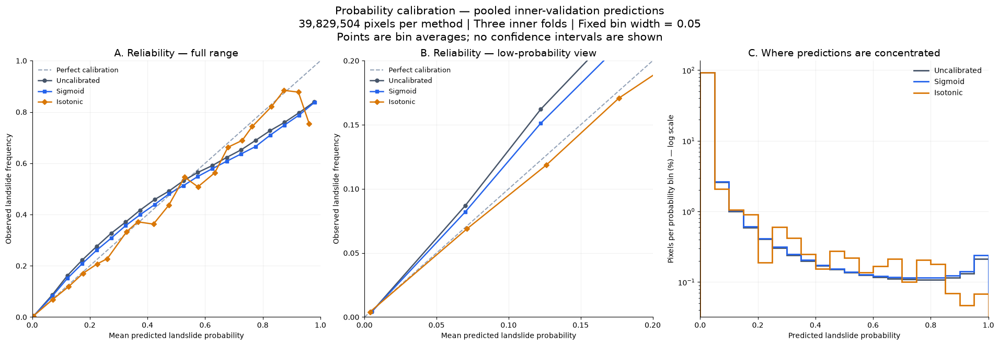

Bin support and reliability values:


,Method,Bin,Count,Mean probability,Observed frequency
0,Isotonic,0,36913942,0.00385,0.00403
1,Isotonic,1,824274,0.07117,0.06888
2,Isotonic,2,416853,0.12606,0.11849
3,Isotonic,3,360373,0.17652,0.17079
4,Isotonic,4,75024,0.22503,0.20723
5,Isotonic,5,241008,0.26057,0.22788
6,Isotonic,6,167215,0.32744,0.33282
7,Isotonic,7,99355,0.36634,0.37146
8,Isotonic,8,61752,0.42062,0.36264
9,Isotonic,9,110114,0.47404,0.43655


In [50]:
#Reliability Diagram
# Pool bin totals across the three inner-validation folds.
reliability_summary = (
    calibration_bins
    .groupby(["Method", "Bin"], as_index=False)[
        ["Count", "Probability sum", "Positive sum"]
    ]
    .sum()
)

# Empty bins remain undefined rather than being plotted as zero.
denominator = reliability_summary["Count"].replace(0, np.nan)

reliability_summary["Mean probability"] = (
    reliability_summary["Probability sum"] / denominator
)

reliability_summary["Observed frequency"] = (
    reliability_summary["Positive sum"] / denominator
)

method_colors = {
    "Uncalibrated": "#475569",
    "Sigmoid": "#2563eb",
    "Isotonic": "#d97706"
}

method_markers = {
    "Uncalibrated": "o",
    "Sigmoid": "s",
    "Isotonic": "D"
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 6.5),
    layout="constrained"
)

# A and B: full and low-probability reliability views.
for ax in axes[:2]:
    ax.plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="#94a3b8",
        linewidth=1.5,
        label="Perfect calibration"
    )

for method in CALIBRATION_METHODS:
    table = (
        reliability_summary.loc[
            reliability_summary["Method"] == method
        ]
        .sort_values("Bin")
    )

    for ax in axes[:2]:
        ax.plot(
            table["Mean probability"],
            table["Observed frequency"],
            color=method_colors[method],
            marker=method_markers[method],
            markersize=5,
            linewidth=1.8,
            label=method
        )

    # C: probability distribution, normalised within method.
    bin_counts = (
        table.set_index("Bin")["Count"]
        .reindex(range(N_PROBABILITY_BINS), fill_value=0)
        .to_numpy()
    )

    percentages = 100 * bin_counts / bin_counts.sum()

    # Zero-frequency intervals have no position on a log scale.
    percentages = np.where(
        percentages > 0,
        percentages,
        np.nan
    )

    axes[2].stairs(
        percentages,
        PROBABILITY_BIN_EDGES,
        color=method_colors[method],
        linewidth=2,
        label=method
    )

axes[0].set_title("A. Reliability — full range", fontsize=14)
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)

axes[1].set_title("B. Reliability — low-probability view", fontsize=14)
axes[1].set_xlim(0, 0.20)
axes[1].set_ylim(0, 0.20)
axes[1].set_xticks(np.arange(0, 0.201, 0.05))
axes[1].set_yticks(np.arange(0, 0.201, 0.05))

for ax in axes[:2]:
    ax.set_xlabel("Mean predicted landslide probability")
    ax.set_ylabel("Observed landslide frequency")
    ax.legend(
        loc="upper left",
        frameon=False,
        fontsize=9
    )

axes[2].set_title("C. Where predictions are concentrated", fontsize=14)
axes[2].set_xlabel("Predicted landslide probability")
axes[2].set_ylabel("Pixels per probability bin (%) — log scale")
axes[2].set_xlim(0, 1)
axes[2].set_yscale("log")
axes[2].legend(frameon=False, fontsize=10)

for ax in axes:
    ax.grid(alpha=0.18)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

pixels_per_method = (
    reliability_summary.groupby("Method")["Count"].sum()
)

assert pixels_per_method.nunique() == 1

fig.suptitle(
    "Probability calibration — pooled inner-validation predictions\n"
    f"{int(pixels_per_method.iloc[0]):,} pixels per method | "
    "Three inner folds | Fixed bin width = 0.05\n"
    "Points are bin averages; no confidence intervals are shown",
    fontsize=15
)

plt.show()

print("Bin support and reliability values:")
display(
    reliability_summary[
        [
            "Method", "Bin", "Count",
            "Mean probability", "Observed frequency"
        ]
    ].round(5)
)

The reliability plots compare predicted landslide probabilities with observed landslide frequencies. Points above the diagonal indicate underestimated probabilities; points below indicate overestimated probabilities. Isotonic calibration follows the diagonal more closely in several low-probability bins but overestimates probabilities in some high-probability bins.
The probability-distribution plot shows that approximately 93% of pixels receive probabilities below 0.05. Its logarithmic vertical axis makes less-populated bins visible. These pooled results suggest modest calibration improvements, but no method is consistently best across the entire probability range.

Calibration comparison at each method's selected threshold:


,Method,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_F1,Mean_IoU,Mean_Brier,Mean_log_loss
0,Uncalibrated,0.10,0.625593,0.023622,0.395225,0.735935,0.972959,0.512407,0.345318,0.014372,0.054502
1,Sigmoid,0.10,0.624663,0.025156,0.384789,0.742530,0.971519,0.505702,0.339035,0.014358,0.054512
2,Isotonic,0.12,0.623557,0.026034,0.363778,0.765599,0.967623,0.490462,0.326007,0.014234,0.053980



Selected by mean inner F2:
Method: Uncalibrated
Threshold: 0.100


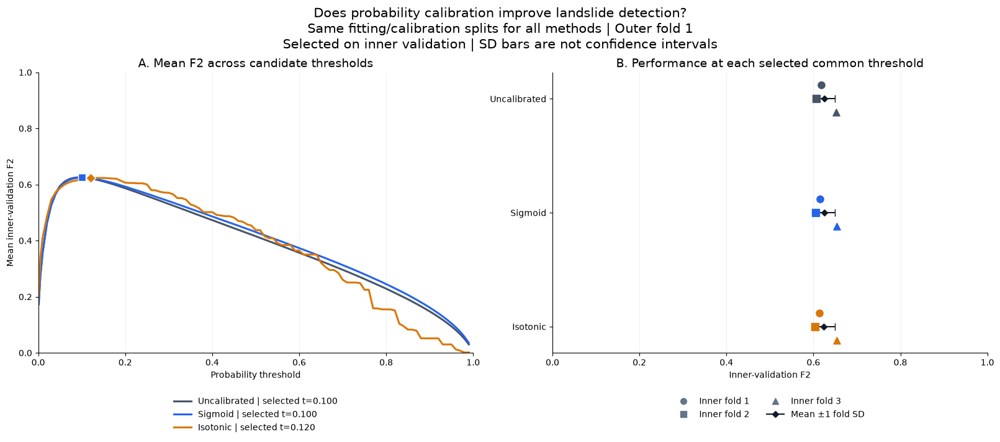

In [51]:
#Calibration and Threshold Selection
# --------------------------------------------------
# 1. Mean performance at each common threshold.
# --------------------------------------------------
calibration_selection_summary = (
    calibration_threshold_results
    .groupby(["Method", "Threshold"], as_index=False)
    .agg(
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_F1=("F1", "mean"),
        Mean_IoU=("IoU", "mean"),
        Fold_count=("F2", "count")
    )
)

assert (
    calibration_selection_summary["Fold_count"] == 3
).all()

# Select one common threshold per method.
best_calibration_settings = (
    calibration_selection_summary
    .sort_values(
        ["Mean_F2", "Mean_precision", "Threshold"],
        ascending=[False, False, False],
        kind="stable"
    )
    .drop_duplicates("Method")
)

probability_score_means = (
    calibration_quality.groupby("Method", as_index=False)
    .agg(
        Mean_Brier=("Brier score", "mean"),
        Mean_log_loss=("Log loss", "mean")
    )
)

best_calibration_settings = best_calibration_settings.merge(
    probability_score_means,
    on="Method",
    validate="one_to_one"
)

# Deterministic tie-breaker after F2 and precision.
method_order = {
    "Uncalibrated": 0,
    "Sigmoid": 1,
    "Isotonic": 2
}

best_calibration_settings["Method order"] = (
    best_calibration_settings["Method"].map(method_order)
)

best_calibration_settings = (
    best_calibration_settings.sort_values(
        ["Mean_F2", "Mean_precision", "Method order"],
        ascending=[False, False, True]
    )
    .reset_index(drop=True)
)

selected_calibration_setting = (
    best_calibration_settings.iloc[0].copy()
)

print("Calibration comparison at each method's selected threshold:")

display(
    best_calibration_settings[
        [
            "Method", "Threshold",
            "Mean_F2", "SD_F2",
            "Mean_precision", "Mean_recall",
            "Mean_specificity", "Mean_F1", "Mean_IoU",
            "Mean_Brier", "Mean_log_loss"
        ]
    ].round(6)
)

print("\nSelected by mean inner F2:")
print("Method:", selected_calibration_setting["Method"])
print(
    "Threshold:",
    f"{selected_calibration_setting['Threshold']:.3f}"
)

# --------------------------------------------------
# 2. Plot threshold curves and fold-level performance.
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    layout="constrained"
)

for method in CALIBRATION_METHODS:
    curve = (
        calibration_selection_summary.loc[
            calibration_selection_summary["Method"] == method
        ]
        .sort_values("Threshold")
    )

    best = best_calibration_settings.loc[
        best_calibration_settings["Method"] == method
    ].iloc[0]

    axes[0].plot(
        curve["Threshold"],
        curve["Mean_F2"],
        color=method_colors[method],
        linewidth=2.2,
        label=f"{method} | selected t={best['Threshold']:.3f}"
    )

    axes[0].scatter(
        best["Threshold"],
        best["Mean_F2"],
        color=method_colors[method],
        marker=method_markers[method],
        edgecolor="white",
        s=65,
        zorder=5
    )

axes[0].set_title(
    "A. Mean F2 across candidate thresholds",
    fontsize=14
)
axes[0].set_xlabel("Probability threshold")
axes[0].set_ylabel("Mean inner-validation F2")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    frameon=False,
    fontsize=10
)

# Use the selected common threshold, not each fold's own optimum.
calibration_selected_fold_scores = (
    calibration_threshold_results.merge(
        best_calibration_settings[["Method", "Threshold"]],
        on=["Method", "Threshold"],
        validate="many_to_one"
    )
)

assert len(calibration_selected_fold_scores) == 9

fold_markers = {1: "o", 2: "s", 3: "^"}
fold_offsets = {1: -0.12, 2: 0, 3: 0.12}

for method_index, method in enumerate(CALIBRATION_METHODS):
    points = calibration_selected_fold_scores.loc[
        calibration_selected_fold_scores["Method"] == method
    ]

    for _, point in points.iterrows():
        fold = int(point["Inner fold"])

        axes[1].scatter(
            point["F2"],
            method_index + fold_offsets[fold],
            color=method_colors[method],
            marker=fold_markers[fold],
            s=65,
            zorder=4
        )

    best = best_calibration_settings.loc[
        best_calibration_settings["Method"] == method
    ].iloc[0]

    axes[1].errorbar(
        best["Mean_F2"],
        method_index,
        xerr=best["SD_F2"],
        fmt="D",
        color="#111827",
        capsize=4,
        markersize=5,
        zorder=3
    )

axes[1].set_yticks(range(3))
axes[1].set_yticklabels(CALIBRATION_METHODS)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Inner-validation F2")
axes[1].set_title(
    "B. Performance at each selected common threshold",
    fontsize=14
)

from matplotlib.lines import Line2D

fold_legend = [
    Line2D(
        [0], [0],
        marker=fold_markers[fold],
        linestyle="",
        color="#64748b",
        markersize=7,
        label=f"Inner fold {fold}"
    )
    for fold in [1, 2, 3]
]

fold_legend.append(
    Line2D(
        [0], [0],
        marker="D",
        color="#111827",
        markersize=5,
        label="Mean ±1 fold SD"
    )
)

axes[1].legend(
    handles=fold_legend,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=2,
    frameon=False,
    fontsize=10
)

for ax in axes:
    ax.grid(axis="x", alpha=0.18)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Does probability calibration improve landslide detection?\n"
    "Same fitting/calibration splits for all methods | Outer fold 1\n"
    "Selected on inner validation | SD bars are not confidence intervals",
    fontsize=15
)

plt.show()

The left plot shows similar peak mean F2 across methods, with uncalibrated probabilities achieving the highest value (0.62559) at threshold 0.10. The right plot shows that between-fold variability exceeds the differences in method means; bars represent ±1 fold SD, not confidence intervals. Isotonic calibration modestly improves probability scores but does not improve threshold-selected F2 in this experiment. Outer evaluation remains pending.

Frozen configuration: {'pixels_per_patch': 512, 'C': 0.1, 'class_weight': None, 'calibration': 'Uncalibrated', 'threshold': 0.1}

Refit time: 1.73 seconds
Outer-training patches: 2431
Sampled training pixels: 1244672
Outer-evaluation patches: 608
Solver iterations: [49]

Refitted intercept: -6.3130803


,Feature,Coefficient,Absolute coefficient
6,B7,-4.04591,4.04591
1,B2,-2.08732,2.08732
2,B3,2.04531,2.04531
5,B6,2.01538,2.01538
10,B11,-1.20949,1.20949
4,B5,1.17208,1.17208
8,B9,1.11851,1.11851
11,B12,1.06259,1.06259
12,Slope,1.04298,1.04298
7,B8,-0.88819,0.88819



Full outer-evaluation results:


,Threshold,TN,FP,FN,TP,Precision,Recall,Specificity,F1,F2,IoU,Balanced accuracy,Accuracy
0,0.1,9451093,259955,67491,182933,0.41305,0.73049,0.97323,0.52771,0.63317,0.35843,0.85186,0.96713
1,0.5,9671889,39159,151926,98498,0.71553,0.39332,0.99597,0.50762,0.43225,0.34014,0.69465,0.98082


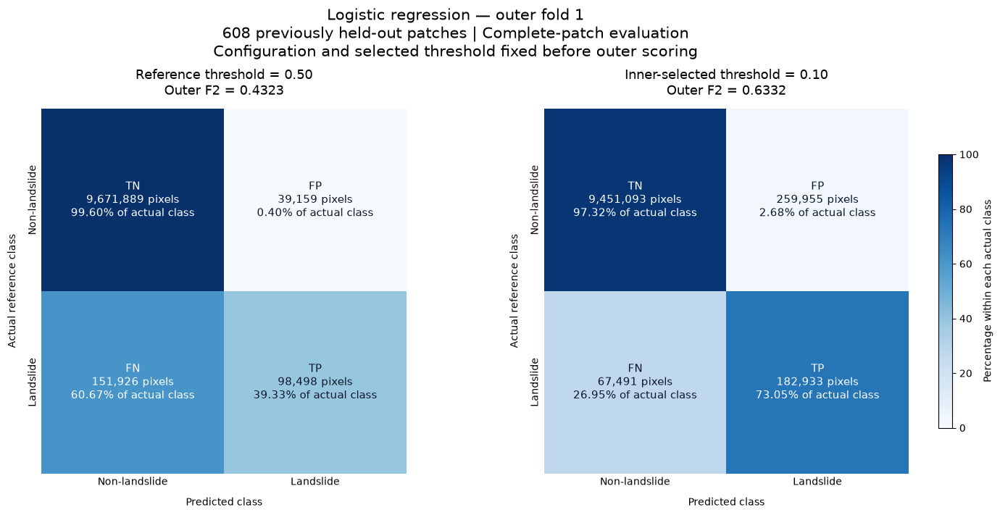

Final-test patches used: 0


In [52]:
#Outer-fold Evaluation
# --------------------------------------------------
# 1. Freeze the choices made using inner validation.
# --------------------------------------------------
assert selected_calibration_setting["Method"] == "Uncalibrated"

lr_outer1_recipe = {
    "pixels_per_patch": int(
        lr_selected_tuned["Pixels per patch"]
    ),
    "C": float(lr_selected_tuned["C"]),
    "class_weight": (
        None
        if lr_selected_tuned["Class weight"] == "None"
        else lr_selected_tuned["Class weight"]
    ),
    "calibration": "Uncalibrated",
    "threshold": float(
        selected_calibration_setting["Threshold"]
    )
}

outer1 = nested_splits[0]

outer_training_ids = set(map(str, outer1["train_ids"]))
outer_evaluation_ids = set(
    map(str, outer1["evaluation_ids"])
)

assert outer_training_ids.isdisjoint(outer_evaluation_ids)
assert (
    outer_training_ids | outer_evaluation_ids
).isdisjoint(map(str, test_ids))

print("Frozen configuration:", lr_outer1_recipe)

# --------------------------------------------------
# 2. Refit on the complete outer-training partition.
# --------------------------------------------------
outer_training_selector = np.isin(
    sampled_patch_ids,
    list(outer_training_ids)
)

sample_size = lr_outer1_recipe["pixels_per_patch"]

X_outer1_train = X_patch_samples[
    outer_training_selector, :sample_size, :
].reshape(-1, len(FEATURE_NAMES))

y_outer1_train = y_patch_samples[
    outer_training_selector, :sample_size
].reshape(-1)

lr_outer1_model = clone(lr_pilot).set_params(
    classifier__C=lr_outer1_recipe["C"],
    classifier__class_weight=lr_outer1_recipe["class_weight"]
)

fit_start = perf_counter()

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    lr_outer1_model.fit(X_outer1_train, y_outer1_train)

for warning in caught:
    print(f"{warning.category.__name__}: {warning.message}")

if any(
    issubclass(w.category, ConvergenceWarning)
    for w in caught
):
    raise RuntimeError(
        "Convergence warning: inspect before outer evaluation."
    )

print(f"\nRefit time: {perf_counter() - fit_start:.2f} seconds")
print("Outer-training patches:", len(outer_training_ids))
print("Sampled training pixels:", len(y_outer1_train))
print("Outer-evaluation patches:", len(outer_evaluation_ids))
print(
    "Solver iterations:",
    lr_outer1_model.named_steps["classifier"].n_iter_
)

# Report the refitted model's coefficients.
outer1_coefficients = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Coefficient":
        lr_outer1_model.named_steps["classifier"].coef_[0]
})

outer1_coefficients["Absolute coefficient"] = (
    outer1_coefficients["Coefficient"].abs()
)

print(
    "\nRefitted intercept:",
    lr_outer1_model.named_steps["classifier"].intercept_[0]
)
display(
    outer1_coefficients.sort_values(
        "Absolute coefficient", ascending=False
    ).round(5)
)

# --------------------------------------------------
# 3. Evaluate selected and reference thresholds.
# Neither is selected using outer results.
# --------------------------------------------------
evaluation_thresholds = np.unique([
    0.50,
    lr_outer1_recipe["threshold"]
])

lr_outer1_results = evaluate_full_patches_at_thresholds(
    lr_outer1_model,
    outer_evaluation_ids,
    evaluation_thresholds
)

print("\nFull outer-evaluation results:")
display(
    lr_outer1_results[
        [
            "Threshold", "TN", "FP", "FN", "TP",
            "Precision", "Recall", "Specificity",
            "F1", "F2", "IoU", "Balanced accuracy", "Accuracy"
        ]
    ].round(5)
)

# --------------------------------------------------
# 4. Confusion matrices with counts and row percentages.
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 7),
    layout="constrained"
)

for ax, threshold in zip(
    axes,
    [0.50, lr_outer1_recipe["threshold"]]
):
    result = lr_outer1_results.loc[
        np.isclose(
            lr_outer1_results["Threshold"],
            threshold
        )
    ].iloc[0]

    matrix = np.array([
        [int(result["TN"]), int(result["FP"])],
        [int(result["FN"]), int(result["TP"])]
    ])

    row_totals = matrix.sum(axis=1, keepdims=True)

    percentages = np.divide(
        100.0 * matrix,
        row_totals,
        out=np.zeros_like(matrix, dtype=float),
        where=row_totals != 0
    )

    heatmap = ax.imshow(
        percentages,
        cmap="Blues",
        vmin=0,
        vmax=100
    )

    for row in range(2):
        for column in range(2):
            value = percentages[row, column]

            ax.text(
                column, row,
                f"{[['TN', 'FP'], ['FN', 'TP']][row][column]}\n"
                f"{matrix[row, column]:,} pixels\n"
                f"{value:.2f}% of actual class",
                ha="center",
                va="center",
                fontsize=11,
                color="white" if value >= 55 else "#0f172a"
            )

    label = (
        "Reference"
        if threshold == 0.50
        else "Inner-selected"
    )

    ax.set_title(
        f"{label} threshold = {threshold:.2f}\n"
        f"Outer F2 = {result['F2']:.4f}",
        fontsize=13,
        pad=14
    )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Non-landslide", "Landslide"])
    ax.set_yticklabels(
        ["Non-landslide", "Landslide"],
        rotation=90,
        va="center"
    )
    ax.set_xlabel("Predicted class", labelpad=10)
    ax.set_ylabel("Actual reference class", labelpad=10)
    ax.tick_params(length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

colorbar = fig.colorbar(
    heatmap,
    ax=list(axes),
    shrink=0.75,
    pad=0.03
)
colorbar.set_label("Percentage within each actual class")

fig.suptitle(
    "Logistic regression — outer fold 1\n"
    f"{len(outer_evaluation_ids):,} previously held-out patches | "
    "Complete-patch evaluation\n"
    "Configuration and selected threshold fixed before outer scoring",
    fontsize=15
)

plt.show()

print("Final-test patches used: 0")

On outer fold 1, the inner-selected threshold of 0.10 increases F2 from 0.43225 to 0.63317 and recall from 39.33% to 73.05%. The confusion matrices show fewer missed landslide pixels but substantially more false positives; precision falls to 41.30%. This documents the detection–false-alarm trade-off on held-out patches, not final deployment readiness or five-fold performance.

In [53]:
# Preserve completed results from outer fold 1.
if "lr_search_by_outer" not in globals():
    lr_search_by_outer = {}

lr_search_by_outer.setdefault(
    1,
    {
        "results": lr_tuning_results.copy(),
        "selected": lr_selected_tuned.copy()
    }
)


def run_lr_inner_search(outer_fold):
    """Select LR settings using this outer fold's training data only."""
    outer_number = outer_fold["outer_fold"]

    result_tables = []
    completed_runs = 0
    expected_runs = 2 * 3 * 2 * 3

    forbidden_ids = (
        set(map(str, outer_fold["evaluation_ids"]))
        | set(map(str, test_ids))
    )

    for sample_size in [512, 1024]:
        for C_value in C_CANDIDATES:
            for weight in [None, "balanced"]:
                weight_label = (
                    "None" if weight is None else weight
                )

                for inner_number, split in enumerate(
                    outer_fold["inner_splits"],
                    start=1
                ):
                    fitting_ids = set(
                        map(str, split["train_ids"])
                    )
                    validation_ids = set(
                        map(str, split["validation_ids"])
                    )

                    assert fitting_ids.isdisjoint(validation_ids)
                    assert (
                        fitting_ids | validation_ids
                    ).isdisjoint(forbidden_ids)

                    selector = np.isin(
                        sampled_patch_ids,
                        list(fitting_ids)
                    )

                    X_current = X_patch_samples[
                        selector, :sample_size, :
                    ].reshape(-1, len(FEATURE_NAMES))

                    y_current = y_patch_samples[
                        selector, :sample_size
                    ].reshape(-1)

                    model = clone(lr_pilot).set_params(
                        classifier__C=C_value,
                        classifier__class_weight=weight
                    )

                    with warnings.catch_warnings(record=True) as caught:
                        warnings.simplefilter(
                            "always", ConvergenceWarning
                        )
                        model.fit(X_current, y_current)

                    for warning in caught:
                        print(
                            f"{warning.category.__name__}: "
                            f"{warning.message}"
                        )

                    if any(
                        issubclass(w.category, ConvergenceWarning)
                        for w in caught
                    ):
                        raise RuntimeError(
                            f"Inspect convergence in outer "
                            f"{outer_number}, inner {inner_number}."
                        )

                    scores = evaluate_full_patches_at_thresholds(
                        model,
                        validation_ids,
                        THRESHOLDS
                    )

                    scores["Pixels per patch"] = sample_size
                    scores["C"] = C_value
                    scores["Class weight"] = weight_label
                    scores["Inner fold"] = inner_number

                    result_tables.append(scores)
                    completed_runs += 1

                    print(
                        f"Outer {outer_number} | "
                        f"Run {completed_runs}/{expected_runs} | "
                        f"n={sample_size}, C={C_value}, "
                        f"weight={weight_label}, inner={inner_number}",
                        flush=True
                    )

                    del X_current, y_current, model

    results = pd.concat(result_tables, ignore_index=True)

    summary = (
        results.groupby(
            ["Pixels per patch", "C", "Class weight", "Threshold"],
            as_index=False
        )
        .agg(
            Mean_F2=("F2", "mean"),
            SD_F2=("F2", "std"),
            Mean_precision=("Precision", "mean"),
            Mean_recall=("Recall", "mean"),
            Mean_specificity=("Specificity", "mean"),
            Fold_count=("F2", "count")
        )
    )

    assert (summary["Fold_count"] == 3).all()
    assert len(results) == expected_runs * len(THRESHOLDS)

    # Same selection order as outer fold 1.
    best_by_setting = (
        summary.sort_values(
            ["Mean_F2", "Mean_precision", "Threshold"],
            ascending=[False, False, False],
            kind="stable"
        )
        .drop_duplicates(
            ["Pixels per patch", "C", "Class weight"]
        )
        .sort_values(
            [
                "Mean_F2", "Mean_precision",
                "Pixels per patch", "C", "Class weight"
            ],
            ascending=[False, False, True, True, True],
            kind="stable"
        )
        .reset_index(drop=True)
    )

    return {
        "results": results,
        "summary": summary,
        "selected": best_by_setting.iloc[0].copy()
    }


# Completed outer-fold searches are not repeated.
for outer_fold in nested_splits[1:]:
    number = outer_fold["outer_fold"]

    if number in lr_search_by_outer:
        print(f"Outer {number}: existing results retained.")
        continue

    print(f"\nStarting inner search for outer fold {number}", flush=True)

    lr_search_by_outer[number] = run_lr_inner_search(
        outer_fold
    )

selection_rows = []

for number in sorted(lr_search_by_outer):
    selected = lr_search_by_outer[number]["selected"]

    selection_rows.append({
        "Outer fold": number,
        "Pixels per patch": int(selected["Pixels per patch"]),
        "C": selected["C"],
        "Class weight": selected["Class weight"],
        "Threshold": selected["Threshold"],
        "Mean inner F2": selected["Mean_F2"],
        "Inner F2 SD": selected["SD_F2"]
    })

lr_selection_across_outer = pd.DataFrame(selection_rows)

print("\nInternal selections — before calibration comparison:")
display(lr_selection_across_outer.round(5))

print("New outer-evaluation predictions performed: 0")
print("Final-test patches used: 0")


Starting inner search for outer fold 2
Outer 2 | Run 1/36 | n=512, C=0.1, weight=None, inner=1
Outer 2 | Run 2/36 | n=512, C=0.1, weight=None, inner=2
Outer 2 | Run 3/36 | n=512, C=0.1, weight=None, inner=3
Outer 2 | Run 4/36 | n=512, C=0.1, weight=balanced, inner=1
Outer 2 | Run 5/36 | n=512, C=0.1, weight=balanced, inner=2
Outer 2 | Run 6/36 | n=512, C=0.1, weight=balanced, inner=3
Outer 2 | Run 7/36 | n=512, C=1.0, weight=None, inner=1
Outer 2 | Run 8/36 | n=512, C=1.0, weight=None, inner=2
Outer 2 | Run 9/36 | n=512, C=1.0, weight=None, inner=3
Outer 2 | Run 10/36 | n=512, C=1.0, weight=balanced, inner=1
Outer 2 | Run 11/36 | n=512, C=1.0, weight=balanced, inner=2
Outer 2 | Run 12/36 | n=512, C=1.0, weight=balanced, inner=3
Outer 2 | Run 13/36 | n=512, C=10.0, weight=None, inner=1
Outer 2 | Run 14/36 | n=512, C=10.0, weight=None, inner=2
Outer 2 | Run 15/36 | n=512, C=10.0, weight=None, inner=3
Outer 2 | Run 16/36 | n=512, C=10.0, weight=balanced, inner=1
Outer 2 | Run 17/36 | n=5

,Outer fold,Pixels per patch,C,Class weight,Threshold,Mean inner F2,Inner F2 SD
0,1,512,0.1,None,0.1,0.62675,0.02364
1,2,512,0.1,None,0.1,0.63127,0.00869
2,3,512,0.1,None,0.1,0.63246,0.00754
3,4,512,0.1,None,0.1,0.62319,0.01050
4,5,1024,0.1,None,0.1,0.62880,0.01088


New outer-evaluation predictions performed: 0
Final-test patches used: 0


All five inner searches selected C=0.1, no class weighting, and threshold 0.10. Four selected 512 pixels per patch; one selected 1,024. These are internal selection results, not outer-fold performance estimates. Calibration comparison remains incomplete for folds 2–5.

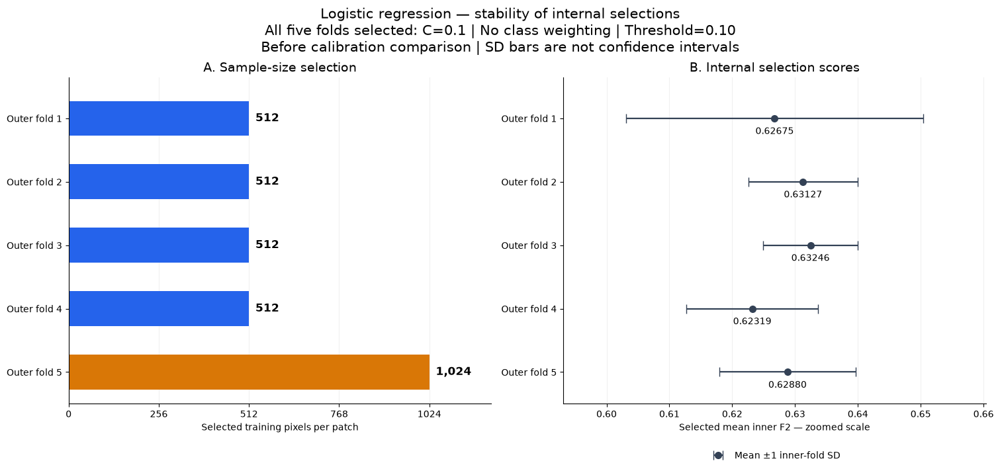

In [54]:
#Selection Stability
selection_plot = (
    lr_selection_across_outer
    .sort_values("Outer fold")
    .copy()
)

folds = selection_plot["Outer fold"].to_numpy()
y_positions = np.arange(len(folds))

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 7),
    layout="constrained"
)

# A. Selected sample sizes.
sample_colors = [
    "#2563eb" if size == 512 else "#d97706"
    for size in selection_plot["Pixels per patch"]
]

bars = axes[0].barh(
    y_positions,
    selection_plot["Pixels per patch"],
    color=sample_colors,
    height=0.55
)

for bar, size in zip(
    bars, selection_plot["Pixels per patch"]
):
    axes[0].annotate(
        f"{int(size):,}",
        (size, bar.get_y() + bar.get_height() / 2),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=12,
        fontweight="bold"
    )

axes[0].set_xlim(0, 1200)
axes[0].set_xticks([0, 256, 512, 768, 1024])
axes[0].set_xlabel("Selected training pixels per patch")
axes[0].set_title("A. Sample-size selection", fontsize=14)

# B. Internal selection scores, not outer performance.
means = selection_plot["Mean inner F2"].to_numpy()
standard_deviations = selection_plot["Inner F2 SD"].to_numpy()

axes[1].errorbar(
    means,
    y_positions,
    xerr=standard_deviations,
    fmt="o",
    color="#334155",
    markersize=7,
    elinewidth=1.6,
    capsize=5,
    label="Mean ±1 inner-fold SD"
)

for position, mean in zip(y_positions, means):
    axes[1].annotate(
        f"{mean:.5f}",
        (mean, position),
        xytext=(0, -17),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

lower = max(0, float((means - standard_deviations).min()) - 0.01)
upper = min(1, float((means + standard_deviations).max()) + 0.01)

axes[1].set_xlim(lower, upper)
axes[1].set_xlabel("Selected mean inner F2 — zoomed scale")
axes[1].set_title(
    "B. Internal selection scores",
    fontsize=14
)
axes[1].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    frameon=False
)

for ax in axes:
    ax.set_yticks(y_positions)
    ax.set_yticklabels([f"Outer fold {fold}" for fold in folds])
    ax.set_ylim(len(folds) - 0.5, -0.65)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.18)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Logistic regression — stability of internal selections\n"
    "All five folds selected: C=0.1 | No class weighting | Threshold=0.10\n"
    "Before calibration comparison | SD bars are not confidence intervals",
    fontsize=15
)

plt.show()

The left panel shows that four searches selected 512 pixels per patch and one selected 1,024. The right panel shows selected mean inner-validation F2 values from 0.62319 to 0.63246, with ±1 inner-fold SD. The selections are largely consistent within the tested grid; these plots do not report outer-fold performance or confidence intervals.
Current bars show inner-fold standard deviation, not confidence intervals. After outer evaluation is complete, patch-level bootstrap intervals will quantify uncertainty in held-out metrics, with limitations from unknown spatial dependence and fixed fitted models.

In [55]:
from scipy.special import expit

# Adapter: lets the existing full-patch evaluator use calibrators.
class CalibratedProbabilityModel:
    def __init__(self, base_model, method, calibrator=None):
        self.base_model = base_model
        self.method = method
        self.calibrator = calibrator
        self.classes_ = np.array([0, 1])

    def predict_proba(self, X):
        scores = self.base_model.decision_function(X)

        if self.method == "Uncalibrated":
            probability = expit(scores)

        elif self.method == "Sigmoid":
            positive_column = int(np.flatnonzero(
                self.calibrator.classes_ == 1
            )[0])
            probability = self.calibrator.predict_proba(
                scores.reshape(-1, 1)
            )[:, positive_column]

        elif self.method == "Isotonic":
            probability = self.calibrator.predict(scores)

        else:
            raise ValueError("Unknown calibration method.")

        return np.column_stack([1 - probability, probability])


def get_sampled_pixels(patch_ids, sample_size):
    selector = np.isin(sampled_patch_ids, list(patch_ids))

    X = X_patch_samples[
        selector, :sample_size, :
    ].reshape(-1, len(FEATURE_NAMES))

    y = y_patch_samples[
        selector, :sample_size
    ].reshape(-1)

    return X, y


# Preserve the completed calibration comparison for outer fold 1.
if "lr_calibration_by_outer" not in globals():
    lr_calibration_by_outer = {}

lr_calibration_by_outer.setdefault(
    1,
    {
        "results": calibration_threshold_results.copy(),
        "selected": selected_calibration_setting.copy()
    }
)


def compare_calibration_within_outer(outer_fold, selected_settings):
    outer_number = outer_fold["outer_fold"]

    sample_size = int(selected_settings["Pixels per patch"])
    C_value = float(selected_settings["C"])
    weight_label = selected_settings["Class weight"]
    weight = None if weight_label == "None" else weight_label

    forbidden_ids = (
        set(map(str, outer_fold["evaluation_ids"]))
        | set(map(str, test_ids))
    )

    tables = []

    for inner_number, inner_split in enumerate(
        outer_fold["inner_splits"],
        start=1
    ):
        inner_training_ids = np.asarray(
            list(map(str, inner_split["train_ids"]))
        )
        validation_ids = np.asarray(
            list(map(str, inner_split["validation_ids"]))
        )

        fitting_ids, calibration_ids = train_test_split(
            inner_training_ids,
            test_size=CALIBRATION_FRACTION,
            random_state=RANDOM_STATE + 100 + inner_number,
            stratify=presence_by_id.loc[
                inner_training_ids
            ].to_numpy()
        )

        assert set(fitting_ids).isdisjoint(calibration_ids)
        assert set(inner_training_ids).isdisjoint(validation_ids)
        assert (
            set(inner_training_ids) | set(validation_ids)
        ).isdisjoint(forbidden_ids)

        X_fit, y_fit = get_sampled_pixels(
            fitting_ids, sample_size
        )
        X_cal, y_cal = get_sampled_pixels(
            calibration_ids, sample_size
        )

        base_model = clone(lr_pilot).set_params(
            classifier__C=C_value,
            classifier__class_weight=weight
        )

        sigmoid_model = LogisticRegression(
            C=PLATT_C,
            solver="lbfgs",
            max_iter=1000,
            class_weight=None
        )

        isotonic_model = IsotonicRegression(
            increasing=True,
            out_of_bounds="clip"
        )

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)

            base_model.fit(X_fit, y_fit)
            calibration_scores = base_model.decision_function(X_cal)

            sigmoid_model.fit(
                calibration_scores.reshape(-1, 1), y_cal
            )
            isotonic_model.fit(calibration_scores, y_cal)

        for warning in caught:
            print(f"{warning.category.__name__}: {warning.message}")

        if any(
            issubclass(w.category, ConvergenceWarning)
            for w in caught
        ):
            raise RuntimeError(
                f"Inspect convergence: outer {outer_number}, "
                f"inner {inner_number}."
            )

        calibrators = {
            "Uncalibrated": None,
            "Sigmoid": sigmoid_model,
            "Isotonic": isotonic_model
        }

        for method, calibrator in calibrators.items():
            probability_model = CalibratedProbabilityModel(
                base_model, method, calibrator
            )

            scores = evaluate_full_patches_at_thresholds(
                probability_model,
                validation_ids,
                THRESHOLDS
            )

            scores["Method"] = method
            scores["Inner fold"] = inner_number
            tables.append(scores)

            print(
                f"Outer {outer_number} | Inner {inner_number}/3 | "
                f"{method}: validation complete",
                flush=True
            )

        del X_fit, y_fit, X_cal, y_cal, calibration_scores

    results = pd.concat(tables, ignore_index=True)

    summary = (
        results.groupby(["Method", "Threshold"], as_index=False)
        .agg(
            Mean_F2=("F2", "mean"),
            SD_F2=("F2", "std"),
            Mean_precision=("Precision", "mean"),
            Mean_recall=("Recall", "mean"),
            Mean_specificity=("Specificity", "mean"),
            Fold_count=("F2", "count")
        )
    )

    assert (summary["Fold_count"] == 3).all()

    best_per_method = (
        summary.sort_values(
            ["Mean_F2", "Mean_precision", "Threshold"],
            ascending=[False, False, False],
            kind="stable"
        )
        .drop_duplicates("Method")
        .copy()
    )

    best_per_method["Method order"] = (
        best_per_method["Method"].map({
            "Uncalibrated": 0,
            "Sigmoid": 1,
            "Isotonic": 2
        })
    )

    ranked = best_per_method.sort_values(
        ["Mean_F2", "Mean_precision", "Method order"],
        ascending=[False, False, True]
    ).reset_index(drop=True)

    return {
        "results": results,
        "best_per_method": ranked,
        "selected": ranked.iloc[0].copy()
    }


for outer_fold in nested_splits[1:]:
    number = outer_fold["outer_fold"]

    if number in lr_calibration_by_outer:
        print(f"Outer {number}: completed results retained.")
        continue

    lr_calibration_by_outer[number] = (
        compare_calibration_within_outer(
            outer_fold,
            lr_search_by_outer[number]["selected"]
        )
    )

calibration_selection_rows = []

for number in sorted(lr_calibration_by_outer):
    selected = lr_calibration_by_outer[number]["selected"]

    calibration_selection_rows.append({
        "Outer fold": number,
        "Selected method": selected["Method"],
        "Selected threshold": selected["Threshold"],
        "Mean inner F2": selected["Mean_F2"],
        "Inner F2 SD": selected["SD_F2"],
        "Mean precision": selected["Mean_precision"],
        "Mean recall": selected["Mean_recall"]
    })

lr_calibration_selection_across_outer = pd.DataFrame(
    calibration_selection_rows
)

display(lr_calibration_selection_across_outer.round(5))

print("New outer-evaluation predictions performed: 0")
print("Final-test patches used: 0")

Outer 2 | Inner 1/3 | Uncalibrated: validation complete
Outer 2 | Inner 1/3 | Sigmoid: validation complete
Outer 2 | Inner 1/3 | Isotonic: validation complete
Outer 2 | Inner 2/3 | Uncalibrated: validation complete
Outer 2 | Inner 2/3 | Sigmoid: validation complete
Outer 2 | Inner 2/3 | Isotonic: validation complete
Outer 2 | Inner 3/3 | Uncalibrated: validation complete
Outer 2 | Inner 3/3 | Sigmoid: validation complete
Outer 2 | Inner 3/3 | Isotonic: validation complete
Outer 3 | Inner 1/3 | Uncalibrated: validation complete
Outer 3 | Inner 1/3 | Sigmoid: validation complete
Outer 3 | Inner 1/3 | Isotonic: validation complete
Outer 3 | Inner 2/3 | Uncalibrated: validation complete
Outer 3 | Inner 2/3 | Sigmoid: validation complete
Outer 3 | Inner 2/3 | Isotonic: validation complete
Outer 3 | Inner 3/3 | Uncalibrated: validation complete
Outer 3 | Inner 3/3 | Sigmoid: validation complete
Outer 3 | Inner 3/3 | Isotonic: validation complete
Outer 4 | Inner 1/3 | Uncalibrated: validation

,Outer fold,Selected method,Selected threshold,Mean inner F2,Inner F2 SD,Mean precision,Mean recall
0,1,Uncalibrated,0.10,0.62559,0.02362,0.39522,0.73593
1,2,Uncalibrated,0.10,0.62900,0.00833,0.39374,0.73985
2,3,Sigmoid,0.09,0.63194,0.00976,0.38547,0.75286
3,4,Uncalibrated,0.09,0.62437,0.01220,0.38137,0.74327
4,5,Uncalibrated,0.10,0.62913,0.00976,0.39796,0.73617


New outer-evaluation predictions performed: 0
Final-test patches used: 0


Four outer-training partitions selected uncalibrated probabilities; fold 3 selected sigmoid calibration. Selected thresholds range from 0.09 to 0.10. These are inner-validation decisions, not outer performance estimates. Each fold’s selected method and threshold will be preserved for outer evaluation.

In [56]:
# Retain the already fitted outer-fold-1 model.
if "lr_outer_models" not in globals():
    lr_outer_models = {}

lr_outer_models.setdefault(
    1,
    {
        "base_model": lr_outer1_model,
        "probability_model": CalibratedProbabilityModel(
            lr_outer1_model, "Uncalibrated"
        ),
        "method": "Uncalibrated",
        "threshold": lr_outer1_recipe["threshold"],
        "sample_size": lr_outer1_recipe["pixels_per_patch"],
        "C": lr_outer1_recipe["C"],
        "class_weight": lr_outer1_recipe["class_weight"],
        "fitting_patches": len(nested_splits[0]["train_ids"]),
        "calibration_patches": 0
    }
)

for outer_fold in nested_splits[1:]:
    number = outer_fold["outer_fold"]

    if number in lr_outer_models:
        print(f"Outer {number}: fitted model retained.")
        continue

    settings = lr_search_by_outer[number]["selected"]
    calibration_choice = (
        lr_calibration_by_outer[number]["selected"]
    )

    sample_size = int(settings["Pixels per patch"])
    C_value = float(settings["C"])
    weight = (
        None
        if settings["Class weight"] == "None"
        else settings["Class weight"]
    )

    method = calibration_choice["Method"]
    threshold = float(calibration_choice["Threshold"])

    training_ids = np.asarray(
        list(map(str, outer_fold["train_ids"]))
    )

    forbidden_ids = (
        set(map(str, outer_fold["evaluation_ids"]))
        | set(map(str, test_ids))
    )

    if method == "Uncalibrated":
        fitting_ids = training_ids
        calibration_ids = np.array([], dtype=str)

    else:
        fitting_ids, calibration_ids = train_test_split(
            training_ids,
            test_size=CALIBRATION_FRACTION,
            random_state=RANDOM_STATE + 100 + number,
            stratify=presence_by_id.loc[
                training_ids
            ].to_numpy()
        )

    assert set(fitting_ids).isdisjoint(calibration_ids)
    assert (
        set(fitting_ids) | set(calibration_ids)
    ).isdisjoint(forbidden_ids)

    X_fit, y_fit = get_sampled_pixels(
        fitting_ids, sample_size
    )

    base_model = clone(lr_pilot).set_params(
        classifier__C=C_value,
        classifier__class_weight=weight
    )

    calibrator = None
    start = perf_counter()

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)

        base_model.fit(X_fit, y_fit)

        if method != "Uncalibrated":
            X_cal, y_cal = get_sampled_pixels(
                calibration_ids, sample_size
            )

            calibration_scores = (
                base_model.decision_function(X_cal)
            )

            if method == "Sigmoid":
                calibrator = LogisticRegression(
                    C=PLATT_C,
                    solver="lbfgs",
                    max_iter=1000,
                    class_weight=None
                )
                calibrator.fit(
                    calibration_scores.reshape(-1, 1),
                    y_cal
                )

            elif method == "Isotonic":
                calibrator = IsotonicRegression(
                    increasing=True,
                    out_of_bounds="clip"
                )
                calibrator.fit(calibration_scores, y_cal)

            else:
                raise ValueError(f"Unknown method: {method}")

            del X_cal, y_cal, calibration_scores

    for warning in caught:
        print(f"{warning.category.__name__}: {warning.message}")

    if any(
        issubclass(w.category, ConvergenceWarning)
        for w in caught
    ):
        raise RuntimeError(
            f"Inspect convergence in outer fold {number}."
        )

    lr_outer_models[number] = {
        "base_model": base_model,
        "probability_model": CalibratedProbabilityModel(
            base_model, method, calibrator
        ),
        "method": method,
        "threshold": threshold,
        "sample_size": sample_size,
        "C": C_value,
        "class_weight": weight,
        "fitting_patches": len(fitting_ids),
        "calibration_patches": len(calibration_ids)
    }

    print(
        f"Outer {number} fitted | "
        f"Method={method} | Threshold={threshold:.3f} | "
        f"Time={perf_counter() - start:.2f}s",
        flush=True
    )

    del X_fit, y_fit

# Summarise the complete fitted collection.
outer_refit_rows = []
outer_coefficient_columns = {}

for number in sorted(lr_outer_models):
    bundle = lr_outer_models[number]
    classifier = bundle["base_model"].named_steps["classifier"]

    outer_refit_rows.append({
        "Outer fold": number,
        "Pixels per patch": bundle["sample_size"],
        "C": bundle["C"],
        "Class weight": str(bundle["class_weight"]),
        "Calibration": bundle["method"],
        "Threshold": bundle["threshold"],
        "Fitting patches": bundle["fitting_patches"],
        "Calibration patches": bundle["calibration_patches"],
        "Intercept": float(classifier.intercept_[0]),
        "Solver iterations": int(classifier.n_iter_[0])
    })

    outer_coefficient_columns[f"Outer {number}"] = (
        classifier.coef_[0]
    )

lr_outer_refit_summary = pd.DataFrame(outer_refit_rows)

lr_outer_coefficients = pd.DataFrame(
    outer_coefficient_columns,
    index=FEATURE_NAMES
)

print("\nOuter-model refit summary:")
display(lr_outer_refit_summary.round(5))

print("\nStandardised base-model coefficients:")
display(lr_outer_coefficients.round(4))

print("New outer-evaluation predictions performed: 0")
print("Final-test patches used: 0")

Outer 2 fitted | Method=Uncalibrated | Threshold=0.100 | Time=2.04s
Outer 3 fitted | Method=Sigmoid | Threshold=0.090 | Time=1.64s
Outer 4 fitted | Method=Uncalibrated | Threshold=0.090 | Time=1.86s
Outer 5 fitted | Method=Uncalibrated | Threshold=0.100 | Time=3.77s

Outer-model refit summary:


,Outer fold,Pixels per patch,C,Class weight,Calibration,Threshold,Fitting patches,Calibration patches,Intercept,Solver iterations
0,1,512,0.1,None,Uncalibrated,0.10,2431,0,-6.31308,49
1,2,512,0.1,None,Uncalibrated,0.10,2431,0,-6.31855,57
2,3,512,0.1,None,Sigmoid,0.09,1944,487,-6.25339,56
3,4,512,0.1,None,Uncalibrated,0.09,2431,0,-6.22635,54
4,5,1024,0.1,None,Uncalibrated,0.10,2432,0,-6.32150,55



Standardised base-model coefficients:


,Outer 1,Outer 2,Outer 3,Outer 4,Outer 5
B1,0.3433,0.3346,0.2788,0.3778,0.3202
B2,-2.0873,-1.9053,-2.1590,-1.8954,-1.9901
B3,2.0453,1.8380,2.3319,1.8445,2.0135
B4,0.2289,0.2662,0.0718,0.2641,0.1778
B5,1.1721,1.1291,1.1070,1.0054,1.0639
B6,2.0154,2.0751,1.9825,2.4086,2.3050
B7,-4.0459,-4.0655,-3.8730,-4.0279,-4.2410
B8,-0.8882,-0.8674,-1.0408,-0.9745,-0.9371
B9,1.1185,1.0663,1.1259,1.0764,1.1202
B10,-0.7466,-0.6726,-0.5341,-0.6409,-0.6322


New outer-evaluation predictions performed: 0
Final-test patches used: 0


All five outer models are fitted. Fold 3 uses 1,944 fitting patches and 487 separate sigmoid-calibration patches. Most coefficient signs are consistent; elevation has a small, sign-changing coefficient. These are fitting diagnostics. Full five-fold outer evaluation and confidence intervals remain pending.

Outer 1: 200/608 patches
Outer 1: 400/608 patches
Outer 1: 600/608 patches
Outer 1: 608/608 patches
Outer 2: 200/608 patches
Outer 2: 400/608 patches
Outer 2: 600/608 patches
Outer 2: 608/608 patches
Outer 3: 200/608 patches
Outer 3: 400/608 patches
Outer 3: 600/608 patches
Outer 3: 608/608 patches
Outer 4: 200/608 patches
Outer 4: 400/608 patches
Outer 4: 600/608 patches
Outer 4: 608/608 patches
Outer 5: 200/607 patches
Outer 5: 400/607 patches
Outer 5: 600/607 patches
Outer 5: 607/607 patches

Held-out outer-fold performance:


,Outer fold,Method,Threshold,Patches,F2,Precision,Recall,Specificity,F1,IoU,Brier score,Log loss
0,1,Uncalibrated,0.10,608,0.63317,0.41305,0.73049,0.97323,0.52771,0.35843,0.01494,0.05698
1,2,Uncalibrated,0.10,608,0.62086,0.38789,0.73055,0.97292,0.50673,0.33935,0.01442,0.05476
2,3,Sigmoid,0.09,608,0.60676,0.36979,0.72251,0.97155,0.48920,0.32381,0.01404,0.05376
3,4,Uncalibrated,0.09,608,0.65407,0.39650,0.78088,0.97009,0.52595,0.35681,0.01431,0.05347
4,5,Uncalibrated,0.10,607,0.62797,0.38400,0.74654,0.97178,0.50715,0.33971,0.01427,0.05365



Mean and SD across outer folds — not confidence intervals:


,mean,std
F2,0.62857,0.01737
Precision,0.39025,0.01598
Recall,0.74220,0.02332
Specificity,0.97192,0.00125
F1,0.51135,0.01589
IoU,0.34362,0.01431
Brier score,0.01440,0.00033
Log loss,0.05452,0.00146


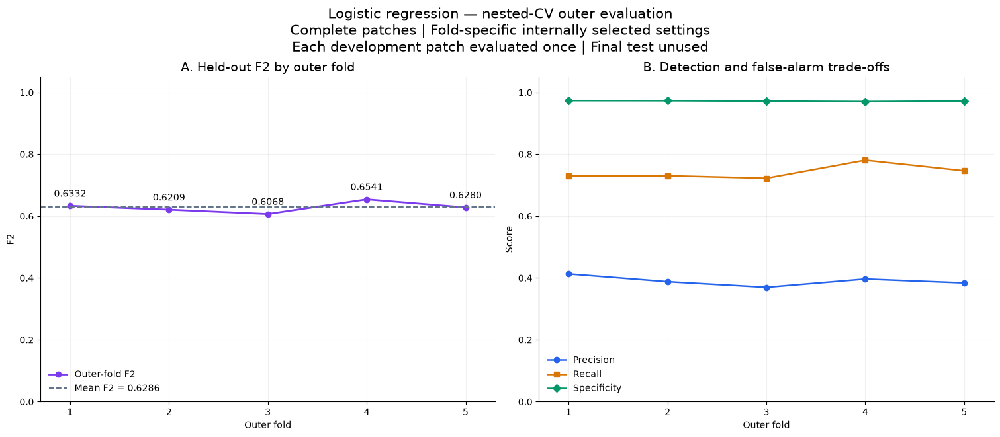

Evaluated development patches: 3039
Final-test patches used: 0


In [57]:
# Retain completed fold evaluations if this cell is rerun.
if "lr_outer_patch_evaluations" not in globals():
    lr_outer_patch_evaluations = {}

for outer_fold in nested_splits:
    number = outer_fold["outer_fold"]

    if number in lr_outer_patch_evaluations:
        print(f"Outer {number}: completed evaluation retained.")
        continue

    bundle = lr_outer_models[number]
    evaluation_ids = sorted(
        map(str, outer_fold["evaluation_ids"]),
        key=int
    )

    assert set(evaluation_ids).isdisjoint(
        map(str, outer_fold["train_ids"])
    )
    assert set(evaluation_ids).isdisjoint(map(str, test_ids))

    patch_rows = []

    for position, sample_id in enumerate(evaluation_ids, start=1):
        image_path = (
            DATA_DIR / "TrainData" / "img" / f"image_{sample_id}.h5"
        )
        mask_path = (
            DATA_DIR / "TrainData" / "mask" / f"mask_{sample_id}.h5"
        )

        with h5py.File(image_path, "r") as h5_file:
            features = h5_file["img"][:].reshape(
                -1, len(FEATURE_NAMES)
            )

        with h5py.File(mask_path, "r") as h5_file:
            labels = h5_file["mask"][:].reshape(-1)

        probabilities = bundle["probability_model"].predict_proba(
            features
        )[:, 1]

        assert np.isfinite(probabilities).all()
        assert ((probabilities >= 0) & (probabilities <= 1)).all()

        prediction = probabilities >= bundle["threshold"]
        actual = labels == 1

        tp = int(np.count_nonzero(prediction & actual))
        fp = int(np.count_nonzero(prediction & ~actual))
        fn = int(actual.sum()) - tp
        tn = len(labels) - tp - fp - fn

        epsilon = np.finfo(np.float64).eps
        clipped = np.clip(
            probabilities, epsilon, 1 - epsilon
        )

        squared_error_sum = float(
            np.square(probabilities - labels).sum()
        )
        log_loss_sum = float(
            -(
                labels * np.log(clipped)
                + (1 - labels) * np.log1p(-clipped)
            ).sum()
        )

        patch_rows.append({
            "Outer fold": number,
            "sample_id": sample_id,
            "Method": bundle["method"],
            "Threshold": bundle["threshold"],
            "Pixels": len(labels),
            "Positive pixels": int(actual.sum()),
            "Landslide coverage (%)": 100 * actual.mean(),
            "Squared error sum": squared_error_sum,
            "Log loss sum": log_loss_sum,
            "Brier score": squared_error_sum / len(labels),
            "Log loss": log_loss_sum / len(labels),
            **metrics_from_counts(tn, fp, fn, tp)
        })

        if position % 200 == 0 or position == len(evaluation_ids):
            print(
                f"Outer {number}: "
                f"{position:,}/{len(evaluation_ids):,} patches",
                flush=True
            )

    lr_outer_patch_evaluations[number] = pd.DataFrame(patch_rows)

# One out-of-fold evaluation record per development patch.
lr_oof_patch_results = pd.concat(
    [
        lr_outer_patch_evaluations[number]
        for number in sorted(lr_outer_patch_evaluations)
    ],
    ignore_index=True
)

assert lr_oof_patch_results["sample_id"].is_unique
assert set(lr_oof_patch_results["sample_id"]) == set(
    map(str, dev_ids)
)
assert set(lr_oof_patch_results["sample_id"]).isdisjoint(
    map(str, test_ids)
)

# Aggregate counts first, then calculate metrics for each fold.
outer_score_rows = []

for number, group in lr_oof_patch_results.groupby("Outer fold"):
    counts = group[["TN", "FP", "FN", "TP"]].sum()
    pixels = int(group["Pixels"].sum())

    outer_score_rows.append({
        "Outer fold": number,
        "Method": lr_outer_models[number]["method"],
        "Threshold": lr_outer_models[number]["threshold"],
        "Patches": len(group),
        **metrics_from_counts(
            int(counts["TN"]),
            int(counts["FP"]),
            int(counts["FN"]),
            int(counts["TP"])
        ),
        "Brier score": group["Squared error sum"].sum() / pixels,
        "Log loss": group["Log loss sum"].sum() / pixels
    })

lr_outer_scores = pd.DataFrame(outer_score_rows)

report_metrics = [
    "F2", "Precision", "Recall", "Specificity",
    "F1", "IoU", "Brier score", "Log loss"
]

print("\nHeld-out outer-fold performance:")
display(
    lr_outer_scores[
        ["Outer fold", "Method", "Threshold", "Patches"]
        + report_metrics
    ].round(5)
)

print("\nMean and SD across outer folds — not confidence intervals:")
display(
    lr_outer_scores[report_metrics]
    .agg(["mean", "std"])
    .T
    .round(5)
)

# --------------------------------------------------
# Visual summary of held-out performance.
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2, figsize=(15, 6.5), layout="constrained"
)

fold_numbers = lr_outer_scores["Outer fold"]

axes[0].plot(
    fold_numbers,
    lr_outer_scores["F2"],
    color="#7c3aed",
    marker="o",
    linewidth=2,
    label="Outer-fold F2"
)

mean_outer_f2 = lr_outer_scores["F2"].mean()

axes[0].axhline(
    mean_outer_f2,
    color="#64748b",
    linestyle="--",
    label=f"Mean F2 = {mean_outer_f2:.4f}"
)

for fold, score in zip(fold_numbers, lr_outer_scores["F2"]):
    axes[0].annotate(
        f"{score:.4f}",
        (fold, score),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

axes[0].set_title("A. Held-out F2 by outer fold", fontsize=14)
axes[0].set_ylabel("F2")
axes[0].legend(frameon=False, loc="lower left")

for metric, color, marker in [
    ("Precision", "#2563eb", "o"),
    ("Recall", "#d97706", "s"),
    ("Specificity", "#059669", "D")
]:
    axes[1].plot(
        fold_numbers,
        lr_outer_scores[metric],
        color=color,
        marker=marker,
        linewidth=1.8,
        label=metric
    )

axes[1].set_title("B. Detection and false-alarm trade-offs", fontsize=14)
axes[1].set_ylabel("Score")
axes[1].legend(frameon=False, loc="lower left")

for ax in axes:
    ax.set_xlabel("Outer fold")
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_xlim(0.7, 5.3)
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.18)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Logistic regression — nested-CV outer evaluation\n"
    "Complete patches | Fold-specific internally selected settings\n"
    "Each development patch evaluated once | Final test unused",
    fontsize=15
)

plt.show()

print("Evaluated development patches:", len(lr_oof_patch_results))
print("Final-test patches used: 0")

The left plot shows outer-fold F2 ranging from 0.6068 to 0.6541, with a mean of 0.62857. The right plot shows mean recall of 74.22%, precision of 39.03%, and specificity of 97.19%, highlighting substantial remaining false alarms. All 3,039 development patches were evaluated out of fold. Reported SDs are not confidence intervals, and the final test set remains unused.

Bootstrap: 500/2,000
Bootstrap: 1,000/2,000
Bootstrap: 1,500/2,000
Bootstrap: 2,000/2,000

Pooled out-of-fold estimates and percentile intervals:


,Metric,Pooled estimate,Lower 95%,Upper 95%
0,F2,0.62907,0.61467,0.64250
1,Precision,0.39039,0.37068,0.41082
2,Recall,0.74256,0.73042,0.75399
3,Specificity,0.97192,0.97009,0.97372
4,F1,0.51174,0.49338,0.52988
5,IoU,0.34386,0.32747,0.36043


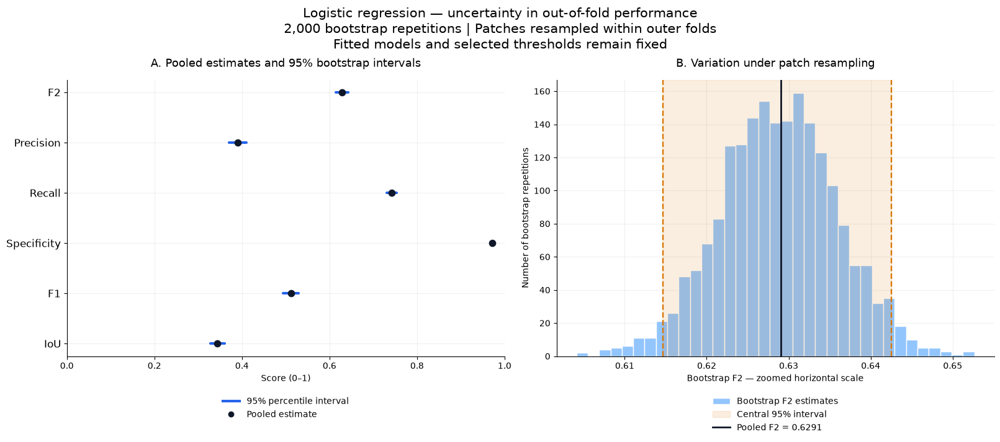

In [58]:
#Patch-level Bootstrap
N_BOOTSTRAPS = 2000
BOOTSTRAP_SEED = 43

bootstrap_rng = np.random.default_rng(BOOTSTRAP_SEED)

count_columns = ["TN", "FP", "FN", "TP"]

# Keep each outer fold's sample size fixed during resampling.
fold_count_arrays = [
    group[count_columns].to_numpy(dtype=np.int64)
    for _, group in lr_oof_patch_results.groupby("Outer fold")
]

ci_metrics = [
    "F2", "Precision", "Recall",
    "Specificity", "F1", "IoU"
]

# Point estimates: aggregate out-of-fold confusion counts.
pooled_counts = (
    lr_oof_patch_results[count_columns]
    .sum()
    .to_numpy(dtype=np.int64)
)

lr_pooled_metrics = metrics_from_counts(*pooled_counts)

bootstrap_values = np.empty(
    (N_BOOTSTRAPS, len(ci_metrics)),
    dtype=float
)

for iteration in range(N_BOOTSTRAPS):
    resampled_counts = np.zeros(4, dtype=np.int64)

    for fold_counts in fold_count_arrays:
        selected_rows = bootstrap_rng.integers(
            low=0,
            high=len(fold_counts),
            size=len(fold_counts)
        )

        resampled_counts += fold_counts[selected_rows].sum(axis=0)

    scores = metrics_from_counts(*resampled_counts)

    bootstrap_values[iteration] = [
        scores[metric] for metric in ci_metrics
    ]

    if (iteration + 1) % 500 == 0:
        print(
            f"Bootstrap: {iteration + 1:,}/{N_BOOTSTRAPS:,}",
            flush=True
        )

lr_bootstrap_scores = pd.DataFrame(
    bootstrap_values,
    columns=ci_metrics
)

assert np.isfinite(bootstrap_values).all()

lr_bootstrap_ci = pd.DataFrame({
    "Metric": ci_metrics,
    "Pooled estimate": [
        lr_pooled_metrics[metric] for metric in ci_metrics
    ],
    "Lower 95%": np.percentile(
        bootstrap_values, 2.5, axis=0
    ),
    "Upper 95%": np.percentile(
        bootstrap_values, 97.5, axis=0
    )
})

print("\nPooled out-of-fold estimates and percentile intervals:")
display(lr_bootstrap_ci.round(5))

# --------------------------------------------------
# A. Metric estimates and confidence intervals
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    layout="constrained"
)

for row, result in lr_bootstrap_ci.iterrows():
    axes[0].plot(
        [result["Lower 95%"], result["Upper 95%"]],
        [row, row],
        color="#2563eb",
        linewidth=3,
        solid_capstyle="round"
    )

    axes[0].scatter(
        result["Pooled estimate"],
        row,
        color="#0f172a",
        s=55,
        zorder=4
    )

axes[0].set_yticks(range(len(ci_metrics)))
axes[0].set_yticklabels(ci_metrics, fontsize=12)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 1)
axes[0].set_xlabel("Score (0–1)")
axes[0].set_title(
    "A. Pooled estimates and 95% bootstrap intervals",
    fontsize=13,
    pad=15
)

# --------------------------------------------------
# B. Bootstrap distribution of F2
# --------------------------------------------------
f2_interval = lr_bootstrap_ci.loc[
    lr_bootstrap_ci["Metric"] == "F2"
].iloc[0]

axes[1].hist(
    lr_bootstrap_scores["F2"],
    bins=35,
    color="#93c5fd",
    edgecolor="white",
    label="Bootstrap F2 estimates"
)

axes[1].axvspan(
    f2_interval["Lower 95%"],
    f2_interval["Upper 95%"],
    color="#d97706",
    alpha=0.12,
    label="Central 95% interval"
)

axes[1].axvline(
    lr_pooled_metrics["F2"],
    color="#0f172a",
    linewidth=2,
    label=f"Pooled F2 = {lr_pooled_metrics['F2']:.4f}"
)

for boundary in ["Lower 95%", "Upper 95%"]:
    axes[1].axvline(
        f2_interval[boundary],
        color="#d97706",
        linestyle="--",
        linewidth=1.7
    )

axes[1].set_xlabel("Bootstrap F2 — zoomed horizontal scale")
axes[1].set_ylabel("Number of bootstrap repetitions")
axes[1].set_title(
    "B. Variation under patch resampling",
    fontsize=13,
    pad=15
)

axes[1].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    frameon=False,
    fontsize=10
)

axes[0].legend(
    handles=[
        Line2D(
            [0], [0], color="#2563eb", linewidth=3,
            label="95% percentile interval"
        ),
        Line2D(
            [0], [0], marker="o", linestyle="",
            color="#0f172a", label="Pooled estimate"
        )
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    frameon=False,
    fontsize=10
)

for ax in axes:
    ax.grid(alpha=0.18)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Logistic regression — uncertainty in out-of-fold performance\n"
    f"{N_BOOTSTRAPS:,} bootstrap repetitions | "
    "Patches resampled within outer folds\n"
    "Fitted models and selected thresholds remain fixed",
    fontsize=15
)

plt.show()

The left plot reports pooled out-of-fold metrics with 95% patch-bootstrap intervals. Pooled F2 is 0.62907, with an interval of 0.61467–0.64250. The right histogram shows F2 variation across 2,000 patch-resampling repetitions. These intervals describe uncertainty conditional on the fitted models and do not establish geographic generalisation.

Performance grouped by reference landslide coverage:


,Coverage group,Patches,Positive pixels,Precision,Recall,F2,IoU,False-positive rate (%)
0,No landslide,1254,0,0.00000,NaN,0.00000,0.00000,2.05086
1,>0–1%,610,40609,0.10784,0.62220,0.31844,0.10122,2.09997
2,>1–5%,700,298158,0.35867,0.67832,0.57571,0.30654,3.23732
3,>5–15%,393,543391,0.58398,0.75652,0.71431,0.49159,4.96735
4,>15–100%,82,295251,0.74571,0.79830,0.78720,0.62749,7.66735



Patches without reference landslide: 1254
Such patches with any false-positive pixel: 1014
Median false-positive area (%): 0.2686


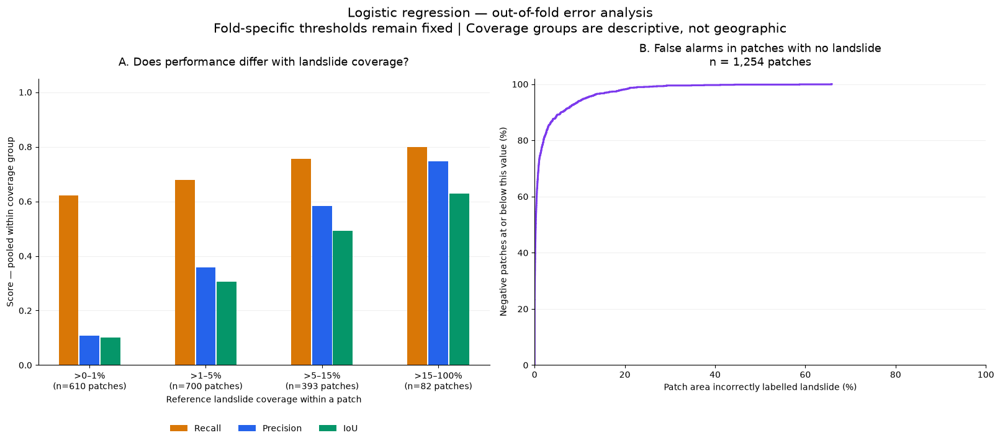

In [59]:
#Coverage-stratified Error Analysis
# Work on a copy; preserve the original out-of-fold results.
lr_coverage_analysis = lr_oof_patch_results.copy()

coverage_labels = [
    "No landslide",
    ">0–1%",
    ">1–5%",
    ">5–15%",
    ">15–100%"
]

lr_coverage_analysis["Coverage group"] = pd.cut(
    lr_coverage_analysis["Landslide coverage (%)"],
    bins=[-0.001, 0, 1, 5, 15, 100],
    labels=coverage_labels,
    include_lowest=True,
    right=True
)

assert lr_coverage_analysis["Coverage group"].notna().all()

coverage_rows = []

for label in coverage_labels:
    group = lr_coverage_analysis.loc[
        lr_coverage_analysis["Coverage group"] == label
    ]

    if group.empty:
        continue

    counts = group[["TN", "FP", "FN", "TP"]].sum()
    scores = metrics_from_counts(
        int(counts["TN"]),
        int(counts["FP"]),
        int(counts["FN"]),
        int(counts["TP"])
    )

    negative_pixels = int(counts["TN"] + counts["FP"])

    coverage_rows.append({
        "Coverage group": label,
        "Patches": len(group),
        "Pixels": int(group["Pixels"].sum()),
        "Positive pixels": int(group["Positive pixels"].sum()),
        **scores,
        "False-positive rate (%)": (
            100 * counts["FP"] / negative_pixels
            if negative_pixels > 0 else np.nan
        )
    })

lr_coverage_summary = pd.DataFrame(coverage_rows)

print("Performance grouped by reference landslide coverage:")
display(
    lr_coverage_summary[
        [
            "Coverage group", "Patches", "Positive pixels",
            "Precision", "Recall", "F2", "IoU",
            "False-positive rate (%)"
        ]
    ].round(5)
)

# Images with no reference landslide: inspect false-positive area.
negative_patches = lr_coverage_analysis.loc[
    lr_coverage_analysis["Positive pixels"] == 0
].copy()

negative_patches["False-positive area (%)"] = (
    100 * negative_patches["FP"] / negative_patches["Pixels"]
)

print("\nPatches without reference landslide:", len(negative_patches))
print(
    "Such patches with any false-positive pixel:",
    int((negative_patches["FP"] > 0).sum())
)
print(
    "Median false-positive area (%):",
    round(negative_patches["False-positive area (%)"].median(), 4)
)

# --------------------------------------------------
# Visual diagnostics
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    layout="constrained"
)

positive_groups = lr_coverage_summary.loc[
    lr_coverage_summary["Coverage group"] != "No landslide"
].copy()

x_positions = np.arange(len(positive_groups))

for offset, metric, color in [
    (-0.18, "Recall", "#d97706"),
    (0.00, "Precision", "#2563eb"),
    (0.18, "IoU", "#059669")
]:
    axes[0].bar(
        x_positions + offset,
        positive_groups[metric],
        width=0.17,
        color=color,
        label=metric
    )

axes[0].set_xticks(x_positions)
axes[0].set_xticklabels([
    f"{row['Coverage group']}\n(n={int(row['Patches']):,} patches)"
    for _, row in positive_groups.iterrows()
])

axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Score — pooled within coverage group")
axes[0].set_xlabel("Reference landslide coverage within a patch")
axes[0].set_title(
    "A. Does performance differ with landslide coverage?",
    fontsize=13,
    pad=15
)
axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    frameon=False
)

false_area = np.sort(
    negative_patches["False-positive area (%)"].to_numpy()
)
cumulative = 100 * np.arange(1, len(false_area) + 1) / len(false_area)

axes[1].step(
    np.r_[0, false_area],
    np.r_[0, cumulative],
    where="post",
    color="#7c3aed",
    linewidth=2.2
)

axes[1].set_xlim(0, 100)
axes[1].set_ylim(0, 102)
axes[1].set_xlabel("Patch area incorrectly labelled landslide (%)")
axes[1].set_ylabel("Negative patches at or below this value (%)")
axes[1].set_title(
    f"B. False alarms in patches with no landslide\n"
    f"n = {len(negative_patches):,} patches",
    fontsize=13,
    pad=15
)

for ax in axes:
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.18)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Logistic regression — out-of-fold error analysis\n"
    "Fold-specific thresholds remain fixed | "
    "Coverage groups are descriptive, not geographic",
    fontsize=15
)

plt.show()

The left plot shows markedly poorer precision and IoU in low-coverage patches: precision is 10.78% for coverage up to 1%, versus 74.57% above 15%. This pattern partly reflects differing positive prevalence and does not establish an object-size effect. The right plot shows that 80.9% of negative patches contain some false-positive pixels, although median false-positive area is only 0.2686%; a smaller number have much larger errors.

,Selection,sample_id,Outer fold,Threshold,Landslide coverage (%),FP,FN,TP,IoU
172,Positive patch near median IoU,1232,1,0.10,12.902832,256,1269,845,0.35654
144,Low-coverage patch with lowest IoU,1037,1,0.10,0.085449,2218,14,0,0.00000
1770,Negative patch with most false positives,3460,3,0.09,0.000000,10791,0,0,0.00000


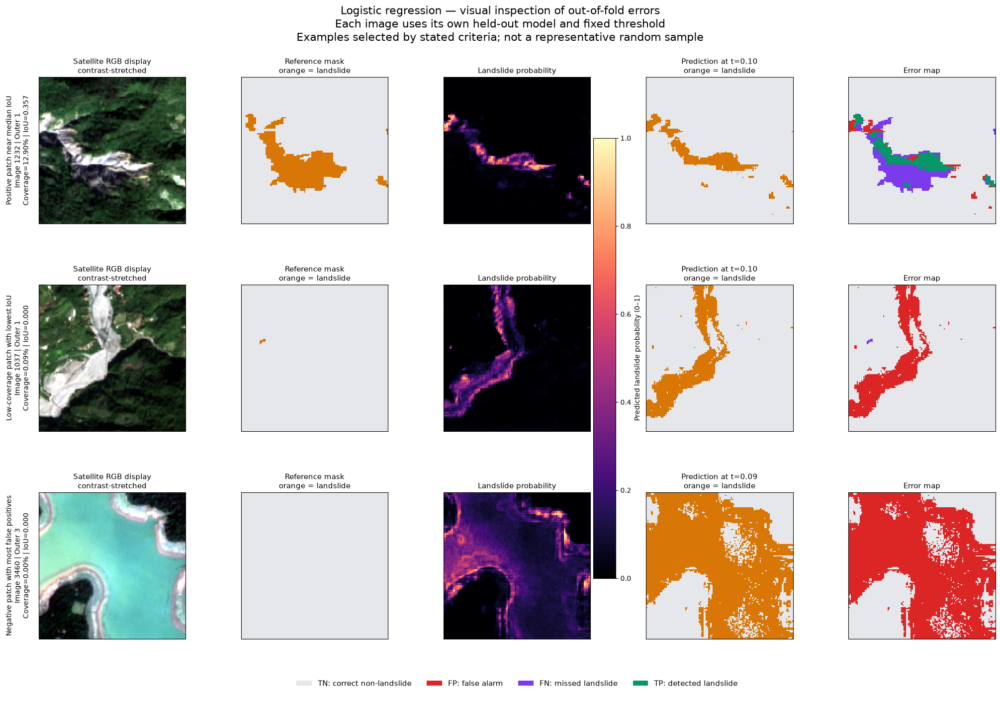

In [60]:
#Visual Error Analysis
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# --------------------------------------------------
# 1. Select examples using explicit criteria.
# --------------------------------------------------
positive_cases = lr_oof_patch_results.loc[
    lr_oof_patch_results["Positive pixels"] > 0
]

positive_median_iou = positive_cases["IoU"].median()

typical_index = (
    positive_cases["IoU"] - positive_median_iou
).abs().idxmin()

low_coverage_cases = positive_cases.loc[
    positive_cases["Landslide coverage (%)"] <= 1
]

difficult_index = (
    low_coverage_cases.sort_values(
        ["IoU", "sample_id"],
        ascending=[True, True]
    ).index[0]
)

negative_cases = lr_oof_patch_results.loc[
    lr_oof_patch_results["Positive pixels"] == 0
]

false_alarm_index = negative_cases["FP"].idxmax()

example_specs = [
    ("Positive patch near median IoU", typical_index),
    ("Low-coverage patch with lowest IoU", difficult_index),
    ("Negative patch with most false positives", false_alarm_index)
]

example_rows = []

for description, index in example_specs:
    row = lr_oof_patch_results.loc[index].copy()
    row["Selection"] = description
    example_rows.append(row)

lr_visual_examples = pd.DataFrame(example_rows)

display(
    lr_visual_examples[
        [
            "Selection", "sample_id", "Outer fold",
            "Threshold", "Landslide coverage (%)",
            "FP", "FN", "TP", "IoU"
        ]
    ]
)

# --------------------------------------------------
# 2. Define consistent display colours.
# --------------------------------------------------
binary_cmap = ListedColormap(["#e5e7eb", "#d97706"])

error_colors = [
    "#e5e7eb",  # TN
    "#dc2626",  # FP
    "#7c3aed",  # FN
    "#059669"   # TP
]

error_cmap = ListedColormap(error_colors)
error_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    error_cmap.N
)

fig = plt.figure(
    figsize=(20, 14),
    layout="constrained"
)

grid = fig.add_gridspec(
    4, 5,
    height_ratios=[1, 1, 1, 0.12]
)

probability_axes = []

for row_number, (_, case) in enumerate(
    lr_visual_examples.iterrows()
):
    sample_id = str(case["sample_id"])
    outer_number = int(case["Outer fold"])
    threshold = float(case["Threshold"])

    image_path = (
        DATA_DIR / "TrainData" / "img" / f"image_{sample_id}.h5"
    )
    mask_path = (
        DATA_DIR / "TrainData" / "mask" / f"mask_{sample_id}.h5"
    )

    with h5py.File(image_path, "r") as h5_file:
        patch = h5_file["img"][:]

    with h5py.File(mask_path, "r") as h5_file:
        reference = h5_file["mask"][:]

    model = lr_outer_models[outer_number]["probability_model"]

    probability = model.predict_proba(
        patch.reshape(-1, len(FEATURE_NAMES))
    )[:, 1].reshape(reference.shape)

    prediction = probability >= threshold

    # Confirm predictions reproduce the stored evaluation.
    assert int(
        np.count_nonzero(prediction & (reference == 1))
    ) == int(case["TP"])

    assert int(
        np.count_nonzero(prediction & (reference == 0))
    ) == int(case["FP"])

    # Contrast stretch for display only.
    rgb = patch[:, :, [3, 2, 1]].astype(float)
    low = np.percentile(rgb, 2, axis=(0, 1))
    high = np.percentile(rgb, 98, axis=(0, 1))

    rgb_display = np.clip(
        (rgb - low) / np.maximum(high - low, 1e-8),
        0, 1
    )

    # Error categories: 0=TN, 1=FP, 2=FN, 3=TP.
    error_map = np.zeros(reference.shape, dtype=np.uint8)
    error_map[prediction & (reference == 0)] = 1
    error_map[~prediction & (reference == 1)] = 2
    error_map[prediction & (reference == 1)] = 3

    axes = [
        fig.add_subplot(grid[row_number, column])
        for column in range(5)
    ]

    axes[0].imshow(rgb_display)
    axes[1].imshow(
        reference, cmap=binary_cmap,
        vmin=0, vmax=1, interpolation="nearest"
    )

    probability_image = axes[2].imshow(
        probability, cmap="magma",
        vmin=0, vmax=1, interpolation="nearest"
    )
    probability_axes.append(axes[2])

    axes[3].imshow(
        prediction, cmap=binary_cmap,
        vmin=0, vmax=1, interpolation="nearest"
    )
    axes[4].imshow(
        error_map, cmap=error_cmap,
        norm=error_norm, interpolation="nearest"
    )

    titles = [
        "Satellite RGB display\ncontrast-stretched",
        "Reference mask\norange = landslide",
        "Landslide probability",
        f"Prediction at t={threshold:.2f}\norange = landslide",
        "Error map"
    ]

    for ax, title in zip(axes, titles):
        ax.set_title(title, fontsize=11)
        ax.set_xticks([])
        ax.set_yticks([])

    axes[0].set_ylabel(
        f"{case['Selection']}\n"
        f"Image {sample_id} | Outer {outer_number}\n"
        f"Coverage={case['Landslide coverage (%)']:.2f}% | "
        f"IoU={case['IoU']:.3f}",
        fontsize=10,
        labelpad=12
    )

colorbar = fig.colorbar(
    probability_image,
    ax=probability_axes,
    shrink=0.8,
    pad=0.02
)
colorbar.set_label("Predicted landslide probability (0–1)")

legend_ax = fig.add_subplot(grid[3, :])
legend_ax.set_axis_off()

legend_ax.legend(
    handles=[
        Patch(facecolor=error_colors[0], label="TN: correct non-landslide"),
        Patch(facecolor=error_colors[1], label="FP: false alarm"),
        Patch(facecolor=error_colors[2], label="FN: missed landslide"),
        Patch(facecolor=error_colors[3], label="TP: detected landslide")
    ],
    loc="center",
    ncol=4,
    frameon=False,
    fontsize=11
)

fig.suptitle(
    "Logistic regression — visual inspection of out-of-fold errors\n"
    "Each image uses its own held-out model and fixed threshold\n"
    "Examples selected by stated criteria; not a representative random sample",
    fontsize=16
)

plt.show()

The first row shows partial overlap with substantial missed reference areas. The second misses all 14 labelled landslide pixels while generating 2,218 false-positive pixels. The third incorrectly labels 65.86% of a reference-negative patch as landslide. These deliberately selected examples reveal failure patterns, not their overall frequency or physical causes.

Outer 1: ROC AUC=0.9600, AP=0.5859
Outer 2: ROC AUC=0.9602, AP=0.5477
Outer 3: ROC AUC=0.9597, AP=0.5549
Outer 4: ROC AUC=0.9696, AP=0.5913
Outer 5: ROC AUC=0.9663, AP=0.5475


,Outer fold,ROC AUC,Average precision,Positive prevalence,Pixels
0,1,0.95997,0.58588,0.02514,9961472
1,2,0.96018,0.54768,0.02295,9961472
2,3,0.95975,0.55487,0.02258,9961472
3,4,0.96962,0.59129,0.02454,9961472
4,5,0.96629,0.54754,0.02302,9945088



Mean and SD across outer folds:


,mean,std
ROC AUC,0.96316,0.00453
Average precision,0.56545,0.02141


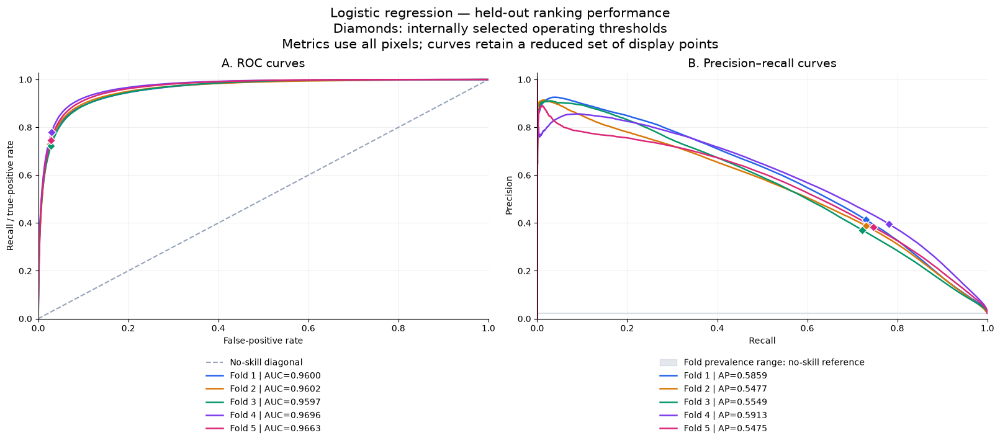

Final-test patches used: 0


In [62]:
#ROC Curve · Precision–Recall Curve · Average Precision
from sklearn.metrics import roc_curve, precision_recall_curve, auc

# Preserve completed calculations if the cell is rerun.
if "lr_outer_ranking" not in globals():
    lr_outer_ranking = {}

fold_colors = {
    1: "#2563eb",
    2: "#d97706",
    3: "#059669",
    4: "#7c3aed",
    5: "#db2777"
}


def curve_display_indices(length):
    """Reduce stored plotting points; metric calculations stay exact."""
    linear_indices = np.linspace(
        0, length - 1, min(length, 1500)
    ).astype(int)

    edge_indices = (
        np.geomspace(1, length, min(length, 800)) - 1
    ).astype(int)

    return np.unique(np.r_[
        linear_indices,
        edge_indices,
        length - 1 - edge_indices
    ])


for outer_fold in nested_splits:
    number = outer_fold["outer_fold"]

    if number in lr_outer_ranking:
        print(f"Outer {number}: completed curves retained.")
        continue

    bundle = lr_outer_models[number]
    patch_ids = sorted(
        map(str, outer_fold["evaluation_ids"]),
        key=int
    )

    total = int(
        audit_by_id.loc[patch_ids, "total_pixels"].sum()
    )

    y_fold = np.empty(total, dtype=np.uint8)
    p_fold = np.empty(total, dtype=np.float64)

    offset = 0

    for sample_id in patch_ids:
        image_path = (
            DATA_DIR / "TrainData" / "img" / f"image_{sample_id}.h5"
        )
        mask_path = (
            DATA_DIR / "TrainData" / "mask" / f"mask_{sample_id}.h5"
        )

        with h5py.File(image_path, "r") as h5_file:
            features = h5_file["img"][:].reshape(
                -1, len(FEATURE_NAMES)
            )

        with h5py.File(mask_path, "r") as h5_file:
            labels = h5_file["mask"][:].reshape(-1)

        stop = offset + len(labels)

        y_fold[offset:stop] = labels
        p_fold[offset:stop] = (
            bundle["probability_model"]
            .predict_proba(features)[:, 1]
        )

        offset = stop

    assert offset == total
    assert np.isfinite(p_fold).all()

    # Exact ROC AUC; retain only display points.
    fpr, tpr, roc_thresholds = roc_curve(
        y_fold, p_fold, drop_intermediate=True
    )
    roc_auc = auc(fpr, tpr)

    roc_indices = curve_display_indices(len(fpr))
    roc_display = (fpr[roc_indices], tpr[roc_indices])

    del fpr, tpr, roc_thresholds

    # Exact non-interpolated average precision.
    precision, recall, pr_thresholds = precision_recall_curve(
        y_fold, p_fold
    )

    average_precision = float(
        -np.sum(np.diff(recall) * precision[:-1])
    )

    pr_indices = curve_display_indices(len(recall))
    pr_display = (
        recall[pr_indices],
        precision[pr_indices]
    )

    # Scores at the already selected threshold: no new selection.
    selected_prediction = p_fold >= bundle["threshold"]
    actual_positive = y_fold == 1

    tp = int(np.count_nonzero(
        selected_prediction & actual_positive
    ))
    fp = int(np.count_nonzero(
        selected_prediction & ~actual_positive
    ))
    fn = int(actual_positive.sum()) - tp
    tn = total - tp - fp - fn

    # Verify consistency with the previous outer evaluation.
    previous = lr_outer_scores.loc[
        lr_outer_scores["Outer fold"] == number
    ].iloc[0]

    for name, value in zip(
        ["TN", "FP", "FN", "TP"],
        [tn, fp, fn, tp]
    ):
        assert int(previous[name]) == value

    lr_outer_ranking[number] = {
        "ROC AUC": float(roc_auc),
        "AP": average_precision,
        "Prevalence": float(actual_positive.mean()),
        "Pixels": total,
        "roc_display": roc_display,
        "pr_display": pr_display
    }

    print(
        f"Outer {number}: "
        f"ROC AUC={roc_auc:.4f}, AP={average_precision:.4f}",
        flush=True
    )

    del (
        y_fold, p_fold, precision, recall, pr_thresholds,
        selected_prediction, actual_positive
    )

ranking_summary = pd.DataFrame([
    {
        "Outer fold": number,
        "ROC AUC": result["ROC AUC"],
        "Average precision": result["AP"],
        "Positive prevalence": result["Prevalence"],
        "Pixels": result["Pixels"]
    }
    for number, result in sorted(lr_outer_ranking.items())
])

display(ranking_summary.round(5))

print("\nMean and SD across outer folds:")
display(
    ranking_summary[
        ["ROC AUC", "Average precision"]
    ].agg(["mean", "std"]).T.round(5)
)

# --------------------------------------------------
# Plot curves with selected operating points.
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    layout="constrained"
)

axes[0].plot(
    [0, 1], [0, 1],
    color="#94a3b8",
    linestyle="--",
    label="No-skill diagonal"
)

prevalences = ranking_summary["Positive prevalence"]

axes[1].axhspan(
    prevalences.min(),
    prevalences.max(),
    color="#94a3b8",
    alpha=0.25,
    label="Fold prevalence range: no-skill reference"
)

for number, result in sorted(lr_outer_ranking.items()):
    color = fold_colors[number]

    axes[0].plot(
        *result["roc_display"],
        color=color,
        linewidth=1.8,
        label=f"Fold {number} | AUC={result['ROC AUC']:.4f}"
    )

    recall_display, precision_display = result["pr_display"]

    axes[1].plot(
        recall_display,
        precision_display,
        color=color,
        linewidth=1.8,
        label=f"Fold {number} | AP={result['AP']:.4f}"
    )

    operating = lr_outer_scores.loc[
        lr_outer_scores["Outer fold"] == number
    ].iloc[0]

    axes[0].scatter(
        1 - operating["Specificity"],
        operating["Recall"],
        color=color,
        marker="D",
        edgecolor="white",
        s=50,
        zorder=5
    )

    axes[1].scatter(
        operating["Recall"],
        operating["Precision"],
        color=color,
        marker="D",
        edgecolor="white",
        s=50,
        zorder=5
    )

axes[0].set_title("A. ROC curves", fontsize=14)
axes[0].set_xlabel("False-positive rate")
axes[0].set_ylabel("Recall / true-positive rate")

axes[1].set_title("B. Precision–recall curves", fontsize=14)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.03)
    ax.grid(alpha=0.18)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.13),
        frameon=False,
        fontsize=10
    )

fig.suptitle(
    "Logistic regression — held-out ranking performance\n"
    "Diamonds: internally selected operating thresholds\n"
    "Metrics use all pixels; curves retain a reduced set of display points",
    fontsize=15
)

plt.show()

print("Final-test patches used: 0")

The ROC plot shows strong held-out ranking performance, with mean AUC=0.96316. The PR plot reveals the operational trade-off: at selected thresholds, recall is approximately 72–78% while precision is 37–41%. Mean AP=0.56545 substantially exceeds the 2.3–2.5% prevalence reference, but false alarms remain significant. These are five-fold outer results; the final test set is unused.

Learning curve 1/15 | Pixels=64, inner=1
Learning curve 2/15 | Pixels=64, inner=2
Learning curve 3/15 | Pixels=64, inner=3
Learning curve 4/15 | Pixels=128, inner=1
Learning curve 5/15 | Pixels=128, inner=2
Learning curve 6/15 | Pixels=128, inner=3
Learning curve 7/15 | Pixels=256, inner=1
Learning curve 8/15 | Pixels=256, inner=2
Learning curve 9/15 | Pixels=256, inner=3
Learning curve 10/15 | Pixels=512, inner=1
Learning curve 11/15 | Pixels=512, inner=2
Learning curve 12/15 | Pixels=512, inner=3
Learning curve 13/15 | Pixels=1024, inner=1
Learning curve 14/15 | Pixels=1024, inner=2
Learning curve 15/15 | Pixels=1024, inner=3


,Pixels per patch,Mean_training_pixels,Training_F2_mean,Training_F2_SD,Validation_F2_mean,Validation_F2_SD,Median_fit_seconds
0,64,1.037227e+05,0.63032,0.01524,0.62650,0.02320,0.10197
1,128,2.074453e+05,0.63152,0.01409,0.62700,0.02340,0.27844
2,256,4.148907e+05,0.63477,0.01112,0.62681,0.02367,0.63518
3,512,8.297813e+05,0.63394,0.01037,0.62675,0.02364,1.33251
4,1024,1.659563e+06,0.63005,0.01195,0.62635,0.02394,2.72187


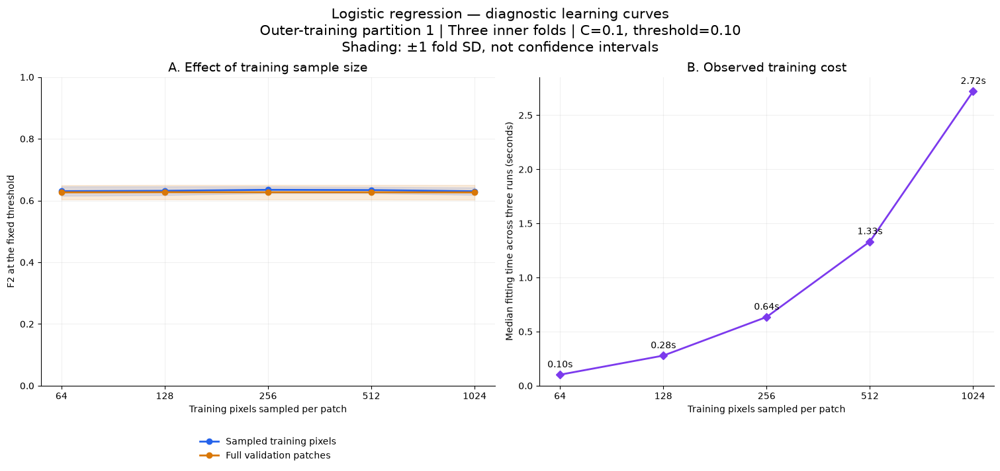

In [63]:
#Learning Curve
LEARNING_SAMPLE_SIZES = [64, 128, 256, 512, 1024]

# Fixed settings for this diagnostic.
LEARNING_C = float(lr_search_by_outer[1]["selected"]["C"])
LEARNING_THRESHOLD = float(
    lr_calibration_by_outer[1]["selected"]["Threshold"]
)

learning_rows = []
total_runs = len(LEARNING_SAMPLE_SIZES) * 3
run_number = 0

for sample_size in LEARNING_SAMPLE_SIZES:
    for inner_number, split in enumerate(
        nested_splits[0]["inner_splits"],
        start=1
    ):
        training_ids = set(map(str, split["train_ids"]))
        validation_ids = set(map(str, split["validation_ids"]))

        assert training_ids.isdisjoint(validation_ids)
        assert (
            training_ids | validation_ids
        ).isdisjoint(map(str, test_ids))

        X_current, y_current = get_sampled_pixels(
            training_ids, sample_size
        )

        model = clone(lr_pilot).set_params(
            classifier__C=LEARNING_C,
            classifier__class_weight=None
        )

        start = perf_counter()

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            model.fit(X_current, y_current)

        fit_seconds = perf_counter() - start

        for warning in caught:
            print(f"{warning.category.__name__}: {warning.message}")

        if any(
            issubclass(w.category, ConvergenceWarning)
            for w in caught
        ):
            raise RuntimeError("Inspect convergence before continuing.")

        # Training score at the same fixed threshold.
        positive_column = int(
            np.flatnonzero(model.classes_ == 1)[0]
        )

        training_prediction = (
            model.predict_proba(X_current)[:, positive_column]
            >= LEARNING_THRESHOLD
        )

        actual_positive = y_current == 1

        tp = int(np.count_nonzero(
            training_prediction & actual_positive
        ))
        fp = int(np.count_nonzero(
            training_prediction & ~actual_positive
        ))
        fn = int(actual_positive.sum()) - tp
        tn = len(y_current) - tp - fp - fn

        training_scores = metrics_from_counts(tn, fp, fn, tp)

        validation_scores = evaluate_full_patches_at_thresholds(
            model,
            validation_ids,
            [LEARNING_THRESHOLD]
        ).iloc[0]

        learning_rows.append({
            "Pixels per patch": sample_size,
            "Inner fold": inner_number,
            "Training pixels": len(y_current),
            "Training F2": training_scores["F2"],
            "Validation F2": validation_scores["F2"],
            "Fit seconds": fit_seconds
        })

        run_number += 1

        print(
            f"Learning curve {run_number}/{total_runs} | "
            f"Pixels={sample_size}, inner={inner_number}",
            flush=True
        )

        del X_current, y_current, model, training_prediction

lr_learning_results = pd.DataFrame(learning_rows)

lr_learning_summary = (
    lr_learning_results
    .groupby("Pixels per patch", as_index=False)
    .agg(
        Mean_training_pixels=("Training pixels", "mean"),
        Training_F2_mean=("Training F2", "mean"),
        Training_F2_SD=("Training F2", "std"),
        Validation_F2_mean=("Validation F2", "mean"),
        Validation_F2_SD=("Validation F2", "std"),
        Median_fit_seconds=("Fit seconds", "median")
    )
)

display(lr_learning_summary.round(5))

# --------------------------------------------------
# Learning and computational-cost curves.
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2, figsize=(15, 7), layout="constrained"
)

x = lr_learning_summary["Pixels per patch"].to_numpy()

for prefix, label, color in [
    ("Training", "Sampled training pixels", "#2563eb"),
    ("Validation", "Full validation patches", "#d97706")
]:
    mean = lr_learning_summary[f"{prefix}_F2_mean"].to_numpy()
    sd = lr_learning_summary[f"{prefix}_F2_SD"].to_numpy()

    axes[0].plot(
        x, mean,
        marker="o",
        color=color,
        linewidth=2,
        label=label
    )

    axes[0].fill_between(
        x,
        np.clip(mean - sd, 0, 1),
        np.clip(mean + sd, 0, 1),
        color=color,
        alpha=0.14
    )

axes[0].set_title("A. Effect of training sample size", fontsize=14)
axes[0].set_ylabel("F2 at the fixed threshold")
axes[0].set_ylim(0, 1)
axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.14),
    frameon=False
)

times = lr_learning_summary["Median_fit_seconds"].to_numpy()

axes[1].plot(
    x, times,
    color="#7c3aed",
    marker="D",
    linewidth=2
)

for size, seconds in zip(x, times):
    axes[1].annotate(
        f"{seconds:.2f}s",
        (size, seconds),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

axes[1].set_title("B. Observed training cost", fontsize=14)
axes[1].set_ylabel("Median fitting time across three runs (seconds)")
axes[1].set_ylim(bottom=0)
axes[1].margins(y=0.2)

for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(LEARNING_SAMPLE_SIZES)
    ax.set_xticklabels([str(v) for v in LEARNING_SAMPLE_SIZES])
    ax.set_xlabel("Training pixels sampled per patch")
    ax.grid(alpha=0.18)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Logistic regression — diagnostic learning curves\n"
    f"Outer-training partition 1 | Three inner folds | "
    f"C={LEARNING_C:g}, threshold={LEARNING_THRESHOLD:.2f}\n"
    "Shading: ±1 fold SD, not confidence intervals",
    fontsize=15
)

plt.show()

The left plot shows nearly unchanged validation F2 across 64–1,024 pixels per patch, ranging from 0.62635 to 0.62700. The right plot shows increasing fitting time without a clear aggregate-performance gain. This diagnostic concerns denser sampling of existing patches, not the value of new geographic data.

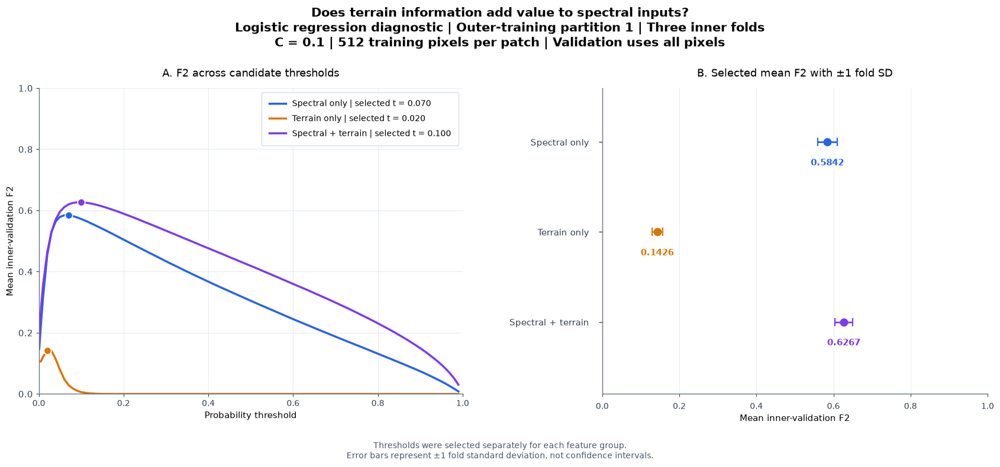

In [67]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

group_order = [
    "Spectral only",
    "Terrain only",
    "Spectral + terrain",
]

group_colors = {
    "Spectral only": "#2563EB",
    "Terrain only": "#D97706",
    "Spectral + terrain": "#7C3AED",
}

best_by_group = (
    lr_ablation_best
    .set_index("Feature group")
    .loc[group_order]
)

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
}):
    fig, (ax_left, ax_right) = plt.subplots(
        1,
        2,
        figsize=(17, 8),
        gridspec_kw={"width_ratios": [1.1, 1]},
        layout="constrained",
    )

    fig.get_layout_engine().set(
        w_pad=0.15,
        h_pad=0.15,
        wspace=0.08,
    )

    fig.suptitle(
        "Does terrain information add value to spectral inputs?\n"
        "Logistic regression diagnostic | Outer-training partition 1 | "
        "Three inner folds\n"
        "C = 0.1 | 512 training pixels per patch | "
        "Validation uses all pixels",
        fontsize=15,
        fontweight="bold",
    )

    # Panel A: threshold sensitivity.
    for group in group_order:
        curve = (
            lr_ablation_summary.loc[
                lr_ablation_summary["Feature group"].eq(group)
            ]
            .sort_values("Threshold")
        )

        best = best_by_group.loc[group]

        ax_left.plot(
            curve["Threshold"],
            curve["Mean_F2"],
            color=group_colors[group],
            linewidth=2.5,
            label=(
                f"{group} | selected t = "
                f"{best['Threshold']:.3f}"
            ),
        )

        ax_left.scatter(
            best["Threshold"],
            best["Mean_F2"],
            s=80,
            color=group_colors[group],
            edgecolor="white",
            linewidth=1.2,
            zorder=5,
        )

    ax_left.set_title(
        "A. F2 across candidate thresholds",
        pad=14,
    )
    ax_left.set(
        xlabel="Probability threshold",
        ylabel="Mean inner-validation F2",
        xlim=(0, 1),
        ylim=(0, 1),
    )

    ax_left.xaxis.set_major_locator(MultipleLocator(0.2))
    ax_left.yaxis.set_major_locator(MultipleLocator(0.2))
    ax_left.grid(
        True,
        color="#E2E8F0",
        linewidth=0.8,
        alpha=0.8,
    )
    ax_left.set_axisbelow(True)

    ax_left.legend(
        loc="upper right",
        frameon=True,
        facecolor="white",
        edgecolor="#CBD5E1",
        fontsize=10,
        borderpad=0.9,
        labelspacing=0.8,
    )

    # Panel B: selected scores and fold standard deviation.
    y_positions = np.arange(len(group_order))

    for y_position, group in zip(y_positions, group_order):
        best = best_by_group.loc[group]
        mean_f2 = float(best["Mean_F2"])
        sd_f2 = float(best["SD_F2"])

        ax_right.errorbar(
            mean_f2,
            y_position,
            xerr=sd_f2,
            fmt="o",
            markersize=9,
            color=group_colors[group],
            ecolor=group_colors[group],
            elinewidth=2,
            capsize=5,
            capthick=1.5,
            zorder=4,
        )

        ax_right.annotate(
            f"{mean_f2:.4f}",
            xy=(mean_f2, y_position),
            xytext=(0, -20),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=11,
            fontweight="bold",
            color=group_colors[group],
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.95,
                "pad": 2,
            },
            zorder=5,
        )

    ax_right.set_yticks(y_positions)
    ax_right.set_yticklabels(group_order)

    # Additional bottom space keeps the last value above the axis.
    ax_right.set_ylim(
        len(group_order) - 1 + 0.80,
        -0.60,
    )

    ax_right.set_title(
        "B. Selected mean F2 with ±1 fold SD",
        pad=14,
    )
    ax_right.set(
        xlabel="Mean inner-validation F2",
        xlim=(0, 1),
    )
    ax_right.xaxis.set_major_locator(MultipleLocator(0.2))

    ax_right.tick_params(
        axis="y",
        left=True,
        length=4,
        width=1,
        pad=12,
    )
    ax_right.tick_params(axis="x", pad=7)

    ax_right.grid(
        axis="x",
        color="#E2E8F0",
        linewidth=0.8,
        alpha=0.8,
    )
    ax_right.set_axisbelow(True)

    # Keep both vertical and horizontal axes visible.
    for ax in (ax_left, ax_right):
        for side in ("left", "bottom"):
            ax.spines[side].set_visible(True)
            ax.spines[side].set_color("#64748B")
            ax.spines[side].set_linewidth(1.0)

        ax.tick_params(
            axis="both",
            colors="#334155",
        )

    fig.supxlabel(
        "Thresholds were selected separately for each feature group.\n"
        "Error bars represent ±1 fold standard deviation, "
        "not confidence intervals.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

Under fixed logistic regression settings and three inner-validation folds within outer-training partition 1, combining spectral and terrain features achieved the highest mean F2 (0.62675), compared with spectral-only (0.58422) and terrain-only inputs (0.14264). Adding terrain features increased mean F2 by 0.04253 (approximately 7.3% relative improvement), with higher precision and IoU but slightly lower recall at the selected thresholds. Terrain-only inputs produced many false positives despite high recall. The left panel shows threshold sensitivity; the right panel summarizes selected scores with ±1 fold standard deviation, not confidence intervals. These diagnostic findings support retaining all 14 features in the current workflow, without establishing statistical significance or geographic generalization.

Development patches: 3,039
Reserved final-test patches: 760
Hyperparameter combinations: 12
Validation folds: 3
Total model fits: 36
Validation uses every pixel in each held-out patch.
[01/36] pixels=512, C=0.1, weight=None, fold=1 | fit=1.5s, validation=3.9s
[02/36] pixels=512, C=0.1, weight=None, fold=2 | fit=1.6s, validation=3.9s
[03/36] pixels=512, C=0.1, weight=None, fold=3 | fit=1.7s, validation=3.8s
[04/36] pixels=512, C=0.1, weight=balanced, fold=1 | fit=2.0s, validation=40.5s
[05/36] pixels=512, C=0.1, weight=balanced, fold=2 | fit=8.5s, validation=3.7s
[06/36] pixels=512, C=0.1, weight=balanced, fold=3 | fit=2.4s, validation=27.4s
[07/36] pixels=512, C=1, weight=None, fold=1 | fit=1.6s, validation=3.8s
[08/36] pixels=512, C=1, weight=None, fold=2 | fit=1.6s, validation=3.8s
[09/36] pixels=512, C=1, weight=None, fold=3 | fit=1.9s, validation=3.8s
[10/36] pixels=512, C=1, weight=balanced, fold=1 | fit=1.8s, validation=3.9s
[11/36] pixels=512, C=1, weight=balanced, fold=2 | fit=

,Selected value
Pixels per patch,512
C,0.1
Class weight,None
Threshold,0.1
Mean_F2,0.629074
SD_F2,0.005914
Mean_precision,0.394147
Mean_recall,0.739256
Mean_specificity,0.972486
Mean_IoU,0.346032



All configurations at their selected thresholds:


,Pixels per patch,C,Class weight,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,512,0.1,None,0.10,0.62907,0.00591,0.39415,0.73926,0.97249,0.34603
1,1024,0.1,None,0.10,0.62901,0.00617,0.39360,0.73962,0.97241,0.34569
2,512,1.0,None,0.10,0.62876,0.00633,0.39261,0.74008,0.97228,0.34503
3,512,10.0,None,0.10,0.62864,0.00632,0.39264,0.73983,0.97229,0.34500
4,1024,10.0,None,0.10,0.62863,0.00628,0.39289,0.73961,0.97233,0.34513
5,1024,1.0,None,0.10,0.62852,0.00637,0.39263,0.73966,0.97230,0.34494
6,512,10.0,balanced,0.76,0.62393,0.00685,0.32293,0.81351,0.95868,0.30068
7,512,1.0,balanced,0.76,0.62388,0.00677,0.32283,0.81358,0.95865,0.30060
8,512,0.1,balanced,0.76,0.62387,0.00681,0.32284,0.81354,0.95866,0.30061
9,1024,1.0,balanced,0.76,0.62329,0.00676,0.32161,0.81426,0.95839,0.29964


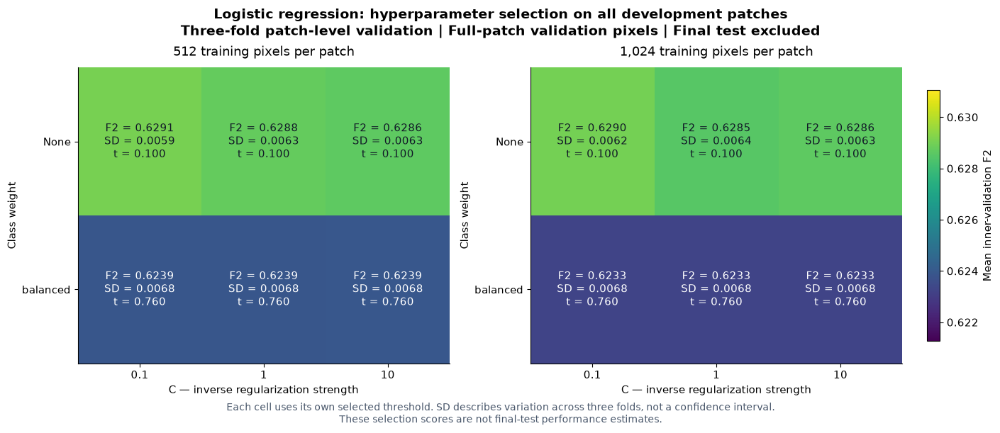

In [68]:
import time
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ------------------------------------------------------------
# 1. Final-search settings: reuse the previously evaluated space.
# ------------------------------------------------------------
LR_FINAL_C_VALUES = [0.1, 1.0, 10.0]
LR_FINAL_SAMPLE_SIZES = [512, 1024]
LR_FINAL_WEIGHT_OPTIONS = [
    ("None", None),
    ("balanced", "balanced"),
]

lr_final_dev_ids = np.asarray(
    sorted(map(str, dev_ids), key=int)
)
lr_final_test_ids = set(map(str, test_ids))

assert len(np.unique(lr_final_dev_ids)) == len(lr_final_dev_ids)
assert set(lr_final_dev_ids).isdisjoint(lr_final_test_ids)

lr_final_presence = (
    presence_by_id
    .reindex(lr_final_dev_ids)
)

assert lr_final_presence.notna().all()

lr_final_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# Store the splits for subsequent calibration.
lr_final_inner_splits = []

for train_index, validation_index in lr_final_cv.split(
    lr_final_dev_ids,
    lr_final_presence.to_numpy(),
):
    training_ids = lr_final_dev_ids[train_index]
    validation_ids = lr_final_dev_ids[validation_index]

    assert set(training_ids).isdisjoint(validation_ids)
    assert set(training_ids).isdisjoint(lr_final_test_ids)
    assert set(validation_ids).isdisjoint(lr_final_test_ids)

    lr_final_inner_splits.append({
        "train_ids": training_ids,
        "validation_ids": validation_ids,
    })

search_combinations = list(product(
    LR_FINAL_SAMPLE_SIZES,
    LR_FINAL_C_VALUES,
    LR_FINAL_WEIGHT_OPTIONS,
))

total_fits = len(search_combinations) * len(lr_final_inner_splits)

print(f"Development patches: {len(lr_final_dev_ids):,}")
print(f"Reserved final-test patches: {len(lr_final_test_ids):,}")
print(f"Hyperparameter combinations: {len(search_combinations)}")
print(f"Validation folds: {len(lr_final_inner_splits)}")
print(f"Total model fits: {total_fits}")
print("Validation uses every pixel in each held-out patch.")


# ------------------------------------------------------------
# 2. Train and evaluate each candidate.
# ------------------------------------------------------------
lr_final_search_tables = []
lr_final_fit_records = []

completed_fits = 0
search_start = time.perf_counter()

for sample_size, c_value, weight_option in search_combinations:
    weight_label, class_weight = weight_option

    for fold_number, split in enumerate(
        lr_final_inner_splits,
        start=1,
    ):
        X_training, y_training = get_sampled_pixels(
            split["train_ids"],
            sample_size,
        )

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                C=c_value,
                class_weight=class_weight,
                solver="lbfgs",
                max_iter=1000,
                random_state=RANDOM_STATE,
            )),
        ])

        fit_start = time.perf_counter()

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            model.fit(X_training, y_training)

        convergence_warnings = [
            warning for warning in caught
            if issubclass(warning.category, ConvergenceWarning)
        ]

        if convergence_warnings:
            raise RuntimeError(
                "Logistic regression did not converge. "
                f"Fold={fold_number}, C={c_value}, "
                f"class_weight={weight_label}, "
                f"pixels_per_patch={sample_size}. "
                "Resolve convergence before interpreting this search."
            )

        fit_seconds = time.perf_counter() - fit_start

        validation_start = time.perf_counter()

        scores = evaluate_full_patches_at_thresholds(
            model,
            split["validation_ids"],
            THRESHOLDS,
        )

        validation_seconds = (
            time.perf_counter() - validation_start
        )

        scores["Pixels per patch"] = sample_size
        scores["C"] = c_value
        scores["Class weight"] = weight_label
        scores["Inner fold"] = fold_number

        lr_final_search_tables.append(scores)

        lr_final_fit_records.append({
            "Pixels per patch": sample_size,
            "C": c_value,
            "Class weight": weight_label,
            "Inner fold": fold_number,
            "Training patches": len(split["train_ids"]),
            "Validation patches": len(split["validation_ids"]),
            "Training pixels": len(y_training),
            "Training positive pixels": int(y_training.sum()),
            "Iterations": int(
                model.named_steps["classifier"].n_iter_.max()
            ),
            "Fit seconds": fit_seconds,
            "Validation seconds": validation_seconds,
        })

        completed_fits += 1

        print(
            f"[{completed_fits:02d}/{total_fits}] "
            f"pixels={sample_size}, C={c_value:g}, "
            f"weight={weight_label}, fold={fold_number} | "
            f"fit={fit_seconds:.1f}s, "
            f"validation={validation_seconds:.1f}s",
            flush=True,
        )

        del X_training, y_training, model


# ------------------------------------------------------------
# 3. Summarize validation scores.
# ------------------------------------------------------------
lr_final_search_results = pd.concat(
    lr_final_search_tables,
    ignore_index=True,
)

lr_final_fit_log = pd.DataFrame(lr_final_fit_records)

group_columns = [
    "Pixels per patch",
    "C",
    "Class weight",
    "Threshold",
]

lr_final_search_summary = (
    lr_final_search_results
    .groupby(group_columns, as_index=False)
    .agg(
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean"),
        Fold_count=("Inner fold", "nunique"),
    )
)

assert lr_final_search_summary["Fold_count"].eq(3).all()

# Same deterministic selection rule:
# highest mean F2, then precision, smaller training sample,
# smaller C, class-weight label, and higher threshold.
lr_final_ranked = (
    lr_final_search_summary
    .sort_values(
        [
            "Mean_F2",
            "Mean_precision",
            "Pixels per patch",
            "C",
            "Class weight",
            "Threshold",
        ],
        ascending=[
            False,
            False,
            True,
            True,
            True,
            False,
        ],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

lr_final_selected_hyperparameters = (
    lr_final_ranked.iloc[0].copy()
)

# Best threshold for each of the 12 hyperparameter combinations.
lr_final_best_per_configuration = (
    lr_final_ranked
    .drop_duplicates([
        "Pixels per patch",
        "C",
        "Class weight",
    ])
    .reset_index(drop=True)
)

print(
    "\nSearch finished in "
    f"{(time.perf_counter() - search_start) / 60:.1f} minutes."
)

print("\nSelected hyperparameters — calibration still pending:")

display(
    lr_final_selected_hyperparameters[
        [
            "Pixels per patch",
            "C",
            "Class weight",
            "Threshold",
            "Mean_F2",
            "SD_F2",
            "Mean_precision",
            "Mean_recall",
            "Mean_specificity",
            "Mean_IoU",
        ]
    ].to_frame("Selected value")
)

print("\nAll configurations at their selected thresholds:")

display(
    lr_final_best_per_configuration[
        [
            "Pixels per patch",
            "C",
            "Class weight",
            "Threshold",
            "Mean_F2",
            "SD_F2",
            "Mean_precision",
            "Mean_recall",
            "Mean_specificity",
            "Mean_IoU",
        ]
    ].round(5)
)


# ------------------------------------------------------------
# 4. Plot all configurations with a shared color scale.
# ------------------------------------------------------------
plot_values = lr_final_best_per_configuration["Mean_F2"]

color_min = float(plot_values.min()) - 0.002
color_max = float(plot_values.max()) + 0.002
color_midpoint = (color_min + color_max) / 2

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 6),
        layout="constrained",
    )

    fig.suptitle(
        "Logistic regression: hyperparameter selection "
        "on all development patches\n"
        "Three-fold patch-level validation | "
        "Full-patch validation pixels | Final test excluded",
        fontsize=14,
        fontweight="bold",
    )

    for ax, sample_size in zip(
        axes,
        LR_FINAL_SAMPLE_SIZES,
    ):
        subset = (
            lr_final_best_per_configuration.loc[
                lr_final_best_per_configuration[
                    "Pixels per patch"
                ].eq(sample_size)
            ]
            .set_index(["Class weight", "C"])
        )

        weights = ["None", "balanced"]

        values = np.array([
            [
                subset.loc[(weight, c_value), "Mean_F2"]
                for c_value in LR_FINAL_C_VALUES
            ]
            for weight in weights
        ])

        heatmap = ax.imshow(
            values,
            cmap="viridis",
            vmin=color_min,
            vmax=color_max,
            aspect="auto",
        )

        for row, weight in enumerate(weights):
            for column, c_value in enumerate(LR_FINAL_C_VALUES):
                result = subset.loc[(weight, c_value)]
                text_color = (
                    "white"
                    if result["Mean_F2"] < color_midpoint
                    else "#111827"
                )

                ax.text(
                    column,
                    row,
                    f"F2 = {result['Mean_F2']:.4f}\n"
                    f"SD = {result['SD_F2']:.4f}\n"
                    f"t = {result['Threshold']:.3f}",
                    ha="center",
                    va="center",
                    color=text_color,
                    fontsize=11,
                )

        ax.set_xticks(range(len(LR_FINAL_C_VALUES)))
        ax.set_xticklabels([
            f"{value:g}" for value in LR_FINAL_C_VALUES
        ])
        ax.set_yticks(range(len(weights)))
        ax.set_yticklabels(weights)

        ax.set_xlabel("C — inverse regularization strength")
        ax.set_ylabel("Class weight")
        ax.set_title(
            f"{sample_size:,} training pixels per patch",
            pad=12,
        )

    colorbar = fig.colorbar(
        heatmap,
        ax=axes,
        shrink=0.85,
        pad=0.03,
    )
    colorbar.set_label("Mean inner-validation F2")

    fig.supxlabel(
        "Each cell uses its own selected threshold. "
        "SD describes variation across three folds, "
        "not a confidence interval.\n"
        "These selection scores are not final-test "
        "performance estimates.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

Three-fold validation across the full development set selected 512 training pixels per patch, C = 0.1, and no class weighting. Mean validation F2 was 0.62907 (fold SD = 0.00591), with precision 0.39415, recall 0.73926, specificity 0.97249, and IoU 0.34603. Increasing the training sample to 1,024 pixels per patch provided no meaningful improvement in this search. Balanced weighting increased recall but reduced precision and F2. Calibration and the final operating threshold remain to be selected; the final holdout test remains unused.

Fixed settings: pixels=512, C=0.1, class_weight=None
Calibration fraction: 20%
Final-test images are excluded.
Fold 1/3 | Uncalibrated | full-patch validation completed in 3.8s
Fold 1/3 | Sigmoid      | full-patch validation completed in 4.3s
Fold 1/3 | Isotonic     | full-patch validation completed in 3.8s
Fold 2/3 | Uncalibrated | full-patch validation completed in 3.7s
Fold 2/3 | Sigmoid      | full-patch validation completed in 4.1s
Fold 2/3 | Isotonic     | full-patch validation completed in 3.8s
Fold 3/3 | Uncalibrated | full-patch validation completed in 3.8s
Fold 3/3 | Sigmoid      | full-patch validation completed in 4.1s
Fold 3/3 | Isotonic     | full-patch validation completed in 3.8s

Patch allocation and calibration prevalence:


,Inner fold,Fitting patches,Calibration patches,Validation patches,Fitting pixels,Calibration pixels,Calibration positive fraction
0,1,1620,406,1013,829440,207872,0.02270
1,2,1620,406,1013,829440,207872,0.02094
2,3,1620,406,1013,829440,207872,0.02401



Each method at its selected threshold:


,Method,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,Sigmoid,0.10,0.62854,0.00590,0.39271,0.73978,0.97231,0.34496
1,Uncalibrated,0.10,0.62853,0.00569,0.39392,0.73853,0.97248,0.34570
2,Isotonic,0.12,0.62715,0.00361,0.36914,0.76121,0.96844,0.33041



Selected method and threshold:


,Selected value
Method,Sigmoid
Threshold,0.1
Mean_F2,0.628538
SD_F2,0.005898
Mean_precision,0.392713
Mean_recall,0.739778
Mean_specificity,0.972309
Mean_IoU,0.344957



Total elapsed time: 0.7 minutes.
Final model fitting and final-test evaluation are still pending.


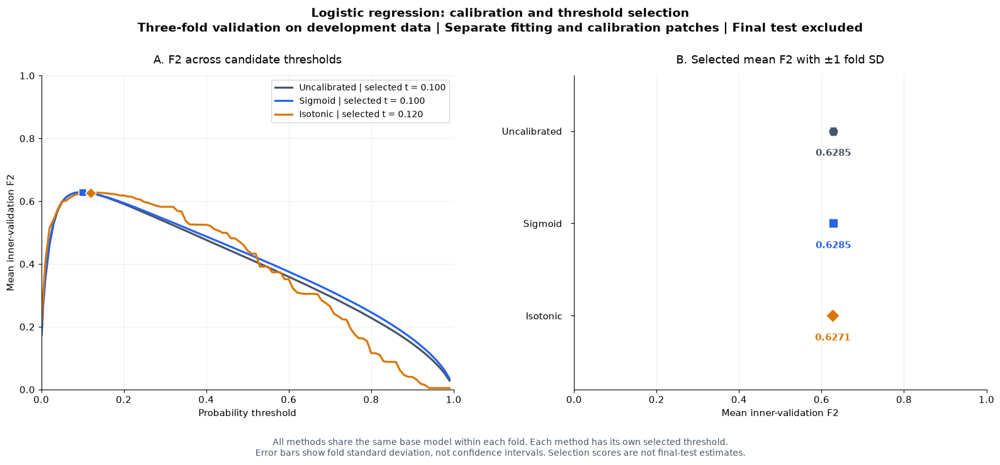

In [69]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.exceptions import ConvergenceWarning
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ------------------------------------------------------------
# 1. Read the hyperparameters selected in the previous step.
# ------------------------------------------------------------
lr_final_sample_size = int(
    lr_final_selected_hyperparameters["Pixels per patch"]
)
lr_final_c = float(
    lr_final_selected_hyperparameters["C"]
)
lr_final_weight_label = str(
    lr_final_selected_hyperparameters["Class weight"]
)

lr_final_class_weight = (
    None
    if lr_final_weight_label == "None"
    else lr_final_weight_label
)

# Reuse the calibration settings established earlier.
assert 0 < CALIBRATION_FRACTION < 1

lr_final_calibration_methods = [
    "Uncalibrated",
    "Sigmoid",
    "Isotonic",
]

lr_final_calibration_tables = []
lr_final_calibration_split_records = []

calibration_start = time.perf_counter()

print(
    f"Fixed settings: pixels={lr_final_sample_size}, "
    f"C={lr_final_c:g}, "
    f"class_weight={lr_final_weight_label}"
)
print(f"Calibration fraction: {CALIBRATION_FRACTION:.0%}")
print("Final-test images are excluded.")


# ------------------------------------------------------------
# 2. Compare calibration methods within the existing CV splits.
# ------------------------------------------------------------
for fold_number, split in enumerate(
    lr_final_inner_splits,
    start=1,
):
    inner_training_ids = np.asarray(
        split["train_ids"],
        dtype=str,
    )
    validation_ids = np.asarray(
        split["validation_ids"],
        dtype=str,
    )

    inner_presence = (
        presence_by_id
        .reindex(inner_training_ids)
    )

    assert inner_presence.notna().all()

    fitting_ids, calibration_ids = train_test_split(
        inner_training_ids,
        test_size=CALIBRATION_FRACTION,
        stratify=inner_presence.to_numpy(),
        random_state=RANDOM_STATE + 100 + fold_number,
    )

    fitting_set = set(fitting_ids)
    calibration_set = set(calibration_ids)
    validation_set = set(validation_ids)

    assert fitting_set.isdisjoint(calibration_set)
    assert fitting_set.isdisjoint(validation_set)
    assert calibration_set.isdisjoint(validation_set)

    for patch_set in (
        fitting_set,
        calibration_set,
        validation_set,
    ):
        assert patch_set.isdisjoint(lr_final_test_ids)

    X_fitting, y_fitting = get_sampled_pixels(
        fitting_ids,
        lr_final_sample_size,
    )
    X_calibration, y_calibration = get_sampled_pixels(
        calibration_ids,
        lr_final_sample_size,
    )

    assert np.unique(y_fitting).size == 2
    assert np.unique(y_calibration).size == 2

    base_model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            C=lr_final_c,
            class_weight=lr_final_class_weight,
            solver="lbfgs",
            max_iter=1000,
            random_state=RANDOM_STATE,
        )),
    ])

    # Fit preprocessing and the base model on fitting patches only.
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        base_model.fit(X_fitting, y_fitting)

    if any(
        issubclass(item.category, ConvergenceWarning)
        for item in caught
    ):
        raise RuntimeError(
            f"Base model did not converge in fold {fold_number}."
        )

    # Calibration uses base-model decision scores.
    calibration_scores = base_model.decision_function(
        X_calibration
    )

    # Sigmoid / Platt calibration.
    sigmoid_calibrator = LogisticRegression(
        C=PLATT_C,
        class_weight=None,
        solver="lbfgs",
        max_iter=1000,
        random_state=RANDOM_STATE,
    )

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        sigmoid_calibrator.fit(
            calibration_scores.reshape(-1, 1),
            y_calibration,
        )

    if any(
        issubclass(item.category, ConvergenceWarning)
        for item in caught
    ):
        raise RuntimeError(
            f"Sigmoid calibration did not converge in fold "
            f"{fold_number}."
        )

    # Isotonic calibration.
    isotonic_calibrator = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip",
    )
    isotonic_calibrator.fit(
        calibration_scores,
        y_calibration,
    )

    # All three methods use the SAME fitted base model.
    probability_models = {
        "Uncalibrated": CalibratedProbabilityModel(
            base_model,
            "Uncalibrated",
        ),
        "Sigmoid": CalibratedProbabilityModel(
            base_model,
            "Sigmoid",
            sigmoid_calibrator,
        ),
        "Isotonic": CalibratedProbabilityModel(
            base_model,
            "Isotonic",
            isotonic_calibrator,
        ),
    }

    lr_final_calibration_split_records.append({
        "Inner fold": fold_number,
        "Fitting patches": len(fitting_ids),
        "Calibration patches": len(calibration_ids),
        "Validation patches": len(validation_ids),
        "Fitting pixels": len(y_fitting),
        "Calibration pixels": len(y_calibration),
        "Calibration positive fraction": float(
            y_calibration.mean()
        ),
    })

    for method in lr_final_calibration_methods:
        method_start = time.perf_counter()

        scores = evaluate_full_patches_at_thresholds(
            probability_models[method],
            validation_ids,
            THRESHOLDS,
        )

        scores["Method"] = method
        scores["Inner fold"] = fold_number

        lr_final_calibration_tables.append(scores)

        print(
            f"Fold {fold_number}/3 | {method:<12} | "
            f"full-patch validation completed in "
            f"{time.perf_counter() - method_start:.1f}s",
            flush=True,
        )

    del (
        X_fitting,
        y_fitting,
        X_calibration,
        y_calibration,
        calibration_scores,
        probability_models,
        base_model,
        sigmoid_calibrator,
        isotonic_calibrator,
    )


# ------------------------------------------------------------
# 3. Select the method and threshold using mean validation F2.
# ------------------------------------------------------------
lr_final_calibration_results = pd.concat(
    lr_final_calibration_tables,
    ignore_index=True,
)

lr_final_calibration_split_summary = pd.DataFrame(
    lr_final_calibration_split_records
)

lr_final_calibration_summary = (
    lr_final_calibration_results
    .groupby(["Method", "Threshold"], as_index=False)
    .agg(
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean"),
        Fold_count=("Inner fold", "nunique"),
    )
)

assert lr_final_calibration_summary["Fold_count"].eq(3).all()

# Selection: highest mean F2, then precision.
# Remaining exact ties: method name, then higher threshold.
lr_final_calibration_ranked = (
    lr_final_calibration_summary
    .sort_values(
        ["Mean_F2", "Mean_precision", "Method", "Threshold"],
        ascending=[False, False, True, False],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

lr_final_calibration_best_per_method = (
    lr_final_calibration_ranked
    .drop_duplicates("Method")
    .reset_index(drop=True)
)

lr_final_selected_calibration = (
    lr_final_calibration_ranked.iloc[0].copy()
)

print("\nPatch allocation and calibration prevalence:")
display(lr_final_calibration_split_summary.round(5))

print("\nEach method at its selected threshold:")
display(
    lr_final_calibration_best_per_method[
        [
            "Method",
            "Threshold",
            "Mean_F2",
            "SD_F2",
            "Mean_precision",
            "Mean_recall",
            "Mean_specificity",
            "Mean_IoU",
        ]
    ].round(5)
)

print("\nSelected method and threshold:")
display(
    lr_final_selected_calibration[
        [
            "Method",
            "Threshold",
            "Mean_F2",
            "SD_F2",
            "Mean_precision",
            "Mean_recall",
            "Mean_specificity",
            "Mean_IoU",
        ]
    ].to_frame("Selected value")
)

print(
    "\nTotal elapsed time: "
    f"{(time.perf_counter() - calibration_start) / 60:.1f} minutes."
)
print("Final model fitting and final-test evaluation are still pending.")


# ------------------------------------------------------------
# 4. Plot threshold sensitivity and selected scores.
# ------------------------------------------------------------
calibration_colors = {
    "Uncalibrated": "#475569",
    "Sigmoid": "#2563EB",
    "Isotonic": "#D97706",
}

calibration_markers = {
    "Uncalibrated": "o",
    "Sigmoid": "s",
    "Isotonic": "D",
}

best_method_lookup = (
    lr_final_calibration_best_per_method
    .set_index("Method")
)

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 7.5),
        layout="constrained",
    )

    fig.get_layout_engine().set(
        w_pad=0.15,
        h_pad=0.15,
        wspace=0.08,
    )

    fig.suptitle(
        "Logistic regression: calibration and threshold selection\n"
        "Three-fold validation on development data | "
        "Separate fitting and calibration patches | Final test excluded",
        fontsize=14,
        fontweight="bold",
    )

    for position, method in enumerate(
        lr_final_calibration_methods
    ):
        curve = (
            lr_final_calibration_summary.loc[
                lr_final_calibration_summary["Method"].eq(method)
            ]
            .sort_values("Threshold")
        )
        best = best_method_lookup.loc[method]

        axes[0].plot(
            curve["Threshold"],
            curve["Mean_F2"],
            color=calibration_colors[method],
            linewidth=2.3,
            label=(
                f"{method} | selected t = "
                f"{best['Threshold']:.3f}"
            ),
        )
        axes[0].scatter(
            best["Threshold"],
            best["Mean_F2"],
            marker=calibration_markers[method],
            color=calibration_colors[method],
            edgecolor="white",
            s=80,
            zorder=5,
        )

        axes[1].errorbar(
            float(best["Mean_F2"]),
            position,
            xerr=float(best["SD_F2"]),
            fmt=calibration_markers[method],
            color=calibration_colors[method],
            markersize=9,
            elinewidth=2,
            capsize=5,
        )
        axes[1].annotate(
            f"{best['Mean_F2']:.4f}",
            xy=(float(best["Mean_F2"]), position),
            xytext=(0, -20),
            textcoords="offset points",
            ha="center",
            va="top",
            color=calibration_colors[method],
            fontweight="bold",
        )

    axes[0].set_title(
        "A. F2 across candidate thresholds",
        pad=14,
    )
    axes[0].set(
        xlabel="Probability threshold",
        ylabel="Mean inner-validation F2",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    axes[0].legend(
        loc="upper right",
        frameon=True,
        fontsize=10,
    )
    axes[0].grid(alpha=0.2)

    axes[1].set_title(
        "B. Selected mean F2 with ±1 fold SD",
        pad=14,
    )
    axes[1].set(
        xlabel="Mean inner-validation F2",
        xlim=(0, 1),
        ylim=(2.8, -0.6),
    )
    axes[1].set_yticks(range(3))
    axes[1].set_yticklabels(lr_final_calibration_methods)
    axes[1].tick_params(axis="y", pad=10)
    axes[1].grid(axis="x", alpha=0.2)

    for ax in axes:
        ax.set_axisbelow(True)
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)

    fig.supxlabel(
        "All methods share the same base model within each fold. "
        "Each method has its own selected threshold.\n"
        "Error bars show fold standard deviation, not confidence intervals. "
        "Selection scores are not final-test estimates.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

Sigmoid calibration with a threshold of 0.10 was selected by the predefined mean-validation-F2 rule. Its mean F2 was 0.62854, almost identical to the uncalibrated model’s 0.62853; this negligible difference does not establish a meaningful improvement. Isotonic calibration increased recall but reduced precision and achieved slightly lower F2. Fitting, calibration, and validation patches were kept separate within each fold. Final model fitting and holdout evaluation remain pending.

Fixed final settings:


,Value
pixels_per_patch,512
C,0.1
class_weight,None
calibration_method,Sigmoid
threshold,0.1
calibration_fraction,0.2
split_seed,1043



Development-data allocation:


,Role,Patches,Sampled pixels,Positive fraction
0,Base-model fitting,2431,1244672,0.02423
1,Calibration,608,311296,0.02170



Base-model intercept:
-6.285177

Base-model optimization iterations:
59

Base-model coefficients:


,Feature,Standardized base-model coefficient
0,B1,0.345406
1,B2,-1.976988
2,B3,2.027057
3,B4,0.136958
4,B5,1.099360
5,B6,2.311169
6,B7,-4.138042
7,B8,-0.902249
8,B9,1.072916
9,B10,-0.632263



Sigmoid calibration parameters:


,Parameter,Value
0,Decision-score coefficient,1.038327
1,Calibration intercept,0.132964


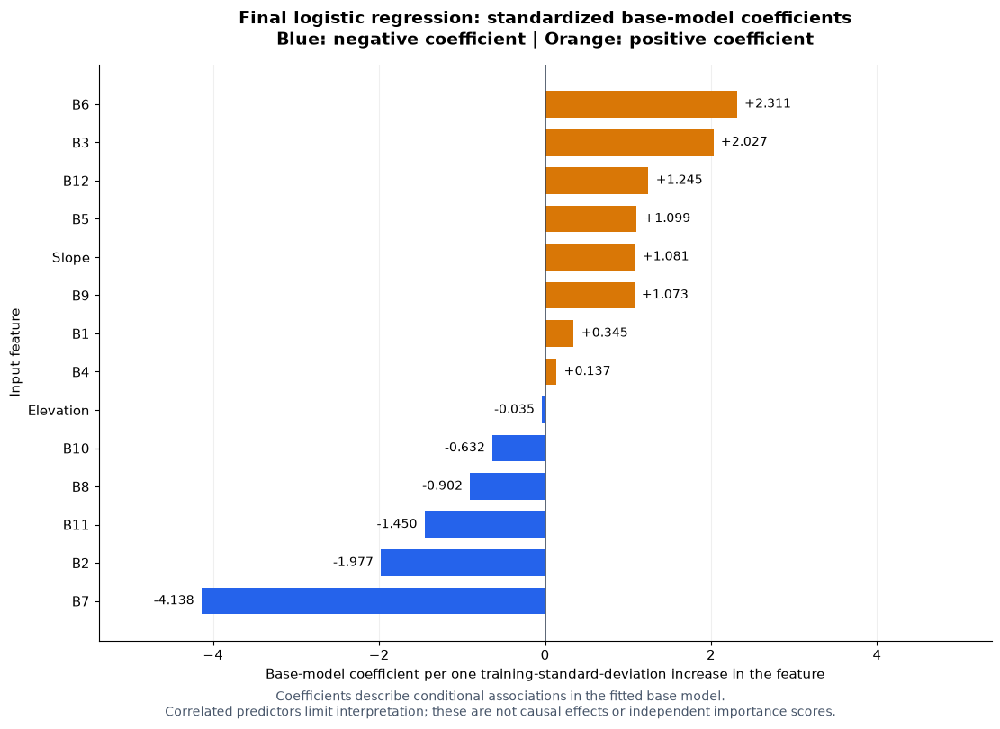


Final base model and selected probability model are fitted.
Fixed classification threshold: 0.100
Final-test patches remain unused: 760


In [70]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.exceptions import ConvergenceWarning
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ------------------------------------------------------------
# 1. Freeze the settings selected using development data only.
# ------------------------------------------------------------
lr_final_settings = {
    "pixels_per_patch": int(
        lr_final_selected_hyperparameters["Pixels per patch"]
    ),
    "C": float(
        lr_final_selected_hyperparameters["C"]
    ),
    "class_weight": (
        None
        if str(
            lr_final_selected_hyperparameters["Class weight"]
        ) == "None"
        else str(
            lr_final_selected_hyperparameters["Class weight"]
        )
    ),
    "calibration_method": str(
        lr_final_selected_calibration["Method"]
    ),
    "threshold": float(
        lr_final_selected_calibration["Threshold"]
    ),
    "calibration_fraction": float(CALIBRATION_FRACTION),
    # Fixed seed for the final fitting/calibration split.
    "split_seed": RANDOM_STATE + 1000,
}

all_development_ids = np.asarray(
    lr_final_dev_ids,
    dtype=str,
)

assert set(all_development_ids).isdisjoint(lr_final_test_ids)

if lr_final_settings["calibration_method"] == "Uncalibrated":
    lr_final_fitting_ids = all_development_ids.copy()
    lr_final_calibration_ids = np.asarray([], dtype=str)

else:
    development_presence = (
        presence_by_id
        .reindex(all_development_ids)
    )
    assert development_presence.notna().all()

    (
        lr_final_fitting_ids,
        lr_final_calibration_ids,
    ) = train_test_split(
        all_development_ids,
        test_size=lr_final_settings["calibration_fraction"],
        stratify=development_presence.to_numpy(),
        random_state=lr_final_settings["split_seed"],
    )

assert set(lr_final_fitting_ids).isdisjoint(
    lr_final_calibration_ids
)
assert (
    set(lr_final_fitting_ids)
    | set(lr_final_calibration_ids)
) == set(all_development_ids)

assert set(lr_final_fitting_ids).isdisjoint(lr_final_test_ids)
assert set(lr_final_calibration_ids).isdisjoint(lr_final_test_ids)


# ------------------------------------------------------------
# 2. Fit the final scaler and base logistic regression.
# ------------------------------------------------------------
X_lr_final_fit, y_lr_final_fit = get_sampled_pixels(
    lr_final_fitting_ids,
    lr_final_settings["pixels_per_patch"],
)

lr_final_base_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        C=lr_final_settings["C"],
        class_weight=lr_final_settings["class_weight"],
        solver="lbfgs",
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    lr_final_base_model.fit(
        X_lr_final_fit,
        y_lr_final_fit,
    )

if any(
    issubclass(item.category, ConvergenceWarning)
    for item in caught
):
    raise RuntimeError(
        "The final base model did not converge. "
        "Do not proceed to final-test evaluation."
    )

lr_final_fitting_pixel_count = len(y_lr_final_fit)
lr_final_fitting_prevalence = float(y_lr_final_fit.mean())

del X_lr_final_fit, y_lr_final_fit


# ------------------------------------------------------------
# 3. Fit the selected calibrator on separate development patches.
# ------------------------------------------------------------
lr_final_calibrator = None
lr_final_calibration_pixel_count = 0
lr_final_calibration_prevalence = np.nan

if lr_final_settings["calibration_method"] != "Uncalibrated":
    X_lr_final_cal, y_lr_final_cal = get_sampled_pixels(
        lr_final_calibration_ids,
        lr_final_settings["pixels_per_patch"],
    )

    final_calibration_scores = (
        lr_final_base_model.decision_function(X_lr_final_cal)
    )

    lr_final_calibration_pixel_count = len(y_lr_final_cal)
    lr_final_calibration_prevalence = float(
        y_lr_final_cal.mean()
    )

    if lr_final_settings["calibration_method"] == "Sigmoid":
        lr_final_calibrator = LogisticRegression(
            C=PLATT_C,
            class_weight=None,
            solver="lbfgs",
            max_iter=1000,
            random_state=RANDOM_STATE,
        )

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            lr_final_calibrator.fit(
                final_calibration_scores.reshape(-1, 1),
                y_lr_final_cal,
            )

        if any(
            issubclass(item.category, ConvergenceWarning)
            for item in caught
        ):
            raise RuntimeError(
                "The final sigmoid calibrator did not converge. "
                "Do not proceed to final-test evaluation."
            )

    elif lr_final_settings["calibration_method"] == "Isotonic":
        lr_final_calibrator = IsotonicRegression(
            increasing=True,
            out_of_bounds="clip",
        )
        lr_final_calibrator.fit(
            final_calibration_scores,
            y_lr_final_cal,
        )

    else:
        raise ValueError("Unknown calibration method.")

    del (
        X_lr_final_cal,
        y_lr_final_cal,
        final_calibration_scores,
    )

lr_final_probability_model = CalibratedProbabilityModel(
    lr_final_base_model,
    lr_final_settings["calibration_method"],
    lr_final_calibrator,
)

lr_final_threshold = lr_final_settings["threshold"]


# ------------------------------------------------------------
# 4. Report the fitted model and data allocation.
# ------------------------------------------------------------
print("Fixed final settings:")
display(
    pd.Series(
        lr_final_settings,
        name="Value",
    ).to_frame()
)

lr_final_data_allocation = pd.DataFrame([
    {
        "Role": "Base-model fitting",
        "Patches": len(lr_final_fitting_ids),
        "Sampled pixels": lr_final_fitting_pixel_count,
        "Positive fraction": lr_final_fitting_prevalence,
    },
    {
        "Role": "Calibration",
        "Patches": len(lr_final_calibration_ids),
        "Sampled pixels": lr_final_calibration_pixel_count,
        "Positive fraction": lr_final_calibration_prevalence,
    },
])

print("\nDevelopment-data allocation:")
display(lr_final_data_allocation.round(5))

final_classifier = (
    lr_final_base_model.named_steps["classifier"]
)

lr_final_coefficient_table = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Standardized base-model coefficient":
        final_classifier.coef_[0],
})

print("\nBase-model intercept:")
print(f"{final_classifier.intercept_[0]:.6f}")

print("\nBase-model optimization iterations:")
print(int(final_classifier.n_iter_.max()))

print("\nBase-model coefficients:")
display(lr_final_coefficient_table.round(6))

if lr_final_settings["calibration_method"] == "Sigmoid":
    lr_final_sigmoid_parameters = pd.DataFrame({
        "Parameter": [
            "Decision-score coefficient",
            "Calibration intercept",
        ],
        "Value": [
            float(lr_final_calibrator.coef_[0, 0]),
            float(lr_final_calibrator.intercept_[0]),
        ],
    })

    print("\nSigmoid calibration parameters:")
    display(lr_final_sigmoid_parameters.round(6))


# ------------------------------------------------------------
# 5. Plot the final base-model coefficients.
# ------------------------------------------------------------
coefficient_plot_data = (
    lr_final_coefficient_table
    .sort_values("Standardized base-model coefficient")
)

coefficient_values = coefficient_plot_data[
    "Standardized base-model coefficient"
].to_numpy()

bar_colors = np.where(
    coefficient_values >= 0,
    "#D97706",
    "#2563EB",
)

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, ax = plt.subplots(
        figsize=(11, 8),
        layout="constrained",
    )

    bars = ax.barh(
        coefficient_plot_data["Feature"],
        coefficient_values,
        color=bar_colors,
        height=0.7,
    )

    ax.bar_label(
        bars,
        labels=[f"{value:+.3f}" for value in coefficient_values],
        padding=6,
        fontsize=10,
    )

    coefficient_limit = max(
        float(np.abs(coefficient_values).max()) * 1.3,
        0.5,
    )
    ax.set_xlim(-coefficient_limit, coefficient_limit)

    ax.axvline(
        0,
        color="#334155",
        linewidth=1.1,
    )
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    ax.set_xlabel(
        "Base-model coefficient per one training-standard-deviation "
        "increase in the feature"
    )
    ax.set_ylabel("Input feature")
    ax.set_title(
        "Final logistic regression: standardized base-model coefficients\n"
        "Blue: negative coefficient | Orange: positive coefficient",
        fontsize=14,
        fontweight="bold",
        pad=16,
    )

    fig.supxlabel(
        "Coefficients describe conditional associations in the fitted "
        "base model.\n"
        "Correlated predictors limit interpretation; "
        "these are not causal effects or independent importance scores.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

print(
    "\nFinal base model and selected probability model are fitted."
)
print(
    f"Fixed classification threshold: {lr_final_threshold:.3f}"
)
print(
    f"Final-test patches remain unused: {len(lr_final_test_ids):,}"
)

The final logistic regression base model was fitted on 2,431 development patches, and sigmoid calibration was fitted on 608 separate development patches. The base model converged in 59 iterations. B6 and B7 had the largest positive and negative standardized coefficients, respectively; correlated predictors limit their interpretation as feature importance. Sigmoid parameters were 1.038327 for the decision-score coefficient and 0.132964 for the intercept. The classification threshold remains fixed at 0.10. Final holdout evaluation is still pending.

Final-test patches: 760
Final-test pixels: 12,451,840
Fixed threshold: 0.100
No fitting, calibration, or threshold search is performed.
Predicted 100/760 patches
Predicted 200/760 patches
Predicted 300/760 patches
Predicted 400/760 patches
Predicted 500/760 patches


C:\Users\hadid\AppData\Local\Temp\ipykernel_15700\2998500123.py:143: RuntimeWarning: divide by zero encountered in log1p
  * np.log1p(-clipped_probability)


Predicted 600/760 patches
Predicted 700/760 patches
Predicted 760/760 patches

Final holdout results:


,Metric,Final-test value
0,TN,1.183769e+07
1,FP,3.487710e+05
2,FN,6.884300e+04
3,TP,1.965380e+05
4,Precision,3.604160e-01
5,Recall,7.405880e-01
6,Specificity,9.713800e-01
7,F1,4.848660e-01
8,F2,6.115690e-01
9,IoU,3.200150e-01



Test landslide prevalence: 2.131%
Evaluation elapsed time: 0.1 minutes


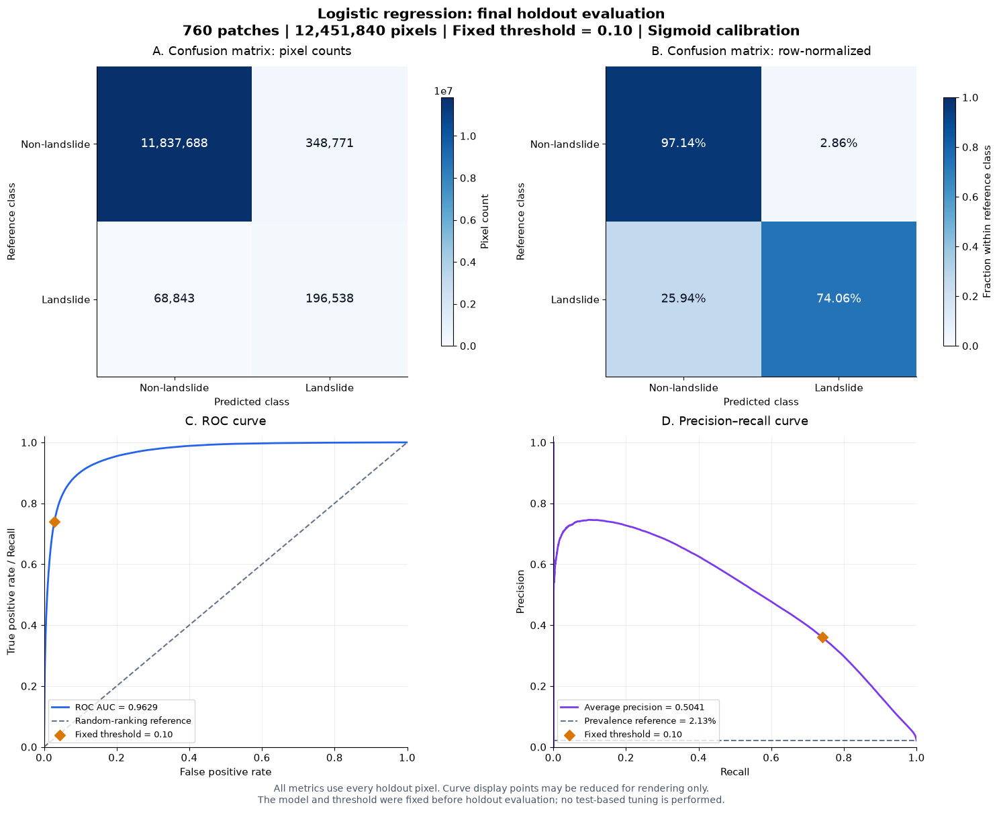

In [71]:
import time

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    auc,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
)


# ------------------------------------------------------------
# 1. Verify the fixed model and the reserved test partition.
# ------------------------------------------------------------
lr_test_patch_ids = np.asarray(
    sorted(map(str, test_ids), key=int)
)

assert len(np.unique(lr_test_patch_ids)) == len(lr_test_patch_ids)
assert set(lr_test_patch_ids) == set(lr_final_test_ids)
assert set(lr_test_patch_ids).isdisjoint(lr_final_fitting_ids)
assert set(lr_test_patch_ids).isdisjoint(
    lr_final_calibration_ids
)
assert set(lr_test_patch_ids).isdisjoint(lr_final_dev_ids)

assert np.isclose(
    lr_final_threshold,
    lr_final_settings["threshold"],
)

positive_class_index = int(
    np.flatnonzero(
        np.asarray(lr_final_probability_model.classes_) == 1
    )[0]
)

# Image dimensions were established by the dataset audit.
PATCH_HEIGHT = 128
PATCH_WIDTH = 128
PIXELS_PER_PATCH = PATCH_HEIGHT * PATCH_WIDTH

lr_test_total_pixels = (
    len(lr_test_patch_ids) * PIXELS_PER_PATCH
)

# Keep full predictions for subsequent analyses.
lr_test_y = np.empty(lr_test_total_pixels, dtype=np.uint8)
lr_test_probability = np.empty(
    lr_test_total_pixels,
    dtype=np.float64,
)

lr_test_patch_records = []
test_start = time.perf_counter()

print(f"Final-test patches: {len(lr_test_patch_ids):,}")
print(f"Final-test pixels: {lr_test_total_pixels:,}")
print(f"Fixed threshold: {lr_final_threshold:.3f}")
print("No fitting, calibration, or threshold search is performed.")


# ------------------------------------------------------------
# 2. Predict every pixel once, patch by patch.
# ------------------------------------------------------------
for patch_number, sample_id in enumerate(
    lr_test_patch_ids,
    start=1,
):
    image_path = (
        DATA_DIR / "TrainData" / "img" / f"image_{sample_id}.h5"
    )
    mask_path = (
        DATA_DIR / "TrainData" / "mask" / f"mask_{sample_id}.h5"
    )

    with h5py.File(image_path, "r") as image_file:
        image_array = np.asarray(
            image_file["img"],
            dtype=np.float32,
        )

    with h5py.File(mask_path, "r") as mask_file:
        mask_array = np.asarray(mask_file["mask"])

    assert image_array.shape == (128, 128, len(FEATURE_NAMES))
    assert mask_array.shape == (128, 128)
    assert np.isfinite(image_array).all()
    assert np.isin(mask_array, [0, 1]).all()

    patch_y = mask_array.reshape(-1).astype(
        np.uint8,
        copy=False,
    )
    patch_probability = (
        lr_final_probability_model.predict_proba(
            image_array.reshape(-1, len(FEATURE_NAMES))
        )[:, positive_class_index]
    )

    assert np.isfinite(patch_probability).all()
    assert (
        (patch_probability >= 0)
        & (patch_probability <= 1)
    ).all()

    patch_prediction = (
        patch_probability >= lr_final_threshold
    ).astype(np.uint8)

    tn, fp, fn, tp = confusion_matrix(
        patch_y,
        patch_prediction,
        labels=[0, 1],
    ).ravel()

    start_index = (patch_number - 1) * PIXELS_PER_PATCH
    stop_index = start_index + PIXELS_PER_PATCH

    lr_test_y[start_index:stop_index] = patch_y
    lr_test_probability[start_index:stop_index] = (
        patch_probability
    )

    squared_error_sum = float(
        np.sum((patch_probability - patch_y) ** 2)
    )

    # Clipping is used only to keep logarithms finite.
    clipped_probability = np.clip(
        patch_probability,
        1e-15,
        1 - 1e-15,
    )
    log_loss_sum = float(
        -np.sum(
            patch_y * np.log(clipped_probability)
            + (1 - patch_y)
            * np.log1p(-clipped_probability)
        )
    )

    lr_test_patch_records.append({
        "sample_id": str(sample_id),
        "Start": start_index,
        "Stop": stop_index,
        "Pixels": len(patch_y),
        "Positive pixels": int(patch_y.sum()),
        "Landslide coverage (%)": 100 * float(patch_y.mean()),
        "Threshold": lr_final_threshold,
        "Squared error sum": squared_error_sum,
        "Log loss sum": log_loss_sum,
        **metrics_from_counts(tn, fp, fn, tp),
    })

    if patch_number % 100 == 0 or patch_number == len(
        lr_test_patch_ids
    ):
        print(
            f"Predicted {patch_number:,}/"
            f"{len(lr_test_patch_ids):,} patches",
            flush=True,
        )

lr_test_patch_results = pd.DataFrame(lr_test_patch_records)

assert lr_test_patch_results["sample_id"].is_unique
assert lr_test_patch_results["Pixels"].sum() == lr_test_total_pixels


# ------------------------------------------------------------
# 3. Calculate pooled test metrics from all test pixels.
# ------------------------------------------------------------
test_counts = (
    lr_test_patch_results[["TN", "FP", "FN", "TP"]]
    .sum()
    .astype(np.int64)
)

assert int(test_counts.sum()) == lr_test_total_pixels

lr_test_metrics = metrics_from_counts(
    int(test_counts["TN"]),
    int(test_counts["FP"]),
    int(test_counts["FN"]),
    int(test_counts["TP"]),
)

lr_test_metrics["Brier score"] = (
    lr_test_patch_results["Squared error sum"].sum()
    / lr_test_total_pixels
)
lr_test_metrics["Log loss"] = (
    lr_test_patch_results["Log loss sum"].sum()
    / lr_test_total_pixels
)
lr_test_prevalence = float(lr_test_y.mean())

# Compute ranking metrics using all predictions.
lr_test_fpr, lr_test_tpr, _ = roc_curve(
    lr_test_y,
    lr_test_probability,
    drop_intermediate=True,
)
lr_test_roc_auc = float(auc(lr_test_fpr, lr_test_tpr))

(
    lr_test_pr_precision,
    lr_test_pr_recall,
    _,
) = precision_recall_curve(
    lr_test_y,
    lr_test_probability,
)

# Average precision uses recall increments; it is not trapezoidal PR AUC.
lr_test_average_precision = float(
    -np.sum(
        np.diff(lr_test_pr_recall)
        * lr_test_pr_precision[:-1]
    )
)

lr_test_metrics["ROC AUC"] = lr_test_roc_auc
lr_test_metrics["Average precision"] = lr_test_average_precision

lr_test_score_table = pd.DataFrame({
    "Metric": list(lr_test_metrics.keys()),
    "Final-test value": list(lr_test_metrics.values()),
})

print("\nFinal holdout results:")
display(lr_test_score_table.round(6))

print(f"\nTest landslide prevalence: {lr_test_prevalence:.3%}")
print(
    f"Evaluation elapsed time: "
    f"{(time.perf_counter() - test_start) / 60:.1f} minutes"
)


# ------------------------------------------------------------
# 4. Confusion matrices and ranking curves.
# ------------------------------------------------------------
lr_test_confusion = np.array([
    [test_counts["TN"], test_counts["FP"]],
    [test_counts["FN"], test_counts["TP"]],
], dtype=np.int64)

row_totals = lr_test_confusion.sum(axis=1, keepdims=True)
row_normalized_confusion = np.divide(
    lr_test_confusion,
    row_totals,
    out=np.zeros((2, 2), dtype=float),
    where=row_totals != 0,
)


def curve_display_indices(length, maximum_points=4000):
    """Reduce display points only; metrics retain full resolution."""
    if length <= maximum_points:
        return np.arange(length)

    linear_indices = np.linspace(
        0, length - 1, maximum_points // 2
    ).astype(int)

    edge_indices = np.geomspace(
        1, length, maximum_points // 2
    ).astype(int) - 1

    return np.unique(np.r_[
        0,
        linear_indices,
        edge_indices,
        length - 1 - edge_indices,
        length - 1,
    ])


with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(15, 12),
        layout="constrained",
    )

    fig.suptitle(
        "Logistic regression: final holdout evaluation\n"
        f"{len(lr_test_patch_ids):,} patches | "
        f"{lr_test_total_pixels:,} pixels | "
        f"Fixed threshold = {lr_final_threshold:.2f} | "
        f"{lr_final_settings['calibration_method']} calibration",
        fontsize=15,
        fontweight="bold",
    )

    class_labels = ["Non-landslide", "Landslide"]

    # A: raw counts.
    count_image = axes[0, 0].imshow(
        lr_test_confusion,
        cmap="Blues",
        vmin=0,
    )

    for row in range(2):
        for column in range(2):
            value = lr_test_confusion[row, column]
            axes[0, 0].text(
                column,
                row,
                f"{value:,}",
                ha="center",
                va="center",
                fontsize=13,
                color=(
                    "white"
                    if value > lr_test_confusion.max() / 2
                    else "#111827"
                ),
            )

    fig.colorbar(
        count_image,
        ax=axes[0, 0],
        shrink=0.8,
        label="Pixel count",
    )
    axes[0, 0].set_title("A. Confusion matrix: pixel counts", pad=12)

    # B: row-normalized matrix.
    normalized_image = axes[0, 1].imshow(
        row_normalized_confusion,
        cmap="Blues",
        vmin=0,
        vmax=1,
    )

    for row in range(2):
        for column in range(2):
            value = row_normalized_confusion[row, column]
            axes[0, 1].text(
                column,
                row,
                f"{value:.2%}",
                ha="center",
                va="center",
                fontsize=13,
                color="white" if value > 0.5 else "#111827",
            )

    fig.colorbar(
        normalized_image,
        ax=axes[0, 1],
        shrink=0.8,
        label="Fraction within reference class",
    )
    axes[0, 1].set_title(
        "B. Confusion matrix: row-normalized",
        pad=12,
    )

    for ax in axes[0]:
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(class_labels)
        ax.set_yticklabels(class_labels)
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Reference class")

    # C: ROC curve.
    roc_indices = curve_display_indices(len(lr_test_fpr))

    axes[1, 0].plot(
        lr_test_fpr[roc_indices],
        lr_test_tpr[roc_indices],
        color="#2563EB",
        linewidth=2,
        label=f"ROC AUC = {lr_test_roc_auc:.4f}",
    )
    axes[1, 0].plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="#64748B",
        label="Random-ranking reference",
    )
    axes[1, 0].scatter(
        1 - lr_test_metrics["Specificity"],
        lr_test_metrics["Recall"],
        marker="D",
        s=65,
        color="#D97706",
        zorder=5,
        label=f"Fixed threshold = {lr_final_threshold:.2f}",
    )
    axes[1, 0].set(
        xlabel="False positive rate",
        ylabel="True positive rate / Recall",
        xlim=(0, 1),
        ylim=(0, 1.02),
    )
    axes[1, 0].set_title("C. ROC curve", pad=12)

    # D: precision–recall curve.
    pr_indices = curve_display_indices(
        len(lr_test_pr_recall)
    )

    axes[1, 1].plot(
        lr_test_pr_recall[pr_indices],
        lr_test_pr_precision[pr_indices],
        color="#7C3AED",
        linewidth=2,
        label=f"Average precision = {lr_test_average_precision:.4f}",
    )
    axes[1, 1].axhline(
        lr_test_prevalence,
        linestyle="--",
        color="#64748B",
        label=f"Prevalence reference = {lr_test_prevalence:.2%}",
    )
    axes[1, 1].scatter(
        lr_test_metrics["Recall"],
        lr_test_metrics["Precision"],
        marker="D",
        s=65,
        color="#D97706",
        zorder=5,
        label=f"Fixed threshold = {lr_final_threshold:.2f}",
    )
    axes[1, 1].set(
        xlabel="Recall",
        ylabel="Precision",
        xlim=(0, 1),
        ylim=(0, 1.02),
    )
    axes[1, 1].set_title("D. Precision–recall curve", pad=12)

    for ax in axes[1]:
        ax.grid(alpha=0.2)
        ax.set_axisbelow(True)
        ax.legend(loc="lower left", fontsize=9)

    fig.supxlabel(
        "All metrics use every holdout pixel. Curve display points "
        "may be reduced for rendering only.\n"
        "The model and threshold were fixed before holdout evaluation; "
        "no test-based tuning is performed.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

In [72]:
import numpy as np
import pandas as pd

# Reuse cached holdout predictions.
# No model fitting, new prediction, or threshold adjustment.
assert len(lr_test_probability) == len(lr_test_y)
assert np.isfinite(lr_test_probability).all()
assert (
    (lr_test_probability >= 0)
    & (lr_test_probability <= 1)
).all()

LOG_LOSS_EPSILON = 1e-15

for row_index, row in lr_test_patch_results.iterrows():
    start = int(row["Start"])
    stop = int(row["Stop"])

    # Explicit float64 conversion BEFORE clipping.
    probabilities = np.asarray(
        lr_test_probability[start:stop],
        dtype=np.float64,
    )
    reference = np.asarray(
        lr_test_y[start:stop],
        dtype=np.float64,
    )

    clipped = np.clip(
        probabilities,
        LOG_LOSS_EPSILON,
        1.0 - LOG_LOSS_EPSILON,
    )

    patch_log_loss_sum = float(
        -np.sum(
            reference * np.log(clipped)
            + (1.0 - reference) * np.log1p(-clipped),
            dtype=np.float64,
        )
    )

    patch_squared_error_sum = float(
        np.sum(
            (probabilities - reference) ** 2,
            dtype=np.float64,
        )
    )

    assert np.isfinite(patch_log_loss_sum)
    assert np.isfinite(patch_squared_error_sum)

    lr_test_patch_results.loc[
        row_index, "Log loss sum"
    ] = patch_log_loss_sum

    lr_test_patch_results.loc[
        row_index, "Squared error sum"
    ] = patch_squared_error_sum

# Update pooled probability scores.
pixel_count = int(lr_test_patch_results["Pixels"].sum())

lr_test_metrics["Log loss"] = float(
    lr_test_patch_results["Log loss sum"].sum()
    / pixel_count
)

lr_test_metrics["Brier score"] = float(
    lr_test_patch_results["Squared error sum"].sum()
    / pixel_count
)

# Store per-patch scores for later uncertainty analysis.
lr_test_patch_results["Log loss"] = (
    lr_test_patch_results["Log loss sum"]
    / lr_test_patch_results["Pixels"]
)

lr_test_patch_results["Brier score"] = (
    lr_test_patch_results["Squared error sum"]
    / lr_test_patch_results["Pixels"]
)

assert np.isfinite(lr_test_metrics["Log loss"])
assert np.isfinite(lr_test_metrics["Brier score"])

# Preserve numeric values in the result table.
lr_test_score_table = pd.DataFrame({
    "Metric": list(lr_test_metrics.keys()),
    "Final-test value": list(lr_test_metrics.values()),
})

# Format a separate display table without scientific notation.
lr_test_display_table = lr_test_score_table.copy()
count_metrics = {"TN", "FP", "FN", "TP"}

lr_test_display_table["Final-test value"] = [
    f"{int(value):,}" if metric in count_metrics
    else f"{float(value):.6f}"
    for metric, value in zip(
        lr_test_score_table["Metric"],
        lr_test_score_table["Final-test value"],
    )
]

print("Final holdout results — probability scores corrected:")
display(lr_test_display_table)

print(
    "Classification counts, threshold, ROC AUC, and average "
    "precision are unchanged."
)

Final holdout results — probability scores corrected:


,Metric,Final-test value
0,TN,"11,837,688"
1,FP,"348,771"
2,FN,"68,843"
3,TP,"196,538"
4,Precision,0.360416
5,Recall,0.740588
6,Specificity,0.971380
7,F1,0.484866
8,F2,0.611569
9,IoU,0.320015


Classification counts, threshold, ROC AUC, and average precision are unchanged.


Final holdout: 95% patch-bootstrap confidence intervals


,Metric,Test estimate,95% CI lower,95% CI upper,CI width,Bootstrap repetitions
0,F2,0.611569,0.575999,0.642777,0.066778,"2,000"
1,Precision,0.360416,0.316891,0.405003,0.088112,"2,000"
2,Recall,0.740588,0.715606,0.763953,0.048347,"2,000"
3,Specificity,0.971380,0.967085,0.975277,0.008192,"2,000"
4,F1,0.484866,0.441136,0.525825,0.084689,"2,000"
5,IoU,0.320015,0.282986,0.356691,0.073705,"2,000"
6,Balanced accuracy,0.855984,0.843464,0.867727,0.024263,"2,000"
7,Accuracy,0.966462,0.962033,0.970359,0.008326,"2,000"
8,Brier score,0.014044,0.012429,0.015914,0.003485,"2,000"
9,Log loss,0.053596,0.048026,0.060164,0.012138,"2,000"


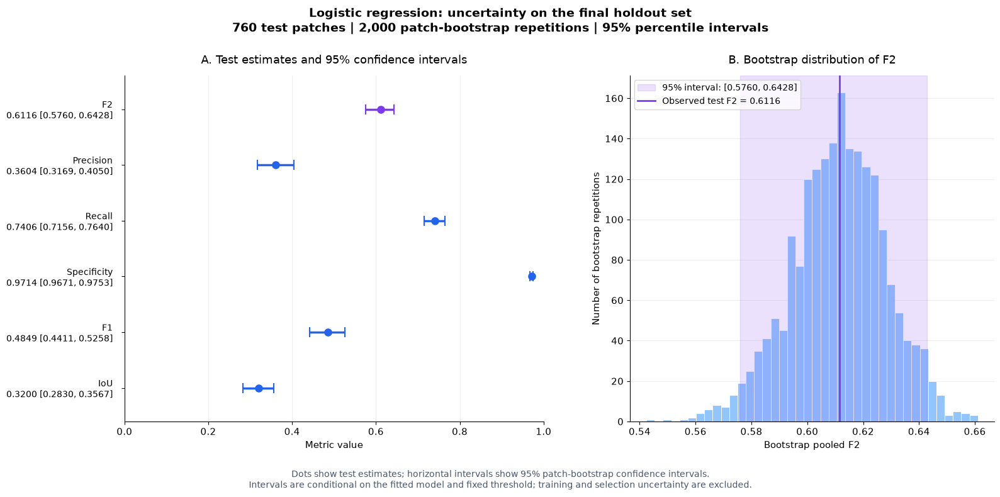

In [74]:
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Display the existing confidence intervals.
# No bootstrap recalculation and no additional dependencies.
# ------------------------------------------------------------
required_columns = [
    "Metric",
    "Test estimate",
    "95% CI lower",
    "95% CI upper",
    "CI width",
    "Bootstrap repetitions",
]

assert all(
    column in lr_test_bootstrap_ci.columns
    for column in required_columns
)

assert np.isfinite(
    lr_test_bootstrap_ci[
        [
            "Test estimate",
            "95% CI lower",
            "95% CI upper",
            "CI width",
        ]
    ].to_numpy(dtype=float)
).all()

lr_test_ci_display = lr_test_bootstrap_ci.copy()

for column in [
    "Test estimate",
    "95% CI lower",
    "95% CI upper",
    "CI width",
]:
    lr_test_ci_display[column] = (
        lr_test_ci_display[column]
        .map(lambda value: f"{value:.6f}")
    )

lr_test_ci_display["Bootstrap repetitions"] = (
    lr_test_ci_display["Bootstrap repetitions"]
    .map(lambda value: f"{int(value):,}")
)

print("Final holdout: 95% patch-bootstrap confidence intervals")
display(lr_test_ci_display)


# ------------------------------------------------------------
# 2. Prepare existing results for plotting.
# ------------------------------------------------------------
forest_metrics = [
    "F2",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "IoU",
]

ci_lookup = lr_test_bootstrap_ci.set_index("Metric")
forest_positions = np.arange(len(forest_metrics))

f2_estimate = float(
    ci_lookup.loc["F2", "Test estimate"]
)
f2_lower = float(
    ci_lookup.loc["F2", "95% CI lower"]
)
f2_upper = float(
    ci_lookup.loc["F2", "95% CI upper"]
)

repetitions = len(lr_test_bootstrap_scores)
test_patch_count = len(lr_test_patch_results)


# ------------------------------------------------------------
# 3. Draw both panels.
# ------------------------------------------------------------
with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, (ax_intervals, ax_distribution) = plt.subplots(
        1,
        2,
        figsize=(16, 8),
        gridspec_kw={"width_ratios": [1.15, 1]},
        layout="constrained",
    )

    fig.get_layout_engine().set(
        w_pad=0.15,
        h_pad=0.15,
        wspace=0.08,
    )

    fig.suptitle(
        "Logistic regression: uncertainty on the final holdout set\n"
        f"{test_patch_count:,} test patches | "
        f"{repetitions:,} patch-bootstrap repetitions | "
        "95% percentile intervals",
        fontsize=14,
        fontweight="bold",
    )

    forest_labels = []

    for position, metric in zip(
        forest_positions,
        forest_metrics,
    ):
        row = ci_lookup.loc[metric]

        estimate = float(row["Test estimate"])
        lower = float(row["95% CI lower"])
        upper = float(row["95% CI upper"])

        color = (
            "#7C3AED" if metric == "F2" else "#2563EB"
        )

        ax_intervals.hlines(
            position,
            lower,
            upper,
            color=color,
            linewidth=2.5,
        )

        ax_intervals.vlines(
            [lower, upper],
            position - 0.09,
            position + 0.09,
            color=color,
            linewidth=1.5,
        )

        ax_intervals.scatter(
            estimate,
            position,
            color=color,
            s=65,
            zorder=4,
        )

        forest_labels.append(
            f"{metric}\n"
            f"{estimate:.4f} [{lower:.4f}, {upper:.4f}]"
        )

    ax_intervals.set_yticks(forest_positions)
    ax_intervals.set_yticklabels(
        forest_labels,
        fontsize=10,
    )

    ax_intervals.set(
        xlim=(0, 1),
        ylim=(len(forest_metrics) - 0.4, -0.6),
        xlabel="Metric value",
    )

    ax_intervals.set_title(
        "A. Test estimates and 95% confidence intervals",
        pad=14,
    )

    ax_intervals.tick_params(axis="y", pad=10)
    ax_intervals.grid(axis="x", alpha=0.2)
    ax_intervals.set_axisbelow(True)

    ax_distribution.hist(
        lr_test_bootstrap_scores["F2"],
        bins=40,
        color="#93C5FD",
        edgecolor="white",
        linewidth=0.6,
    )

    ax_distribution.axvspan(
        f2_lower,
        f2_upper,
        color="#7C3AED",
        alpha=0.15,
        label=(
            f"95% interval: "
            f"[{f2_lower:.4f}, {f2_upper:.4f}]"
        ),
    )

    ax_distribution.axvline(
        f2_estimate,
        color="#7C3AED",
        linewidth=2,
        label=f"Observed test F2 = {f2_estimate:.4f}",
    )

    ax_distribution.set(
        xlabel="Bootstrap pooled F2",
        ylabel="Number of bootstrap repetitions",
    )

    ax_distribution.set_title(
        "B. Bootstrap distribution of F2",
        pad=14,
    )

    ax_distribution.grid(axis="y", alpha=0.2)
    ax_distribution.set_axisbelow(True)
    ax_distribution.legend(
        loc="best",
        fontsize=10,
        frameon=True,
    )

    for ax in (ax_intervals, ax_distribution):
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)

    fig.supxlabel(
        "Dots show test estimates; horizontal intervals show "
        "95% patch-bootstrap confidence intervals.\n"
        "Intervals are conditional on the fitted model and fixed "
        "threshold; training and selection uncertainty are excluded.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

The final holdout F2 was 0.61157, with a 95% patch-bootstrap confidence interval of [0.57600, 0.64278]. Recall was 0.74059 [0.71561, 0.76395], while precision was 0.36042 [0.31689, 0.40500], indicating that false positives remain a major limitation. Intervals were calculated from 2,000 whole-patch resamples with the fitted model and threshold fixed. They exclude training and selection uncertainty and unmeasured dependence between patches.

Final-test reliability by probability bin:


,Bin lower,Bin upper,Pixels,Landslide pixels,Mean probability,Observed frequency,Pixel share (%),Observed minus predicted
0,0.00000,0.05000,"11,603,528","45,015",0.00504,0.00388,93.187,-0.00116
1,0.05000,0.10000,"303,003","23,828",0.06969,0.07864,2.433,0.00895
2,0.10000,0.15000,"114,869","16,931",0.12219,0.14739,0.923,0.02520
3,0.15000,0.20000,"67,978","13,680",0.17336,0.20124,0.546,0.02788
4,0.20000,0.25000,"48,734","11,732",0.22375,0.24074,0.391,0.01698
5,0.25000,0.30000,"38,224","10,506",0.27414,0.27485,0.307,0.00071
6,0.30000,0.35000,"31,503","9,630",0.32423,0.30569,0.253,-0.01855
7,0.35000,0.40000,"26,217","8,993",0.37424,0.34302,0.211,-0.03122
8,0.40000,0.45000,"22,867","8,506",0.42440,0.37198,0.184,-0.05243
9,0.45000,0.50000,"20,080","8,190",0.47465,0.40787,0.161,-0.06678



Probability scores — lower is better:


,Score,Final model,Constant test-prevalence reference
0,Brier score,0.014044,0.020858
1,Log loss,0.053596,0.103104



Descriptive ECE with 20 equal-width bins: 0.004243


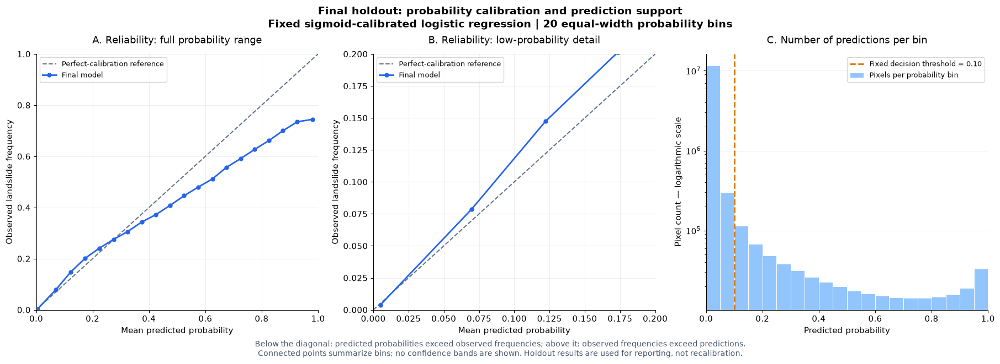

In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Use cached final-test probabilities.
# No fitting, calibration, or threshold changes.
# ------------------------------------------------------------
test_probabilities = np.asarray(
    lr_test_probability,
    dtype=np.float64,
)
test_reference = np.asarray(
    lr_test_y,
    dtype=np.uint8,
)

assert test_probabilities.shape == test_reference.shape
assert np.isfinite(test_probabilities).all()
assert (
    (test_probabilities >= 0)
    & (test_probabilities <= 1)
).all()
assert np.isin(test_reference, [0, 1]).all()

# Twenty equal-width bins, each covering probability width 0.05.
LR_TEST_CALIBRATION_BINS = 20

bin_edges = np.linspace(
    0.0,
    1.0,
    LR_TEST_CALIBRATION_BINS + 1,
)

bin_indices = np.searchsorted(
    bin_edges,
    test_probabilities,
    side="right",
) - 1

# Include probability 1.0 in the last bin.
bin_indices = np.clip(
    bin_indices,
    0,
    LR_TEST_CALIBRATION_BINS - 1,
)

bin_counts = np.bincount(
    bin_indices,
    minlength=LR_TEST_CALIBRATION_BINS,
)

bin_probability_sums = np.bincount(
    bin_indices,
    weights=test_probabilities,
    minlength=LR_TEST_CALIBRATION_BINS,
)

bin_positive_counts = np.bincount(
    bin_indices,
    weights=test_reference,
    minlength=LR_TEST_CALIBRATION_BINS,
)

mean_probabilities = np.divide(
    bin_probability_sums,
    bin_counts,
    out=np.full(LR_TEST_CALIBRATION_BINS, np.nan),
    where=bin_counts > 0,
)

observed_frequencies = np.divide(
    bin_positive_counts,
    bin_counts,
    out=np.full(LR_TEST_CALIBRATION_BINS, np.nan),
    where=bin_counts > 0,
)

lr_test_reliability = pd.DataFrame({
    "Bin lower": bin_edges[:-1],
    "Bin upper": bin_edges[1:],
    "Pixels": bin_counts,
    "Landslide pixels": bin_positive_counts.astype(np.int64),
    "Mean probability": mean_probabilities,
    "Observed frequency": observed_frequencies,
})

lr_test_reliability["Pixel share (%)"] = (
    100 * bin_counts / len(test_reference)
)

lr_test_reliability["Observed minus predicted"] = (
    observed_frequencies - mean_probabilities
)

assert int(bin_counts.sum()) == len(test_reference)

nonempty_bins = lr_test_reliability.loc[
    lr_test_reliability["Pixels"] > 0
].copy()

# Descriptive ECE for this particular binning.
lr_test_ece_20_bins = float(
    np.sum(
        nonempty_bins["Pixels"].to_numpy()
        / len(test_reference)
        * np.abs(
            nonempty_bins["Observed minus predicted"].to_numpy()
        )
    )
)

# Constant-probability references at the observed test prevalence.
# These are descriptive references, not newly fitted models.
test_prevalence = float(test_reference.mean())
assert 0 < test_prevalence < 1

lr_test_probability_references = pd.DataFrame({
    "Score": ["Brier score", "Log loss"],
    "Final model": [
        float(lr_test_metrics["Brier score"]),
        float(lr_test_metrics["Log loss"]),
    ],
    "Constant test-prevalence reference": [
        test_prevalence * (1 - test_prevalence),
        -(
            test_prevalence * np.log(test_prevalence)
            + (1 - test_prevalence)
            * np.log1p(-test_prevalence)
        ),
    ],
})


# ------------------------------------------------------------
# 2. Display numeric results without optional styling packages.
# ------------------------------------------------------------
reliability_display = lr_test_reliability.copy()

for column in [
    "Bin lower",
    "Bin upper",
    "Mean probability",
    "Observed frequency",
    "Observed minus predicted",
]:
    reliability_display[column] = (
        reliability_display[column]
        .map(
            lambda value: (
                "—" if pd.isna(value)
                else f"{value:.5f}"
            )
        )
    )

for column in ["Pixels", "Landslide pixels"]:
    reliability_display[column] = (
        reliability_display[column]
        .map(lambda value: f"{int(value):,}")
    )

reliability_display["Pixel share (%)"] = (
    reliability_display["Pixel share (%)"]
    .map(lambda value: f"{value:.3f}")
)

print("Final-test reliability by probability bin:")
display(reliability_display)

print("\nProbability scores — lower is better:")
display(lr_test_probability_references.round(6))

print(
    "\nDescriptive ECE with 20 equal-width bins: "
    f"{lr_test_ece_20_bins:.6f}"
)


# ------------------------------------------------------------
# 3. Plot reliability and prediction support.
# ------------------------------------------------------------
with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 6.5),
        layout="constrained",
    )

    fig.suptitle(
        "Final holdout: probability calibration and prediction support\n"
        "Fixed sigmoid-calibrated logistic regression | "
        "20 equal-width probability bins",
        fontsize=14,
        fontweight="bold",
    )

    for ax in axes[:2]:
        ax.plot(
            [0, 1],
            [0, 1],
            linestyle="--",
            color="#64748B",
            linewidth=1.5,
            label="Perfect-calibration reference",
        )

        ax.plot(
            nonempty_bins["Mean probability"],
            nonempty_bins["Observed frequency"],
            marker="o",
            markersize=5,
            linewidth=2,
            color="#2563EB",
            label="Final model",
        )

        ax.set_xlabel("Mean predicted probability")
        ax.set_ylabel("Observed landslide frequency")
        ax.grid(alpha=0.2)
        ax.set_axisbelow(True)

    axes[0].set_title(
        "A. Reliability: full probability range",
        pad=14,
    )
    axes[0].set_xlim(0, 1)
    axes[0].set_ylim(0, 1)
    axes[0].legend(loc="upper left", fontsize=9)

    axes[1].set_title(
        "B. Reliability: low-probability detail",
        pad=14,
    )
    axes[1].set_xlim(0, 0.20)
    axes[1].set_ylim(0, 0.20)
    axes[1].legend(loc="upper left", fontsize=9)

    # Draw only nonempty bins on a logarithmic count axis.
    axes[2].bar(
        nonempty_bins["Bin lower"],
        nonempty_bins["Pixels"],
        width=1 / LR_TEST_CALIBRATION_BINS,
        align="edge",
        color="#93C5FD",
        edgecolor="white",
        linewidth=0.7,
        label="Pixels per probability bin",
    )

    axes[2].axvline(
        lr_final_threshold,
        color="#D97706",
        linestyle="--",
        linewidth=2,
        label=f"Fixed decision threshold = {lr_final_threshold:.2f}",
    )

    axes[2].set_yscale("log")
    axes[2].set_xlim(0, 1)
    axes[2].set_xlabel("Predicted probability")
    axes[2].set_ylabel("Pixel count — logarithmic scale")
    axes[2].set_title(
        "C. Number of predictions per bin",
        pad=14,
    )
    axes[2].legend(loc="upper right", fontsize=9)
    axes[2].grid(axis="y", alpha=0.2)
    axes[2].set_axisbelow(True)

    for ax in axes:
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)

    fig.supxlabel(
        "Below the diagonal: predicted probabilities exceed observed "
        "frequencies; above it: observed frequencies exceed predictions.\n"
        "Connected points summarize bins; no confidence bands are shown. "
        "Holdout results are used for reporting, not recalibration.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

del bin_indices

Holdout reliability analysis shows that predicted probabilities are not uniformly calibrated. The model slightly underestimates landslide frequency in several low-to-moderate probability bins and overestimates it at higher probabilities. In the highest bin, mean predicted probability was 0.97972, while observed landslide frequency was 0.74438. The small binned ECE (0.004243) is dominated by the 93.19% of pixels in the lowest-probability bin and does not imply good calibration throughout the probability range. Brier score and log loss were better than a constant test-prevalence reference. These findings are descriptive; the model and threshold remain unchanged.
ECE summarizes the pixel-count-weighted absolute difference between mean predicted probability and observed landslide frequency across bins. Here, ECE = 0.004243, or approximately 0.4243 percentage points. This small overall value does not rule out substantial miscalibration in high-probability bins. 
ECE is Expected Calibration Error.

Selected final-test examples:


,Selection,sample_id,Landslide coverage (%),TP,FP,FN,IoU
0,Near median positive-patch IoU,105,5.60303,680,1064,238,0.34309
1,Lowest IoU among patches with 0–1% landslide c...,2684,0.74463,0,107,122,0.00000
2,Most false-positive pixels in a negative patch,3459,0.00000,0,9507,0,0.00000


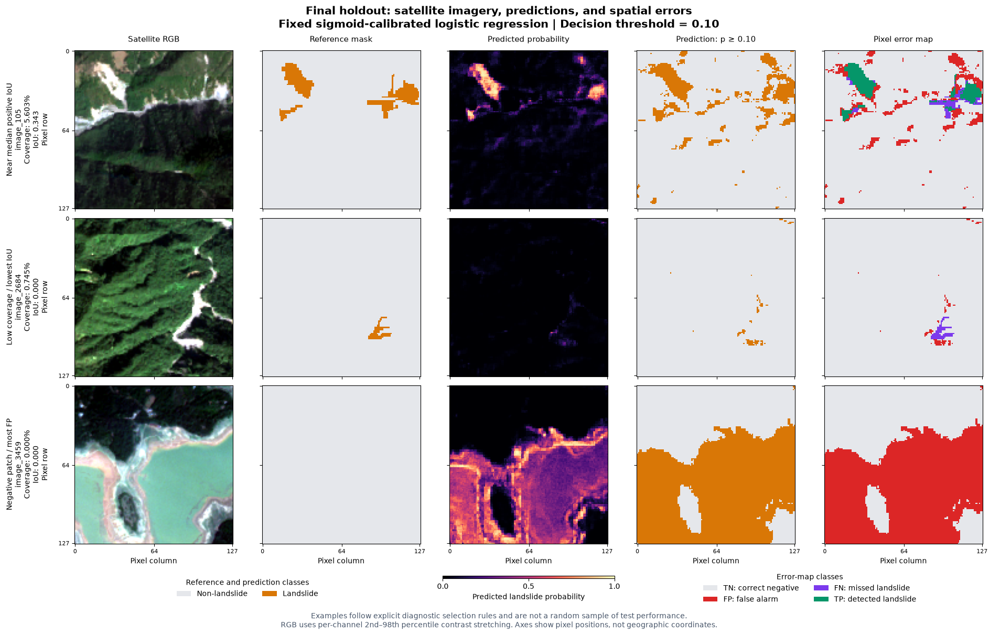

In [76]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


# ------------------------------------------------------------
# 1. Select test examples using explicit, reproducible criteria.
# ------------------------------------------------------------
test_patch_table = lr_test_patch_results.copy()
test_patch_table["sample_id"] = (
    test_patch_table["sample_id"].astype(str)
)

positive_test_patches = test_patch_table.loc[
    test_patch_table["Positive pixels"] > 0
].copy()

negative_test_patches = test_patch_table.loc[
    test_patch_table["Positive pixels"] == 0
].copy()

assert not positive_test_patches.empty
assert not negative_test_patches.empty

median_positive_iou = float(
    positive_test_patches["IoU"].median()
)

positive_test_patches["Distance from median IoU"] = (
    positive_test_patches["IoU"] - median_positive_iou
).abs()

median_example = (
    positive_test_patches
    .sort_values(
        ["Distance from median IoU", "sample_id"],
        kind="mergesort",
    )
    .iloc[0]
    .copy()
)
median_example["Selection"] = "Near median positive-patch IoU"

small_coverage_candidates = positive_test_patches.loc[
    positive_test_patches["Landslide coverage (%)"].le(1.0)
    & positive_test_patches["sample_id"].ne(
        median_example["sample_id"]
    )
].copy()

assert not small_coverage_candidates.empty, (
    "No distinct positive patch with coverage <= 1% is available."
)

small_coverage_example = (
    small_coverage_candidates
    .sort_values(
        ["IoU", "FN", "sample_id"],
        ascending=[True, False, True],
        kind="mergesort",
    )
    .iloc[0]
    .copy()
)
small_coverage_example["Selection"] = (
    "Lowest IoU among patches with 0–1% landslide coverage"
)

false_alarm_example = (
    negative_test_patches
    .sort_values(
        ["FP", "sample_id"],
        ascending=[False, True],
        kind="mergesort",
    )
    .iloc[0]
    .copy()
)
false_alarm_example["Selection"] = (
    "Most false-positive pixels in a negative patch"
)

lr_test_visual_examples = pd.DataFrame([
    median_example,
    small_coverage_example,
    false_alarm_example,
]).reset_index(drop=True)

assert lr_test_visual_examples["sample_id"].is_unique

print("Selected final-test examples:")
display(
    lr_test_visual_examples[
        [
            "Selection",
            "sample_id",
            "Landslide coverage (%)",
            "TP",
            "FP",
            "FN",
            "IoU",
        ]
    ].round(5)
)


# ------------------------------------------------------------
# 2. Prepare display colors and RGB contrast stretching.
# ------------------------------------------------------------
class_colors = ["#E5E7EB", "#D97706"]
class_cmap = ListedColormap(class_colors)
class_norm = BoundaryNorm([-0.5, 0.5, 1.5], 2)

error_colors = [
    "#E5E7EB",  # 0: TN
    "#DC2626",  # 1: FP
    "#7C3AED",  # 2: FN
    "#059669",  # 3: TP
]
error_cmap = ListedColormap(error_colors)
error_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    4,
)


def make_test_rgb_display(image_array):
    """B4/B3/B2 display with per-channel percentile stretching."""
    rgb = np.asarray(
        image_array[:, :, [3, 2, 1]],
        dtype=np.float64,
    )

    lower = np.percentile(rgb, 2, axis=(0, 1))
    upper = np.percentile(rgb, 98, axis=(0, 1))

    denominator = np.maximum(upper - lower, 1e-12)

    return np.clip(
        (rgb - lower) / denominator,
        0,
        1,
    )


# ------------------------------------------------------------
# 3. Plot three rows and five aligned image panels.
# Dedicated bottom areas hold legends and the probability scale.
# ------------------------------------------------------------
with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig = plt.figure(
        figsize=(19, 12),
        layout="constrained",
    )

    grid = fig.add_gridspec(
        4,
        5,
        height_ratios=[1, 1, 1, 0.24],
    )

    column_titles = [
        "Satellite RGB",
        "Reference mask",
        "Predicted probability",
        f"Prediction: p ≥ {lr_final_threshold:.2f}",
        "Pixel error map",
    ]

    row_labels = [
        "Near median positive IoU",
        "Low coverage / lowest IoU",
        "Negative patch / most FP",
    ]

    probability_image = None

    for row_number, example in lr_test_visual_examples.iterrows():
        sample_id = str(example["sample_id"])

        assert sample_id in set(lr_test_patch_ids)

        image_path = (
            DATA_DIR
            / "TrainData"
            / "img"
            / f"image_{sample_id}.h5"
        )

        with h5py.File(image_path, "r") as image_file:
            image_array = np.asarray(
                image_file["img"],
                dtype=np.float32,
            )

        start = int(example["Start"])
        stop = int(example["Stop"])

        reference = lr_test_y[start:stop].reshape(128, 128)
        probability = (
            lr_test_probability[start:stop]
            .reshape(128, 128)
        )
        prediction = (
            probability >= lr_final_threshold
        ).astype(np.uint8)

        # 0=TN, 1=FP, 2=FN, 3=TP.
        error_map = 2 * reference + prediction

        assert np.count_nonzero(error_map == 0) == int(
            example["TN"]
        )
        assert np.count_nonzero(error_map == 1) == int(
            example["FP"]
        )
        assert np.count_nonzero(error_map == 2) == int(
            example["FN"]
        )
        assert np.count_nonzero(error_map == 3) == int(
            example["TP"]
        )

        row_axes = [
            fig.add_subplot(grid[row_number, column])
            for column in range(5)
        ]

        row_axes[0].imshow(make_test_rgb_display(image_array))
        row_axes[1].imshow(
            reference,
            cmap=class_cmap,
            norm=class_norm,
            interpolation="nearest",
        )
        probability_image = row_axes[2].imshow(
            probability,
            cmap="magma",
            vmin=0,
            vmax=1,
            interpolation="nearest",
        )
        row_axes[3].imshow(
            prediction,
            cmap=class_cmap,
            norm=class_norm,
            interpolation="nearest",
        )
        row_axes[4].imshow(
            error_map,
            cmap=error_cmap,
            norm=error_norm,
            interpolation="nearest",
        )

        for column, ax in enumerate(row_axes):
            if row_number == 0:
                ax.set_title(
                    column_titles[column],
                    fontsize=11,
                    pad=12,
                )

            ax.set_xticks([0, 64, 127])
            ax.set_yticks([0, 64, 127])
            ax.tick_params(labelsize=8)

            if column != 0:
                ax.tick_params(labelleft=False)

            if row_number == 2:
                ax.set_xlabel("Pixel column")
            else:
                ax.tick_params(labelbottom=False)

        row_axes[0].set_ylabel(
            f"{row_labels[row_number]}\n"
            f"image_{sample_id}\n"
            f"Coverage: {example['Landslide coverage (%)']:.3f}%\n"
            f"IoU: {example['IoU']:.3f}\n"
            "Pixel row",
            fontsize=10,
            labelpad=12,
        )

    # Class legend for reference and prediction masks.
    class_legend_ax = fig.add_subplot(grid[3, 0:2])
    class_legend_ax.axis("off")
    class_legend_ax.legend(
        handles=[
            Patch(
                facecolor=class_colors[0],
                label="Non-landslide",
            ),
            Patch(
                facecolor=class_colors[1],
                label="Landslide",
            ),
        ],
        loc="center",
        ncol=2,
        frameon=False,
        title="Reference and prediction classes",
        fontsize=10,
    )

    # Shared probability scale, fixed at 0–1.
    colorbar_area = grid[3, 2].subgridspec(
        3,
        1,
        height_ratios=[1, 0.35, 1],
    )
    colorbar_ax = fig.add_subplot(colorbar_area[1, 0])

    colorbar = fig.colorbar(
        probability_image,
        cax=colorbar_ax,
        orientation="horizontal",
    )
    colorbar.set_ticks([0, 0.5, 1])
    colorbar.set_label("Predicted landslide probability")

    # Dedicated error legend.
    error_legend_ax = fig.add_subplot(grid[3, 3:5])
    error_legend_ax.axis("off")
    error_legend_ax.legend(
        handles=[
            Patch(facecolor=error_colors[0], label="TN: correct negative"),
            Patch(facecolor=error_colors[1], label="FP: false alarm"),
            Patch(facecolor=error_colors[2], label="FN: missed landslide"),
            Patch(facecolor=error_colors[3], label="TP: detected landslide"),
        ],
        loc="center",
        ncol=2,
        frameon=False,
        title="Error-map classes",
        fontsize=10,
    )

    fig.suptitle(
        "Final holdout: satellite imagery, predictions, and spatial errors\n"
        "Fixed sigmoid-calibrated logistic regression | "
        f"Decision threshold = {lr_final_threshold:.2f}",
        fontsize=15,
        fontweight="bold",
    )

    fig.supxlabel(
        "Examples follow explicit diagnostic selection rules and are "
        "not a random sample of test performance.\n"
        "RGB uses per-channel 2nd–98th percentile contrast stretching. "
        "Axes show pixel positions, not geographic coordinates.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

Spatial error analysis revealed both missed landslide pixels and extensive false positives. Image 105, selected near the median positive-patch IoU, contained 680 true positives, 1,064 false positives, and 238 false negatives (IoU = 0.34309). In low-coverage image 2684, all 122 reference landslide pixels were missed, while 107 other pixels were incorrectly flagged. In negative image 3459, 9,507 pixels—58.03% of the patch—were falsely classified as landslide. These deliberately selected diagnostic examples illustrate limitations rather than represent average test performance. The model and threshold remain unchanged.

Additional holdout examples:


,Selection,sample_id,Landslide coverage (%),TP,FP,FN,Precision,Recall,IoU
0,Random positive patch 1,1535,6.06079,849,282,144,0.75066,0.85498,0.66588
1,Random positive patch 2,590,9.42993,1087,520,458,0.67642,0.70356,0.52639
2,Random negative patch,3316,0.00000,0,20,0,0.00000,NaN,0.00000


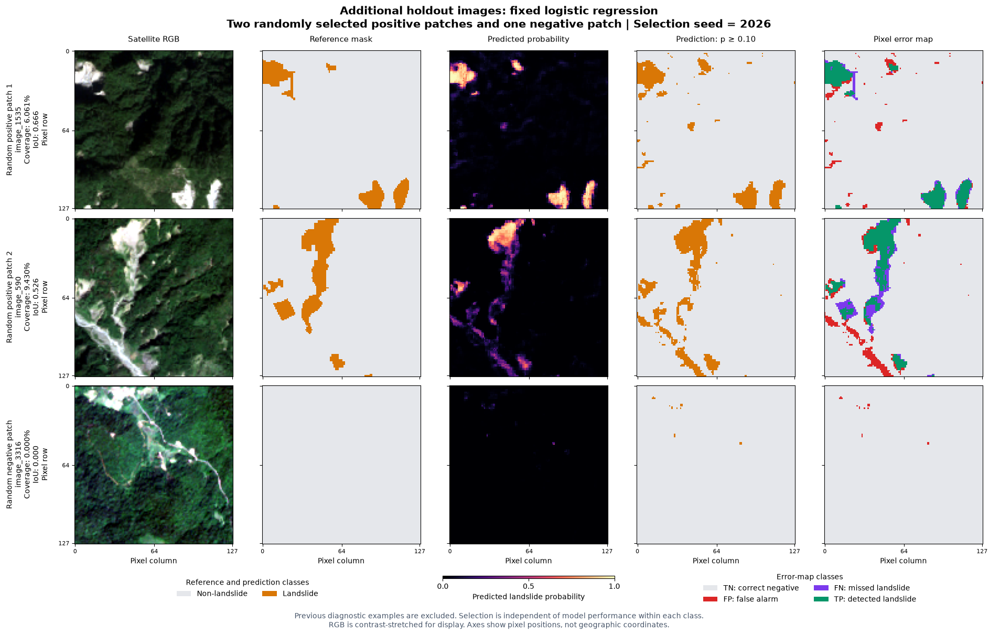

In [77]:
#Another satellite images
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


# ------------------------------------------------------------
# 1. Select three different test images.
# Selection uses reference class presence, not model performance.
# ------------------------------------------------------------
ADDITIONAL_EXAMPLE_SEED = 2026

previous_example_ids = set(
    lr_test_visual_examples["sample_id"].astype(str)
)

available_examples = lr_test_patch_results.copy()
available_examples["sample_id"] = (
    available_examples["sample_id"].astype(str)
)

available_examples = (
    available_examples.loc[
        ~available_examples["sample_id"].isin(
            previous_example_ids
        )
    ]
    .sort_values("sample_id")
)

positive_candidates = available_examples.loc[
    available_examples["Positive pixels"] > 0
]

negative_candidates = available_examples.loc[
    available_examples["Positive pixels"] == 0
]

assert len(positive_candidates) >= 2
assert len(negative_candidates) >= 1

example_rng = np.random.default_rng(
    ADDITIONAL_EXAMPLE_SEED
)

selected_positive_positions = example_rng.choice(
    len(positive_candidates),
    size=2,
    replace=False,
)

selected_negative_positions = example_rng.choice(
    len(negative_candidates),
    size=1,
    replace=False,
)

lr_test_additional_examples = pd.concat(
    [
        positive_candidates.iloc[
            selected_positive_positions
        ],
        negative_candidates.iloc[
            selected_negative_positions
        ],
    ],
    ignore_index=True,
).copy()

lr_test_additional_examples["Selection"] = [
    "Random positive patch 1",
    "Random positive patch 2",
    "Random negative patch",
]

assert lr_test_additional_examples["sample_id"].is_unique
assert set(
    lr_test_additional_examples["sample_id"]
).isdisjoint(previous_example_ids)

print("Additional holdout examples:")
display(
    lr_test_additional_examples[
        [
            "Selection",
            "sample_id",
            "Landslide coverage (%)",
            "TP",
            "FP",
            "FN",
            "Precision",
            "Recall",
            "IoU",
        ]
    ].round(5)
)


# ------------------------------------------------------------
# 2. Display colors and RGB preparation.
# ------------------------------------------------------------
class_colors = ["#E5E7EB", "#D97706"]
class_cmap = ListedColormap(class_colors)
class_norm = BoundaryNorm([-0.5, 0.5, 1.5], 2)

error_colors = [
    "#E5E7EB",  # TN
    "#DC2626",  # FP
    "#7C3AED",  # FN
    "#059669",  # TP
]

error_cmap = ListedColormap(error_colors)
error_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    4,
)


def additional_rgb_display(image_array):
    rgb = np.asarray(
        image_array[:, :, [3, 2, 1]],
        dtype=np.float64,
    )

    lower = np.percentile(rgb, 2, axis=(0, 1))
    upper = np.percentile(rgb, 98, axis=(0, 1))

    return np.clip(
        (rgb - lower) / np.maximum(upper - lower, 1e-12),
        0,
        1,
    )


# ------------------------------------------------------------
# 3. Show cached predictions for the additional images.
# ------------------------------------------------------------
with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig = plt.figure(
        figsize=(19, 12),
        layout="constrained",
    )

    grid = fig.add_gridspec(
        4,
        5,
        height_ratios=[1, 1, 1, 0.24],
    )

    column_titles = [
        "Satellite RGB",
        "Reference mask",
        "Predicted probability",
        f"Prediction: p ≥ {lr_final_threshold:.2f}",
        "Pixel error map",
    ]

    probability_image = None

    for row_number, example in (
        lr_test_additional_examples.iterrows()
    ):
        sample_id = str(example["sample_id"])

        assert sample_id in set(lr_test_patch_ids)

        image_path = (
            DATA_DIR
            / "TrainData"
            / "img"
            / f"image_{sample_id}.h5"
        )

        with h5py.File(image_path, "r") as image_file:
            image_array = np.asarray(
                image_file["img"],
                dtype=np.float32,
            )

        start = int(example["Start"])
        stop = int(example["Stop"])

        reference = lr_test_y[start:stop].reshape(128, 128)
        probability = (
            lr_test_probability[start:stop]
            .reshape(128, 128)
        )

        prediction = (
            probability >= lr_final_threshold
        ).astype(np.uint8)

        error_map = 2 * reference + prediction

        # Confirm agreement with the stored evaluation.
        for code, count_name in enumerate(
            ["TN", "FP", "FN", "TP"]
        ):
            assert int(
                np.count_nonzero(error_map == code)
            ) == int(example[count_name])

        row_axes = [
            fig.add_subplot(grid[row_number, column])
            for column in range(5)
        ]

        row_axes[0].imshow(
            additional_rgb_display(image_array)
        )
        row_axes[1].imshow(
            reference,
            cmap=class_cmap,
            norm=class_norm,
            interpolation="nearest",
        )
        probability_image = row_axes[2].imshow(
            probability,
            cmap="magma",
            vmin=0,
            vmax=1,
            interpolation="nearest",
        )
        row_axes[3].imshow(
            prediction,
            cmap=class_cmap,
            norm=class_norm,
            interpolation="nearest",
        )
        row_axes[4].imshow(
            error_map,
            cmap=error_cmap,
            norm=error_norm,
            interpolation="nearest",
        )

        for column, ax in enumerate(row_axes):
            if row_number == 0:
                ax.set_title(
                    column_titles[column],
                    fontsize=11,
                    pad=12,
                )

            ax.set_xticks([0, 64, 127])
            ax.set_yticks([0, 64, 127])
            ax.tick_params(labelsize=8)

            if column != 0:
                ax.tick_params(labelleft=False)

            if row_number == 2:
                ax.set_xlabel("Pixel column")
            else:
                ax.tick_params(labelbottom=False)

        row_axes[0].set_ylabel(
            f"{example['Selection']}\n"
            f"image_{sample_id}\n"
            f"Coverage: "
            f"{example['Landslide coverage (%)']:.3f}%\n"
            f"IoU: {example['IoU']:.3f}\n"
            "Pixel row",
            fontsize=10,
            labelpad=12,
        )

    class_legend_ax = fig.add_subplot(grid[3, 0:2])
    class_legend_ax.axis("off")
    class_legend_ax.legend(
        handles=[
            Patch(
                facecolor=class_colors[0],
                label="Non-landslide",
            ),
            Patch(
                facecolor=class_colors[1],
                label="Landslide",
            ),
        ],
        loc="center",
        ncol=2,
        frameon=False,
        title="Reference and prediction classes",
    )

    colorbar_area = grid[3, 2].subgridspec(
        3,
        1,
        height_ratios=[1, 0.35, 1],
    )
    colorbar_ax = fig.add_subplot(colorbar_area[1, 0])

    colorbar = fig.colorbar(
        probability_image,
        cax=colorbar_ax,
        orientation="horizontal",
    )
    colorbar.set_ticks([0, 0.5, 1])
    colorbar.set_label("Predicted landslide probability")

    error_legend_ax = fig.add_subplot(grid[3, 3:5])
    error_legend_ax.axis("off")
    error_legend_ax.legend(
        handles=[
            Patch(
                facecolor=error_colors[0],
                label="TN: correct negative",
            ),
            Patch(
                facecolor=error_colors[1],
                label="FP: false alarm",
            ),
            Patch(
                facecolor=error_colors[2],
                label="FN: missed landslide",
            ),
            Patch(
                facecolor=error_colors[3],
                label="TP: detected landslide",
            ),
        ],
        loc="center",
        ncol=2,
        frameon=False,
        title="Error-map classes",
    )

    fig.suptitle(
        "Additional holdout images: fixed logistic regression\n"
        "Two randomly selected positive patches and one negative patch | "
        f"Selection seed = {ADDITIONAL_EXAMPLE_SEED}",
        fontsize=15,
        fontweight="bold",
    )

    fig.supxlabel(
        "Previous diagnostic examples are excluded. "
        "Selection is independent of model performance within each class.\n"
        "RGB is contrast-stretched for display. "
        "Axes show pixel positions, not geographic coordinates.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

Additional holdout examples show variable spatial performance. Image 1535 achieved recall of 0.85498 and IoU of 0.66588, while image 590 achieved recall of 0.70356 and IoU of 0.52639. The negative image 3316 contained only 20 false-positive pixels (approximately 0.12% of the patch). Its recall is undefined because no reference-positive pixels exist; its zero IoU reflects false positives rather than failure across the entire image. These examples supplement, rather than replace, the aggregate holdout evaluation.

Pooled test metrics within each reference-coverage group:


,Coverage group,Patches,Positive pixels,Precision,Recall,F2,IoU,False-positive rate (%)
0,No landslide,314,0,0.00000,NaN,0.00000,0.00000,2.43418
1,>0–1%,158,11224,0.10619,0.61128,0.31326,0.09947,2.24067
2,>1–5%,183,76306,0.37736,0.68098,0.58659,0.32067,2.93422
3,>5–15%,92,128536,0.59093,0.73970,0.70424,0.48920,4.77360
4,>15–100%,13,49315,0.74968,0.86456,0.83886,0.67089,8.69762



False alarms in reference-negative patches:


,Measure,Value
0,Reference-negative patches,314.00000
1,Negative patches with at least one false-posit...,260.00000
2,Negative patches with any false positive (%),82.80255
3,Median false-positive area per negative patch (%),0.25024
4,Pooled false-positive pixel area (%),2.43418


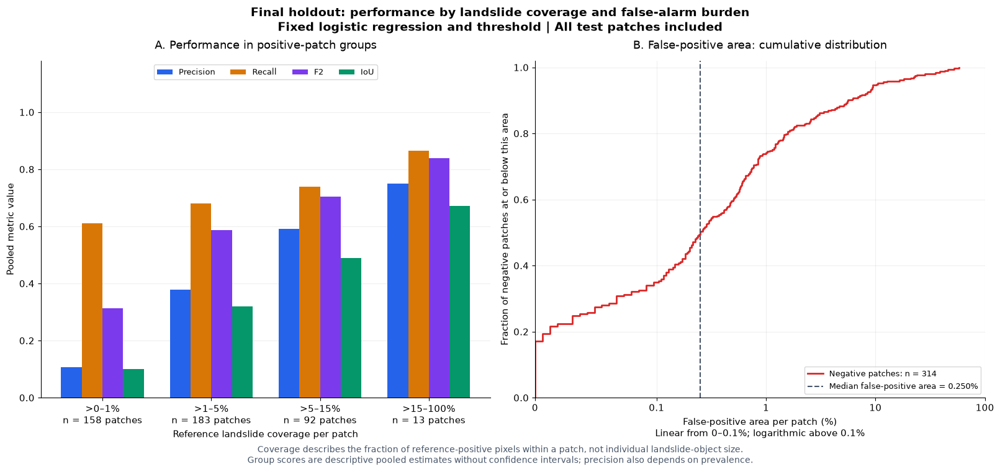

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Group every holdout patch by reference landslide coverage.
# Reuse the coverage boundaries from the development analysis.
# ------------------------------------------------------------
lr_test_coverage_analysis = lr_test_patch_results.copy()

coverage_labels = [
    "No landslide",
    ">0–1%",
    ">1–5%",
    ">5–15%",
    ">15–100%",
]

lr_test_coverage_analysis["Coverage group"] = pd.cut(
    lr_test_coverage_analysis["Landslide coverage (%)"],
    bins=[-0.001, 0, 1, 5, 15, 100],
    labels=coverage_labels,
    right=True,
    include_lowest=True,
)

assert lr_test_coverage_analysis["Coverage group"].notna().all()

coverage_records = []

for group_label in coverage_labels:
    subset = lr_test_coverage_analysis.loc[
        lr_test_coverage_analysis["Coverage group"].eq(group_label)
    ]

    if subset.empty:
        continue

    counts = (
        subset[["TN", "FP", "FN", "TP"]]
        .sum()
        .astype(np.int64)
    )

    scores = metrics_from_counts(
        int(counts["TN"]),
        int(counts["FP"]),
        int(counts["FN"]),
        int(counts["TP"]),
    )

    negative_pixel_count = int(
        counts["TN"] + counts["FP"]
    )

    coverage_records.append({
        "Coverage group": group_label,
        "Patches": len(subset),
        "Pixels": int(subset["Pixels"].sum()),
        "Positive pixels": int(
            subset["Positive pixels"].sum()
        ),
        "False-positive rate (%)": (
            100 * counts["FP"] / negative_pixel_count
            if negative_pixel_count > 0
            else np.nan
        ),
        **scores,
    })

lr_test_coverage_summary = pd.DataFrame(
    coverage_records
)

assert (
    lr_test_coverage_summary["Patches"].sum()
    == len(lr_test_patch_results)
)

print(
    "Pooled test metrics within each reference-coverage group:"
)

display(
    lr_test_coverage_summary[
        [
            "Coverage group",
            "Patches",
            "Positive pixels",
            "Precision",
            "Recall",
            "F2",
            "IoU",
            "False-positive rate (%)",
        ]
    ].round(5)
)


# ------------------------------------------------------------
# 2. Quantify false alarms in all reference-negative patches.
# ------------------------------------------------------------
lr_test_negative_patch_analysis = (
    lr_test_coverage_analysis.loc[
        lr_test_coverage_analysis["Positive pixels"].eq(0)
    ]
    .copy()
)

assert not lr_test_negative_patch_analysis.empty

lr_test_negative_patch_analysis["False-positive area (%)"] = (
    100
    * lr_test_negative_patch_analysis["FP"]
    / lr_test_negative_patch_analysis["Pixels"]
)

negative_patch_count = len(
    lr_test_negative_patch_analysis
)

negative_patches_with_fp = int(
    lr_test_negative_patch_analysis["FP"].gt(0).sum()
)

lr_test_negative_summary = pd.DataFrame({
    "Measure": [
        "Reference-negative patches",
        "Negative patches with at least one false-positive pixel",
        "Negative patches with any false positive (%)",
        "Median false-positive area per negative patch (%)",
        "Pooled false-positive pixel area (%)",
    ],
    "Value": [
        negative_patch_count,
        negative_patches_with_fp,
        100 * negative_patches_with_fp / negative_patch_count,
        float(
            lr_test_negative_patch_analysis[
                "False-positive area (%)"
            ].median()
        ),
        float(
            100
            * lr_test_negative_patch_analysis["FP"].sum()
            / lr_test_negative_patch_analysis["Pixels"].sum()
        ),
    ],
})

print("\nFalse alarms in reference-negative patches:")
display(lr_test_negative_summary.round(5))


# ------------------------------------------------------------
# 3. Plot coverage-group performance and negative-patch errors.
# ------------------------------------------------------------
positive_coverage_summary = (
    lr_test_coverage_summary.loc[
        lr_test_coverage_summary["Coverage group"].ne(
            "No landslide"
        )
    ]
    .copy()
    .reset_index(drop=True)
)

metric_colors = {
    "Precision": "#2563EB",
    "Recall": "#D97706",
    "F2": "#7C3AED",
    "IoU": "#059669",
}

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 7.5),
        layout="constrained",
    )

    fig.suptitle(
        "Final holdout: performance by landslide coverage "
        "and false-alarm burden\n"
        "Fixed logistic regression and threshold | "
        "All test patches included",
        fontsize=14,
        fontweight="bold",
    )

    x_positions = np.arange(
        len(positive_coverage_summary)
    )
    bar_width = 0.19

    for metric_number, (metric, color) in enumerate(
        metric_colors.items()
    ):
        offset = (metric_number - 1.5) * bar_width

        axes[0].bar(
            x_positions + offset,
            positive_coverage_summary[metric],
            width=bar_width,
            color=color,
            label=metric,
        )

    group_tick_labels = [
        f"{row['Coverage group']}\n"
        f"n = {int(row['Patches']):,} patches"
        for _, row in positive_coverage_summary.iterrows()
    ]

    axes[0].set_xticks(x_positions)
    axes[0].set_xticklabels(group_tick_labels)
    axes[0].set_ylim(0, 1.18)
    axes[0].set_yticks(np.arange(0, 1.01, 0.2))
    axes[0].set_xlabel("Reference landslide coverage per patch")
    axes[0].set_ylabel("Pooled metric value")
    axes[0].set_title(
        "A. Performance in positive-patch groups",
        pad=14,
    )
    axes[0].legend(
        loc="upper center",
        ncol=4,
        fontsize=9,
        frameon=True,
    )
    axes[0].grid(axis="y", alpha=0.2)
    axes[0].set_axisbelow(True)

    false_positive_areas = np.sort(
        lr_test_negative_patch_analysis[
            "False-positive area (%)"
        ].to_numpy()
    )

    cumulative_fraction = (
        np.arange(1, negative_patch_count + 1)
        / negative_patch_count
    )

    axes[1].step(
        false_positive_areas,
        cumulative_fraction,
        where="post",
        color="#DC2626",
        linewidth=2,
        label=f"Negative patches: n = {negative_patch_count:,}",
    )

    median_fp_area = float(
        np.median(false_positive_areas)
    )

    axes[1].axvline(
        median_fp_area,
        color="#475569",
        linestyle="--",
        linewidth=1.5,
        label=f"Median false-positive area = {median_fp_area:.3f}%",
    )

    # A symlog axis displays zero and spreads small nonzero errors.
    axes[1].set_xscale(
        "symlog",
        linthresh=0.1,
    )
    axes[1].set_xlim(0, 100)
    axes[1].set_xticks([0, 0.1, 1, 10, 100])
    axes[1].set_xticklabels(["0", "0.1", "1", "10", "100"])
    axes[1].set_ylim(0, 1.02)
    axes[1].set_xlabel(
        "False-positive area per patch (%)\n"
        "Linear from 0–0.1%; logarithmic above 0.1%"
    )
    axes[1].set_ylabel(
        "Fraction of negative patches at or below this area"
    )
    axes[1].set_title(
        "B. False-positive area: cumulative distribution",
        pad=14,
    )
    axes[1].legend(loc="lower right", fontsize=9)
    axes[1].grid(alpha=0.2)
    axes[1].set_axisbelow(True)

    for ax in axes:
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)

    fig.supxlabel(
        "Coverage describes the fraction of reference-positive pixels "
        "within a patch, not individual landslide-object size.\n"
        "Group scores are descriptive pooled estimates without "
        "confidence intervals; precision also depends on prevalence.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

Holdout performance increased across reference-coverage groups: pooled F2 rose from 0.31326 in patches with up to 1% landslide coverage to 0.83886 in patches with over 15% coverage. Precision also depends on prevalence, and the highest-coverage group contained only 13 patches. Among 314 reference-negative patches, 260 (82.80%) contained at least one false-positive pixel. Median false-positive area was 0.25024%, compared with a pooled false-positive area of 2.43418%, indicating a skewed error distribution with some extensive false alarms. These descriptive findings do not trigger model or threshold changes.

Logistic Regression — Final Results and Interpretation
The model maps landslide pixels using 12 spectral bands and two terrain features. Data were partitioned at patch level, keeping all pixels from each patch together. The development set contained 3,039 patches, and 760 labeled patches were reserved for final testing.
Hyperparameters were selected using development-data cross-validation. The selected configuration used standardization, C = 0.1, no class weighting, and 512 uniformly sampled training pixels per patch. Validation and testing used all pixels in the held-out patches.
Sigmoid calibration and a classification threshold of 0.10 were selected using development data. Sigmoid’s validation F2 was almost identical to the uncalibrated result, so its selection does not establish a meaningful performance improvement. The final base model used 2,431 development patches, with 608 separate patches for calibration.
Final holdout performance
The fixed model was evaluated on 760 patches containing 12,451,840 pixels.
Metric	Test estimate	95% patch-bootstrap CI
F2	0.611569	0.575999–0.642777
Precision	0.360416	0.316891–0.405003
Recall	0.740588	0.715606–0.763953
Specificity	0.971380	0.967085–0.975277
F1	0.484866	0.441136–0.525825
IoU	0.320015	0.282986–0.356691


ROC AUC was 0.962889, average precision was 0.504147, Brier score was 0.014044, and log loss was 0.053596.
The model detected 196,538 landslide pixels and missed 68,843. It also produced 348,771 false-positive pixels. Thus, approximately 74.1% of reference-positive pixels were detected, but only 36.0% of positive predictions were correct.
Error patterns and practical implications
Performance was weaker in patches with low landslide coverage. Pooled F2 was 0.31326 for patches with up to 1% coverage, compared with 0.83886 for patches with over 15% coverage. These are descriptive subgroup results; precision depends on prevalence, and the highest-coverage group contained only 13 patches.
Among 314 reference-negative patches, 82.80% contained at least one false-positive pixel. Median false-positive area was 0.25024%, while pooled false-positive area was 2.43418%, indicating occasional extensive false alarms.
Reliability analysis showed overestimation at high predicted probabilities. The small overall binned ECE of 0.004243 was dominated by the large number of low-probability pixels and did not establish uniformly good calibration.
The model provides an interpretable classical machine-learning benchmark. Its false-positive burden and missed landslide pixels limit standalone operational use; predictions require human review.
Limitations
The bootstrap intervals are conditional on the fitted model and fixed threshold. They exclude training and model-selection uncertainty. Geographic coordinates were unavailable, so independence between patches and generalization to new geographic regions could not be established. The analysis assesses landslide mapping, not future landslide forecasting.
The final model and threshold were not changed after holdout evaluation.

### Extension for LR, multiplicative interaction features

This controlled extension compares the original 14 predictors with 105 predictors comprising the original inputs and all distinct pairwise interactions. Both representations search the same C values and threshold grid within identical inner folds. Sampling and class weighting are fixed. Results are preliminary internal selection scores; outer evaluation and calibration assessment of the interaction model remain pending.

Original predictors: 14
Additional pairwise products: 91
Total interaction-model predictors: 105
New model fits: 9
Original-model results are reused.
Outer-evaluation and final-test patches are excluded.
[1/9] C=0.1, fold=1 | iterations=112, fit=8.3s | Full-patch validation completed
[2/9] C=0.1, fold=2 | iterations=116, fit=7.9s | Full-patch validation completed
[3/9] C=0.1, fold=3 | iterations=101, fit=6.9s | Full-patch validation completed
[4/9] C=1, fold=1 | iterations=119, fit=8.0s | Full-patch validation completed
[5/9] C=1, fold=2 | iterations=115, fit=7.8s | Full-patch validation completed
[6/9] C=1, fold=3 | iterations=140, fit=9.3s | Full-patch validation completed
[7/9] C=10, fold=1 | iterations=98, fit=7.1s | Full-patch validation completed
[8/9] C=10, fold=2 | iterations=124, fit=8.2s | Full-patch validation completed
[9/9] C=10, fold=3 | iterations=115, fit=7.7s | Full-patch validation completed

Best configuration for each representation:


,Representation,C,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,Pairwise interactions: 105,1.0,0.11,0.745408,0.020617,0.512369,0.842354,0.980915,0.467354
1,Original 14,0.1,0.10,0.626749,0.023636,0.393680,0.738814,0.972710,0.344916



Interaction-model fitting details:


,C,Inner fold,Training pixels,Predictors,Iterations,Fit seconds
0,0.1,1,829440,105,112,8.269
1,0.1,2,829952,105,116,7.923
2,0.1,3,829952,105,101,6.861
3,1.0,1,829440,105,119,8.018
4,1.0,2,829952,105,115,7.787
5,1.0,3,829952,105,140,9.260
6,10.0,1,829440,105,98,7.072
7,10.0,2,829952,105,124,8.154
8,10.0,3,829952,105,115,7.735



Elapsed time: 3.9 minutes


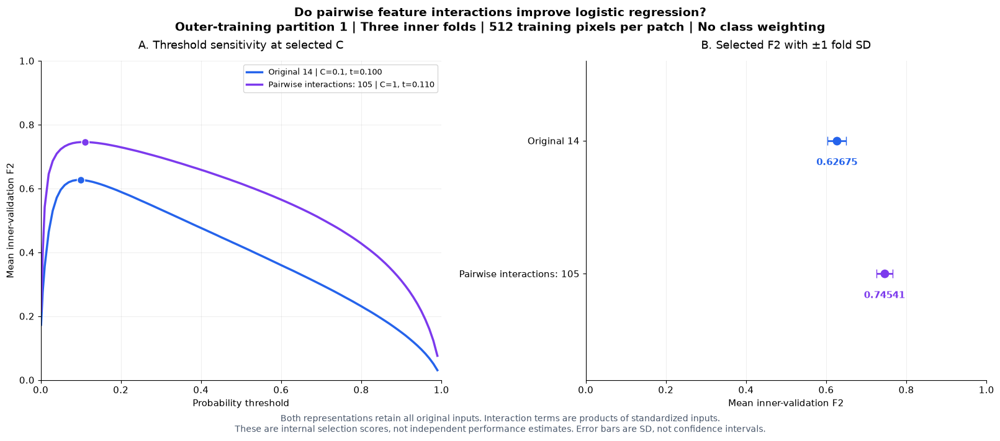

In [79]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    PolynomialFeatures,
    StandardScaler,
)


# ------------------------------------------------------------
# 1. Define a controlled interaction experiment.
# ------------------------------------------------------------
LR_INTERACTION_SAMPLE_SIZE = 512
LR_INTERACTION_C_VALUES = [0.1, 1.0, 10.0]
LR_INTERACTION_OUTER_FOLD = 1

interaction_outer_split = nested_splits[
    LR_INTERACTION_OUTER_FOLD - 1
]
interaction_inner_splits = interaction_outer_split["inner_splits"]

interaction_test_ids = set(map(str, test_ids))
interaction_outer_evaluation_ids = set(
    map(str, interaction_outer_split["evaluation_ids"])
)

# Retrieve the matching original-model results.
original_search = lr_search_by_outer[
    LR_INTERACTION_OUTER_FOLD
]["results"]

original_mask = (
    original_search["Pixels per patch"].eq(
        LR_INTERACTION_SAMPLE_SIZE
    )
    & original_search["Class weight"].astype(str).eq("None")
    & original_search["C"].isin(LR_INTERACTION_C_VALUES)
)

interaction_reference_results = (
    original_search.loc[original_mask].copy()
)
interaction_reference_results["Representation"] = "Original 14"

assert interaction_reference_results["C"].nunique() == 3
assert interaction_reference_results["Inner fold"].nunique() == 3

# Obtain feature names without using observed feature values.
interaction_name_builder = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False,
)
interaction_name_builder.fit(
    np.zeros((1, len(FEATURE_NAMES)))
)

lr_interaction_feature_names = (
    interaction_name_builder.get_feature_names_out(
        FEATURE_NAMES
    )
)

assert len(lr_interaction_feature_names) == 105

print("Original predictors: 14")
print("Additional pairwise products: 91")
print("Total interaction-model predictors: 105")
print("New model fits: 9")
print("Original-model results are reused.")
print("Outer-evaluation and final-test patches are excluded.")

interaction_result_tables = [interaction_reference_results]
interaction_fit_records = []

interaction_start = time.perf_counter()
completed_interaction_fits = 0


# ------------------------------------------------------------
# 2. Fit pairwise-interaction models using inner CV.
# ------------------------------------------------------------
for c_value in LR_INTERACTION_C_VALUES:
    for inner_fold, split in enumerate(
        interaction_inner_splits,
        start=1,
    ):
        training_ids = set(map(str, split["train_ids"]))
        validation_ids = set(
            map(str, split["validation_ids"])
        )

        assert training_ids.isdisjoint(validation_ids)

        for used_ids in (training_ids, validation_ids):
            assert used_ids.isdisjoint(interaction_test_ids)
            assert used_ids.isdisjoint(
                interaction_outer_evaluation_ids
            )

        X_training, y_training = get_sampled_pixels(
            split["train_ids"],
            LR_INTERACTION_SAMPLE_SIZE,
        )

        interaction_model = Pipeline([
            # Center and scale the original inputs before products.
            ("input_scaler", StandardScaler()),

            # Keep original features and add distinct pairwise products.
            ("interactions", PolynomialFeatures(
                degree=2,
                interaction_only=True,
                include_bias=False,
            )),

            # Scale expanded columns for regularized regression.
            ("expanded_scaler", StandardScaler(copy=False)),

            ("classifier", LogisticRegression(
                C=c_value,
                class_weight=None,
                solver="lbfgs",
                max_iter=1000,
                random_state=RANDOM_STATE,
            )),
        ])

        fit_start = time.perf_counter()

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter(
                "always",
                ConvergenceWarning,
            )
            interaction_model.fit(
                X_training,
                y_training,
            )

        if any(
            issubclass(item.category, ConvergenceWarning)
            for item in caught
        ):
            raise RuntimeError(
                "The interaction model did not converge: "
                f"C={c_value}, inner fold={inner_fold}. "
                "Resolve convergence before interpreting results."
            )

        fit_seconds = time.perf_counter() - fit_start

        scores = evaluate_full_patches_at_thresholds(
            interaction_model,
            split["validation_ids"],
            THRESHOLDS,
        )

        scores["Representation"] = "Pairwise interactions: 105"
        scores["Pixels per patch"] = (
            LR_INTERACTION_SAMPLE_SIZE
        )
        scores["C"] = c_value
        scores["Class weight"] = "None"
        scores["Inner fold"] = inner_fold

        interaction_result_tables.append(scores)

        iteration_count = int(
            interaction_model.named_steps[
                "classifier"
            ].n_iter_.max()
        )

        interaction_fit_records.append({
            "C": c_value,
            "Inner fold": inner_fold,
            "Training pixels": len(y_training),
            "Predictors": 105,
            "Iterations": iteration_count,
            "Fit seconds": fit_seconds,
        })

        completed_interaction_fits += 1

        print(
            f"[{completed_interaction_fits}/9] "
            f"C={c_value:g}, fold={inner_fold} | "
            f"iterations={iteration_count}, "
            f"fit={fit_seconds:.1f}s | "
            "Full-patch validation completed",
            flush=True,
        )

        del X_training, y_training, interaction_model


# ------------------------------------------------------------
# 3. Select C and threshold separately for each representation.
# ------------------------------------------------------------
lr_interaction_comparison_results = pd.concat(
    interaction_result_tables,
    ignore_index=True,
)

lr_interaction_fit_log = pd.DataFrame(
    interaction_fit_records
)

lr_interaction_comparison_summary = (
    lr_interaction_comparison_results
    .groupby(
        ["Representation", "C", "Threshold"],
        as_index=False,
    )
    .agg(
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean"),
        Fold_count=("Inner fold", "nunique"),
    )
)

assert (
    lr_interaction_comparison_summary["Fold_count"]
    .eq(3)
    .all()
)

# Highest mean F2, then precision, smaller C,
# then higher threshold for remaining exact ties.
lr_interaction_ranked = (
    lr_interaction_comparison_summary
    .sort_values(
        ["Mean_F2", "Mean_precision", "C", "Threshold"],
        ascending=[False, False, True, False],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

lr_interaction_best_per_representation = (
    lr_interaction_ranked
    .drop_duplicates("Representation")
    .reset_index(drop=True)
)

print("\nBest configuration for each representation:")
display(
    lr_interaction_best_per_representation[
        [
            "Representation",
            "C",
            "Threshold",
            "Mean_F2",
            "SD_F2",
            "Mean_precision",
            "Mean_recall",
            "Mean_specificity",
            "Mean_IoU",
        ]
    ].round(6)
)

print("\nInteraction-model fitting details:")
display(lr_interaction_fit_log.round(3))

print(
    "\nElapsed time: "
    f"{(time.perf_counter() - interaction_start) / 60:.1f} minutes"
)


# ------------------------------------------------------------
# 4. Visualize threshold sensitivity and selected F2.
# ------------------------------------------------------------
representation_order = [
    "Original 14",
    "Pairwise interactions: 105",
]

representation_colors = {
    "Original 14": "#2563EB",
    "Pairwise interactions: 105": "#7C3AED",
}

best_lookup = (
    lr_interaction_best_per_representation
    .set_index("Representation")
)

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 7),
        layout="constrained",
    )

    fig.suptitle(
        "Do pairwise feature interactions improve logistic regression?\n"
        "Outer-training partition 1 | Three inner folds | "
        "512 training pixels per patch | No class weighting",
        fontsize=14,
        fontweight="bold",
    )

    for position, representation in enumerate(
        representation_order
    ):
        selected = best_lookup.loc[representation]

        curve = (
            lr_interaction_comparison_summary.loc[
                lr_interaction_comparison_summary[
                    "Representation"
                ].eq(representation)
                & lr_interaction_comparison_summary["C"].eq(
                    selected["C"]
                )
            ]
            .sort_values("Threshold")
        )

        color = representation_colors[representation]

        axes[0].plot(
            curve["Threshold"],
            curve["Mean_F2"],
            color=color,
            linewidth=2.5,
            label=(
                f"{representation} | "
                f"C={selected['C']:g}, "
                f"t={selected['Threshold']:.3f}"
            ),
        )

        axes[0].scatter(
            selected["Threshold"],
            selected["Mean_F2"],
            color=color,
            edgecolor="white",
            s=75,
            zorder=5,
        )

        axes[1].errorbar(
            selected["Mean_F2"],
            position,
            xerr=selected["SD_F2"],
            fmt="o",
            color=color,
            markersize=9,
            capsize=5,
            elinewidth=2,
        )

        axes[1].annotate(
            f"{selected['Mean_F2']:.5f}",
            xy=(selected["Mean_F2"], position),
            xytext=(0, -20),
            textcoords="offset points",
            ha="center",
            va="top",
            color=color,
            fontweight="bold",
        )

    axes[0].set(
        xlabel="Probability threshold",
        ylabel="Mean inner-validation F2",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    axes[0].set_title(
        "A. Threshold sensitivity at selected C",
        pad=14,
    )
    axes[0].legend(loc="upper right", fontsize=9)
    axes[0].grid(alpha=0.2)

    axes[1].set(
        xlabel="Mean inner-validation F2",
        xlim=(0, 1),
        ylim=(1.8, -0.6),
    )
    axes[1].set_yticks([0, 1])
    axes[1].set_yticklabels(representation_order)
    axes[1].set_title(
        "B. Selected F2 with ±1 fold SD",
        pad=14,
    )
    axes[1].grid(axis="x", alpha=0.2)

    for ax in axes:
        ax.set_axisbelow(True)
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)

    fig.supxlabel(
        "Both representations retain all original inputs. "
        "Interaction terms are products of standardized inputs.\n"
        "These are internal selection scores, not independent "
        "performance estimates. Error bars are SD, not confidence intervals.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

In three inner-validation folds within outer-training partition 1, pairwise interactions increased mean F2 from 0.626749 to 0.745408, an absolute improvement of 0.118659 (approximately 18.9% relative). Precision, recall, specificity, and IoU also increased. The interaction model selected C = 1.0 and threshold = 0.11. These are promising internal selection results, not independent performance estimates. Calibration selection and outer evaluation remain necessary before drawing broader conclusions.

Fixed C: 1
Training pixels per patch: 512
Calibration fraction: 20%
Outer-evaluation and final-test patches are excluded.
Inner fold 1/3 | Uncalibrated | validation=13.1s
Inner fold 1/3 | Sigmoid      | validation=13.6s
Inner fold 1/3 | Isotonic     | validation=13.4s
Inner fold 2/3 | Uncalibrated | validation=13.0s
Inner fold 2/3 | Sigmoid      | validation=13.9s
Inner fold 2/3 | Isotonic     | validation=14.0s
Inner fold 3/3 | Uncalibrated | validation=13.3s
Inner fold 3/3 | Sigmoid      | validation=14.0s
Inner fold 3/3 | Isotonic     | validation=13.6s

Patch allocation:


,Inner fold,Fitting patches,Calibration patches,Validation patches,Fitting pixels,Calibration pixels,Calibration positive fraction
0,1,1296,324,811,663552,165888,0.02676
1,2,1296,325,810,663552,166400,0.02388
2,3,1296,325,810,663552,166400,0.02126



Each calibration method at its selected threshold:


,Method,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,Sigmoid,0.11,0.745713,0.020444,0.509799,0.843756,0.980708,0.465900
1,Uncalibrated,0.11,0.745340,0.019845,0.514146,0.840993,0.981089,0.468416
2,Isotonic,0.12,0.744563,0.021112,0.486686,0.859355,0.978399,0.450677



Selected calibration method and threshold:


,Selected value
Method,Sigmoid
Threshold,0.11
Mean_F2,0.745713
SD_F2,0.020444
Mean_precision,0.509799
Mean_recall,0.843756
Mean_specificity,0.980708
Mean_IoU,0.4659
Fold_count,3



Elapsed time: 2.4 minutes.


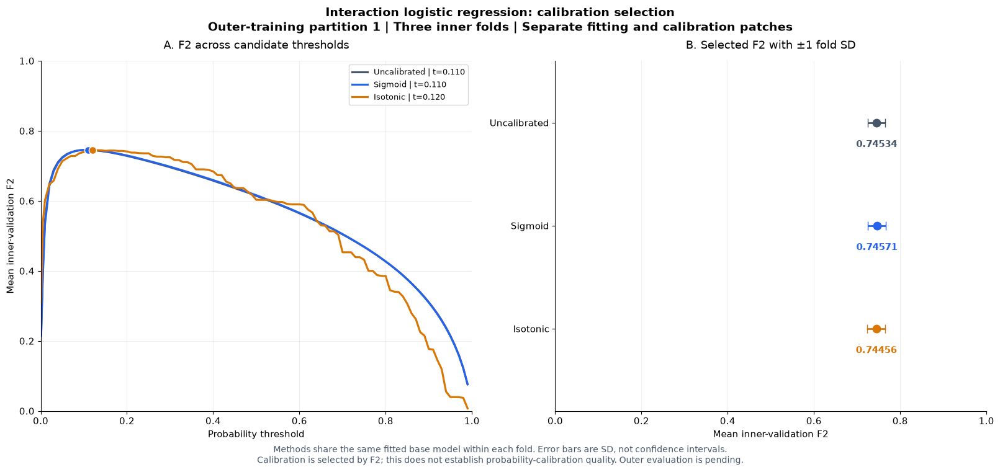

In [80]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.exceptions import ConvergenceWarning
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler


# ------------------------------------------------------------
# 1. Read the selected interaction-model hyperparameter.
# ------------------------------------------------------------
interaction_selected_row = (
    lr_interaction_best_per_representation
    .set_index("Representation")
    .loc["Pairwise interactions: 105"]
)

interaction_selected_c = float(
    interaction_selected_row["C"]
)

interaction_calibration_methods = [
    "Uncalibrated",
    "Sigmoid",
    "Isotonic",
]

interaction_calibration_tables = []
interaction_calibration_split_records = []

interaction_calibration_start = time.perf_counter()

print(f"Fixed C: {interaction_selected_c:g}")
print(f"Training pixels per patch: {LR_INTERACTION_SAMPLE_SIZE}")
print(f"Calibration fraction: {CALIBRATION_FRACTION:.0%}")
print("Outer-evaluation and final-test patches are excluded.")


# ------------------------------------------------------------
# 2. Fit and calibrate within each inner-training partition.
# ------------------------------------------------------------
for inner_fold, split in enumerate(
    interaction_inner_splits,
    start=1,
):
    inner_training_ids = np.asarray(
        split["train_ids"],
        dtype=str,
    )
    validation_ids = np.asarray(
        split["validation_ids"],
        dtype=str,
    )

    training_presence = presence_by_id.reindex(
        inner_training_ids
    )
    assert training_presence.notna().all()

    fitting_ids, calibration_ids = train_test_split(
        inner_training_ids,
        test_size=CALIBRATION_FRACTION,
        stratify=training_presence.to_numpy(),
        random_state=RANDOM_STATE + 100 + inner_fold,
    )

    fitting_set = set(fitting_ids)
    calibration_set = set(calibration_ids)
    validation_set = set(validation_ids)

    assert fitting_set.isdisjoint(calibration_set)
    assert fitting_set.isdisjoint(validation_set)
    assert calibration_set.isdisjoint(validation_set)

    for used_ids in (
        fitting_set,
        calibration_set,
        validation_set,
    ):
        assert used_ids.isdisjoint(interaction_test_ids)
        assert used_ids.isdisjoint(
            interaction_outer_evaluation_ids
        )

    X_fitting, y_fitting = get_sampled_pixels(
        fitting_ids,
        LR_INTERACTION_SAMPLE_SIZE,
    )
    X_calibration, y_calibration = get_sampled_pixels(
        calibration_ids,
        LR_INTERACTION_SAMPLE_SIZE,
    )

    assert np.unique(y_fitting).size == 2
    assert np.unique(y_calibration).size == 2

    base_model = Pipeline([
        ("input_scaler", StandardScaler()),
        ("interactions", PolynomialFeatures(
            degree=2,
            interaction_only=True,
            include_bias=False,
        )),
        ("expanded_scaler", StandardScaler(copy=False)),
        ("classifier", LogisticRegression(
            C=interaction_selected_c,
            class_weight=None,
            solver="lbfgs",
            max_iter=1000,
            random_state=RANDOM_STATE,
        )),
    ])

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        base_model.fit(X_fitting, y_fitting)

    if any(
        issubclass(item.category, ConvergenceWarning)
        for item in caught
    ):
        raise RuntimeError(
            f"Interaction base model did not converge: "
            f"inner fold {inner_fold}."
        )

    calibration_scores = base_model.decision_function(
        X_calibration
    )

    sigmoid_calibrator = LogisticRegression(
        C=PLATT_C,
        class_weight=None,
        solver="lbfgs",
        max_iter=1000,
        random_state=RANDOM_STATE,
    )

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        sigmoid_calibrator.fit(
            calibration_scores.reshape(-1, 1),
            y_calibration,
        )

    if any(
        issubclass(item.category, ConvergenceWarning)
        for item in caught
    ):
        raise RuntimeError(
            f"Sigmoid calibrator did not converge: "
            f"inner fold {inner_fold}."
        )

    isotonic_calibrator = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip",
    )
    isotonic_calibrator.fit(
        calibration_scores,
        y_calibration,
    )

    probability_models = {
        "Uncalibrated": CalibratedProbabilityModel(
            base_model,
            "Uncalibrated",
        ),
        "Sigmoid": CalibratedProbabilityModel(
            base_model,
            "Sigmoid",
            sigmoid_calibrator,
        ),
        "Isotonic": CalibratedProbabilityModel(
            base_model,
            "Isotonic",
            isotonic_calibrator,
        ),
    }

    interaction_calibration_split_records.append({
        "Inner fold": inner_fold,
        "Fitting patches": len(fitting_ids),
        "Calibration patches": len(calibration_ids),
        "Validation patches": len(validation_ids),
        "Fitting pixels": len(y_fitting),
        "Calibration pixels": len(y_calibration),
        "Calibration positive fraction": float(
            y_calibration.mean()
        ),
    })

    for method in interaction_calibration_methods:
        method_start = time.perf_counter()

        scores = evaluate_full_patches_at_thresholds(
            probability_models[method],
            validation_ids,
            THRESHOLDS,
        )

        scores["Method"] = method
        scores["Inner fold"] = inner_fold
        interaction_calibration_tables.append(scores)

        print(
            f"Inner fold {inner_fold}/3 | {method:<12} | "
            f"validation={time.perf_counter() - method_start:.1f}s",
            flush=True,
        )

    del (
        X_fitting,
        y_fitting,
        X_calibration,
        y_calibration,
        calibration_scores,
        probability_models,
        base_model,
        sigmoid_calibrator,
        isotonic_calibrator,
    )


# ------------------------------------------------------------
# 3. Select calibration method and threshold.
# ------------------------------------------------------------
lr_interaction_fold1_calibration_results = pd.concat(
    interaction_calibration_tables,
    ignore_index=True,
)

lr_interaction_fold1_calibration_splits = pd.DataFrame(
    interaction_calibration_split_records
)

lr_interaction_fold1_calibration_summary = (
    lr_interaction_fold1_calibration_results
    .groupby(["Method", "Threshold"], as_index=False)
    .agg(
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean"),
        Fold_count=("Inner fold", "nunique"),
    )
)

assert (
    lr_interaction_fold1_calibration_summary["Fold_count"]
    .eq(3)
    .all()
)

# Same staged selection rule as the original LR workflow.
interaction_calibration_ranked = (
    lr_interaction_fold1_calibration_summary
    .sort_values(
        ["Mean_F2", "Mean_precision", "Method", "Threshold"],
        ascending=[False, False, True, False],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

lr_interaction_fold1_calibration_selected = (
    interaction_calibration_ranked.iloc[0].copy()
)

lr_interaction_fold1_calibration_best_per_method = (
    interaction_calibration_ranked
    .drop_duplicates("Method")
    .reset_index(drop=True)
)

print("\nPatch allocation:")
display(lr_interaction_fold1_calibration_splits.round(5))

print("\nEach calibration method at its selected threshold:")
display(
    lr_interaction_fold1_calibration_best_per_method[
        [
            "Method",
            "Threshold",
            "Mean_F2",
            "SD_F2",
            "Mean_precision",
            "Mean_recall",
            "Mean_specificity",
            "Mean_IoU",
        ]
    ].round(6)
)

print("\nSelected calibration method and threshold:")
display(
    lr_interaction_fold1_calibration_selected
    .to_frame("Selected value")
)

print(
    "\nElapsed time: "
    f"{(time.perf_counter() - interaction_calibration_start) / 60:.1f} "
    "minutes."
)


# ------------------------------------------------------------
# 4. Plot the calibration-method comparison.
# ------------------------------------------------------------
calibration_colors = {
    "Uncalibrated": "#475569",
    "Sigmoid": "#2563EB",
    "Isotonic": "#D97706",
}

best_lookup = (
    lr_interaction_fold1_calibration_best_per_method
    .set_index("Method")
)

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 7.5),
        layout="constrained",
    )

    fig.suptitle(
        "Interaction logistic regression: calibration selection\n"
        "Outer-training partition 1 | Three inner folds | "
        "Separate fitting and calibration patches",
        fontsize=14,
        fontweight="bold",
    )

    for position, method in enumerate(
        interaction_calibration_methods
    ):
        curve = (
            lr_interaction_fold1_calibration_summary.loc[
                lr_interaction_fold1_calibration_summary[
                    "Method"
                ].eq(method)
            ]
            .sort_values("Threshold")
        )
        best = best_lookup.loc[method]
        color = calibration_colors[method]

        axes[0].plot(
            curve["Threshold"],
            curve["Mean_F2"],
            color=color,
            linewidth=2.3,
            label=(
                f"{method} | t={best['Threshold']:.3f}"
            ),
        )
        axes[0].scatter(
            best["Threshold"],
            best["Mean_F2"],
            s=75,
            color=color,
            edgecolor="white",
            zorder=5,
        )

        axes[1].errorbar(
            best["Mean_F2"],
            position,
            xerr=best["SD_F2"],
            fmt="o",
            markersize=9,
            color=color,
            capsize=5,
            elinewidth=2,
        )
        axes[1].annotate(
            f"{best['Mean_F2']:.5f}",
            xy=(best["Mean_F2"], position),
            xytext=(0, -20),
            textcoords="offset points",
            ha="center",
            va="top",
            color=color,
            fontweight="bold",
        )

    axes[0].set(
        xlabel="Probability threshold",
        ylabel="Mean inner-validation F2",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    axes[0].set_title(
        "A. F2 across candidate thresholds",
        pad=14,
    )
    axes[0].legend(loc="upper right", fontsize=9)
    axes[0].grid(alpha=0.2)

    axes[1].set(
        xlabel="Mean inner-validation F2",
        xlim=(0, 1),
        ylim=(2.8, -0.6),
    )
    axes[1].set_yticks([0, 1, 2])
    axes[1].set_yticklabels(
        interaction_calibration_methods
    )
    axes[1].set_title(
        "B. Selected F2 with ±1 fold SD",
        pad=14,
    )
    axes[1].grid(axis="x", alpha=0.2)

    for ax in axes:
        ax.set_axisbelow(True)
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)

    fig.supxlabel(
        "Methods share the same fitted base model within each fold. "
        "Error bars are SD, not confidence intervals.\n"
        "Calibration is selected by F2; this does not establish "
        "probability-calibration quality. Outer evaluation is pending.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

Within outer-training partition 1, sigmoid calibration with threshold 0.11 achieved the highest mean inner-validation F2 (0.745713). Its advantage over uncalibrated probabilities was only 0.000373, which does not establish a meaningful improvement. Isotonic calibration increased recall but reduced precision and achieved slightly lower F2. Fitting, calibration, and validation patches remained separate. Outer evaluation of the interaction model is still pending.

Selected C: 1
Calibration: Sigmoid
Fixed threshold: 0.110
Fitting patches: 1,944
Calibration patches: 487
Outer-evaluation patches: 608
Evaluated 100/608 patches
Evaluated 200/608 patches
Evaluated 300/608 patches
Evaluated 400/608 patches
Evaluated 500/608 patches
Evaluated 600/608 patches
Evaluated 608/608 patches

Outer partition 1 — same-patch comparison:


,Metric,Original LR,Interaction LR,Interaction minus original
0,F2,0.633168,0.750469,0.117301
1,Precision,0.413046,0.528112,0.115066
2,Recall,0.730493,0.838757,0.108264
3,Specificity,0.973231,0.980673,0.007442
4,F1,0.527708,0.648135,0.120427
5,IoU,0.358426,0.479438,0.121012
6,Brier score,0.014941,0.011049,-0.003892
7,Log loss,0.056983,0.040244,-0.016739



Brier score and log loss: lower is better. Other listed metrics: higher is better.


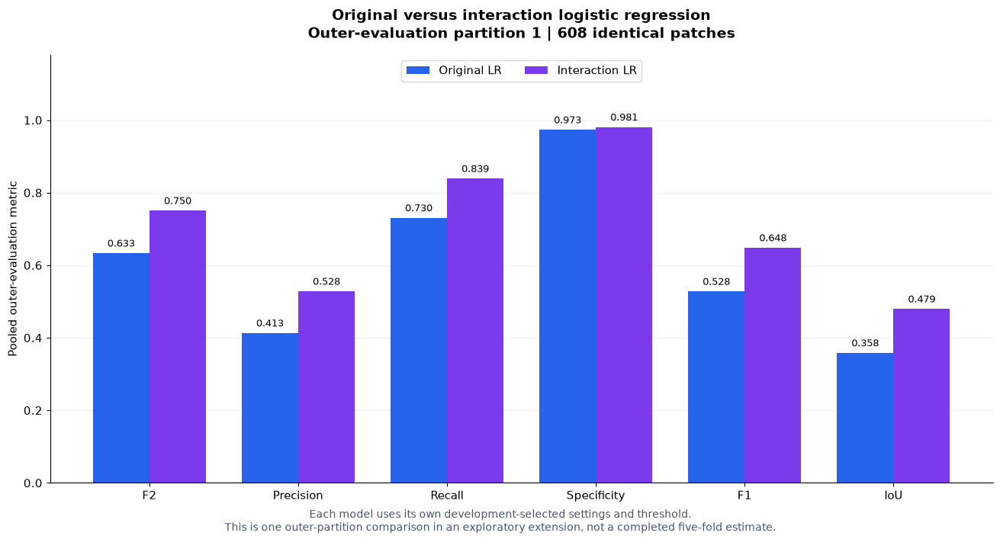


Elapsed time: 2.7 minutes.


In [81]:
import time
import warnings

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.exceptions import ConvergenceWarning
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler


# ------------------------------------------------------------
# 1. Read settings selected inside outer-training partition 1.
# ------------------------------------------------------------
interaction_fold1_method = str(
    lr_interaction_fold1_calibration_selected["Method"]
)
interaction_fold1_threshold = float(
    lr_interaction_fold1_calibration_selected["Threshold"]
)

outer_training_ids = np.asarray(
    interaction_outer_split["train_ids"],
    dtype=str,
)
outer_evaluation_ids = np.asarray(
    interaction_outer_split["evaluation_ids"],
    dtype=str,
)

assert set(outer_training_ids).isdisjoint(
    outer_evaluation_ids
)

for used_ids in (outer_training_ids, outer_evaluation_ids):
    assert set(used_ids).isdisjoint(interaction_test_ids)

# Match the original workflow's outer-refit split seed.
if interaction_fold1_method == "Uncalibrated":
    interaction_fold1_fitting_ids = outer_training_ids.copy()
    interaction_fold1_calibration_ids = np.asarray([], dtype=str)

else:
    outer_presence = presence_by_id.reindex(
        outer_training_ids
    )
    assert outer_presence.notna().all()

    (
        interaction_fold1_fitting_ids,
        interaction_fold1_calibration_ids,
    ) = train_test_split(
        outer_training_ids,
        test_size=CALIBRATION_FRACTION,
        stratify=outer_presence.to_numpy(),
        random_state=(
            RANDOM_STATE + 100 + LR_INTERACTION_OUTER_FOLD
        ),
    )

assert set(interaction_fold1_fitting_ids).isdisjoint(
    interaction_fold1_calibration_ids
)

print(f"Selected C: {interaction_selected_c:g}")
print(f"Calibration: {interaction_fold1_method}")
print(f"Fixed threshold: {interaction_fold1_threshold:.3f}")
print(
    f"Fitting patches: {len(interaction_fold1_fitting_ids):,}"
)
print(
    "Calibration patches: "
    f"{len(interaction_fold1_calibration_ids):,}"
)
print(f"Outer-evaluation patches: {len(outer_evaluation_ids):,}")

outer_step_start = time.perf_counter()


# ------------------------------------------------------------
# 2. Fit the outer base model.
# ------------------------------------------------------------
X_outer_fit, y_outer_fit = get_sampled_pixels(
    interaction_fold1_fitting_ids,
    LR_INTERACTION_SAMPLE_SIZE,
)

lr_interaction_fold1_base_model = Pipeline([
    ("input_scaler", StandardScaler()),
    ("interactions", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False,
    )),
    ("expanded_scaler", StandardScaler(copy=False)),
    ("classifier", LogisticRegression(
        C=interaction_selected_c,
        class_weight=None,
        solver="lbfgs",
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    lr_interaction_fold1_base_model.fit(
        X_outer_fit,
        y_outer_fit,
    )

if any(
    issubclass(item.category, ConvergenceWarning)
    for item in caught
):
    raise RuntimeError(
        "Outer interaction model did not converge."
    )

del X_outer_fit, y_outer_fit


# ------------------------------------------------------------
# 3. Fit the selected calibrator on separate patches.
# ------------------------------------------------------------
interaction_fold1_calibrator = None

if interaction_fold1_method != "Uncalibrated":
    X_outer_cal, y_outer_cal = get_sampled_pixels(
        interaction_fold1_calibration_ids,
        LR_INTERACTION_SAMPLE_SIZE,
    )

    calibration_scores = (
        lr_interaction_fold1_base_model.decision_function(
            X_outer_cal
        )
    )

    if interaction_fold1_method == "Sigmoid":
        interaction_fold1_calibrator = LogisticRegression(
            C=PLATT_C,
            class_weight=None,
            solver="lbfgs",
            max_iter=1000,
            random_state=RANDOM_STATE,
        )

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            interaction_fold1_calibrator.fit(
                calibration_scores.reshape(-1, 1),
                y_outer_cal,
            )

        if any(
            issubclass(item.category, ConvergenceWarning)
            for item in caught
        ):
            raise RuntimeError(
                "Outer sigmoid calibrator did not converge."
            )

    elif interaction_fold1_method == "Isotonic":
        interaction_fold1_calibrator = IsotonicRegression(
            increasing=True,
            out_of_bounds="clip",
        )
        interaction_fold1_calibrator.fit(
            calibration_scores,
            y_outer_cal,
        )

    else:
        raise ValueError("Unknown calibration method.")

    del X_outer_cal, y_outer_cal, calibration_scores

lr_interaction_fold1_probability_model = (
    CalibratedProbabilityModel(
        lr_interaction_fold1_base_model,
        interaction_fold1_method,
        interaction_fold1_calibrator,
    )
)


# ------------------------------------------------------------
# 4. Evaluate all pixels in outer-evaluation partition 1.
# ------------------------------------------------------------
pixels_per_patch = 128 * 128
evaluation_pixel_count = (
    len(outer_evaluation_ids) * pixels_per_patch
)

lr_interaction_fold1_y = np.empty(
    evaluation_pixel_count,
    dtype=np.uint8,
)
lr_interaction_fold1_probability = np.empty(
    evaluation_pixel_count,
    dtype=np.float64,
)

positive_index = int(
    np.flatnonzero(
        np.asarray(
            lr_interaction_fold1_probability_model.classes_
        ) == 1
    )[0]
)

interaction_outer_patch_records = []

for patch_number, sample_id in enumerate(
    outer_evaluation_ids,
    start=1,
):
    image_path = (
        DATA_DIR / "TrainData" / "img"
        / f"image_{sample_id}.h5"
    )
    mask_path = (
        DATA_DIR / "TrainData" / "mask"
        / f"mask_{sample_id}.h5"
    )

    with h5py.File(image_path, "r") as image_file:
        image_array = np.asarray(
            image_file["img"],
            dtype=np.float32,
        )

    with h5py.File(mask_path, "r") as mask_file:
        reference = np.asarray(
            mask_file["mask"],
            dtype=np.uint8,
        ).reshape(-1)

    assert image_array.shape == (128, 128, 14)
    assert reference.size == pixels_per_patch
    assert np.isfinite(image_array).all()
    assert np.isin(reference, [0, 1]).all()

    # Convert before clipping or calculating probability losses.
    probabilities = np.asarray(
        lr_interaction_fold1_probability_model.predict_proba(
            image_array.reshape(-1, 14)
        )[:, positive_index],
        dtype=np.float64,
    )

    assert np.isfinite(probabilities).all()
    assert (
        (probabilities >= 0) & (probabilities <= 1)
    ).all()

    prediction = (
        probabilities >= interaction_fold1_threshold
    ).astype(np.uint8)

    tn, fp, fn, tp = confusion_matrix(
        reference,
        prediction,
        labels=[0, 1],
    ).ravel()

    start = (patch_number - 1) * pixels_per_patch
    stop = start + pixels_per_patch

    lr_interaction_fold1_y[start:stop] = reference
    lr_interaction_fold1_probability[start:stop] = probabilities

    clipped = np.clip(
        probabilities,
        1e-15,
        1.0 - 1e-15,
    )
    reference_float = reference.astype(np.float64)

    squared_error_sum = float(
        np.sum((probabilities - reference_float) ** 2)
    )
    log_loss_sum = float(
        -np.sum(
            reference_float * np.log(clipped)
            + (1.0 - reference_float) * np.log1p(-clipped)
        )
    )

    assert np.isfinite(log_loss_sum)

    interaction_outer_patch_records.append({
        "Outer fold": LR_INTERACTION_OUTER_FOLD,
        "sample_id": str(sample_id),
        "Start": start,
        "Stop": stop,
        "Method": interaction_fold1_method,
        "Threshold": interaction_fold1_threshold,
        "Pixels": pixels_per_patch,
        "Positive pixels": int(reference.sum()),
        "Landslide coverage (%)": 100 * float(reference.mean()),
        "Squared error sum": squared_error_sum,
        "Log loss sum": log_loss_sum,
        **metrics_from_counts(tn, fp, fn, tp),
    })

    if patch_number % 100 == 0 or patch_number == len(
        outer_evaluation_ids
    ):
        print(
            f"Evaluated {patch_number:,}/"
            f"{len(outer_evaluation_ids):,} patches",
            flush=True,
        )

lr_interaction_fold1_patch_results = pd.DataFrame(
    interaction_outer_patch_records
)


# ------------------------------------------------------------
# 5. Compare with the original LR on exactly the same patches.
# ------------------------------------------------------------
original_fold1_patch_results = (
    lr_oof_patch_results.loc[
        lr_oof_patch_results["Outer fold"].eq(
            LR_INTERACTION_OUTER_FOLD
        )
    ].copy()
)

assert original_fold1_patch_results["sample_id"].astype(str).is_unique
assert lr_interaction_fold1_patch_results["sample_id"].is_unique

assert set(
    original_fold1_patch_results["sample_id"].astype(str)
) == set(
    lr_interaction_fold1_patch_results["sample_id"]
)


def summarize_interaction_comparison(patch_table):
    counts = (
        patch_table[["TN", "FP", "FN", "TP"]]
        .sum()
        .astype(np.int64)
    )

    scores = metrics_from_counts(
        int(counts["TN"]),
        int(counts["FP"]),
        int(counts["FN"]),
        int(counts["TP"]),
    )

    total_pixels = int(patch_table["Pixels"].sum())

    scores["Brier score"] = float(
        patch_table["Squared error sum"].sum() / total_pixels
    )
    scores["Log loss"] = float(
        patch_table["Log loss sum"].sum() / total_pixels
    )

    return scores


lr_interaction_fold1_outer_metrics = (
    summarize_interaction_comparison(
        lr_interaction_fold1_patch_results
    )
)

original_fold1_comparison_metrics = (
    summarize_interaction_comparison(
        original_fold1_patch_results
    )
)

comparison_metric_order = [
    "F2",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "IoU",
    "Brier score",
    "Log loss",
]

lr_interaction_fold1_outer_comparison = pd.DataFrame({
    "Metric": comparison_metric_order,
    "Original LR": [
        original_fold1_comparison_metrics[metric]
        for metric in comparison_metric_order
    ],
    "Interaction LR": [
        lr_interaction_fold1_outer_metrics[metric]
        for metric in comparison_metric_order
    ],
})

lr_interaction_fold1_outer_comparison[
    "Interaction minus original"
] = (
    lr_interaction_fold1_outer_comparison["Interaction LR"]
    - lr_interaction_fold1_outer_comparison["Original LR"]
)

print("\nOuter partition 1 — same-patch comparison:")
display(lr_interaction_fold1_outer_comparison.round(6))

print(
    "\nBrier score and log loss: lower is better. "
    "Other listed metrics: higher is better."
)


# ------------------------------------------------------------
# 6. Plot classification metrics on the same evaluation patches.
# ------------------------------------------------------------
plot_metrics = [
    "F2",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "IoU",
]
positions = np.arange(len(plot_metrics))

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, ax = plt.subplots(
        figsize=(13, 7),
        layout="constrained",
    )

    original_bars = ax.bar(
        positions - 0.19,
        [
            original_fold1_comparison_metrics[metric]
            for metric in plot_metrics
        ],
        width=0.38,
        color="#2563EB",
        label="Original LR",
    )

    interaction_bars = ax.bar(
        positions + 0.19,
        [
            lr_interaction_fold1_outer_metrics[metric]
            for metric in plot_metrics
        ],
        width=0.38,
        color="#7C3AED",
        label="Interaction LR",
    )

    for bars in (original_bars, interaction_bars):
        ax.bar_label(
            bars,
            fmt="%.3f",
            padding=4,
            fontsize=9,
        )

    ax.set_xticks(positions)
    ax.set_xticklabels(plot_metrics)
    ax.set_ylim(0, 1.18)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_ylabel("Pooled outer-evaluation metric")
    ax.set_title(
        "Original versus interaction logistic regression\n"
        f"Outer-evaluation partition 1 | "
        f"{len(outer_evaluation_ids):,} identical patches",
        fontsize=14,
        fontweight="bold",
        pad=16,
    )

    ax.legend(
        loc="upper center",
        ncol=2,
        frameon=True,
    )
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(True)
    ax.spines["bottom"].set_visible(True)

    fig.supxlabel(
        "Each model uses its own development-selected settings "
        "and threshold.\n"
        "This is one outer-partition comparison in an exploratory "
        "extension, not a completed five-fold estimate.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

print(
    "\nElapsed time: "
    f"{(time.perf_counter() - outer_step_start) / 60:.1f} minutes."
)

On the same 608 outer-evaluation patches, interaction logistic regression improved F2 from 0.633168 to 0.750469. Precision increased from 0.413046 to 0.528112, recall from 0.730493 to 0.838757, and IoU from 0.358426 to 0.479438. Specificity also increased, while Brier score and log loss decreased. These findings support further evaluation of the interaction extension, but represent only one outer partition. The remaining four partitions must be completed before reporting the full five-fold comparison.


OUTER FOLD 2: hyperparameter search
  Search: C=0.1, inner fold=1/3
  Search: C=0.1, inner fold=2/3
  Search: C=0.1, inner fold=3/3
  Search: C=1, inner fold=1/3
  Search: C=1, inner fold=2/3
  Search: C=1, inner fold=3/3
  Search: C=10, inner fold=1/3
  Search: C=10, inner fold=2/3
  Search: C=10, inner fold=3/3
  Selected C=10; starting calibration comparison
  Calibration: inner fold=1/3, method=Uncalibrated
  Calibration: inner fold=1/3, method=Sigmoid
  Calibration: inner fold=1/3, method=Isotonic
  Calibration: inner fold=2/3, method=Uncalibrated
  Calibration: inner fold=2/3, method=Sigmoid
  Calibration: inner fold=2/3, method=Isotonic
  Calibration: inner fold=3/3, method=Uncalibrated
  Calibration: inner fold=3/3, method=Sigmoid
  Calibration: inner fold=3/3, method=Isotonic
  Outer fold 2: evaluated 200/608 patches
  Outer fold 2: evaluated 400/608 patches
  Outer fold 2: evaluated 600/608 patches
  Outer fold 2: evaluated 608/608 patches
COMPLETED outer fold 2 | C=10, meth

,Outer fold,C,Method,Threshold,Original F2,Interaction F2,F2 difference,Interaction Precision,Interaction Recall,Interaction IoU
0,1,1.0,Sigmoid,0.11,0.633168,0.750469,0.117301,0.528112,0.838757,0.479438
1,2,10.0,Sigmoid,0.11,0.620861,0.743255,0.122394,0.530391,0.826146,0.477135
2,3,1.0,Sigmoid,0.10,0.606763,0.726529,0.119766,0.465276,0.845169,0.428732
3,4,0.1,Uncalibrated,0.11,0.654067,0.771472,0.117405,0.535592,0.866922,0.494903
4,5,10.0,Uncalibrated,0.11,0.627970,0.745748,0.117777,0.514739,0.839992,0.468775



Mean and standard deviation across five outer folds:


,Metric,Original mean,Original fold SD,Interaction mean,Interaction fold SD
0,F2,0.628566,0.017368,0.747495,0.016158
1,Precision,0.390248,0.015983,0.514822,0.028746
2,Recall,0.742196,0.023320,0.843397,0.014894
3,Specificity,0.971917,0.001247,0.980696,0.001932
4,F1,0.511348,0.015891,0.638952,0.023327
5,IoU,0.343619,0.014311,0.469797,0.024822
6,Brier score,0.014398,0.000335,0.010525,0.000400
7,Log loss,0.054524,0.001464,0.038090,0.001555


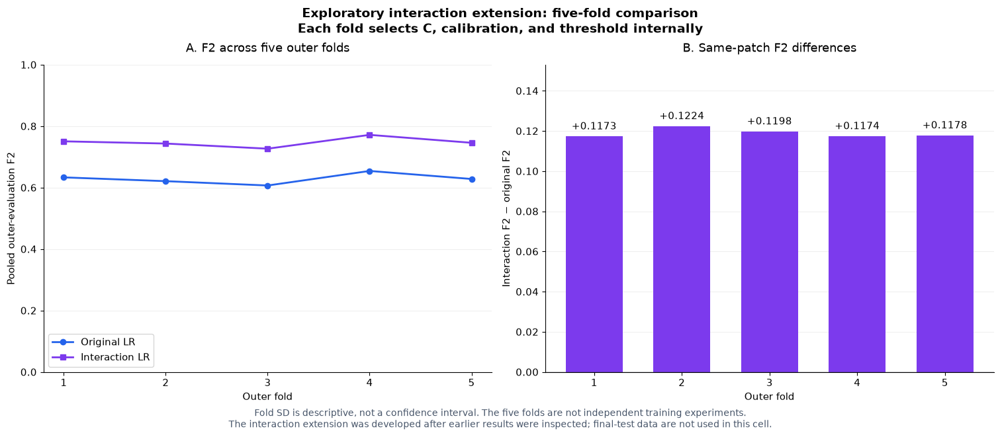


Run completed in 23.4 minutes.


In [82]:
import time
import warnings

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.exceptions import ConvergenceWarning
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler


# ------------------------------------------------------------
# 1. Fixed design for this exploratory interaction extension.
# ------------------------------------------------------------
INTERACTION_EXTENSION_C_VALUES = [0.1, 1.0, 10.0]
INTERACTION_EXTENSION_SAMPLE_SIZE = 512

INTERACTION_EXTENSION_METHODS = [
    "Uncalibrated",
    "Sigmoid",
    "Isotonic",
]

extension_reserved_test_ids = set(map(str, test_ids))


def interaction_fit_checked(model, X, y, description):
    """Fit and stop if convergence fails."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X, y)

    if any(
        issubclass(item.category, ConvergenceWarning)
        for item in caught
    ):
        raise RuntimeError(
            f"Convergence failed: {description}"
        )

    return model


def interaction_fit_base(patch_ids, c_value):
    """Fit all preprocessing and the interaction LR on these patches."""
    assert set(map(str, patch_ids)).isdisjoint(
        extension_reserved_test_ids
    )

    X, y = get_sampled_pixels(
        patch_ids,
        INTERACTION_EXTENSION_SAMPLE_SIZE,
    )

    model = Pipeline([
        ("input_scaler", StandardScaler()),
        ("interactions", PolynomialFeatures(
            degree=2,
            interaction_only=True,
            include_bias=False,
        )),
        ("expanded_scaler", StandardScaler(copy=False)),
        ("classifier", LogisticRegression(
            C=c_value,
            class_weight=None,
            solver="lbfgs",
            max_iter=1000,
            random_state=RANDOM_STATE,
        )),
    ])

    return interaction_fit_checked(
        model, X, y, f"base LR, C={c_value}"
    )


def interaction_fit_calibrator(base_model, patch_ids, method):
    """Fit calibration using separate sampled calibration patches."""
    if method == "Uncalibrated":
        return None

    X, y = get_sampled_pixels(
        patch_ids,
        INTERACTION_EXTENSION_SAMPLE_SIZE,
    )
    assert np.unique(y).size == 2

    decision_scores = base_model.decision_function(X)

    if method == "Sigmoid":
        calibrator = LogisticRegression(
            C=PLATT_C,
            class_weight=None,
            solver="lbfgs",
            max_iter=1000,
            random_state=RANDOM_STATE,
        )
        return interaction_fit_checked(
            calibrator,
            decision_scores.reshape(-1, 1),
            y,
            "sigmoid calibration",
        )

    if method == "Isotonic":
        return IsotonicRegression(
            increasing=True,
            out_of_bounds="clip",
        ).fit(decision_scores, y)

    raise ValueError(f"Unknown method: {method}")


def interaction_split_for_calibration(patch_ids, seed):
    patch_ids = np.asarray(patch_ids, dtype=str)
    presence = presence_by_id.reindex(patch_ids)
    assert presence.notna().all()

    fitting_ids, calibration_ids = train_test_split(
        patch_ids,
        test_size=CALIBRATION_FRACTION,
        stratify=presence.to_numpy(),
        random_state=seed,
    )

    assert set(fitting_ids).isdisjoint(calibration_ids)
    return fitting_ids, calibration_ids


def interaction_summarize_inner(results, group_columns):
    summary = (
        results.groupby(group_columns, as_index=False)
        .agg(
            Mean_F2=("F2", "mean"),
            SD_F2=("F2", "std"),
            Mean_precision=("Precision", "mean"),
            Mean_recall=("Recall", "mean"),
            Mean_specificity=("Specificity", "mean"),
            Mean_IoU=("IoU", "mean"),
            Fold_count=("Inner fold", "nunique"),
        )
    )
    assert summary["Fold_count"].eq(3).all()
    return summary


def interaction_pooled_scores(patch_table):
    counts = (
        patch_table[["TN", "FP", "FN", "TP"]]
        .sum()
        .astype(np.int64)
    )

    result = metrics_from_counts(
        int(counts["TN"]),
        int(counts["FP"]),
        int(counts["FN"]),
        int(counts["TP"]),
    )

    pixels = int(patch_table["Pixels"].sum())

    result["Brier score"] = float(
        patch_table["Squared error sum"].sum() / pixels
    )
    result["Log loss"] = float(
        patch_table["Log loss sum"].sum() / pixels
    )

    return result


def interaction_evaluate_outer(model, patch_ids, threshold, fold, method):
    """Predict full patches and retain per-patch sufficient statistics."""
    positive_index = int(
        np.flatnonzero(np.asarray(model.classes_) == 1)[0]
    )
    records = []

    for number, sample_id in enumerate(patch_ids, start=1):
        sample_id = str(sample_id)
        assert sample_id not in extension_reserved_test_ids

        with h5py.File(
            DATA_DIR / "TrainData" / "img"
            / f"image_{sample_id}.h5",
            "r",
        ) as image_file:
            image_array = np.asarray(
                image_file["img"],
                dtype=np.float32,
            )

        with h5py.File(
            DATA_DIR / "TrainData" / "mask"
            / f"mask_{sample_id}.h5",
            "r",
        ) as mask_file:
            reference = np.asarray(
                mask_file["mask"],
                dtype=np.uint8,
            ).reshape(-1)

        assert image_array.shape == (128, 128, 14)
        assert reference.size == 128 * 128
        assert np.isfinite(image_array).all()
        assert np.isin(reference, [0, 1]).all()

        probability = np.asarray(
            model.predict_proba(
                image_array.reshape(-1, 14)
            )[:, positive_index],
            dtype=np.float64,
        )

        assert np.isfinite(probability).all()
        assert (
            (probability >= 0) & (probability <= 1)
        ).all()

        prediction = (probability >= threshold).astype(np.uint8)

        tn, fp, fn, tp = confusion_matrix(
            reference,
            prediction,
            labels=[0, 1],
        ).ravel()

        reference_float = reference.astype(np.float64)
        clipped = np.clip(probability, 1e-15, 1.0 - 1e-15)

        squared_error_sum = float(
            np.sum((probability - reference_float) ** 2)
        )
        log_loss_sum = float(
            -np.sum(
                reference_float * np.log(clipped)
                + (1.0 - reference_float) * np.log1p(-clipped)
            )
        )

        assert np.isfinite(log_loss_sum)

        records.append({
            "Outer fold": fold,
            "sample_id": sample_id,
            "Method": method,
            "Threshold": threshold,
            "Pixels": reference.size,
            "Positive pixels": int(reference.sum()),
            "Landslide coverage (%)": 100 * float(reference.mean()),
            "Squared error sum": squared_error_sum,
            "Log loss sum": log_loss_sum,
            **metrics_from_counts(tn, fp, fn, tp),
        })

        if number % 200 == 0 or number == len(patch_ids):
            print(
                f"  Outer fold {fold}: evaluated "
                f"{number}/{len(patch_ids)} patches",
                flush=True,
            )

    return pd.DataFrame(records)


# ------------------------------------------------------------
# 2. Preserve completed outer-fold results.
# ------------------------------------------------------------
if "lr_interaction_extension_by_outer" not in globals():
    lr_interaction_extension_by_outer = {}

if 1 not in lr_interaction_extension_by_outer:
    lr_interaction_extension_by_outer[1] = {
        "C": float(interaction_selected_c),
        "Method": str(interaction_fold1_method),
        "Threshold": float(interaction_fold1_threshold),
        "base_model": lr_interaction_fold1_base_model,
        "probability_model": lr_interaction_fold1_probability_model,
        "patch_results": lr_interaction_fold1_patch_results.copy(),
        "search_results": lr_interaction_comparison_results.loc[
            lr_interaction_comparison_results[
                "Representation"
            ].eq("Pairwise interactions: 105")
        ].copy(),
        "calibration_results":
            lr_interaction_fold1_calibration_results.copy(),
    }

extension_run_start = time.perf_counter()


# ------------------------------------------------------------
# 3. Complete outer folds 2–5.
# ------------------------------------------------------------
for outer_fold in range(2, 6):
    if outer_fold in lr_interaction_extension_by_outer:
        print(
            f"Outer fold {outer_fold}: already complete; skipped.",
            flush=True,
        )
        continue

    fold_start = time.perf_counter()
    outer_split = nested_splits[outer_fold - 1]

    outer_training_ids = np.asarray(
        outer_split["train_ids"], dtype=str
    )
    outer_evaluation_ids = np.asarray(
        outer_split["evaluation_ids"], dtype=str
    )

    assert set(outer_training_ids).isdisjoint(
        outer_evaluation_ids
    )
    assert set(outer_training_ids).isdisjoint(
        extension_reserved_test_ids
    )
    assert set(outer_evaluation_ids).isdisjoint(
        extension_reserved_test_ids
    )

    print(
        f"\nOUTER FOLD {outer_fold}: hyperparameter search",
        flush=True,
    )

    # A. Select C and preliminary threshold using inner CV.
    search_tables = []

    for c_value in INTERACTION_EXTENSION_C_VALUES:
        for inner_fold, split in enumerate(
            outer_split["inner_splits"], start=1
        ):
            inner_train_ids = set(map(str, split["train_ids"]))
            inner_validation_ids = set(
                map(str, split["validation_ids"])
            )

            assert inner_train_ids.isdisjoint(inner_validation_ids)
            assert inner_train_ids | inner_validation_ids == set(
                outer_training_ids
            )

            model = interaction_fit_base(
                split["train_ids"], c_value
            )

            scores = evaluate_full_patches_at_thresholds(
                model,
                split["validation_ids"],
                THRESHOLDS,
            )
            scores["C"] = c_value
            scores["Inner fold"] = inner_fold
            search_tables.append(scores)

            print(
                f"  Search: C={c_value:g}, inner fold={inner_fold}/3",
                flush=True,
            )
            del model

    search_results = pd.concat(search_tables, ignore_index=True)

    search_summary = interaction_summarize_inner(
        search_results, ["C", "Threshold"]
    )

    search_selected = (
        search_summary.sort_values(
            ["Mean_F2", "Mean_precision", "C", "Threshold"],
            ascending=[False, False, True, False],
            kind="mergesort",
        ).iloc[0]
    )

    selected_c = float(search_selected["C"])

    # B. Select calibration and threshold with C fixed.
    print(
        f"  Selected C={selected_c:g}; starting calibration comparison",
        flush=True,
    )

    calibration_tables = []

    for inner_fold, split in enumerate(
        outer_split["inner_splits"], start=1
    ):
        fitting_ids, calibration_ids = (
            interaction_split_for_calibration(
                split["train_ids"],
                RANDOM_STATE + 100 + inner_fold,
            )
        )

        validation_ids = set(
            map(str, split["validation_ids"])
        )
        assert set(fitting_ids).isdisjoint(validation_ids)
        assert set(calibration_ids).isdisjoint(validation_ids)

        base_model = interaction_fit_base(
            fitting_ids, selected_c
        )

        for method in INTERACTION_EXTENSION_METHODS:
            calibrator = interaction_fit_calibrator(
                base_model, calibration_ids, method
            )

            probability_model = CalibratedProbabilityModel(
                base_model, method, calibrator
            )

            scores = evaluate_full_patches_at_thresholds(
                probability_model,
                split["validation_ids"],
                THRESHOLDS,
            )
            scores["Method"] = method
            scores["Inner fold"] = inner_fold
            calibration_tables.append(scores)

            print(
                f"  Calibration: inner fold={inner_fold}/3, "
                f"method={method}",
                flush=True,
            )
            del probability_model, calibrator

        del base_model

    calibration_results = pd.concat(
        calibration_tables, ignore_index=True
    )

    calibration_summary = interaction_summarize_inner(
        calibration_results, ["Method", "Threshold"]
    )

    calibration_selected = (
        calibration_summary.sort_values(
            ["Mean_F2", "Mean_precision", "Method", "Threshold"],
            ascending=[False, False, True, False],
            kind="mergesort",
        ).iloc[0]
    )

    selected_method = str(calibration_selected["Method"])
    selected_threshold = float(calibration_selected["Threshold"])

    # C. Fit the outer model using the selected procedure.
    if selected_method == "Uncalibrated":
        final_fitting_ids = outer_training_ids
        final_calibration_ids = np.asarray([], dtype=str)
    else:
        final_fitting_ids, final_calibration_ids = (
            interaction_split_for_calibration(
                outer_training_ids,
                RANDOM_STATE + 100 + outer_fold,
            )
        )

    final_base_model = interaction_fit_base(
        final_fitting_ids, selected_c
    )

    final_calibrator = interaction_fit_calibrator(
        final_base_model,
        final_calibration_ids,
        selected_method,
    )

    final_probability_model = CalibratedProbabilityModel(
        final_base_model,
        selected_method,
        final_calibrator,
    )

    # D. Evaluate once at the fixed selected threshold.
    patch_results = interaction_evaluate_outer(
        final_probability_model,
        outer_evaluation_ids,
        selected_threshold,
        outer_fold,
        selected_method,
    )

    # Store only after this fold has completed successfully.
    lr_interaction_extension_by_outer[outer_fold] = {
        "C": selected_c,
        "Method": selected_method,
        "Threshold": selected_threshold,
        "base_model": final_base_model,
        "probability_model": final_probability_model,
        "patch_results": patch_results,
        "search_results": search_results,
        "search_summary": search_summary,
        "calibration_results": calibration_results,
        "calibration_summary": calibration_summary,
    }

    fold_scores = interaction_pooled_scores(patch_results)

    print(
        f"COMPLETED outer fold {outer_fold} | "
        f"C={selected_c:g}, method={selected_method}, "
        f"threshold={selected_threshold:.3f}, "
        f"outer F2={fold_scores['F2']:.6f} | "
        f"{(time.perf_counter() - fold_start) / 60:.1f} minutes",
        flush=True,
    )


# ------------------------------------------------------------
# 4. Verify full development-set OOF coverage.
# ------------------------------------------------------------
assert set(lr_interaction_extension_by_outer) == {1, 2, 3, 4, 5}

lr_interaction_oof_patch_results = pd.concat(
    [
        lr_interaction_extension_by_outer[fold]["patch_results"]
        for fold in range(1, 6)
    ],
    ignore_index=True,
)

assert lr_interaction_oof_patch_results["sample_id"].is_unique
assert set(
    lr_interaction_oof_patch_results["sample_id"].astype(str)
) == set(map(str, dev_ids))

assert set(
    lr_interaction_oof_patch_results["sample_id"].astype(str)
).isdisjoint(extension_reserved_test_ids)


# ------------------------------------------------------------
# 5. Compare each outer fold on identical patches.
# ------------------------------------------------------------
comparison_records = []

for fold in range(1, 6):
    interaction_patches = (
        lr_interaction_extension_by_outer[fold]["patch_results"]
    )
    original_patches = lr_oof_patch_results.loc[
        lr_oof_patch_results["Outer fold"].eq(fold)
    ]

    assert set(
        interaction_patches["sample_id"].astype(str)
    ) == set(
        original_patches["sample_id"].astype(str)
    )

    interaction_scores = interaction_pooled_scores(
        interaction_patches
    )
    original_scores = interaction_pooled_scores(
        original_patches
    )

    record = {
        "Outer fold": fold,
        "C": lr_interaction_extension_by_outer[fold]["C"],
        "Method": lr_interaction_extension_by_outer[fold]["Method"],
        "Threshold":
            lr_interaction_extension_by_outer[fold]["Threshold"],
    }

    for metric in [
        "F2", "Precision", "Recall", "Specificity",
        "F1", "IoU", "Brier score", "Log loss",
    ]:
        record[f"Original {metric}"] = original_scores[metric]
        record[f"Interaction {metric}"] = interaction_scores[metric]

    record["F2 difference"] = (
        interaction_scores["F2"] - original_scores["F2"]
    )
    comparison_records.append(record)

lr_interaction_outer_comparison = pd.DataFrame(
    comparison_records
)

print("\nFold-level comparison:")
display(
    lr_interaction_outer_comparison[
        [
            "Outer fold", "C", "Method", "Threshold",
            "Original F2", "Interaction F2", "F2 difference",
            "Interaction Precision", "Interaction Recall",
            "Interaction IoU",
        ]
    ].round(6)
)

summary_records = []

for metric in [
    "F2", "Precision", "Recall", "Specificity",
    "F1", "IoU", "Brier score", "Log loss",
]:
    original_values = lr_interaction_outer_comparison[
        f"Original {metric}"
    ]
    interaction_values = lr_interaction_outer_comparison[
        f"Interaction {metric}"
    ]

    summary_records.append({
        "Metric": metric,
        "Original mean": original_values.mean(),
        "Original fold SD": original_values.std(ddof=1),
        "Interaction mean": interaction_values.mean(),
        "Interaction fold SD": interaction_values.std(ddof=1),
    })

lr_interaction_outer_summary = pd.DataFrame(summary_records)

print("\nMean and standard deviation across five outer folds:")
display(lr_interaction_outer_summary.round(6))


# ------------------------------------------------------------
# 6. Plot fold-level F2 and paired differences.
# ------------------------------------------------------------
with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        1, 2,
        figsize=(15, 6.5),
        layout="constrained",
    )

    folds = lr_interaction_outer_comparison["Outer fold"]
    differences = lr_interaction_outer_comparison["F2 difference"]

    axes[0].plot(
        folds,
        lr_interaction_outer_comparison["Original F2"],
        marker="o",
        linewidth=2,
        color="#2563EB",
        label="Original LR",
    )
    axes[0].plot(
        folds,
        lr_interaction_outer_comparison["Interaction F2"],
        marker="s",
        linewidth=2,
        color="#7C3AED",
        label="Interaction LR",
    )

    axes[0].set(
        xlabel="Outer fold",
        ylabel="Pooled outer-evaluation F2",
        ylim=(0, 1),
    )
    axes[0].set_title("A. F2 across five outer folds", pad=14)
    axes[0].set_xticks(range(1, 6))
    axes[0].legend(loc="lower left")

    difference_colors = [
        "#7C3AED" if value >= 0 else "#DC2626"
        for value in differences
    ]
    bars = axes[1].bar(
        folds,
        differences,
        color=difference_colors,
        width=0.65,
    )
    axes[1].bar_label(
        bars,
        labels=[f"{value:+.4f}" for value in differences],
        padding=5,
    )
    axes[1].axhline(0, color="#475569", linewidth=1)
    axes[1].set(
        xlabel="Outer fold",
        ylabel="Interaction F2 − original F2",
    )
    axes[1].set_xticks(range(1, 6))
    axes[1].margins(y=0.25)
    axes[1].set_title("B. Same-patch F2 differences", pad=14)

    for ax in axes:
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)

    fig.suptitle(
        "Exploratory interaction extension: five-fold comparison\n"
        "Each fold selects C, calibration, and threshold internally",
        fontsize=14,
        fontweight="bold",
    )
    fig.supxlabel(
        "Fold SD is descriptive, not a confidence interval. "
        "The five folds are not independent training experiments.\n"
        "The interaction extension was developed after earlier results "
        "were inspected; final-test data are not used in this cell.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

print(
    "\nRun completed in "
    f"{(time.perf_counter() - extension_run_start) / 60:.1f} minutes."
)

Across five outer folds, pairwise-interaction logistic regression achieved higher F2 in every fold. Mean F2 increased from 0.628566 to 0.747495, with improvements in precision, recall, specificity, and IoU, alongside lower Brier score and log loss. Fold-level F2 gains ranged from 0.117301 to 0.122394. These consistent gains support the interaction extension within the current exploratory evaluation. Paired patch-bootstrap uncertainty analysis remains necessary; fold standard deviations are not confidence intervals.

Pooled out-of-fold scores — not fold-average scores:


,Metric,Original estimate,Interaction estimate
0,F2,0.629068,0.747800
1,Precision,0.390394,0.514186
2,Recall,0.742564,0.843623
3,Specificity,0.971917,0.980695
4,F1,0.511744,0.638940
5,IoU,0.343855,0.469443
6,Brier score,0.014398,0.010525
7,Log loss,0.054524,0.038091



Paired differences: interaction minus original
95% percentile confidence intervals


,Metric,Difference,Difference CI lower,Difference CI upper,Favorable direction
0,F2,0.118732,0.111181,0.127020,Positive
1,Precision,0.123792,0.110913,0.136791,Positive
2,Recall,0.101059,0.094326,0.108025,Positive
3,Specificity,0.008778,0.007412,0.010299,Positive
4,F1,0.127195,0.116095,0.138498,Positive
5,IoU,0.125588,0.115840,0.135991,Positive
6,Brier score,-0.003873,-0.004279,-0.003460,Negative
7,Log loss,-0.016434,-0.017839,-0.014978,Negative


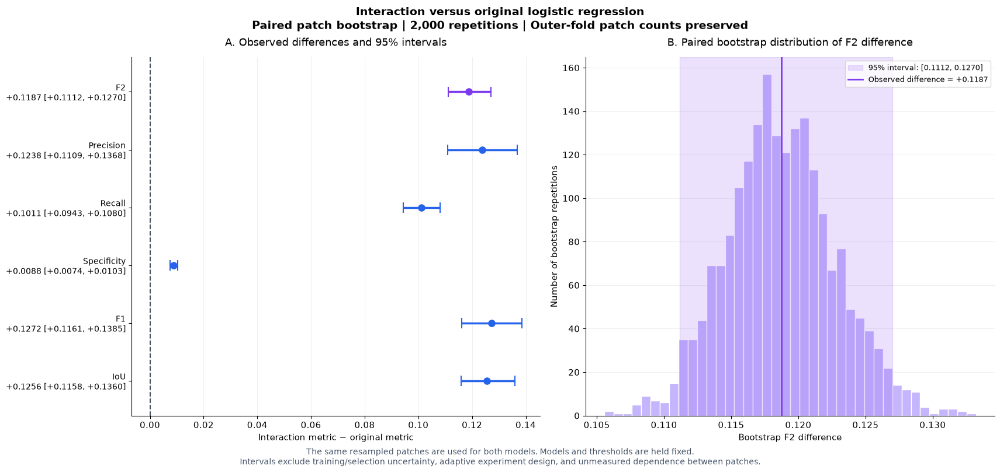

In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Align both models by outer fold and patch ID.
# ------------------------------------------------------------
PAIR_BOOTSTRAP_REPETITIONS = 2000
PAIR_BOOTSTRAP_SEED = RANDOM_STATE

pair_keys = ["Outer fold", "sample_id"]

pair_value_columns = [
    "TN",
    "FP",
    "FN",
    "TP",
    "Pixels",
    "Squared error sum",
    "Log loss sum",
]

original_pair_table = lr_oof_patch_results[
    pair_keys + pair_value_columns
].copy()

interaction_pair_table = lr_interaction_oof_patch_results[
    pair_keys + pair_value_columns
].copy()

for table in (original_pair_table, interaction_pair_table):
    table["sample_id"] = table["sample_id"].astype(str)
    assert not table.duplicated(pair_keys).any()

original_keys = set(
    original_pair_table[pair_keys].itertuples(
        index=False, name=None
    )
)
interaction_keys = set(
    interaction_pair_table[pair_keys].itertuples(
        index=False, name=None
    )
)

assert original_keys == interaction_keys

lr_interaction_paired_patch_table = (
    original_pair_table.merge(
        interaction_pair_table,
        on=pair_keys,
        how="inner",
        suffixes=("_original", "_interaction"),
        validate="one_to_one",
    )
    .sort_values(pair_keys)
    .reset_index(drop=True)
)

assert len(lr_interaction_paired_patch_table) == len(dev_ids)

# Confirm that reference class counts match for each pair.
assert np.array_equal(
    lr_interaction_paired_patch_table["Pixels_original"],
    lr_interaction_paired_patch_table["Pixels_interaction"],
)

assert np.array_equal(
    lr_interaction_paired_patch_table["TP_original"]
    + lr_interaction_paired_patch_table["FN_original"],
    lr_interaction_paired_patch_table["TP_interaction"]
    + lr_interaction_paired_patch_table["FN_interaction"],
)

assert np.array_equal(
    lr_interaction_paired_patch_table["TN_original"]
    + lr_interaction_paired_patch_table["FP_original"],
    lr_interaction_paired_patch_table["TN_interaction"]
    + lr_interaction_paired_patch_table["FP_interaction"],
)

pair_arrays_by_fold = {}

for fold, subset in lr_interaction_paired_patch_table.groupby(
    "Outer fold",
    sort=True,
):
    original_array = subset[
        [f"{column}_original" for column in pair_value_columns]
    ].to_numpy(dtype=np.float64)

    interaction_array = subset[
        [f"{column}_interaction" for column in pair_value_columns]
    ].to_numpy(dtype=np.float64)

    assert np.isfinite(original_array).all()
    assert np.isfinite(interaction_array).all()

    pair_arrays_by_fold[int(fold)] = (
        original_array,
        interaction_array,
    )

assert set(pair_arrays_by_fold) == {1, 2, 3, 4, 5}


# ------------------------------------------------------------
# 2. Convert pooled sufficient statistics into metrics.
# ------------------------------------------------------------
paired_metric_names = [
    "F2",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "IoU",
    "Brier score",
    "Log loss",
]


def paired_metrics_from_totals(totals):
    tn, fp, fn, tp = (
        int(value) for value in totals[:4]
    )

    result = metrics_from_counts(tn, fp, fn, tp)

    result["Brier score"] = float(
        totals[5] / totals[4]
    )
    result["Log loss"] = float(
        totals[6] / totals[4]
    )

    return {
        metric: float(result[metric])
        for metric in paired_metric_names
    }


original_observed_totals = np.zeros(
    len(pair_value_columns),
    dtype=np.float64,
)
interaction_observed_totals = np.zeros_like(
    original_observed_totals
)

for original_array, interaction_array in (
    pair_arrays_by_fold.values()
):
    original_observed_totals += original_array.sum(axis=0)
    interaction_observed_totals += interaction_array.sum(axis=0)

lr_pair_original_observed = paired_metrics_from_totals(
    original_observed_totals
)
lr_pair_interaction_observed = paired_metrics_from_totals(
    interaction_observed_totals
)


# ------------------------------------------------------------
# 3. Paired whole-patch bootstrap, preserving outer-fold sizes.
# ------------------------------------------------------------
paired_rng = np.random.default_rng(
    PAIR_BOOTSTRAP_SEED
)

paired_bootstrap_records = []

for repetition in range(PAIR_BOOTSTRAP_REPETITIONS):
    original_totals = np.zeros(
        len(pair_value_columns),
        dtype=np.float64,
    )
    interaction_totals = np.zeros_like(original_totals)

    for original_array, interaction_array in (
        pair_arrays_by_fold.values()
    ):
        number_of_patches = len(original_array)

        sampled_rows = paired_rng.integers(
            0,
            number_of_patches,
            size=number_of_patches,
        )

        # Exactly the same sampled rows for both models.
        original_totals += original_array[
            sampled_rows
        ].sum(axis=0)

        interaction_totals += interaction_array[
            sampled_rows
        ].sum(axis=0)

    original_scores = paired_metrics_from_totals(
        original_totals
    )
    interaction_scores = paired_metrics_from_totals(
        interaction_totals
    )

    record = {}

    for metric in paired_metric_names:
        record[f"Original {metric}"] = original_scores[metric]
        record[f"Interaction {metric}"] = interaction_scores[metric]
        record[f"Difference {metric}"] = (
            interaction_scores[metric] - original_scores[metric]
        )

    paired_bootstrap_records.append(record)

lr_interaction_paired_bootstrap_scores = pd.DataFrame(
    paired_bootstrap_records
)

assert np.isfinite(
    lr_interaction_paired_bootstrap_scores.to_numpy()
).all()


# ------------------------------------------------------------
# 4. Summarize observed scores and difference intervals.
# ------------------------------------------------------------
paired_ci_records = []

for metric in paired_metric_names:
    original_ci = np.percentile(
        lr_interaction_paired_bootstrap_scores[
            f"Original {metric}"
        ],
        [2.5, 97.5],
    )

    interaction_ci = np.percentile(
        lr_interaction_paired_bootstrap_scores[
            f"Interaction {metric}"
        ],
        [2.5, 97.5],
    )

    difference_ci = np.percentile(
        lr_interaction_paired_bootstrap_scores[
            f"Difference {metric}"
        ],
        [2.5, 97.5],
    )

    paired_ci_records.append({
        "Metric": metric,
        "Original estimate": lr_pair_original_observed[metric],
        "Original CI lower": original_ci[0],
        "Original CI upper": original_ci[1],
        "Interaction estimate": lr_pair_interaction_observed[metric],
        "Interaction CI lower": interaction_ci[0],
        "Interaction CI upper": interaction_ci[1],
        "Difference": (
            lr_pair_interaction_observed[metric]
            - lr_pair_original_observed[metric]
        ),
        "Difference CI lower": difference_ci[0],
        "Difference CI upper": difference_ci[1],
        "Favorable direction": (
            "Negative"
            if metric in ["Brier score", "Log loss"]
            else "Positive"
        ),
    })

lr_interaction_paired_bootstrap_ci = pd.DataFrame(
    paired_ci_records
)

print("Pooled out-of-fold scores — not fold-average scores:")
display(
    lr_interaction_paired_bootstrap_ci[
        [
            "Metric",
            "Original estimate",
            "Interaction estimate",
        ]
    ].round(6)
)

print(
    "\nPaired differences: interaction minus original\n"
    "95% percentile confidence intervals"
)
display(
    lr_interaction_paired_bootstrap_ci[
        [
            "Metric",
            "Difference",
            "Difference CI lower",
            "Difference CI upper",
            "Favorable direction",
        ]
    ].round(6)
)


# ------------------------------------------------------------
# 5. Plot paired differences and the F2 difference distribution.
# ------------------------------------------------------------
difference_lookup = (
    lr_interaction_paired_bootstrap_ci.set_index("Metric")
)

plot_metric_names = [
    "F2", "Precision", "Recall",
    "Specificity", "F1", "IoU",
]

f2_difference = float(
    difference_lookup.loc["F2", "Difference"]
)
f2_difference_lower = float(
    difference_lookup.loc["F2", "Difference CI lower"]
)
f2_difference_upper = float(
    difference_lookup.loc["F2", "Difference CI upper"]
)

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(17, 8),
        layout="constrained",
    )

    fig.suptitle(
        "Interaction versus original logistic regression\n"
        f"Paired patch bootstrap | "
        f"{PAIR_BOOTSTRAP_REPETITIONS:,} repetitions | "
        "Outer-fold patch counts preserved",
        fontsize=14,
        fontweight="bold",
    )

    tick_labels = []

    for position, metric in enumerate(plot_metric_names):
        row = difference_lookup.loc[metric]

        estimate = float(row["Difference"])
        lower = float(row["Difference CI lower"])
        upper = float(row["Difference CI upper"])

        color = "#7C3AED" if metric == "F2" else "#2563EB"

        axes[0].hlines(
            position, lower, upper,
            color=color,
            linewidth=2.5,
        )
        axes[0].vlines(
            [lower, upper],
            position - 0.09,
            position + 0.09,
            color=color,
            linewidth=1.5,
        )
        axes[0].scatter(
            estimate,
            position,
            color=color,
            s=65,
            zorder=4,
        )

        tick_labels.append(
            f"{metric}\n"
            f"{estimate:+.4f} [{lower:+.4f}, {upper:+.4f}]"
        )

    axes[0].axvline(
        0,
        color="#475569",
        linestyle="--",
        linewidth=1.5,
    )
    axes[0].set_yticks(range(len(plot_metric_names)))
    axes[0].set_yticklabels(tick_labels, fontsize=10)
    axes[0].set_ylim(len(plot_metric_names) - 0.4, -0.6)
    axes[0].set_xlabel(
        "Interaction metric − original metric"
    )
    axes[0].set_title(
        "A. Observed differences and 95% intervals",
        pad=14,
    )
    axes[0].grid(axis="x", alpha=0.2)

    axes[1].hist(
        lr_interaction_paired_bootstrap_scores["Difference F2"],
        bins=40,
        color="#C4B5FD",
        edgecolor="white",
    )
    axes[1].axvspan(
        f2_difference_lower,
        f2_difference_upper,
        color="#7C3AED",
        alpha=0.15,
        label=(
            f"95% interval: "
            f"[{f2_difference_lower:.4f}, "
            f"{f2_difference_upper:.4f}]"
        ),
    )
    axes[1].axvline(
        f2_difference,
        color="#7C3AED",
        linewidth=2,
        label=f"Observed difference = {f2_difference:+.4f}",
    )
    axes[1].set_xlabel("Bootstrap F2 difference")
    axes[1].set_ylabel("Number of bootstrap repetitions")
    axes[1].set_title(
        "B. Paired bootstrap distribution of F2 difference",
        pad=14,
    )
    axes[1].legend(loc="best", fontsize=9)
    axes[1].grid(axis="y", alpha=0.2)

    for ax in axes:
        ax.set_axisbelow(True)
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)

    fig.supxlabel(
        "The same resampled patches are used for both models. "
        "Models and thresholds are held fixed.\n"
        "Intervals exclude training/selection uncertainty, adaptive "
        "experiment design, and unmeasured dependence between patches.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

This analysis estimates paired differences between the two models using 2,000 whole-patch bootstrap resamples, preserving outer-fold sizes. Each resample uses identical patches for both models. Percentile intervals are calculated for differences in pooled out-of-fold metrics. They are conditional on the fitted models and thresholds and do not account for training uncertainty, adaptive experiment design, or unmeasured dependence between patches.

Pooled out-of-fold F2 increased from 0.629068 to 0.747800. The paired difference was +0.118732, with a 95% patch-bootstrap interval of [+0.111181, +0.127020]. Intervals also favored the interaction model for precision, recall, specificity, F1, IoU, Brier score, and log loss. These results support the interaction extension within the current exploratory development analysis, conditional on the fitted models and fixed thresholds. They do not establish geographic generalization or account for training and adaptive-selection uncertainty.

Interaction predictors: 105
Training pixels per patch: 512
Class weight: None
C candidates: 0.1, 1, 10
Full-development validation folds: 3
New base-model fits: 9
Calibration selection follows in the next step.
[1/9] C=0.1, fold=1 | iterations=108, fit=10.4s | Full-patch validation completed
[2/9] C=0.1, fold=2 | iterations=115, fit=9.9s | Full-patch validation completed
[3/9] C=0.1, fold=3 | iterations=118, fit=10.6s | Full-patch validation completed
[4/9] C=1, fold=1 | iterations=139, fit=12.3s | Full-patch validation completed
[5/9] C=1, fold=2 | iterations=129, fit=10.8s | Full-patch validation completed
[6/9] C=1, fold=3 | iterations=109, fit=9.8s | Full-patch validation completed
[7/9] C=10, fold=1 | iterations=117, fit=10.5s | Full-patch validation completed
[8/9] C=10, fold=2 | iterations=124, fit=10.3s | Full-patch validation completed
[9/9] C=10, fold=3 | iterations=150, fit=12.8s | Full-patch validation completed

Each C at its selected preliminary threshold:


,C,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,0.1,0.11,0.748781,0.006412,0.517101,0.843342,0.980889,0.471757
1,1.0,0.11,0.749376,0.006298,0.517127,0.844248,0.980873,0.472074
2,10.0,0.11,0.749138,0.006444,0.517038,0.843961,0.980869,0.471893



Selected candidate — calibration still pending:


,Selected value
C,1.000000
Threshold,0.110000
Mean_F2,0.749376
SD_F2,0.006298
Mean_precision,0.517127
Mean_recall,0.844248
Mean_specificity,0.980873
Mean_IoU,0.472074
Fold_count,3.000000



Fitting details:


,C,Inner fold,Training patches,Validation patches,Iterations,Fit seconds
0,0.1,1,2026,1013,108,10.358
1,0.1,2,2026,1013,115,9.882
2,0.1,3,2026,1013,118,10.616
3,1.0,1,2026,1013,139,12.317
4,1.0,2,2026,1013,129,10.801
5,1.0,3,2026,1013,109,9.765
6,10.0,1,2026,1013,117,10.517
7,10.0,2,2026,1013,124,10.301
8,10.0,3,2026,1013,150,12.834


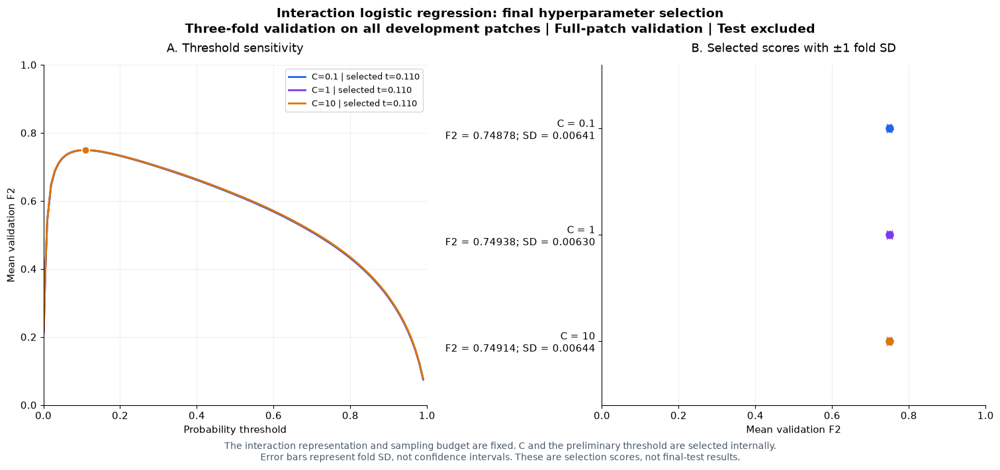


Elapsed time: 6.5 minutes.


In [84]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Use the existing full-development three-fold splits.
# ------------------------------------------------------------
lr_interaction_final_inner_splits = lr_final_inner_splits

all_interaction_development_ids = set(map(str, dev_ids))
reserved_interaction_test_ids = set(map(str, test_ids))

assert len(lr_interaction_final_inner_splits) == 3
assert all_interaction_development_ids.isdisjoint(
    reserved_interaction_test_ids
)

for split in lr_interaction_final_inner_splits:
    training_ids = set(map(str, split["train_ids"]))
    validation_ids = set(map(str, split["validation_ids"]))

    assert training_ids.isdisjoint(validation_ids)
    assert (
        training_ids | validation_ids
    ) == all_interaction_development_ids

    assert training_ids.isdisjoint(reserved_interaction_test_ids)
    assert validation_ids.isdisjoint(reserved_interaction_test_ids)

print("Interaction predictors: 105")
print("Training pixels per patch: 512")
print("Class weight: None")
print("C candidates: 0.1, 1, 10")
print("Full-development validation folds: 3")
print("New base-model fits: 9")
print("Calibration selection follows in the next step.")


# ------------------------------------------------------------
# 2. Search C and preliminary threshold on development data.
# Reuse the checked interaction-pipeline fitting helper.
# ------------------------------------------------------------
final_interaction_search_tables = []
final_interaction_fit_records = []

final_interaction_search_start = time.perf_counter()
completed_fits = 0

for c_value in INTERACTION_EXTENSION_C_VALUES:
    for inner_fold, split in enumerate(
        lr_interaction_final_inner_splits,
        start=1,
    ):
        fit_start = time.perf_counter()

        model = interaction_fit_base(
            split["train_ids"],
            c_value,
        )

        fit_seconds = time.perf_counter() - fit_start

        scores = evaluate_full_patches_at_thresholds(
            model,
            split["validation_ids"],
            THRESHOLDS,
        )

        scores["C"] = c_value
        scores["Inner fold"] = inner_fold

        final_interaction_search_tables.append(scores)

        iterations = int(
            model.named_steps["classifier"].n_iter_.max()
        )

        final_interaction_fit_records.append({
            "C": c_value,
            "Inner fold": inner_fold,
            "Training patches": len(split["train_ids"]),
            "Validation patches": len(split["validation_ids"]),
            "Iterations": iterations,
            "Fit seconds": fit_seconds,
        })

        completed_fits += 1

        print(
            f"[{completed_fits}/9] "
            f"C={c_value:g}, fold={inner_fold} | "
            f"iterations={iterations}, fit={fit_seconds:.1f}s | "
            "Full-patch validation completed",
            flush=True,
        )

        del model


# ------------------------------------------------------------
# 3. Select using the same deterministic rule.
# ------------------------------------------------------------
lr_interaction_final_search_results = pd.concat(
    final_interaction_search_tables,
    ignore_index=True,
)

lr_interaction_final_fit_log = pd.DataFrame(
    final_interaction_fit_records
)

lr_interaction_final_search_summary = (
    interaction_summarize_inner(
        lr_interaction_final_search_results,
        ["C", "Threshold"],
    )
)

lr_interaction_final_search_ranked = (
    lr_interaction_final_search_summary
    .sort_values(
        ["Mean_F2", "Mean_precision", "C", "Threshold"],
        ascending=[False, False, True, False],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

lr_interaction_final_search_selected = (
    lr_interaction_final_search_ranked.iloc[0].copy()
)

lr_interaction_final_best_per_c = (
    lr_interaction_final_search_ranked
    .drop_duplicates("C")
    .sort_values("C")
    .reset_index(drop=True)
)

print("\nEach C at its selected preliminary threshold:")
display(
    lr_interaction_final_best_per_c[
        [
            "C",
            "Threshold",
            "Mean_F2",
            "SD_F2",
            "Mean_precision",
            "Mean_recall",
            "Mean_specificity",
            "Mean_IoU",
        ]
    ].round(6)
)

print("\nSelected candidate — calibration still pending:")
display(
    lr_interaction_final_search_selected
    .to_frame("Selected value")
)

print("\nFitting details:")
display(lr_interaction_final_fit_log.round(3))


# ------------------------------------------------------------
# 4. Show threshold sensitivity and selected scores.
# ------------------------------------------------------------
c_colors = {
    0.1: "#2563EB",
    1.0: "#7C3AED",
    10.0: "#D97706",
}

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(15, 7),
        layout="constrained",
    )

    fig.suptitle(
        "Interaction logistic regression: final hyperparameter selection\n"
        "Three-fold validation on all development patches | "
        "Full-patch validation | Test excluded",
        fontsize=14,
        fontweight="bold",
    )

    tick_labels = []

    for position, c_value in enumerate(
        INTERACTION_EXTENSION_C_VALUES
    ):
        curve = (
            lr_interaction_final_search_summary.loc[
                lr_interaction_final_search_summary["C"].eq(c_value)
            ]
            .sort_values("Threshold")
        )

        best = lr_interaction_final_best_per_c.loc[
            lr_interaction_final_best_per_c["C"].eq(c_value)
        ].iloc[0]

        color = c_colors[c_value]

        axes[0].plot(
            curve["Threshold"],
            curve["Mean_F2"],
            color=color,
            linewidth=2,
            label=(
                f"C={c_value:g} | "
                f"selected t={best['Threshold']:.3f}"
            ),
        )
        axes[0].scatter(
            best["Threshold"],
            best["Mean_F2"],
            color=color,
            edgecolor="white",
            s=65,
            zorder=5,
        )

        axes[1].errorbar(
            best["Mean_F2"],
            position,
            xerr=best["SD_F2"],
            fmt="o",
            color=color,
            markersize=8,
            capsize=5,
            elinewidth=2,
        )

        tick_labels.append(
            f"C = {c_value:g}\n"
            f"F2 = {best['Mean_F2']:.5f}; "
            f"SD = {best['SD_F2']:.5f}"
        )

    axes[0].set(
        xlabel="Probability threshold",
        ylabel="Mean validation F2",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    axes[0].set_title(
        "A. Threshold sensitivity",
        pad=14,
    )
    axes[0].legend(loc="upper right", fontsize=9)
    axes[0].grid(alpha=0.2)

    axes[1].set_yticks([0, 1, 2])
    axes[1].set_yticklabels(tick_labels)
    axes[1].set(
        xlabel="Mean validation F2",
        xlim=(0, 1),
        ylim=(2.6, -0.6),
    )
    axes[1].set_title(
        "B. Selected scores with ±1 fold SD",
        pad=14,
    )
    axes[1].grid(axis="x", alpha=0.2)

    for ax in axes:
        ax.set_axisbelow(True)
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)

    fig.supxlabel(
        "The interaction representation and sampling budget are fixed. "
        "C and the preliminary threshold are selected internally.\n"
        "Error bars represent fold SD, not confidence intervals. "
        "These are selection scores, not final-test results.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

print(
    "\nElapsed time: "
    f"{(time.perf_counter() - final_interaction_search_start) / 60:.1f} "
    "minutes."
)

Full-development three-fold validation selected C = 1 for interaction logistic regression, with mean F2 = 0.749376 and fold SD = 0.006298. The preliminary threshold was 0.11. Performance was very similar across C = 0.1, 1, and 10, indicating limited sensitivity within the tested range. Calibration and the final threshold remain to be selected; these are development-selection scores, not holdout results.

Fixed C: 1
Predictors: 105
Training pixels per patch: 512
Calibration fraction: 20%
Final-test data are excluded.
Fold 1/3 | Uncalibrated | completed in 16.8s
Fold 1/3 | Sigmoid      | completed in 17.5s
Fold 1/3 | Isotonic     | completed in 16.8s
Fold 2/3 | Uncalibrated | completed in 16.2s
Fold 2/3 | Sigmoid      | completed in 17.1s
Fold 2/3 | Isotonic     | completed in 17.0s
Fold 3/3 | Uncalibrated | completed in 16.3s
Fold 3/3 | Sigmoid      | completed in 17.4s
Fold 3/3 | Isotonic     | completed in 17.4s

Data allocation:


,Inner fold,Fitting patches,Calibration patches,Validation patches,Fitting sampled pixels,Calibration sampled pixels
0,1,1620,406,1013,829440,207872
1,2,1620,406,1013,829440,207872
2,3,1620,406,1013,829440,207872



Each method at its selected threshold:


,Method,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,Uncalibrated,0.11,0.748892,0.006270,0.518097,0.842888,0.980969,0.472430
1,Sigmoid,0.11,0.748787,0.006166,0.514738,0.844976,0.980675,0.470261
2,Isotonic,0.15,0.748164,0.005725,0.499110,0.855286,0.979150,0.460017



Selected method and final operating threshold:


,Selected value
Method,Uncalibrated
Threshold,0.11
Mean_F2,0.748892
SD_F2,0.00627
Mean_precision,0.518097
Mean_recall,0.842888
Mean_specificity,0.980969
Mean_IoU,0.47243
Fold_count,3


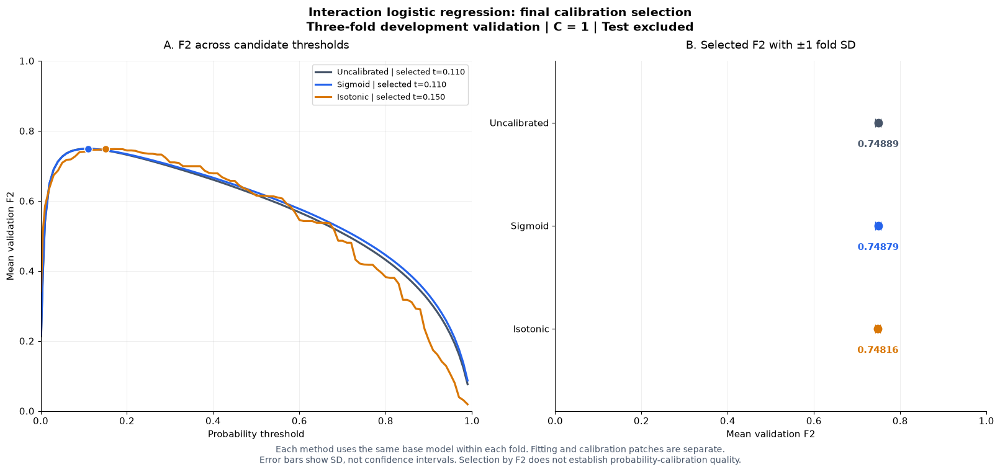


Elapsed time: 3.0 minutes.
Final interaction-model fitting remains pending.


In [85]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Fix the selected interaction-model hyperparameter.
# ------------------------------------------------------------
lr_interaction_final_c = float(
    lr_interaction_final_search_selected["C"]
)

final_interaction_methods = [
    "Uncalibrated",
    "Sigmoid",
    "Isotonic",
]

final_interaction_calibration_tables = []
final_interaction_calibration_allocation = []

calibration_step_start = time.perf_counter()

print(f"Fixed C: {lr_interaction_final_c:g}")
print("Predictors: 105")
print("Training pixels per patch: 512")
print(f"Calibration fraction: {CALIBRATION_FRACTION:.0%}")
print("Final-test data are excluded.")


# ------------------------------------------------------------
# 2. Compare methods within each development-validation fold.
# ------------------------------------------------------------
for inner_fold, split in enumerate(
    lr_interaction_final_inner_splits,
    start=1,
):
    fitting_ids, calibration_ids = (
        interaction_split_for_calibration(
            split["train_ids"],
            RANDOM_STATE + 100 + inner_fold,
        )
    )

    validation_ids = np.asarray(
        split["validation_ids"],
        dtype=str,
    )

    fitting_set = set(map(str, fitting_ids))
    calibration_set = set(map(str, calibration_ids))
    validation_set = set(validation_ids)

    assert fitting_set.isdisjoint(calibration_set)
    assert fitting_set.isdisjoint(validation_set)
    assert calibration_set.isdisjoint(validation_set)

    assert (
        fitting_set | calibration_set | validation_set
    ) == set(map(str, dev_ids))

    for patch_set in (
        fitting_set,
        calibration_set,
        validation_set,
    ):
        assert patch_set.isdisjoint(
            reserved_interaction_test_ids
        )

    base_model = interaction_fit_base(
        fitting_ids,
        lr_interaction_final_c,
    )

    final_interaction_calibration_allocation.append({
        "Inner fold": inner_fold,
        "Fitting patches": len(fitting_ids),
        "Calibration patches": len(calibration_ids),
        "Validation patches": len(validation_ids),
        "Fitting sampled pixels": (
            len(fitting_ids) * INTERACTION_EXTENSION_SAMPLE_SIZE
        ),
        "Calibration sampled pixels": (
            len(calibration_ids) * INTERACTION_EXTENSION_SAMPLE_SIZE
        ),
    })

    # All three methods share this same fitted base model.
    for method in final_interaction_methods:
        method_start = time.perf_counter()

        calibrator = interaction_fit_calibrator(
            base_model,
            calibration_ids,
            method,
        )

        probability_model = CalibratedProbabilityModel(
            base_model,
            method,
            calibrator,
        )

        scores = evaluate_full_patches_at_thresholds(
            probability_model,
            validation_ids,
            THRESHOLDS,
        )

        scores["Method"] = method
        scores["Inner fold"] = inner_fold

        final_interaction_calibration_tables.append(scores)

        print(
            f"Fold {inner_fold}/3 | {method:<12} | "
            f"completed in "
            f"{time.perf_counter() - method_start:.1f}s",
            flush=True,
        )

        del probability_model, calibrator

    del base_model


# ------------------------------------------------------------
# 3. Select method and threshold using mean validation F2.
# ------------------------------------------------------------
lr_interaction_final_calibration_results = pd.concat(
    final_interaction_calibration_tables,
    ignore_index=True,
)

lr_interaction_final_calibration_allocation = pd.DataFrame(
    final_interaction_calibration_allocation
)

lr_interaction_final_calibration_summary = (
    interaction_summarize_inner(
        lr_interaction_final_calibration_results,
        ["Method", "Threshold"],
    )
)

lr_interaction_final_calibration_ranked = (
    lr_interaction_final_calibration_summary
    .sort_values(
        ["Mean_F2", "Mean_precision", "Method", "Threshold"],
        ascending=[False, False, True, False],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

lr_interaction_final_calibration_selected = (
    lr_interaction_final_calibration_ranked.iloc[0].copy()
)

lr_interaction_final_calibration_best_per_method = (
    lr_interaction_final_calibration_ranked
    .drop_duplicates("Method")
    .reset_index(drop=True)
)

print("\nData allocation:")
display(lr_interaction_final_calibration_allocation)

print("\nEach method at its selected threshold:")
display(
    lr_interaction_final_calibration_best_per_method[
        [
            "Method",
            "Threshold",
            "Mean_F2",
            "SD_F2",
            "Mean_precision",
            "Mean_recall",
            "Mean_specificity",
            "Mean_IoU",
        ]
    ].round(6)
)

print("\nSelected method and final operating threshold:")
display(
    lr_interaction_final_calibration_selected
    .to_frame("Selected value")
)


# ------------------------------------------------------------
# 4. Visualize method and threshold selection.
# ------------------------------------------------------------
final_calibration_colors = {
    "Uncalibrated": "#475569",
    "Sigmoid": "#2563EB",
    "Isotonic": "#D97706",
}

final_calibration_lookup = (
    lr_interaction_final_calibration_best_per_method
    .set_index("Method")
)

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 7.5),
        layout="constrained",
    )

    fig.suptitle(
        "Interaction logistic regression: final calibration selection\n"
        "Three-fold development validation | "
        f"C = {lr_interaction_final_c:g} | Test excluded",
        fontsize=14,
        fontweight="bold",
    )

    for position, method in enumerate(
        final_interaction_methods
    ):
        curve = (
            lr_interaction_final_calibration_summary.loc[
                lr_interaction_final_calibration_summary[
                    "Method"
                ].eq(method)
            ]
            .sort_values("Threshold")
        )

        best = final_calibration_lookup.loc[method]
        color = final_calibration_colors[method]

        axes[0].plot(
            curve["Threshold"],
            curve["Mean_F2"],
            color=color,
            linewidth=2.3,
            label=(
                f"{method} | "
                f"selected t={best['Threshold']:.3f}"
            ),
        )
        axes[0].scatter(
            best["Threshold"],
            best["Mean_F2"],
            color=color,
            edgecolor="white",
            s=75,
            zorder=5,
        )

        axes[1].errorbar(
            best["Mean_F2"],
            position,
            xerr=best["SD_F2"],
            fmt="o",
            color=color,
            markersize=9,
            capsize=5,
            elinewidth=2,
        )

        axes[1].annotate(
            f"{best['Mean_F2']:.5f}",
            xy=(best["Mean_F2"], position),
            xytext=(0, -20),
            textcoords="offset points",
            ha="center",
            va="top",
            color=color,
            fontweight="bold",
        )

    axes[0].set(
        xlabel="Probability threshold",
        ylabel="Mean validation F2",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    axes[0].set_title(
        "A. F2 across candidate thresholds",
        pad=14,
    )
    axes[0].legend(loc="upper right", fontsize=9)
    axes[0].grid(alpha=0.2)

    axes[1].set(
        xlabel="Mean validation F2",
        xlim=(0, 1),
        ylim=(2.8, -0.6),
    )
    axes[1].set_yticks([0, 1, 2])
    axes[1].set_yticklabels(final_interaction_methods)
    axes[1].set_title(
        "B. Selected F2 with ±1 fold SD",
        pad=14,
    )
    axes[1].grid(axis="x", alpha=0.2)

    for ax in axes:
        ax.set_axisbelow(True)
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)

    fig.supxlabel(
        "Each method uses the same base model within each fold. "
        "Fitting and calibration patches are separate.\n"
        "Error bars show SD, not confidence intervals. "
        "Selection by F2 does not establish probability-calibration quality.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

print(
    "\nElapsed time: "
    f"{(time.perf_counter() - calibration_step_start) / 60:.1f} "
    "minutes."
)
print("Final interaction-model fitting remains pending.")

Full-development validation selected uncalibrated interaction logistic regression with threshold 0.11 and mean F2 = 0.748892. Differences from sigmoid and isotonic calibration were very small and do not establish meaningful superiority. “Uncalibrated” indicates that no additional calibration mapping is applied; it does not establish good probability calibration. Final fitting will use sampled pixels from all 3,039 development patches, with C = 1 and no class weighting.

Fixed final interaction-model settings:


,Value
original_features,14
expanded_features,105
interaction_degree,2
interaction_only,True
pixels_per_patch,512
C,1.0
class_weight,None
calibration_method,Uncalibrated
threshold,0.11



Final fitting summary:


,Development patches,Sampled training pixels,Predictors,Iterations,Fit seconds,Intercept,Fixed threshold
0,3039,1555968,105,144,18.634922,-7.353799,0.11



Coefficients of the original-input terms:


,Display label,Coefficient
0,B1,1.337476
1,B2,-1.047300
2,B3,0.733571
3,B4,0.937370
4,B5,2.007450
5,B6,-0.296652
6,B7,-1.984799
7,B8,-0.822116
8,B9,-0.655559
9,B10,-1.106419



Twenty terms with the largest absolute coefficients:


,Display label,Term type,Coefficient
59,B4 × Elevation,Pairwise interaction,-2.168418
4,B5,Original input,2.007450
6,B7,Original input,-1.984799
100,B11 × Slope,Pairwise interaction,-1.845623
49,B3 × Elevation,Pairwise interaction,1.747415
50,B4 × B5,Pairwise interaction,-1.517767
54,B4 × B9,Pairwise interaction,1.416604
13,Elevation,Original input,1.385390
0,B1,Original input,1.337476
17,B1 × B5,Pairwise interaction,-1.302626


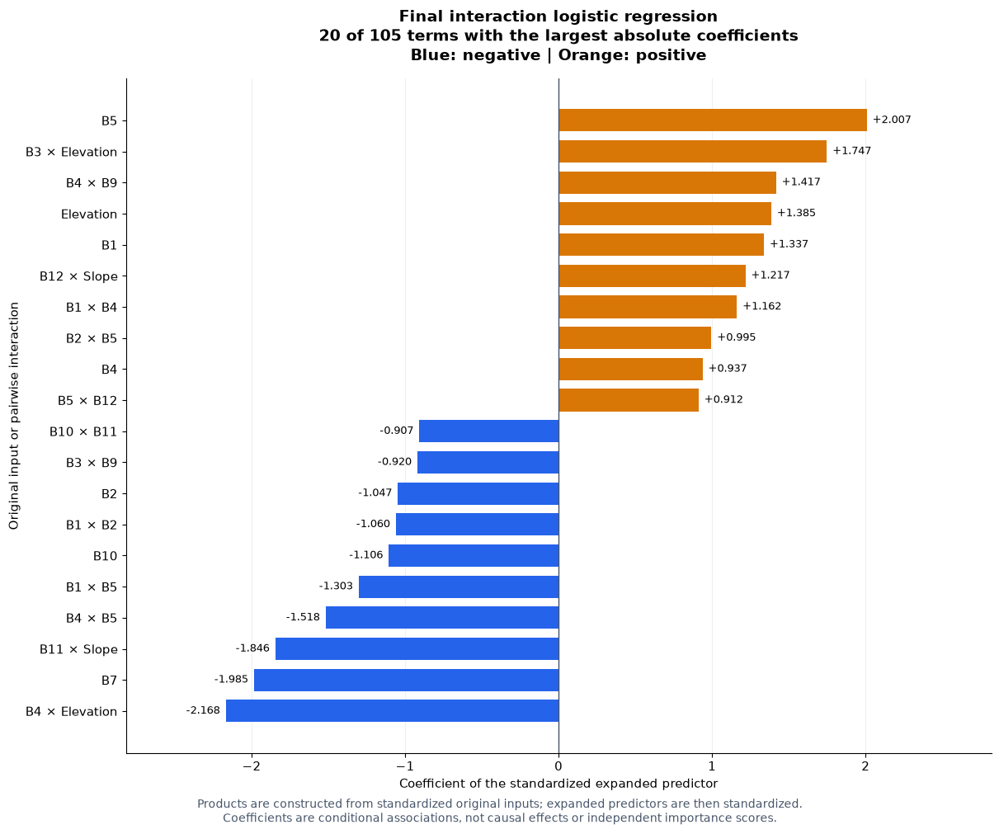


The final interaction model is fitted. No test data were used in this cell.
All 105 coefficients are retained in lr_interaction_final_coefficient_table.


In [86]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Freeze the development-selected settings.
# ------------------------------------------------------------
selected_interaction_method = str(
    lr_interaction_final_calibration_selected["Method"]
)

# This final-fitting step is for the selected uncalibrated model.
assert selected_interaction_method == "Uncalibrated", (
    "The selected method requires a separate calibration split. "
    "Do not fit that procedure on all development patches directly."
)

lr_interaction_final_settings = {
    "original_features": len(FEATURE_NAMES),
    "expanded_features": 105,
    "interaction_degree": 2,
    "interaction_only": True,
    "pixels_per_patch": INTERACTION_EXTENSION_SAMPLE_SIZE,
    "C": float(lr_interaction_final_search_selected["C"]),
    "class_weight": None,
    "calibration_method": selected_interaction_method,
    "threshold": float(
        lr_interaction_final_calibration_selected["Threshold"]
    ),
}

lr_interaction_final_training_ids = np.asarray(
    sorted(map(str, dev_ids), key=int)
)

assert len(np.unique(lr_interaction_final_training_ids)) == len(
    lr_interaction_final_training_ids
)
assert set(lr_interaction_final_training_ids).isdisjoint(
    set(map(str, test_ids))
)

print("Fixed final interaction-model settings:")
display(
    pd.Series(
        lr_interaction_final_settings,
        name="Value",
    ).to_frame()
)


# ------------------------------------------------------------
# 2. Fit using all development patches.
# The existing helper checks convergence.
# ------------------------------------------------------------
final_interaction_fit_start = time.perf_counter()

lr_interaction_final_base_model = interaction_fit_base(
    lr_interaction_final_training_ids,
    lr_interaction_final_settings["C"],
)

lr_interaction_final_probability_model = (
    CalibratedProbabilityModel(
        lr_interaction_final_base_model,
        "Uncalibrated",
    )
)

lr_interaction_final_threshold = (
    lr_interaction_final_settings["threshold"]
)

final_interaction_fit_seconds = (
    time.perf_counter() - final_interaction_fit_start
)

final_interaction_classifier = (
    lr_interaction_final_base_model.named_steps["classifier"]
)

lr_interaction_final_intercept = float(
    final_interaction_classifier.intercept_[0]
)

final_interaction_iterations = int(
    final_interaction_classifier.n_iter_.max()
)


# ------------------------------------------------------------
# 3. Retrieve all 105 coefficients and identify interaction terms.
# ------------------------------------------------------------
expanded_feature_names = (
    lr_interaction_final_base_model
    .named_steps["interactions"]
    .get_feature_names_out(FEATURE_NAMES)
)

assert len(expanded_feature_names) == 105
assert final_interaction_classifier.coef_.shape == (1, 105)

lr_interaction_final_coefficient_table = pd.DataFrame({
    "Feature": expanded_feature_names,
    "Coefficient": final_interaction_classifier.coef_[0],
})

lr_interaction_final_coefficient_table["Term type"] = [
    "Pairwise interaction" if " " in name else "Original input"
    for name in expanded_feature_names
]

lr_interaction_final_coefficient_table["Display label"] = [
    name.replace(" ", " × ")
    for name in expanded_feature_names
]

lr_interaction_final_coefficient_table["Absolute coefficient"] = (
    lr_interaction_final_coefficient_table["Coefficient"].abs()
)

assert (
    lr_interaction_final_coefficient_table["Term type"]
    .eq("Original input").sum()
) == 14

assert (
    lr_interaction_final_coefficient_table["Term type"]
    .eq("Pairwise interaction").sum()
) == 91

print("\nFinal fitting summary:")
display(pd.DataFrame([{
    "Development patches": len(lr_interaction_final_training_ids),
    "Sampled training pixels": (
        len(lr_interaction_final_training_ids)
        * lr_interaction_final_settings["pixels_per_patch"]
    ),
    "Predictors": len(expanded_feature_names),
    "Iterations": final_interaction_iterations,
    "Fit seconds": final_interaction_fit_seconds,
    "Intercept": lr_interaction_final_intercept,
    "Fixed threshold": lr_interaction_final_threshold,
}]))

print("\nCoefficients of the original-input terms:")
display(
    lr_interaction_final_coefficient_table.loc[
        lr_interaction_final_coefficient_table["Term type"]
        .eq("Original input"),
        ["Display label", "Coefficient"],
    ].round(6)
)

top_coefficient_terms = (
    lr_interaction_final_coefficient_table
    .sort_values(
        "Absolute coefficient",
        ascending=False,
        kind="mergesort",
    )
    .head(20)
    .copy()
)

print("\nTwenty terms with the largest absolute coefficients:")
display(
    top_coefficient_terms[
        ["Display label", "Term type", "Coefficient"]
    ].round(6)
)


# ------------------------------------------------------------
# 4. Plot the 20 displayed coefficients.
# These are coefficients, not independent feature importance.
# ------------------------------------------------------------
coefficient_plot = top_coefficient_terms.sort_values(
    "Coefficient"
)

plot_colors = np.where(
    coefficient_plot["Coefficient"].to_numpy() >= 0,
    "#D97706",
    "#2563EB",
)

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, ax = plt.subplots(
        figsize=(12, 10),
        layout="constrained",
    )

    bars = ax.barh(
        coefficient_plot["Display label"],
        coefficient_plot["Coefficient"],
        color=plot_colors,
        height=0.72,
    )

    ax.bar_label(
        bars,
        labels=[
            f"{value:+.3f}"
            for value in coefficient_plot["Coefficient"]
        ],
        padding=5,
        fontsize=9,
    )

    coefficient_limit = max(
        0.5,
        1.30 * float(
            coefficient_plot["Absolute coefficient"].max()
        ),
    )

    ax.set_xlim(-coefficient_limit, coefficient_limit)
    ax.axvline(0, color="#475569", linewidth=1)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    ax.set_xlabel(
        "Coefficient of the standardized expanded predictor"
    )
    ax.set_ylabel("Original input or pairwise interaction")
    ax.set_title(
        "Final interaction logistic regression\n"
        "20 of 105 terms with the largest absolute coefficients\n"
        "Blue: negative | Orange: positive",
        fontsize=14,
        fontweight="bold",
        pad=16,
    )

    ax.spines["left"].set_visible(True)
    ax.spines["bottom"].set_visible(True)

    fig.supxlabel(
        "Products are constructed from standardized original inputs; "
        "expanded predictors are then standardized.\n"
        "Coefficients are conditional associations, not causal effects "
        "or independent importance scores.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

print(
    "\nThe final interaction model is fitted. "
    "No test data were used in this cell."
)
print(
    "All 105 coefficients are retained in "
    "lr_interaction_final_coefficient_table."
)

The final interaction model was fitted on 1,555,968 sampled pixels from all 3,039 development patches. Training completed in 144 iterations, with C = 1, no additional calibration, and a fixed threshold of 0.11. The coefficient plot includes original inputs and pairwise interaction terms; their signs describe conditional contributions in the expanded representation, not causal effects or independent importance. Secondary evaluation on the previously inspected holdout remains pending.

Secondary evaluation on the previously inspected holdout.
Patches: 760
Pixels: 12,451,840
Fixed threshold: 0.110
No training, calibration, or threshold selection is performed.
Predicted 100/760 patches
Predicted 200/760 patches
Predicted 300/760 patches
Predicted 400/760 patches
Predicted 500/760 patches
Predicted 600/760 patches
Predicted 700/760 patches
Predicted 760/760 patches

Same-image comparison:


,Metric,Original LR,Interaction LR,Interaction minus original
0,F2,0.611569,0.743009,0.131440
1,Precision,0.360416,0.511054,0.150638
2,Recall,0.740588,0.838108,0.097520
3,Specificity,0.971380,0.982538,0.011158
4,F1,0.484866,0.634940,0.150074
5,IoU,0.320015,0.465137,0.145122
6,Balanced accuracy,0.855984,0.910323,0.054339
7,Accuracy,0.966462,0.979460,0.012998
8,Brier score,0.014044,0.009761,-0.004282
9,Log loss,0.053596,0.035182,-0.018414



Interaction-model confusion counts:


,Count,Pixels
0,TN,"11,973,663"
1,FP,"212,796"
2,FN,"42,963"
3,TP,"222,418"



Lower is better for Brier score and log loss; higher is better for the other listed scores.


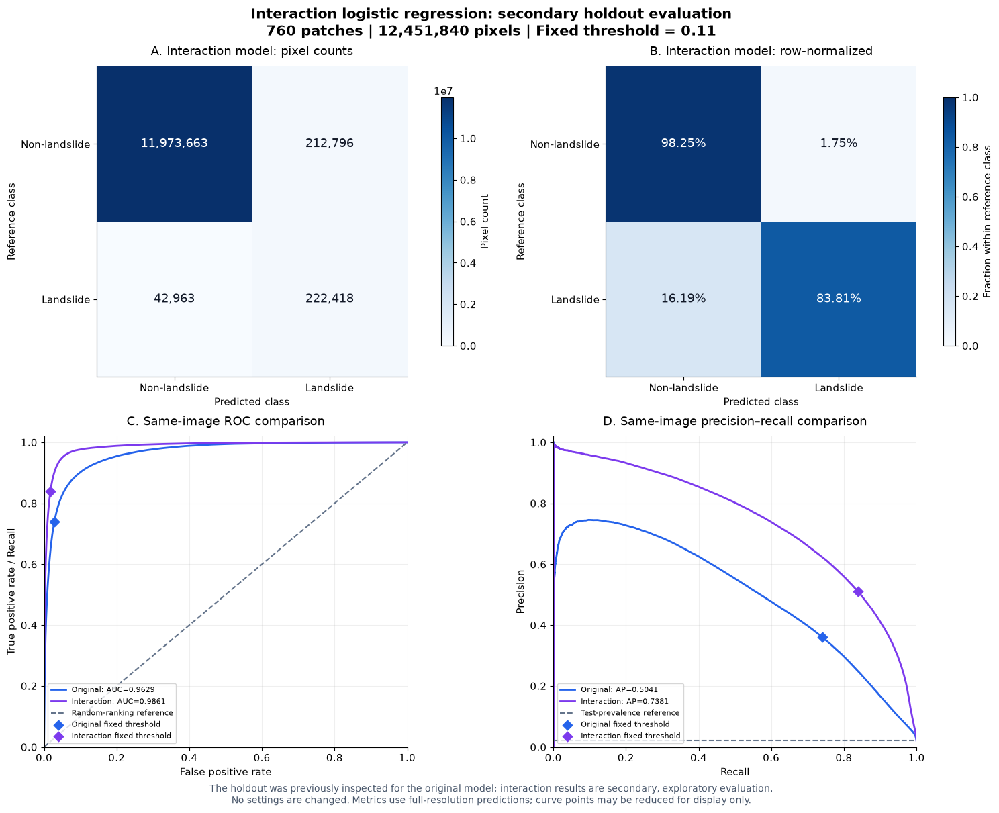


Evaluation completed in 0.5 minutes.
Predictions and patch-level results are retained for paired uncertainty and spatial comparisons.


In [87]:
import time

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    auc,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
)


# ------------------------------------------------------------
# 1. Verify the fixed final model and test-patch alignment.
# ------------------------------------------------------------
secondary_test_manifest = (
    lr_test_patch_results
    .sort_values("Start")
    .copy()
)

secondary_test_manifest["sample_id"] = (
    secondary_test_manifest["sample_id"].astype(str)
)

assert secondary_test_manifest["sample_id"].is_unique

assert set(
    secondary_test_manifest["sample_id"]
) == set(map(str, test_ids))

assert set(
    secondary_test_manifest["sample_id"]
).isdisjoint(lr_interaction_final_training_ids)

assert np.isclose(
    lr_interaction_final_threshold,
    lr_interaction_final_settings["threshold"],
)

secondary_pixel_count = len(lr_test_y)

assert int(
    secondary_test_manifest["Pixels"].sum()
) == secondary_pixel_count

assert np.array_equal(
    secondary_test_manifest["Start"].to_numpy(dtype=int),
    np.arange(len(secondary_test_manifest)) * (128 * 128),
)

lr_interaction_secondary_test_probability = np.empty(
    secondary_pixel_count,
    dtype=np.float64,
)

secondary_positive_index = int(
    np.flatnonzero(
        np.asarray(
            lr_interaction_final_probability_model.classes_
        ) == 1
    )[0]
)

secondary_patch_records = []
secondary_test_start = time.perf_counter()

print("Secondary evaluation on the previously inspected holdout.")
print(f"Patches: {len(secondary_test_manifest):,}")
print(f"Pixels: {secondary_pixel_count:,}")
print(f"Fixed threshold: {lr_interaction_final_threshold:.3f}")
print("No training, calibration, or threshold selection is performed.")


# ------------------------------------------------------------
# 2. Predict each image; reuse the cached reference labels.
# ------------------------------------------------------------
for patch_number, (_, patch_row) in enumerate(
    secondary_test_manifest.iterrows(),
    start=1,
):
    sample_id = str(patch_row["sample_id"])
    start = int(patch_row["Start"])
    stop = int(patch_row["Stop"])

    image_path = (
        DATA_DIR / "TrainData" / "img"
        / f"image_{sample_id}.h5"
    )

    with h5py.File(image_path, "r") as image_file:
        image_array = np.asarray(
            image_file["img"],
            dtype=np.float32,
        )

    assert image_array.shape == (128, 128, 14)
    assert np.isfinite(image_array).all()

    reference = lr_test_y[start:stop]
    assert reference.size == 128 * 128

    probabilities = np.asarray(
        lr_interaction_final_probability_model.predict_proba(
            image_array.reshape(-1, 14)
        )[:, secondary_positive_index],
        dtype=np.float64,
    )

    assert np.isfinite(probabilities).all()
    assert (
        (probabilities >= 0)
        & (probabilities <= 1)
    ).all()

    lr_interaction_secondary_test_probability[
        start:stop
    ] = probabilities

    prediction = (
        probabilities >= lr_interaction_final_threshold
    ).astype(np.uint8)

    tn, fp, fn, tp = confusion_matrix(
        reference,
        prediction,
        labels=[0, 1],
    ).ravel()

    reference_float = reference.astype(np.float64)

    # Convert to float64 above, then clip before logarithms.
    clipped = np.clip(
        probabilities,
        1e-15,
        1.0 - 1e-15,
    )

    squared_error_sum = float(
        np.sum((probabilities - reference_float) ** 2)
    )
    log_loss_sum = float(
        -np.sum(
            reference_float * np.log(clipped)
            + (1.0 - reference_float) * np.log1p(-clipped)
        )
    )

    assert np.isfinite(log_loss_sum)

    secondary_patch_records.append({
        "sample_id": sample_id,
        "Start": start,
        "Stop": stop,
        "Pixels": reference.size,
        "Positive pixels": int(reference.sum()),
        "Landslide coverage (%)": 100 * float(reference.mean()),
        "Threshold": lr_interaction_final_threshold,
        "Squared error sum": squared_error_sum,
        "Log loss sum": log_loss_sum,
        **metrics_from_counts(tn, fp, fn, tp),
    })

    if patch_number % 100 == 0 or patch_number == len(
        secondary_test_manifest
    ):
        print(
            f"Predicted {patch_number:,}/"
            f"{len(secondary_test_manifest):,} patches",
            flush=True,
        )

lr_interaction_secondary_test_patch_results = pd.DataFrame(
    secondary_patch_records
)


# ------------------------------------------------------------
# 3. Calculate pooled metrics and full-resolution ranking scores.
# ------------------------------------------------------------
lr_interaction_secondary_test_metrics = (
    interaction_pooled_scores(
        lr_interaction_secondary_test_patch_results
    )
)

(
    lr_interaction_secondary_test_fpr,
    lr_interaction_secondary_test_tpr,
    _,
) = roc_curve(
    lr_test_y,
    lr_interaction_secondary_test_probability,
    drop_intermediate=True,
)

interaction_secondary_auc = float(
    auc(
        lr_interaction_secondary_test_fpr,
        lr_interaction_secondary_test_tpr,
    )
)

(
    lr_interaction_secondary_test_pr_precision,
    lr_interaction_secondary_test_pr_recall,
    _,
) = precision_recall_curve(
    lr_test_y,
    lr_interaction_secondary_test_probability,
)

interaction_secondary_ap = float(
    -np.sum(
        np.diff(lr_interaction_secondary_test_pr_recall)
        * lr_interaction_secondary_test_pr_precision[:-1]
    )
)

lr_interaction_secondary_test_metrics["ROC AUC"] = (
    interaction_secondary_auc
)
lr_interaction_secondary_test_metrics["Average precision"] = (
    interaction_secondary_ap
)

secondary_metric_order = [
    "F2",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "IoU",
    "Balanced accuracy",
    "Accuracy",
    "Brier score",
    "Log loss",
    "ROC AUC",
    "Average precision",
]

lr_interaction_secondary_test_comparison = pd.DataFrame({
    "Metric": secondary_metric_order,
    "Original LR": [
        lr_test_metrics[metric]
        for metric in secondary_metric_order
    ],
    "Interaction LR": [
        lr_interaction_secondary_test_metrics[metric]
        for metric in secondary_metric_order
    ],
})

lr_interaction_secondary_test_comparison[
    "Interaction minus original"
] = (
    lr_interaction_secondary_test_comparison["Interaction LR"]
    - lr_interaction_secondary_test_comparison["Original LR"]
)

assert np.isfinite(
    lr_interaction_secondary_test_comparison[
        [
            "Original LR",
            "Interaction LR",
            "Interaction minus original",
        ]
    ].to_numpy(dtype=float)
).all()

print("\nSame-image comparison:")
display(
    lr_interaction_secondary_test_comparison.round(6)
)

secondary_counts = {
    name: int(lr_interaction_secondary_test_metrics[name])
    for name in ["TN", "FP", "FN", "TP"]
}

print("\nInteraction-model confusion counts:")
display(pd.DataFrame({
    "Count": list(secondary_counts),
    "Pixels": [
        f"{value:,}" for value in secondary_counts.values()
    ],
}))

print(
    "\nLower is better for Brier score and log loss; "
    "higher is better for the other listed scores."
)


# ------------------------------------------------------------
# 4. Confusion matrices and same-image ROC / PR comparisons.
# ------------------------------------------------------------
secondary_confusion = np.array([
    [secondary_counts["TN"], secondary_counts["FP"]],
    [secondary_counts["FN"], secondary_counts["TP"]],
], dtype=np.int64)

secondary_row_totals = secondary_confusion.sum(
    axis=1,
    keepdims=True,
)

secondary_normalized_confusion = np.divide(
    secondary_confusion,
    secondary_row_totals,
    out=np.zeros((2, 2), dtype=float),
    where=secondary_row_totals != 0,
)


def secondary_curve_indices(length, maximum_points=4000):
    """Reduce display resolution only, not metric calculations."""
    if length <= maximum_points:
        return np.arange(length)

    linear = np.linspace(
        0, length - 1, maximum_points // 2
    ).astype(int)

    edge = np.geomspace(
        1, length, maximum_points // 2
    ).astype(int) - 1

    return np.unique(np.r_[
        0,
        linear,
        edge,
        length - 1 - edge,
        length - 1,
    ])


with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(15, 12),
        layout="constrained",
    )

    fig.suptitle(
        "Interaction logistic regression: secondary holdout evaluation\n"
        f"{len(secondary_test_manifest):,} patches | "
        f"{secondary_pixel_count:,} pixels | "
        f"Fixed threshold = {lr_interaction_final_threshold:.2f}",
        fontsize=15,
        fontweight="bold",
    )

    labels = ["Non-landslide", "Landslide"]

    for ax, matrix, title, normalized in [
        (
            axes[0, 0],
            secondary_confusion,
            "A. Interaction model: pixel counts",
            False,
        ),
        (
            axes[0, 1],
            secondary_normalized_confusion,
            "B. Interaction model: row-normalized",
            True,
        ),
    ]:
        image = ax.imshow(
            matrix,
            cmap="Blues",
            vmin=0,
            vmax=1 if normalized else None,
        )

        for row in range(2):
            for column in range(2):
                value = matrix[row, column]
                text = (
                    f"{value:.2%}"
                    if normalized
                    else f"{int(value):,}"
                )
                cutoff = 0.5 if normalized else matrix.max() / 2

                ax.text(
                    column,
                    row,
                    text,
                    ha="center",
                    va="center",
                    fontsize=13,
                    color="white" if value > cutoff else "#111827",
                )

        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(labels)
        ax.set_yticklabels(labels)
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Reference class")
        ax.set_title(title, pad=12)

        fig.colorbar(
            image,
            ax=ax,
            shrink=0.8,
            label=(
                "Fraction within reference class"
                if normalized else "Pixel count"
            ),
        )

    # ROC curves.
    for fpr, tpr, color, label in [
        (
            lr_test_fpr,
            lr_test_tpr,
            "#2563EB",
            f"Original: AUC={lr_test_metrics['ROC AUC']:.4f}",
        ),
        (
            lr_interaction_secondary_test_fpr,
            lr_interaction_secondary_test_tpr,
            "#7C3AED",
            f"Interaction: AUC={interaction_secondary_auc:.4f}",
        ),
    ]:
        indices = secondary_curve_indices(len(fpr))
        axes[1, 0].plot(
            fpr[indices],
            tpr[indices],
            color=color,
            linewidth=2,
            label=label,
        )

    axes[1, 0].plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="#64748B",
        label="Random-ranking reference",
    )

    # PR curves.
    for recall, precision, color, label in [
        (
            lr_test_pr_recall,
            lr_test_pr_precision,
            "#2563EB",
            f"Original: AP={lr_test_metrics['Average precision']:.4f}",
        ),
        (
            lr_interaction_secondary_test_pr_recall,
            lr_interaction_secondary_test_pr_precision,
            "#7C3AED",
            f"Interaction: AP={interaction_secondary_ap:.4f}",
        ),
    ]:
        indices = secondary_curve_indices(len(recall))
        axes[1, 1].plot(
            recall[indices],
            precision[indices],
            color=color,
            linewidth=2,
            label=label,
        )

    axes[1, 1].axhline(
        float(lr_test_y.mean()),
        linestyle="--",
        color="#64748B",
        label="Test-prevalence reference",
    )

    # Mark each model's fixed operating point.
    for scores, color, name in [
        (lr_test_metrics, "#2563EB", "Original fixed threshold"),
        (
            lr_interaction_secondary_test_metrics,
            "#7C3AED",
            "Interaction fixed threshold",
        ),
    ]:
        axes[1, 0].scatter(
            1 - scores["Specificity"],
            scores["Recall"],
            color=color,
            marker="D",
            s=55,
            zorder=5,
            label=name,
        )
        axes[1, 1].scatter(
            scores["Recall"],
            scores["Precision"],
            color=color,
            marker="D",
            s=55,
            zorder=5,
            label=name,
        )

    axes[1, 0].set(
        xlabel="False positive rate",
        ylabel="True positive rate / Recall",
        xlim=(0, 1),
        ylim=(0, 1.02),
    )
    axes[1, 0].set_title("C. Same-image ROC comparison", pad=12)

    axes[1, 1].set(
        xlabel="Recall",
        ylabel="Precision",
        xlim=(0, 1),
        ylim=(0, 1.02),
    )
    axes[1, 1].set_title(
        "D. Same-image precision–recall comparison",
        pad=12,
    )

    for ax in axes[1]:
        ax.grid(alpha=0.2)
        ax.set_axisbelow(True)
        ax.legend(loc="lower left", fontsize=8)

    fig.supxlabel(
        "The holdout was previously inspected for the original model; "
        "interaction results are secondary, exploratory evaluation.\n"
        "No settings are changed. Metrics use full-resolution predictions; "
        "curve points may be reduced for display only.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

print(
    "\nEvaluation completed in "
    f"{(time.perf_counter() - secondary_test_start) / 60:.1f} minutes."
)
print(
    "Predictions and patch-level results are retained for "
    "paired uncertainty and spatial comparisons."
)

On the previously inspected holdout, interaction logistic regression achieved F2 = 0.743009, compared with 0.611569 for the original model. Recall increased to 0.838108 and precision to 0.511054. The interaction model detected 25,880 additional landslide pixels and produced 135,975 fewer false positives. ROC AUC, average precision, Brier score, and log loss also improved. This compares the complete fitted procedures and does not isolate the effect of interaction terms alone. Results are secondary exploratory evaluation; paired uncertainty, reliability, and spatial comparisons remain pending.

Interaction model: 95% patch-bootstrap confidence intervals


,Metric,Interaction estimate,Interaction CI lower,Interaction CI upper
0,F2,0.743009,0.719378,0.764317
1,Precision,0.511054,0.476746,0.544372
2,Recall,0.838108,0.816691,0.856028
3,Specificity,0.982538,0.980327,0.984559
4,F1,0.634940,0.604622,0.662386
5,IoU,0.465137,0.433303,0.495200
6,Brier score,0.009761,0.008691,0.010904
7,Log loss,0.035182,0.031683,0.038973



Paired difference: interaction minus original


,Metric,Difference,Difference CI lower,Difference CI upper,Favorable direction
0,F2,0.131440,0.113429,0.150583,Positive
1,Precision,0.150638,0.121370,0.179225,Positive
2,Recall,0.097520,0.083540,0.110674,Positive
3,Specificity,0.011158,0.007940,0.014656,Positive
4,F1,0.150074,0.124004,0.176279,Positive
5,IoU,0.145122,0.122256,0.168945,Positive
6,Brier score,-0.004282,-0.005570,-0.003149,Negative
7,Log loss,-0.018414,-0.022974,-0.014478,Negative


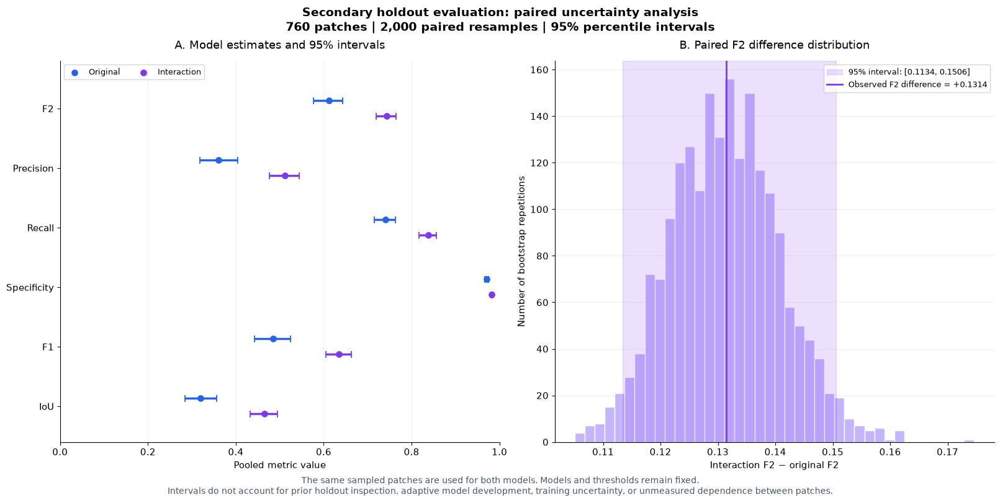

In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Align original and interaction results by test-patch ID.
# ------------------------------------------------------------
SECONDARY_PAIR_BOOTSTRAPS = 2000
SECONDARY_PAIR_SEED = RANDOM_STATE

secondary_stat_columns = [
    "TN",
    "FP",
    "FN",
    "TP",
    "Pixels",
    "Squared error sum",
    "Log loss sum",
]

secondary_original_table = lr_test_patch_results[
    ["sample_id"] + secondary_stat_columns
].copy()

secondary_interaction_table = (
    lr_interaction_secondary_test_patch_results[
        ["sample_id"] + secondary_stat_columns
    ].copy()
)

for table in (
    secondary_original_table,
    secondary_interaction_table,
):
    table["sample_id"] = table["sample_id"].astype(str)
    assert table["sample_id"].is_unique

assert set(
    secondary_original_table["sample_id"]
) == set(
    secondary_interaction_table["sample_id"]
)

lr_secondary_paired_patch_table = (
    secondary_original_table.merge(
        secondary_interaction_table,
        on="sample_id",
        suffixes=("_original", "_interaction"),
        validate="one_to_one",
    )
    .sort_values("sample_id")
    .reset_index(drop=True)
)

assert len(lr_secondary_paired_patch_table) == len(test_ids)

# Confirm identical reference populations for each paired patch.
assert np.array_equal(
    lr_secondary_paired_patch_table["Pixels_original"],
    lr_secondary_paired_patch_table["Pixels_interaction"],
)

assert np.array_equal(
    lr_secondary_paired_patch_table["TP_original"]
    + lr_secondary_paired_patch_table["FN_original"],
    lr_secondary_paired_patch_table["TP_interaction"]
    + lr_secondary_paired_patch_table["FN_interaction"],
)

assert np.array_equal(
    lr_secondary_paired_patch_table["TN_original"]
    + lr_secondary_paired_patch_table["FP_original"],
    lr_secondary_paired_patch_table["TN_interaction"]
    + lr_secondary_paired_patch_table["FP_interaction"],
)

secondary_original_array = lr_secondary_paired_patch_table[
    [
        f"{column}_original"
        for column in secondary_stat_columns
    ]
].to_numpy(dtype=np.float64)

secondary_interaction_array = lr_secondary_paired_patch_table[
    [
        f"{column}_interaction"
        for column in secondary_stat_columns
    ]
].to_numpy(dtype=np.float64)

assert np.isfinite(secondary_original_array).all()
assert np.isfinite(secondary_interaction_array).all()


# ------------------------------------------------------------
# 2. Define pooled metrics from sufficient statistics.
# ------------------------------------------------------------
secondary_ci_metrics = [
    "F2",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "IoU",
    "Brier score",
    "Log loss",
]


def secondary_scores_from_totals(totals):
    tn, fp, fn, tp = (
        int(value) for value in totals[:4]
    )

    scores = metrics_from_counts(tn, fp, fn, tp)

    scores["Brier score"] = float(
        totals[5] / totals[4]
    )
    scores["Log loss"] = float(
        totals[6] / totals[4]
    )

    return {
        metric: float(scores[metric])
        for metric in secondary_ci_metrics
    }


secondary_original_observed = secondary_scores_from_totals(
    secondary_original_array.sum(axis=0)
)

secondary_interaction_observed = secondary_scores_from_totals(
    secondary_interaction_array.sum(axis=0)
)

# Check consistency with the previously reported estimates.
for metric in secondary_ci_metrics:
    assert np.isclose(
        secondary_original_observed[metric],
        lr_test_metrics[metric],
    )
    assert np.isclose(
        secondary_interaction_observed[metric],
        lr_interaction_secondary_test_metrics[metric],
    )


# ------------------------------------------------------------
# 3. Paired bootstrap: identical patch samples for both models.
# ------------------------------------------------------------
secondary_pair_rng = np.random.default_rng(
    SECONDARY_PAIR_SEED
)

secondary_patch_count = len(secondary_original_array)
secondary_bootstrap_records = []

for repetition in range(SECONDARY_PAIR_BOOTSTRAPS):
    sampled_rows = secondary_pair_rng.integers(
        0,
        secondary_patch_count,
        size=secondary_patch_count,
    )

    original_scores = secondary_scores_from_totals(
        secondary_original_array[sampled_rows].sum(axis=0)
    )
    interaction_scores = secondary_scores_from_totals(
        secondary_interaction_array[sampled_rows].sum(axis=0)
    )

    record = {}

    for metric in secondary_ci_metrics:
        record[f"Original {metric}"] = original_scores[metric]
        record[f"Interaction {metric}"] = interaction_scores[metric]
        record[f"Difference {metric}"] = (
            interaction_scores[metric] - original_scores[metric]
        )

    secondary_bootstrap_records.append(record)

lr_secondary_paired_bootstrap_scores = pd.DataFrame(
    secondary_bootstrap_records
)

assert np.isfinite(
    lr_secondary_paired_bootstrap_scores.to_numpy()
).all()


# ------------------------------------------------------------
# 4. Summarize model intervals and paired difference intervals.
# ------------------------------------------------------------
secondary_ci_records = []

for metric in secondary_ci_metrics:
    original_lower, original_upper = np.percentile(
        lr_secondary_paired_bootstrap_scores[
            f"Original {metric}"
        ],
        [2.5, 97.5],
    )

    interaction_lower, interaction_upper = np.percentile(
        lr_secondary_paired_bootstrap_scores[
            f"Interaction {metric}"
        ],
        [2.5, 97.5],
    )

    difference_lower, difference_upper = np.percentile(
        lr_secondary_paired_bootstrap_scores[
            f"Difference {metric}"
        ],
        [2.5, 97.5],
    )

    secondary_ci_records.append({
        "Metric": metric,
        "Original estimate": secondary_original_observed[metric],
        "Original CI lower": original_lower,
        "Original CI upper": original_upper,
        "Interaction estimate": secondary_interaction_observed[metric],
        "Interaction CI lower": interaction_lower,
        "Interaction CI upper": interaction_upper,
        "Difference": (
            secondary_interaction_observed[metric]
            - secondary_original_observed[metric]
        ),
        "Difference CI lower": difference_lower,
        "Difference CI upper": difference_upper,
        "Favorable direction": (
            "Negative"
            if metric in ["Brier score", "Log loss"]
            else "Positive"
        ),
    })

lr_secondary_paired_bootstrap_ci = pd.DataFrame(
    secondary_ci_records
)

print("Interaction model: 95% patch-bootstrap confidence intervals")
display(
    lr_secondary_paired_bootstrap_ci[
        [
            "Metric",
            "Interaction estimate",
            "Interaction CI lower",
            "Interaction CI upper",
        ]
    ].round(6)
)

print("\nPaired difference: interaction minus original")
display(
    lr_secondary_paired_bootstrap_ci[
        [
            "Metric",
            "Difference",
            "Difference CI lower",
            "Difference CI upper",
            "Favorable direction",
        ]
    ].round(6)
)


# ------------------------------------------------------------
# 5. Plot model intervals and the paired F2 difference distribution.
# ------------------------------------------------------------
secondary_ci_lookup = (
    lr_secondary_paired_bootstrap_ci.set_index("Metric")
)

secondary_plot_metrics = [
    "F2",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "IoU",
]

secondary_f2_difference = float(
    secondary_ci_lookup.loc["F2", "Difference"]
)
secondary_f2_lower = float(
    secondary_ci_lookup.loc["F2", "Difference CI lower"]
)
secondary_f2_upper = float(
    secondary_ci_lookup.loc["F2", "Difference CI upper"]
)

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 8),
        layout="constrained",
    )

    fig.suptitle(
        "Secondary holdout evaluation: paired uncertainty analysis\n"
        f"{secondary_patch_count:,} patches | "
        f"{SECONDARY_PAIR_BOOTSTRAPS:,} paired resamples | "
        "95% percentile intervals",
        fontsize=14,
        fontweight="bold",
    )

    for position, metric in enumerate(
        secondary_plot_metrics
    ):
        row = secondary_ci_lookup.loc[metric]

        for model_name, color, offset in [
            ("Original", "#2563EB", -0.13),
            ("Interaction", "#7C3AED", 0.13),
        ]:
            y_position = position + offset

            lower = float(row[f"{model_name} CI lower"])
            upper = float(row[f"{model_name} CI upper"])
            estimate = float(row[f"{model_name} estimate"])

            axes[0].hlines(
                y_position,
                lower,
                upper,
                color=color,
                linewidth=2.5,
            )
            axes[0].vlines(
                [lower, upper],
                y_position - 0.055,
                y_position + 0.055,
                color=color,
                linewidth=1.3,
            )
            axes[0].scatter(
                estimate,
                y_position,
                color=color,
                s=45,
                zorder=4,
                label=model_name if position == 0 else None,
            )

    axes[0].set_yticks(range(len(secondary_plot_metrics)))
    axes[0].set_yticklabels(secondary_plot_metrics)
    axes[0].set(
        xlim=(0, 1),
        ylim=(len(secondary_plot_metrics) - 0.4, -0.8),
        xlabel="Pooled metric value",
    )
    axes[0].set_title(
        "A. Model estimates and 95% intervals",
        pad=14,
    )
    axes[0].legend(loc="upper left", ncol=2, fontsize=9)
    axes[0].grid(axis="x", alpha=0.2)

    axes[1].hist(
        lr_secondary_paired_bootstrap_scores["Difference F2"],
        bins=40,
        color="#C4B5FD",
        edgecolor="white",
    )
    axes[1].axvspan(
        secondary_f2_lower,
        secondary_f2_upper,
        color="#7C3AED",
        alpha=0.15,
        label=(
            f"95% interval: "
            f"[{secondary_f2_lower:.4f}, "
            f"{secondary_f2_upper:.4f}]"
        ),
    )
    axes[1].axvline(
        secondary_f2_difference,
        color="#7C3AED",
        linewidth=2,
        label=(
            f"Observed F2 difference = "
            f"{secondary_f2_difference:+.4f}"
        ),
    )

    axes[1].set_xlabel(
        "Interaction F2 − original F2"
    )
    axes[1].set_ylabel(
        "Number of bootstrap repetitions"
    )
    axes[1].set_title(
        "B. Paired F2 difference distribution",
        pad=14,
    )
    axes[1].legend(loc="best", fontsize=9)
    axes[1].grid(axis="y", alpha=0.2)

    for ax in axes:
        ax.set_axisbelow(True)
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)

    fig.supxlabel(
        "The same sampled patches are used for both models. "
        "Models and thresholds remain fixed.\n"
        "Intervals do not account for prior holdout inspection, "
        "adaptive model development, training uncertainty, "
        "or unmeasured dependence between patches.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

Secondary holdout F2 for the interaction model was 0.743009, with a 95% patch-bootstrap interval of [0.719378, 0.764317]. The paired F2 improvement over the original model was +0.131440 [0.113429, 0.150583]. Paired intervals also favored the interaction model for all other assessed metrics. These conditional results support the observed improvement, while remaining secondary exploratory evidence because the holdout had previously been inspected.

Probability-score comparison:


,Model,Brier score,Log loss,ECE: 20 equal-width bins,Pixels with probability < 0.05 (%)
0,Original LR,0.014044,0.053596,0.004243,93.187256
1,Interaction LR,0.009761,0.035182,0.003001,95.121813



Interaction-model reliability by probability bin:


,Bin lower,Bin upper,Pixels,Landslide pixels,Mean probability,Observed frequency,Pixel share (%),Observed minus predicted
0,0.00,0.05,11844416,24485,0.002807,0.002067,95.121813,-0.000740
1,0.05,0.10,154595,15818,0.070895,0.102319,1.241543,0.031424
2,0.10,0.15,71027,12294,0.122668,0.173089,0.570414,0.050421
3,0.15,0.20,45811,10537,0.173498,0.230010,0.367905,0.056512
4,0.20,0.25,32824,9393,0.223907,0.286163,0.263608,0.062255
5,0.25,0.30,26514,8647,0.274150,0.326130,0.212932,0.051979
6,0.30,0.35,21725,8010,0.324216,0.368700,0.174472,0.044484
7,0.35,0.40,18882,7846,0.374587,0.415528,0.151640,0.040941
8,0.40,0.45,16620,7356,0.424758,0.442599,0.133474,0.017842
9,0.45,0.50,15419,7312,0.474610,0.474220,0.123829,-0.000390


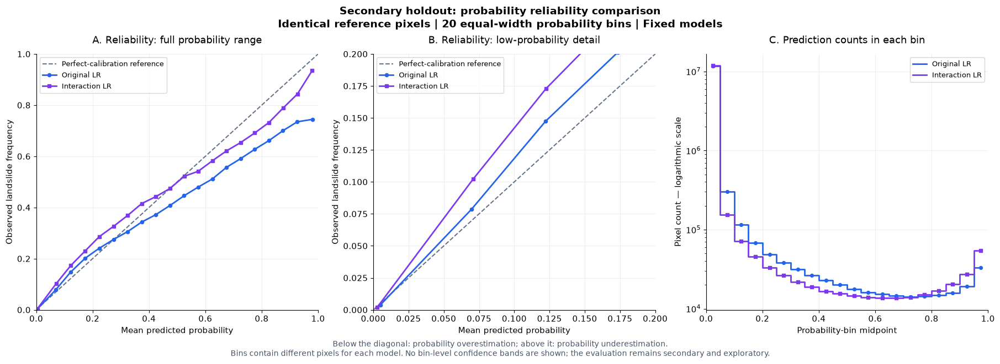

In [89]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Build reliability tables using identical probability bins.
# ------------------------------------------------------------
SECONDARY_RELIABILITY_BINS = 20

secondary_reliability_edges = np.linspace(
    0.0,
    1.0,
    SECONDARY_RELIABILITY_BINS + 1,
)

secondary_reference = np.asarray(
    lr_test_y,
    dtype=np.uint8,
)

secondary_probability_sets = {
    "Original LR": np.asarray(
        lr_test_probability,
        dtype=np.float64,
    ),
    "Interaction LR": np.asarray(
        lr_interaction_secondary_test_probability,
        dtype=np.float64,
    ),
}

secondary_reliability_tables = {}
secondary_probability_summary_records = []


def build_secondary_reliability(probabilities, reference, edges):
    assert probabilities.shape == reference.shape
    assert np.isfinite(probabilities).all()
    assert (
        (probabilities >= 0)
        & (probabilities <= 1)
    ).all()

    number_of_bins = len(edges) - 1

    bin_indices = np.searchsorted(
        edges,
        probabilities,
        side="right",
    ) - 1

    bin_indices = np.clip(
        bin_indices,
        0,
        number_of_bins - 1,
    )

    counts = np.bincount(
        bin_indices,
        minlength=number_of_bins,
    )

    probability_sums = np.bincount(
        bin_indices,
        weights=probabilities,
        minlength=number_of_bins,
    )

    positive_counts = np.bincount(
        bin_indices,
        weights=reference,
        minlength=number_of_bins,
    )

    mean_probability = np.divide(
        probability_sums,
        counts,
        out=np.full(number_of_bins, np.nan),
        where=counts > 0,
    )

    observed_frequency = np.divide(
        positive_counts,
        counts,
        out=np.full(number_of_bins, np.nan),
        where=counts > 0,
    )

    table = pd.DataFrame({
        "Bin lower": edges[:-1],
        "Bin upper": edges[1:],
        "Pixels": counts,
        "Landslide pixels": positive_counts.astype(np.int64),
        "Mean probability": mean_probability,
        "Observed frequency": observed_frequency,
        "Pixel share (%)": 100 * counts / len(reference),
        "Observed minus predicted": (
            observed_frequency - mean_probability
        ),
    })

    assert int(table["Pixels"].sum()) == len(reference)

    nonempty = table.loc[table["Pixels"].gt(0)]

    ece = float(
        np.sum(
            nonempty["Pixels"].to_numpy()
            / len(reference)
            * np.abs(
                nonempty[
                    "Observed minus predicted"
                ].to_numpy()
            )
        )
    )

    return table, ece


for model_name, probabilities in secondary_probability_sets.items():
    reliability_table, ece_value = build_secondary_reliability(
        probabilities,
        secondary_reference,
        secondary_reliability_edges,
    )

    secondary_reliability_tables[model_name] = reliability_table

    model_metrics = (
        lr_test_metrics
        if model_name == "Original LR"
        else lr_interaction_secondary_test_metrics
    )

    secondary_probability_summary_records.append({
        "Model": model_name,
        "Brier score": float(model_metrics["Brier score"]),
        "Log loss": float(model_metrics["Log loss"]),
        "ECE: 20 equal-width bins": ece_value,
        "Pixels with probability < 0.05 (%)": float(
            reliability_table.iloc[0]["Pixel share (%)"]
        ),
    })

lr_secondary_probability_summary = pd.DataFrame(
    secondary_probability_summary_records
)

lr_secondary_reliability_original = (
    secondary_reliability_tables["Original LR"]
)
lr_secondary_reliability_interaction = (
    secondary_reliability_tables["Interaction LR"]
)

print("Probability-score comparison:")
display(lr_secondary_probability_summary.round(6))

print("\nInteraction-model reliability by probability bin:")
display(lr_secondary_reliability_interaction.round(6))


# ------------------------------------------------------------
# 2. Plot both models using common axes and bin definitions.
# ------------------------------------------------------------
secondary_model_colors = {
    "Original LR": "#2563EB",
    "Interaction LR": "#7C3AED",
}

secondary_model_markers = {
    "Original LR": "o",
    "Interaction LR": "s",
}

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 6.5),
        layout="constrained",
    )

    fig.suptitle(
        "Secondary holdout: probability reliability comparison\n"
        "Identical reference pixels | "
        "20 equal-width probability bins | Fixed models",
        fontsize=14,
        fontweight="bold",
    )

    for ax in axes[:2]:
        ax.plot(
            [0, 1],
            [0, 1],
            color="#64748B",
            linestyle="--",
            linewidth=1.5,
            label="Perfect-calibration reference",
        )

    for model_name in secondary_probability_sets:
        table = secondary_reliability_tables[model_name]
        nonempty = table.loc[table["Pixels"].gt(0)]
        color = secondary_model_colors[model_name]

        for ax in axes[:2]:
            ax.plot(
                nonempty["Mean probability"],
                nonempty["Observed frequency"],
                color=color,
                marker=secondary_model_markers[model_name],
                markersize=4.5,
                linewidth=2,
                label=model_name,
            )

        # Bin counts are shown as line segments to avoid
        # overlapping filled histograms.
        bin_centers = (
            table["Bin lower"].to_numpy()
            + table["Bin upper"].to_numpy()
        ) / 2

        visible_counts = table["Pixels"].to_numpy(
            dtype=np.float64
        )
        visible_counts[visible_counts == 0] = np.nan

        axes[2].step(
            bin_centers,
            visible_counts,
            where="mid",
            color=color,
            linewidth=2,
            label=model_name,
        )
        axes[2].scatter(
            bin_centers,
            visible_counts,
            color=color,
            marker=secondary_model_markers[model_name],
            s=18,
        )

    axes[0].set(
        xlim=(0, 1),
        ylim=(0, 1),
        xlabel="Mean predicted probability",
        ylabel="Observed landslide frequency",
    )
    axes[0].set_title(
        "A. Reliability: full probability range",
        pad=14,
    )

    axes[1].set(
        xlim=(0, 0.20),
        ylim=(0, 0.20),
        xlabel="Mean predicted probability",
        ylabel="Observed landslide frequency",
    )
    axes[1].set_title(
        "B. Reliability: low-probability detail",
        pad=14,
    )

    axes[2].set_yscale("log")
    axes[2].set(
        xlim=(0, 1),
        xlabel="Probability-bin midpoint",
        ylabel="Pixel count — logarithmic scale",
    )
    axes[2].set_title(
        "C. Prediction counts in each bin",
        pad=14,
    )

    for ax in axes:
        ax.legend(loc="best", fontsize=9)
        ax.grid(alpha=0.2)
        ax.set_axisbelow(True)
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)

    fig.supxlabel(
        "Below the diagonal: probability overestimation; "
        "above it: probability underestimation.\n"
        "Bins contain different pixels for each model. "
        "No bin-level confidence bands are shown; "
        "the evaluation remains secondary and exploratory.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

The interaction model achieved lower Brier score, log loss, and 20-bin ECE. High-probability overestimation was substantially reduced: the highest bin had mean predicted probability 0.97920 and observed frequency 0.93520. However, several low-to-moderate probability bins showed underestimation, so calibration did not improve uniformly. Approximately 95.12% of predictions fell below 0.05, strongly influencing the small overall ECE. These secondary descriptive results do not justify further holdout-based recalibration.

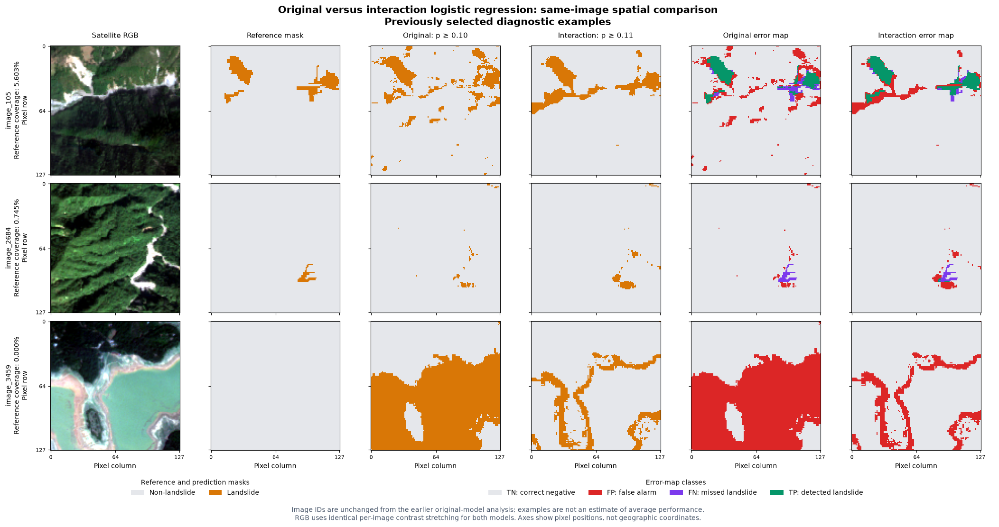

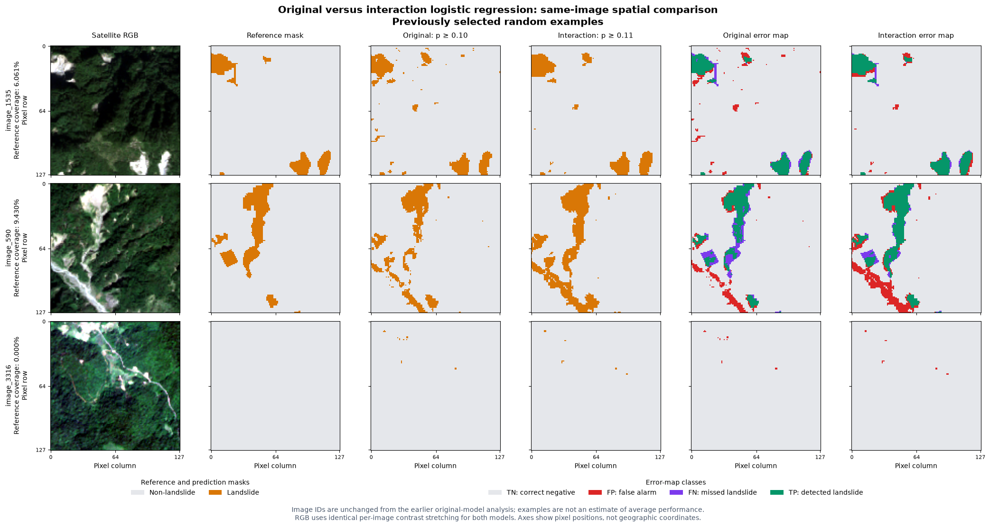

Same-image spatial comparison: exact counts and IoU


,sample_id,Coverage (%),Original TP,Interaction TP,Original FP,Interaction FP,Original FN,Interaction FN,Original IoU,Interaction IoU,IoU difference
0,105,5.60303,680,816,1064,737,238,102,0.34309,0.49305,0.14996
1,2684,0.74463,0,11,107,208,122,111,0.00000,0.03333,0.03333
2,3459,0.00000,0,0,9507,2164,0,0,0.00000,0.00000,0.00000
3,1535,6.06079,849,910,282,204,144,83,0.66588,0.76023,0.09435
4,590,9.42993,1087,1353,520,950,458,192,0.52639,0.54228,0.01589
5,3316,0.00000,0,0,20,17,0,0,0.00000,0.00000,0.00000


In [90]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


# ------------------------------------------------------------
# 1. Keep the previously selected image IDs unchanged.
# ------------------------------------------------------------
spatial_comparison_sets = [
    (
        "Previously selected diagnostic examples",
        lr_test_visual_examples.copy(),
    ),
    (
        "Previously selected random examples",
        lr_test_additional_examples.copy(),
    ),
]

interaction_spatial_lookup = (
    lr_interaction_secondary_test_patch_results.copy()
)
interaction_spatial_lookup["sample_id"] = (
    interaction_spatial_lookup["sample_id"].astype(str)
)
interaction_spatial_lookup = (
    interaction_spatial_lookup.set_index("sample_id")
)

assert interaction_spatial_lookup.index.is_unique

comparison_class_colors = ["#E5E7EB", "#D97706"]
comparison_class_cmap = ListedColormap(comparison_class_colors)
comparison_class_norm = BoundaryNorm([-0.5, 0.5, 1.5], 2)

comparison_error_colors = [
    "#E5E7EB",  # TN
    "#DC2626",  # FP
    "#7C3AED",  # FN
    "#059669",  # TP
]
comparison_error_cmap = ListedColormap(comparison_error_colors)
comparison_error_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    4,
)


def comparison_rgb(image_array):
    rgb = np.asarray(
        image_array[:, :, [3, 2, 1]],
        dtype=np.float64,
    )
    lower = np.percentile(rgb, 2, axis=(0, 1))
    upper = np.percentile(rgb, 98, axis=(0, 1))

    return np.clip(
        (rgb - lower) / np.maximum(upper - lower, 1e-12),
        0,
        1,
    )


spatial_comparison_records = []


# ------------------------------------------------------------
# 2. Produce two figures, each with three identical-image rows.
# ------------------------------------------------------------
with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    for set_title, examples in spatial_comparison_sets:
        examples = examples.reset_index(drop=True)
        number_of_rows = len(examples)

        fig = plt.figure(
            figsize=(21, 11),
            layout="constrained",
        )

        grid = fig.add_gridspec(
            number_of_rows + 1,
            6,
            height_ratios=[1] * number_of_rows + [0.22],
        )

        column_titles = [
            "Satellite RGB",
            "Reference mask",
            f"Original: p ≥ {lr_final_threshold:.2f}",
            f"Interaction: p ≥ {lr_interaction_final_threshold:.2f}",
            "Original error map",
            "Interaction error map",
        ]

        for row_number, example in examples.iterrows():
            sample_id = str(example["sample_id"])

            original_start = int(example["Start"])
            original_stop = int(example["Stop"])

            interaction_row = interaction_spatial_lookup.loc[
                sample_id
            ]

            # Both cached prediction arrays use the same pixel order.
            assert original_start == int(interaction_row["Start"])
            assert original_stop == int(interaction_row["Stop"])

            reference = lr_test_y[
                original_start:original_stop
            ].reshape(128, 128)

            original_prediction = (
                lr_test_probability[
                    original_start:original_stop
                ].reshape(128, 128)
                >= lr_final_threshold
            ).astype(np.uint8)

            interaction_prediction = (
                lr_interaction_secondary_test_probability[
                    original_start:original_stop
                ].reshape(128, 128)
                >= lr_interaction_final_threshold
            ).astype(np.uint8)

            original_error = 2 * reference + original_prediction
            interaction_error = (
                2 * reference + interaction_prediction
            )

            # Verify all displayed error counts.
            for code, count_name in enumerate(
                ["TN", "FP", "FN", "TP"]
            ):
                assert int(
                    np.count_nonzero(original_error == code)
                ) == int(example[count_name])

                assert int(
                    np.count_nonzero(interaction_error == code)
                ) == int(interaction_row[count_name])

            image_path = (
                DATA_DIR / "TrainData" / "img"
                / f"image_{sample_id}.h5"
            )

            with h5py.File(image_path, "r") as image_file:
                image_array = np.asarray(
                    image_file["img"],
                    dtype=np.float32,
                )

            row_axes = [
                fig.add_subplot(grid[row_number, column])
                for column in range(6)
            ]

            row_axes[0].imshow(comparison_rgb(image_array))

            for ax, mask in [
                (row_axes[1], reference),
                (row_axes[2], original_prediction),
                (row_axes[3], interaction_prediction),
            ]:
                ax.imshow(
                    mask,
                    cmap=comparison_class_cmap,
                    norm=comparison_class_norm,
                    interpolation="nearest",
                )

            for ax, error_map in [
                (row_axes[4], original_error),
                (row_axes[5], interaction_error),
            ]:
                ax.imshow(
                    error_map,
                    cmap=comparison_error_cmap,
                    norm=comparison_error_norm,
                    interpolation="nearest",
                )

            for column, ax in enumerate(row_axes):
                if row_number == 0:
                    ax.set_title(
                        column_titles[column],
                        fontsize=11,
                        pad=12,
                    )

                ax.set_xticks([0, 64, 127])
                ax.set_yticks([0, 64, 127])
                ax.tick_params(labelsize=8)

                if column > 0:
                    ax.tick_params(labelleft=False)

                if row_number == number_of_rows - 1:
                    ax.set_xlabel("Pixel column")
                else:
                    ax.tick_params(labelbottom=False)

            row_axes[0].set_ylabel(
                f"image_{sample_id}\n"
                f"Reference coverage: "
                f"{example['Landslide coverage (%)']:.3f}%\n"
                "Pixel row",
                fontsize=10,
                labelpad=10,
            )

            spatial_comparison_records.append({
                "Example set": set_title,
                "sample_id": sample_id,
                "Coverage (%)": float(
                    example["Landslide coverage (%)"]
                ),
                "Original TP": int(example["TP"]),
                "Interaction TP": int(interaction_row["TP"]),
                "Original FP": int(example["FP"]),
                "Interaction FP": int(interaction_row["FP"]),
                "Original FN": int(example["FN"]),
                "Interaction FN": int(interaction_row["FN"]),
                "Original IoU": float(example["IoU"]),
                "Interaction IoU": float(interaction_row["IoU"]),
            })

        class_legend_ax = fig.add_subplot(
            grid[number_of_rows, 0:2]
        )
        class_legend_ax.axis("off")
        class_legend_ax.legend(
            handles=[
                Patch(
                    facecolor=comparison_class_colors[0],
                    label="Non-landslide",
                ),
                Patch(
                    facecolor=comparison_class_colors[1],
                    label="Landslide",
                ),
            ],
            loc="center",
            ncol=2,
            frameon=False,
            title="Reference and prediction masks",
        )

        error_legend_ax = fig.add_subplot(
            grid[number_of_rows, 2:6]
        )
        error_legend_ax.axis("off")
        error_legend_ax.legend(
            handles=[
                Patch(
                    facecolor=comparison_error_colors[0],
                    label="TN: correct negative",
                ),
                Patch(
                    facecolor=comparison_error_colors[1],
                    label="FP: false alarm",
                ),
                Patch(
                    facecolor=comparison_error_colors[2],
                    label="FN: missed landslide",
                ),
                Patch(
                    facecolor=comparison_error_colors[3],
                    label="TP: detected landslide",
                ),
            ],
            loc="center",
            ncol=4,
            frameon=False,
            title="Error-map classes",
        )

        fig.suptitle(
            "Original versus interaction logistic regression: "
            "same-image spatial comparison\n"
            f"{set_title}",
            fontsize=15,
            fontweight="bold",
        )

        fig.supxlabel(
            "Image IDs are unchanged from the earlier original-model "
            "analysis; examples are not an estimate of average performance.\n"
            "RGB uses identical per-image contrast stretching for both "
            "models. Axes show pixel positions, not geographic coordinates.",
            fontsize=10,
            color="#475569",
        )

        plt.show()


# ------------------------------------------------------------
# 3. Display exact paired counts for all six examples.
# ------------------------------------------------------------
lr_secondary_spatial_comparison = pd.DataFrame(
    spatial_comparison_records
)

assert lr_secondary_spatial_comparison["sample_id"].is_unique

lr_secondary_spatial_comparison["IoU difference"] = (
    lr_secondary_spatial_comparison["Interaction IoU"]
    - lr_secondary_spatial_comparison["Original IoU"]
)

print("Same-image spatial comparison: exact counts and IoU")
display(
    lr_secondary_spatial_comparison[
        [
            "sample_id",
            "Coverage (%)",
            "Original TP",
            "Interaction TP",
            "Original FP",
            "Interaction FP",
            "Original FN",
            "Interaction FN",
            "Original IoU",
            "Interaction IoU",
            "IoU difference",
        ]
    ].round(5)
)

Same-image comparisons show heterogeneous effects. The interaction model reduced both false positives and false negatives in images 105 and 1535, and substantially reduced false alarms in negative image 3459. However, low-coverage image 2684 remained poorly detected, with increased false positives. In image 590, fewer missed landslide pixels were accompanied by more false positives, producing only a small IoU improvement. These examples illustrate the aggregate gains while confirming persistent spatial failure modes.

Coverage-group comparison: pooled metrics


,Coverage group,Model,Patches,Precision,Recall,F2,IoU,False-positive rate (%)
0,No landslide,Original LR,314,0.00000,NaN,0.00000,0.00000,2.43418
1,>0–1%,Original LR,158,0.10619,0.61128,0.31326,0.09947,2.24067
2,>1–5%,Original LR,183,0.37736,0.68098,0.58659,0.32067,2.93422
3,>5–15%,Original LR,92,0.59093,0.73970,0.70424,0.48920,4.77360
4,>15–100%,Original LR,13,0.74968,0.86456,0.83886,0.67089,8.69762
5,No landslide,Interaction LR,314,0.00000,NaN,0.00000,0.00000,0.57332
6,>0–1%,Interaction LR,158,0.20713,0.69672,0.47308,0.19000,1.16138
7,>1–5%,Interaction LR,183,0.45628,0.78176,0.68415,0.40472,2.43281
8,>5–15%,Interaction LR,92,0.62683,0.84347,0.78893,0.56151,4.68120
9,>15–100%,Interaction LR,13,0.72401,0.94351,0.88957,0.69392,10.83659



False alarms across all reference-negative patches:


,Model,Negative patches,Patches with any FP (%),Median FP area (%),95th percentile FP area (%),Pooled FP area (%)
0,Original LR,314,82.80255,0.25024,10.32410,2.43418
1,Interaction LR,314,74.20382,0.10071,1.78253,0.57332


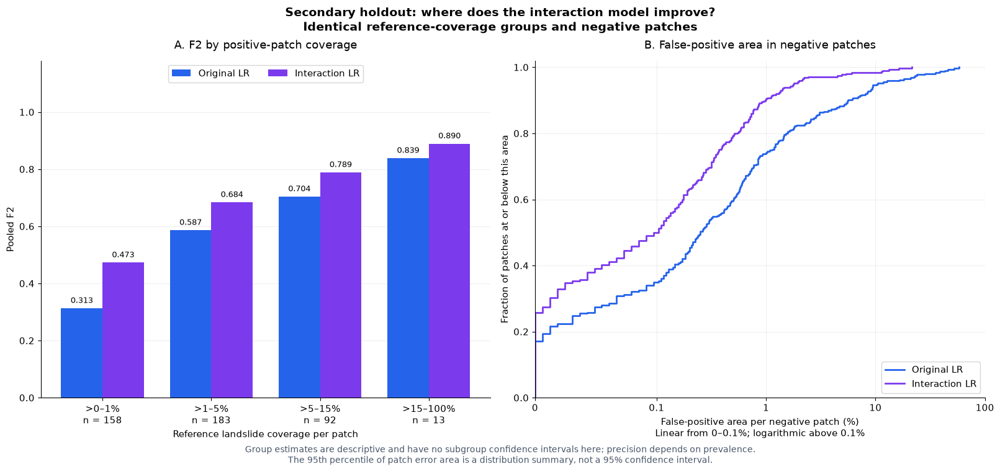

In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Apply identical reference-coverage groups to both models.
# ------------------------------------------------------------
comparison_coverage_bins = [-0.001, 0, 1, 5, 15, 100]

comparison_coverage_labels = [
    "No landslide",
    ">0–1%",
    ">1–5%",
    ">5–15%",
    ">15–100%",
]

coverage_model_tables = {
    "Original LR": lr_test_patch_results.copy(),
    "Interaction LR":
        lr_interaction_secondary_test_patch_results.copy(),
}

for model_name, table in coverage_model_tables.items():
    table["sample_id"] = table["sample_id"].astype(str)
    assert table["sample_id"].is_unique

    table["Coverage group"] = pd.cut(
        table["Landslide coverage (%)"],
        bins=comparison_coverage_bins,
        labels=comparison_coverage_labels,
        right=True,
        include_lowest=True,
    )
    assert table["Coverage group"].notna().all()

# Check that both models use the same patches and reference coverage.
original_reference_check = (
    coverage_model_tables["Original LR"]
    .set_index("sample_id")
    .sort_index()
)

interaction_reference_check = (
    coverage_model_tables["Interaction LR"]
    .set_index("sample_id")
    .sort_index()
)

assert original_reference_check.index.equals(
    interaction_reference_check.index
)

assert np.array_equal(
    original_reference_check["Positive pixels"].to_numpy(),
    interaction_reference_check["Positive pixels"].to_numpy(),
)

assert np.array_equal(
    original_reference_check["Pixels"].to_numpy(),
    interaction_reference_check["Pixels"].to_numpy(),
)


# ------------------------------------------------------------
# 2. Calculate pooled metrics for every coverage group.
# ------------------------------------------------------------
coverage_comparison_records = []
negative_comparison_records = []
negative_area_distributions = {}

for model_name, table in coverage_model_tables.items():
    for group_name in comparison_coverage_labels:
        subset = table.loc[
            table["Coverage group"].eq(group_name)
        ]

        if subset.empty:
            continue

        counts = (
            subset[["TN", "FP", "FN", "TP"]]
            .sum()
            .astype(np.int64)
        )

        scores = metrics_from_counts(
            int(counts["TN"]),
            int(counts["FP"]),
            int(counts["FN"]),
            int(counts["TP"]),
        )

        negative_pixels = int(
            counts["TN"] + counts["FP"]
        )

        coverage_comparison_records.append({
            "Coverage group": group_name,
            "Model": model_name,
            "Patches": len(subset),
            "Precision": scores["Precision"],
            "Recall": scores["Recall"],
            "F2": scores["F2"],
            "IoU": scores["IoU"],
            "False-positive rate (%)": (
                100 * counts["FP"] / negative_pixels
                if negative_pixels > 0 else np.nan
            ),
        })

    negative_subset = table.loc[
        table["Positive pixels"].eq(0)
    ].copy()

    assert not negative_subset.empty

    negative_areas = (
        100
        * negative_subset["FP"].to_numpy(dtype=float)
        / negative_subset["Pixels"].to_numpy(dtype=float)
    )

    negative_area_distributions[model_name] = np.sort(
        negative_areas
    )

    negative_comparison_records.append({
        "Model": model_name,
        "Negative patches": len(negative_subset),
        "Patches with any FP (%)": (
            100 * float(negative_subset["FP"].gt(0).mean())
        ),
        "Median FP area (%)": float(
            np.median(negative_areas)
        ),
        "95th percentile FP area (%)": float(
            np.percentile(negative_areas, 95)
        ),
        "Pooled FP area (%)": float(
            100
            * negative_subset["FP"].sum()
            / negative_subset["Pixels"].sum()
        ),
    })

lr_secondary_coverage_comparison = pd.DataFrame(
    coverage_comparison_records
)

lr_secondary_negative_comparison = pd.DataFrame(
    negative_comparison_records
)

print("Coverage-group comparison: pooled metrics")
display(lr_secondary_coverage_comparison.round(5))

print("\nFalse alarms across all reference-negative patches:")
display(lr_secondary_negative_comparison.round(5))


# ------------------------------------------------------------
# 3. Plot coverage-group F2 and negative-patch false-positive area.
# ------------------------------------------------------------
model_colors = {
    "Original LR": "#2563EB",
    "Interaction LR": "#7C3AED",
}

available_positive_groups = [
    group for group in comparison_coverage_labels[1:]
    if group in set(
        lr_secondary_coverage_comparison["Coverage group"]
    )
]

coverage_lookup = (
    lr_secondary_coverage_comparison
    .set_index(["Coverage group", "Model"])
)

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 7.5),
        layout="constrained",
    )

    fig.suptitle(
        "Secondary holdout: where does the interaction model improve?\n"
        "Identical reference-coverage groups and negative patches",
        fontsize=14,
        fontweight="bold",
    )

    positions = np.arange(len(available_positive_groups))

    for model_number, model_name in enumerate(model_colors):
        values = [
            coverage_lookup.loc[
                (group, model_name), "F2"
            ]
            for group in available_positive_groups
        ]

        bars = axes[0].bar(
            positions + (-0.19 if model_number == 0 else 0.19),
            values,
            width=0.38,
            color=model_colors[model_name],
            label=model_name,
        )

        axes[0].bar_label(
            bars,
            fmt="%.3f",
            padding=4,
            fontsize=9,
        )

    tick_labels = [
        f"{group}\n"
        f"n = {int(coverage_lookup.loc[(group, 'Original LR'), 'Patches'])}"
        for group in available_positive_groups
    ]

    axes[0].set_xticks(positions)
    axes[0].set_xticklabels(tick_labels)
    axes[0].set_ylim(0, 1.18)
    axes[0].set_yticks(np.arange(0, 1.01, 0.2))
    axes[0].set_xlabel("Reference landslide coverage per patch")
    axes[0].set_ylabel("Pooled F2")
    axes[0].set_title(
        "A. F2 by positive-patch coverage",
        pad=14,
    )
    axes[0].legend(loc="upper center", ncol=2)
    axes[0].grid(axis="y", alpha=0.2)

    for model_name, sorted_areas in (
        negative_area_distributions.items()
    ):
        cumulative_fraction = (
            np.arange(1, len(sorted_areas) + 1)
            / len(sorted_areas)
        )

        axes[1].step(
            sorted_areas,
            cumulative_fraction,
            where="post",
            color=model_colors[model_name],
            linewidth=2,
            label=model_name,
        )

    axes[1].set_xscale("symlog", linthresh=0.1)
    axes[1].set_xlim(0, 100)
    axes[1].set_xticks([0, 0.1, 1, 10, 100])
    axes[1].set_xticklabels(["0", "0.1", "1", "10", "100"])
    axes[1].set_ylim(0, 1.02)
    axes[1].set_xlabel(
        "False-positive area per negative patch (%)\n"
        "Linear from 0–0.1%; logarithmic above 0.1%"
    )
    axes[1].set_ylabel(
        "Fraction of patches at or below this area"
    )
    axes[1].set_title(
        "B. False-positive area in negative patches",
        pad=14,
    )
    axes[1].legend(loc="lower right")
    axes[1].grid(alpha=0.2)

    for ax in axes:
        ax.set_axisbelow(True)
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)

    fig.supxlabel(
        "Group estimates are descriptive and have no subgroup "
        "confidence intervals here; precision depends on prevalence.\n"
        "The 95th percentile of patch error area is a distribution "
        "summary, not a 95% confidence interval.",
        fontsize=10,
        color="#475569",
    )

    plt.show()

The interaction model achieved higher F2 in all four positive-coverage groups, with the largest absolute gain in patches containing up to 1% landslide coverage. However, precision remained low in that group. In the highest-coverage group, recall improved while precision declined and the false-positive rate increased. Across 314 negative patches, pooled false-positive area decreased from 2.43418% to 0.57332%, and the 95th percentile of patch-level false-positive area decreased from 10.32410% to 1.78253%. These descriptive subgroup results confirm improvement while identifying persistent limitations.

Interaction Logistic Regression — Final Summary
Purpose and model design
This extension examined whether multiplicative relationships between satellite and terrain inputs improve landslide mapping. The model retained all 14 original inputs and added 91 distinct pairwise products, producing 105 predictors. Preprocessing and interaction generation were fitted within each training partition.
Training used 512 uniformly sampled pixels per patch. Validation and evaluation used every pixel in the held-out patches.
Development evaluation
The five-fold procedure selected regularization strength, calibration method, and threshold within each outer-training partition.
Development result	Original LR	Interaction LR
Mean outer-fold F2	0.628566	0.747495
Outer-fold F2 SD	0.017368	0.016158
Pooled out-of-fold F2	0.629068	0.747800


The interaction model achieved higher F2 in all five outer folds. The paired difference in pooled F2 was +0.118732, with a 95% patch-bootstrap interval of [0.111181, 0.127020].
These findings belong to an exploratory extension developed after earlier results were inspected.
Final model
Full-development validation selected:
- C = 1
- No class weighting
- No additional calibration mapping
- Classification threshold: 0.11
The final model was fitted on 1,555,968 sampled pixels from all 3,039 development patches.
Secondary holdout evaluation
The same 760 holdout patches previously assessed for the original model were used. Consequently, these are secondary exploratory results, rather than a fresh independent confirmation.
Metric	Estimate	95% patch-bootstrap CI
F2	0.743009	0.719378–0.764317
Precision	0.511054	0.476746–0.544372
Recall	0.838108	0.816691–0.856028
Specificity	0.982538	0.980327–0.984559
IoU	0.465137	0.433303–0.495200


ROC AUC was 0.986106, average precision 0.738121, Brier score 0.009761, and log loss 0.035182.
The paired holdout F2 improvement was +0.131440 [0.113429, 0.150583]. This comparison concerns the complete fitted procedures and does not isolate interaction terms alone.
Error analysis and practical relevance
F2 improved in every positive-coverage group. Nevertheless, precision remained low in patches with very little landslide coverage. Across reference-negative patches, pooled false-positive area decreased from 2.43418% to 0.57332%.
Spatial comparisons confirmed reduced errors in several images but also persistent failures and cases where increased detection produced more false alarms.
High-probability reliability improved, although probability underestimation remained in several lower-probability bins. The model was not uniformly calibrated.
Conclusion and limitations
The interaction extension is the stronger of the two evaluated logistic-regression approaches. Its remaining false positives, missed landslide pixels, and calibration errors require human review.
Bootstrap intervals are conditional on fixed fitted models. They exclude training uncertainty, adaptive model development, and unmeasured dependence between patches. Geographic coordinates were unavailable, so generalization to new regions remains unverified.
No model settings were changed using the secondary holdout results.

In [92]:
from pathlib import Path
from datetime import datetime
import json
import platform

import joblib
import numpy as np
import pandas as pd
import sklearn


# ------------------------------------------------------------
# 1. Create a new export directory without overwriting old exports.
# ------------------------------------------------------------
export_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

LR_HANDOFF_DIR = (
    Path.cwd()
    / "artifacts"
    / f"landslide_handoff_{export_timestamp}"
)

LR_HANDOFF_DIR.mkdir(parents=True, exist_ok=False)

array_directory = LR_HANDOFF_DIR / "arrays"
table_directory = LR_HANDOFF_DIR / "tables"

array_directory.mkdir()
table_directory.mkdir()


# ------------------------------------------------------------
# 2. Save sampled training data and cached holdout predictions.
# These arrays contain numeric data only.
# ------------------------------------------------------------
handoff_arrays = {
    "sampled_patch_ids": np.asarray(
        sampled_patch_ids,
        dtype=str,
    ),
    "X_patch_samples": X_patch_samples,
    "y_patch_samples": y_patch_samples,
    "lr_test_y": lr_test_y,
    "lr_test_probability": lr_test_probability,
    "lr_interaction_secondary_test_probability":
        lr_interaction_secondary_test_probability,
}

array_manifest = {}

for name, array in handoff_arrays.items():
    array = np.asarray(array)

    assert not array.dtype.hasobject, (
        f"{name} contains Python objects and needs separate handling."
    )

    destination = array_directory / f"{name}.npy"

    np.save(
        destination,
        array,
        allow_pickle=False,
    )

    array_manifest[name] = {
        "file": f"arrays/{name}.npy",
        "shape": list(array.shape),
        "dtype": str(array.dtype),
        "bytes": int(array.nbytes),
    }

    print(f"Saved array: {name}", flush=True)


# ------------------------------------------------------------
# 3. Preserve result tables separately from the model objects.
# All currently available lr_* DataFrames are included.
# ------------------------------------------------------------
handoff_tables = {
    name: value.copy()
    for name, value in list(globals().items())
    if name.startswith("lr_")
    and isinstance(value, pd.DataFrame)
}

# Also retain the dataset audit and partition manifests.
for name in [
    "audit_df",
    "split_manifest",
    "dev_manifest",
    "baseline_results",
]:
    value = globals().get(name)

    if isinstance(value, pd.DataFrame):
        handoff_tables[name] = value.copy()

for name, table in handoff_tables.items():
    table.to_csv(
        table_directory / f"{name}.csv",
        index=False,
        encoding="utf-8-sig",
    )

# Pickle-based format retains DataFrame types more faithfully than CSV.
joblib.dump(
    handoff_tables,
    LR_HANDOFF_DIR / "result_tables.joblib",
    compress=3,
)

print(f"Saved {len(handoff_tables)} result tables.", flush=True)


# ------------------------------------------------------------
# 4. Save reusable state and standard sklearn model objects.
# Do not serialize the notebook-defined probability wrapper.
# ------------------------------------------------------------
handoff_variables = {
    "RANDOM_STATE": RANDOM_STATE,
    "FEATURE_NAMES": list(FEATURE_NAMES),
    "BETA": BETA,
    "THRESHOLDS": np.asarray(THRESHOLDS),
    "CALIBRATION_FRACTION": CALIBRATION_FRACTION,
    "PLATT_C": PLATT_C,
    "dev_ids": np.asarray(dev_ids, dtype=str),
    "test_ids": np.asarray(test_ids, dtype=str),
    "nested_splits": nested_splits,
    "presence_by_id": presence_by_id.copy(),
    "lr_final_inner_splits": lr_final_inner_splits,
    "lr_final_settings": dict(lr_final_settings),
    "lr_final_threshold": float(lr_final_threshold),
    "lr_interaction_final_settings":
        dict(lr_interaction_final_settings),
    "lr_interaction_final_threshold":
        float(lr_interaction_final_threshold),
    "lr_test_metrics": dict(lr_test_metrics),
    "lr_interaction_secondary_test_metrics":
        dict(lr_interaction_secondary_test_metrics),
}

handoff_models = {
    "lr_final_base_model": lr_final_base_model,
    "lr_final_calibrator": lr_final_calibrator,
    "lr_interaction_final_base_model":
        lr_interaction_final_base_model,
}

joblib.dump(
    {
        "variables": handoff_variables,
        "models": handoff_models,
    },
    LR_HANDOFF_DIR / "project_state.joblib",
    compress=3,
)

print("Saved model objects and project state.", flush=True)


# ------------------------------------------------------------
# 5. Save paths, versions, and an array manifest.
# ------------------------------------------------------------
handoff_metadata = {
    "created_at": datetime.now().isoformat(),
    "project_directory": str(Path.cwd().resolve()),
    "data_directory": str(Path(DATA_DIR).resolve()),
    "export_directory": str(LR_HANDOFF_DIR.resolve()),
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
    "arrays": array_manifest,
    "table_names": sorted(handoff_tables),
}

(LR_HANDOFF_DIR / "metadata.json").write_text(
    json.dumps(
        handoff_metadata,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ------------------------------------------------------------
# 6. Write a handoff note for the next chat.
# ------------------------------------------------------------
handoff_note = f"""
PROJECT HANDOFF — LANDSLIDE CLASSIFICATION

Continue in the user's existing project, using a new notebook that
the user creates. Do not recreate the dataset or overwrite LR results.

Communication:
Explain clearly in Persian, keep English technical terms readable,
and provide English Markdown-ready Result paragraphs.
Provide complete runnable cells, step by step.
Plots need visible legends, labels, scales, and unclipped text.
Report each classifier separately, followed by a shared comparison.

Project:
Classical supervised ML for Landslide4Sense pixel classification.
No deep learning is required.
Inputs: 14 channels: B1–B12, Slope, Elevation.
Images: (128, 128, 14); binary masks: (128, 128).
Stored terrain channels are scaled; do not label them directly as
metres or degrees. No geographic coordinates are available.
This is landslide mapping, not future landslide forecasting.

Data directory:
{Path(DATA_DIR).resolve()}

Labeled source files:
TrainData/img/image_ID.h5, dataset "img"
TrainData/mask/mask_ID.h5, dataset "mask"

Partitions:
3,039 development patches; 760 labeled holdout patches.
The supplied ValidData and TestData images lack reference masks.
Reuse saved dev_ids, test_ids, and nested_splits.
Never split pixels from the same patch across training and evaluation.
Unknown geographic dependence remains a limitation.

Training samples:
X_patch_samples and y_patch_samples have 1,024 sampled pixels per patch.
sampled_patch_ids identifies the patch axis.
The first 512 pixels are the nested 512-pixel sample.
Sampling was uniform, without class balancing.
Validation and evaluation use all pixels in each evaluation patch.

Evaluation:
Primary metric: F2, beta=2.
No specificity floor is imposed for this project.
Five outer folds and three inner folds.
Fit preprocessing only on fitting data.
Hyperparameters are selected first; calibration and threshold selection
then use inner validation with separate fitting/calibration patches.
This is a staged procedure, not a joint Cartesian search over everything.
Use patch bootstrap, not independent-pixel bootstrap.
Do not treat five overlapping-training folds as independent experiments.
Do not tune on holdout results.

Completed method 1: original logistic regression.
Final: StandardScaler + LR, C=0.1, no class weighting,
512 pixels/patch, sigmoid calibration, threshold=0.10.
Base fitting: 2,431 development patches.
Calibration: 608 separate development patches.
Initial holdout F2=0.611569, precision=0.360416,
recall=0.740588, IoU=0.320015.
Corrected log loss=0.053596; Brier=0.014044.
An earlier written F2 of 0.61569 was a transcription error.
The saved numeric result tables contain the correct values.

Completed method 2: interaction logistic regression.
Pipeline: input standardization -> PolynomialFeatures(
degree=2, interaction_only=True, include_bias=False)
-> expanded-column standardization -> LR.
14 original terms plus 91 pairwise products = 105 predictors.
Final: C=1, no class weighting, 512 pixels/patch,
no extra calibration, threshold=0.11.
Final fitting used all 3,039 development patches.
Mean outer-fold F2=0.747495; pooled OOF F2=0.747800.
Secondary holdout F2=0.743009, precision=0.511054,
recall=0.838108, IoU=0.465137.
Holdout ROC AUC=0.986106; AP=0.738121.
Brier=0.009761; log loss=0.035182.
Holdout F2 CI=[0.719378, 0.764317].
Paired holdout F2 gain=0.131440,
CI=[0.113429, 0.150583].

Important:
The interaction extension was developed after earlier results,
including the initial holdout evaluation, had been inspected.
Its later holdout results are SECONDARY/EXPLORATORY,
not fresh independent confirmation.
The original LR results must remain preserved.

Completed analyses:
Outer evaluation, patch-bootstrap intervals, paired differences,
ROC/PR, reliability diagrams, descriptive binned ECE,
coverage subgroups, negative-patch false alarms,
and same-image spatial comparisons.
ECE is bin-dependent and dominated by low-probability pixels.
Coefficient magnitudes are not independent importance or causal effects.

Fixed comparison images:
Diagnostic: 105, 2684, 3459.
Additional random examples: 1535, 590, 3316.
Reuse these IDs for fair spatial comparison across methods.

Saved files:
project_state.joblib: variables and standard sklearn model objects.
result_tables.joblib: named DataFrames.
tables/: CSV copies.
arrays/: sampled training arrays and cached holdout predictions.
metadata.json: paths and package versions.

Probability wrappers and notebook helper functions are not serialized.
Restore/redefine metrics_from_counts, get_sampled_pixels,
evaluate_full_patches_at_thresholds, and CalibratedProbabilityModel
before subsequent modeling. The original saved notebook retains
their exact code. Avoid assuming they exist in a new kernel.

New classifier has not yet been started.
Choose its search budget before running expensive computations.
Fit each new classifier independently and preserve all LR results.
"""

(LR_HANDOFF_DIR / "CHAT_HANDOFF.txt").write_text(
    handoff_note.strip(),
    encoding="utf-8",
)


# ------------------------------------------------------------
# 7. Basic verification.
# ------------------------------------------------------------
reloaded_state = joblib.load(
    LR_HANDOFF_DIR / "project_state.joblib"
)

assert set(reloaded_state) == {"variables", "models"}
assert len(reloaded_state["variables"]["dev_ids"]) == len(dev_ids)
assert len(reloaded_state["variables"]["test_ids"]) == len(test_ids)

for name, information in array_manifest.items():
    check_array = np.load(
        LR_HANDOFF_DIR / information["file"],
        mmap_mode="r",
        allow_pickle=False,
    )
    assert list(check_array.shape) == information["shape"]
    assert str(check_array.dtype) == information["dtype"]
    del check_array

del reloaded_state

print("\nEXPORT COMPLETED AND BASIC CHECKS PASSED")
print("\nKeep this folder:")
print(LR_HANDOFF_DIR.resolve())
print("\nFor the next chat, attach CHAT_HANDOFF.txt.")
print("Also keep the current notebook saved with Ctrl+S.")

Saved array: sampled_patch_ids
Saved array: X_patch_samples
Saved array: y_patch_samples
Saved array: lr_test_y
Saved array: lr_test_probability
Saved array: lr_interaction_secondary_test_probability
Saved 96 result tables.
Saved model objects and project state.

EXPORT COMPLETED AND BASIC CHECKS PASSED

Keep this folder:
C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\landslide_handoff_20261018_051428_848638

For the next chat, attach CHAT_HANDOFF.txt.
Also keep the current notebook saved with Ctrl+S.


In [4]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

LR_FIXED_IMAGE_IDS = [
    "105", "2684", "3459", "1535", "590", "3316"
]

lr_fixed_output_dir = (
    Path(DATA_DIR).parent / "artifacts" / "lr_fixed_spatial_results"
)
lr_fixed_output_dir.mkdir(parents=True, exist_ok=True)


def lr_plot_fixed_images(
    model_title,
    file_prefix,
    probabilities,
    threshold,
    patch_results
):
    lookup = patch_results.copy()
    lookup["sample_id"] = lookup["sample_id"].astype(str)
    assert lookup["sample_id"].is_unique
    lookup = lookup.set_index("sample_id")

    assert set(LR_FIXED_IMAGE_IDS).issubset(lookup.index)

    probabilities = np.asarray(probabilities).reshape(-1)
    saved_labels = np.asarray(lr_test_y).reshape(-1)
    assert probabilities.shape == saved_labels.shape

    binary_cmap = ListedColormap(["#E5E7EB", "#D97706"])
    error_colors = ["#E5E7EB", "#DC2626", "#7C3AED", "#059669"]
    error_cmap = ListedColormap(error_colors)
    error_norm = BoundaryNorm(
        [-0.5, 0.5, 1.5, 2.5, 3.5], 4
    )

    error_legend = [
        Patch(facecolor=color, label=label)
        for color, label in zip(
            error_colors,
            [
                "TN: correct negative",
                "FP: false alarm",
                "FN: missed landslide",
                "TP: detected landslide"
            ]
        )
    ]

    records = []
    metric_rows = []

    for image_id in LR_FIXED_IMAGE_IDS:
        row = lookup.loc[image_id]
        start, stop = int(row["Start"]), int(row["Stop"])
        assert stop - start == 128 * 128

        reference = saved_labels[start:stop].reshape(128, 128)
        assert np.isin(reference, [0, 1]).all()
        reference = reference.astype(bool)

        probability = probabilities[start:stop].reshape(128, 128)
        assert np.isfinite(probability).all()
        assert ((probability >= 0) & (probability <= 1)).all()

        prediction = probability >= threshold
        error = (
            2 * reference.astype(np.uint8)
            + prediction.astype(np.uint8)
        )

        counts = {
            name: int(np.count_nonzero(error == code))
            for code, name in enumerate(["TN", "FP", "FN", "TP"])
        }

        for name, value in counts.items():
            assert value == int(row[name]), (
                f"{model_title}, image {image_id}: {name} mismatch"
            )

        with h5py.File(
            Path(DATA_DIR) / "TrainData" / "img"
            / f"image_{image_id}.h5", "r"
        ) as image_file:
            image = np.asarray(image_file["img"], dtype=np.float32)

        with h5py.File(
            Path(DATA_DIR) / "TrainData" / "mask"
            / f"mask_{image_id}.h5", "r"
        ) as mask_file:
            disk_mask = np.asarray(mask_file["mask"])

        assert np.isin(disk_mask, [0, 1]).all()
        assert np.array_equal(reference, disk_mask.astype(bool))
        assert image.shape == (128, 128, 14)
        assert np.isfinite(image).all()

        # Identical RGB display preparation for both models.
        rgb = image[:, :, [3, 2, 1]].astype(np.float64)
        lower = np.percentile(rgb, 2, axis=(0, 1))
        upper = np.percentile(rgb, 98, axis=(0, 1))
        rgb = np.clip(
            (rgb - lower) / np.maximum(upper - lower, 1e-12),
            0, 1
        )

        tp, fp, fn = counts["TP"], counts["FP"], counts["FN"]

        def ratio(a, b):
            return a / b if b > 0 else np.nan

        metric_rows.append({
            "Image_ID": image_id,
            "Reference_landslide_percent": 100 * reference.mean(),
            **counts,
            "Precision": ratio(tp, tp + fp),
            "Recall": ratio(tp, tp + fn),
            "F2": ratio(5 * tp, 5 * tp + 4 * fn + fp),
            "IoU": ratio(tp, tp + fp + fn)
        })

        records.append({
            "id": image_id,
            "rgb": rgb,
            "reference": reference,
            "probability": probability,
            "prediction": prediction,
            "error": error
        })

    with plt.rc_context({
        "font.size": 10,
        "axes.titlesize": 11,
        "figure.facecolor": "white",
        "pdf.fonttype": 42
    }):
        for page_start in [0, 3]:
            page = records[page_start:page_start + 3]
            page_number = page_start // 3 + 1

            # Diagnostic format.
            fig = plt.figure(
                figsize=(18, 11), constrained_layout=True
            )
            grid = fig.add_gridspec(
                4, 6,
                width_ratios=[1, 1, 1, 1, 1, 0.045],
                height_ratios=[1, 1, 1, 0.16]
            )

            titles = [
                "Satellite RGB: B4 / B3 / B2",
                "Reference mask",
                "Predicted probability",
                f"Prediction: p ≥ {threshold:.2f}",
                "Error locations"
            ]

            for r, record in enumerate(page):
                panels = [
                    record["rgb"], record["reference"],
                    record["probability"], record["prediction"],
                    record["error"]
                ]

                for c, panel in enumerate(panels):
                    ax = fig.add_subplot(grid[r, c])

                    if c == 0:
                        ax.imshow(panel)
                    elif c in [1, 3]:
                        ax.imshow(
                            panel, cmap=binary_cmap,
                            vmin=0, vmax=1,
                            interpolation="nearest"
                        )
                    elif c == 2:
                        probability_artist = ax.imshow(
                            panel, cmap="magma",
                            vmin=0, vmax=1,
                            interpolation="nearest"
                        )
                    else:
                        ax.imshow(
                            panel, cmap=error_cmap,
                            norm=error_norm,
                            interpolation="nearest"
                        )

                    if r == 0:
                        ax.set_title(titles[c], pad=10)
                    if c == 0:
                        ax.set_ylabel(
                            f"Image {record['id']}\n"
                            "Reference landslide: "
                            f"{100 * record['reference'].mean():.2f}%",
                            fontsize=11
                        )

                    ax.set_xticks([])
                    ax.set_yticks([])

            colorbar_ax = fig.add_subplot(grid[:3, 5])
            fig.colorbar(
                probability_artist, cax=colorbar_ax,
                label="Predicted probability"
            )

            legend_ax = fig.add_subplot(grid[3, :])
            legend_ax.axis("off")
            legend_ax.legend(
                handles=error_legend,
                loc="center", ncol=4, frameon=False
            )

            fig.suptitle(
                f"{model_title} — Spatial Results on Fixed Test Images",
                fontsize=16, fontweight="bold"
            )

            for extension in ["png", "pdf"]:
                fig.savefig(
                    lr_fixed_output_dir
                    / f"{file_prefix}_diagnostics_{page_number}.{extension}",
                    dpi=220, bbox_inches="tight", facecolor="white"
                )
            plt.show()

            # Overlay format.
            fig, axes = plt.subplots(
                3, 3, figsize=(13, 12),
                constrained_layout=True
            )

            for r, record in enumerate(page):
                for c in range(3):
                    axes[r, c].imshow(record["rgb"])
                    axes[r, c].set_xticks([])
                    axes[r, c].set_yticks([])

                for c, mask, color in [
                    (1, record["reference"], (0.10, 0.85, 0.55)),
                    (2, record["prediction"], (1.00, 0.48, 0.05))
                ]:
                    overlay = np.zeros((128, 128, 4))
                    overlay[..., :3] = color
                    overlay[..., 3] = mask.astype(float) * 0.48
                    axes[r, c].imshow(overlay)

                    if mask.any() and not mask.all():
                        axes[r, c].contour(
                            mask.astype(float), levels=[0.5],
                            colors=[
                                "#A4FFD4" if c == 1 else "#FFE0AD"
                            ],
                            linewidths=0.7
                        )

                axes[r, 0].set_ylabel(
                    f"Image {record['id']}", fontsize=12
                )
                axes[r, 1].set_xlabel(
                    f"Reference: {record['reference'].sum():,} pixels"
                )
                axes[r, 2].set_xlabel(
                    f"Predicted: {record['prediction'].sum():,} pixels"
                )

                if not record["reference"].any():
                    axes[r, 1].text(
                        0.03, 0.97, "No reference landslide",
                        transform=axes[r, 1].transAxes,
                        va="top", color="white",
                        bbox=dict(
                            facecolor="black", alpha=0.65,
                            edgecolor="none"
                        )
                    )

            axes[0, 0].set_title("Original image")
            axes[0, 1].set_title("Reference landslide overlay")
            axes[0, 2].set_title("Model detection overlay")

            fig.suptitle(
                f"{model_title} — Landslide Detection on Test Images\n"
                "Green: reference | Orange: prediction"
                f" | Threshold: {threshold:.2f}",
                fontsize=15, fontweight="bold"
            )

            for extension in ["png", "pdf"]:
                fig.savefig(
                    lr_fixed_output_dir
                    / f"{file_prefix}_overlays_{page_number}.{extension}",
                    dpi=220, bbox_inches="tight", facecolor="white"
                )
            plt.show()

    results = pd.DataFrame(metric_rows)
    results.to_csv(
        lr_fixed_output_dir / f"{file_prefix}_image_metrics.csv",
        index=False
    )
    print(f"{model_title} — results for the six fixed images")
    display(results.round(6))
    return results

In [6]:
# Restore saved LR predictions, settings and result tables.
# No training or new predictions.

from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib

lr_restore_project = (
    Path.home() / "Ramen" / "ds-ml-project-template"
)

lr_required_array_names = [
    "lr_test_y",
    "lr_test_probability",
    "lr_interaction_secondary_test_probability"
]
lr_required_table_names = [
    "lr_test_patch_results",
    "lr_interaction_secondary_test_patch_results"
]

lr_restore_candidates = []

for lr_folder in (
    lr_restore_project / "artifacts"
).glob("landslide_handoff_*"):
    if not (
        (lr_folder / "project_state.joblib").is_file()
        and (lr_folder / "result_tables.joblib").is_file()
        and (lr_folder / "metadata.json").is_file()
    ):
        continue

    if not all(
        (lr_folder / "arrays" / f"{name}.npy").is_file()
        for name in lr_required_array_names
    ):
        continue

    lr_saved_tables = joblib.load(
        lr_folder / "result_tables.joblib"
    )
    if all(
        name in lr_saved_tables
        for name in lr_required_table_names
    ):
        lr_restore_candidates.append(lr_folder)

assert lr_restore_candidates, (
    "No complete LR export was found under: "
    f"{lr_restore_project / 'artifacts'}. "
    "Do not rerun training; locate the saved landslide_handoff folder."
)

# Use the most recently modified complete export.
lr_restore_folder = max(
    lr_restore_candidates,
    key=lambda folder: (
        folder / "project_state.joblib"
    ).stat().st_mtime_ns
)

lr_restored_state = joblib.load(
    lr_restore_folder / "project_state.joblib"
)
lr_restored_tables = joblib.load(
    lr_restore_folder / "result_tables.joblib"
)
lr_restored_variables = lr_restored_state["variables"]

lr_test_y = np.load(
    lr_restore_folder / "arrays" / "lr_test_y.npy",
    mmap_mode="r",
    allow_pickle=False
)
lr_test_probability = np.load(
    lr_restore_folder / "arrays" / "lr_test_probability.npy",
    mmap_mode="r",
    allow_pickle=False
)
lr_interaction_secondary_test_probability = np.load(
    lr_restore_folder / "arrays"
    / "lr_interaction_secondary_test_probability.npy",
    mmap_mode="r",
    allow_pickle=False
)

lr_final_threshold = float(
    lr_restored_variables["lr_final_threshold"]
)
lr_interaction_final_threshold = float(
    lr_restored_variables["lr_interaction_final_threshold"]
)

lr_test_patch_results = lr_restored_tables[
    "lr_test_patch_results"
].copy()
lr_interaction_secondary_test_patch_results = lr_restored_tables[
    "lr_interaction_secondary_test_patch_results"
].copy()

lr_restore_metadata = json.loads(
    (lr_restore_folder / "metadata.json").read_text(
        encoding="utf-8"
    )
)
DATA_DIR = Path(lr_restore_metadata["data_directory"])

assert (
    lr_test_y.size
    == lr_test_probability.size
    == lr_interaction_secondary_test_probability.size
    == 12_451_840
)

for lr_table in [
    lr_test_patch_results,
    lr_interaction_secondary_test_patch_results
]:
    assert lr_table["sample_id"].astype(str).is_unique
    assert set([
        "105", "2684", "3459", "1535", "590", "3316"
    ]).issubset(set(lr_table["sample_id"].astype(str)))

assert DATA_DIR.is_dir(), DATA_DIR

print("Both LR prediction arrays and result tables restored.")
print("Original LR threshold:", lr_final_threshold)
print("Interaction LR threshold:", lr_interaction_final_threshold)
print("Loaded from:", lr_restore_folder)
print("No training or prediction was repeated.")

Both LR prediction arrays and result tables restored.
Original LR threshold: 0.1
Interaction LR threshold: 0.11
Loaded from: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\landslide_handoff_20261018_051428_848638
No training or prediction was repeated.


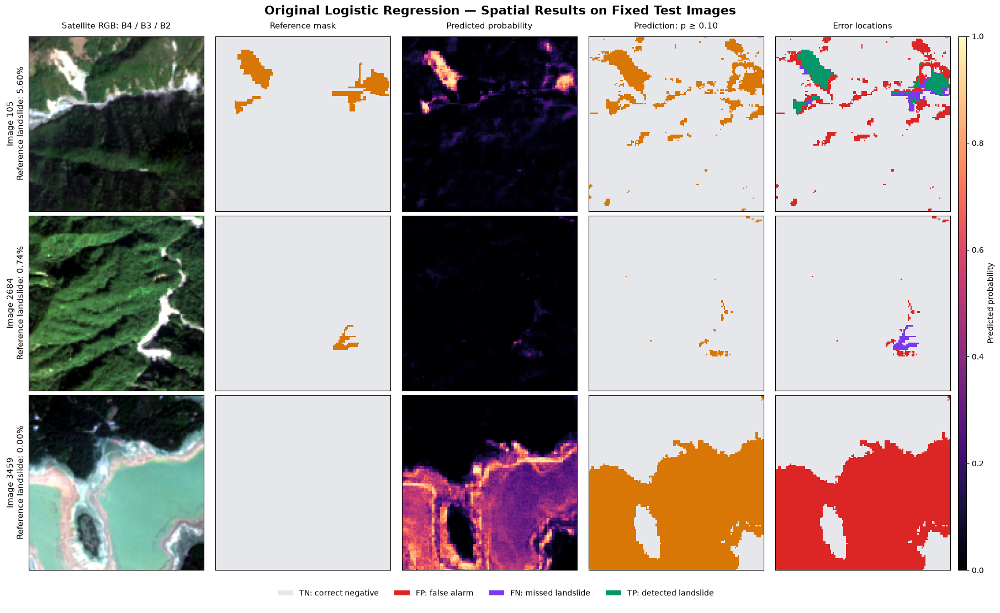

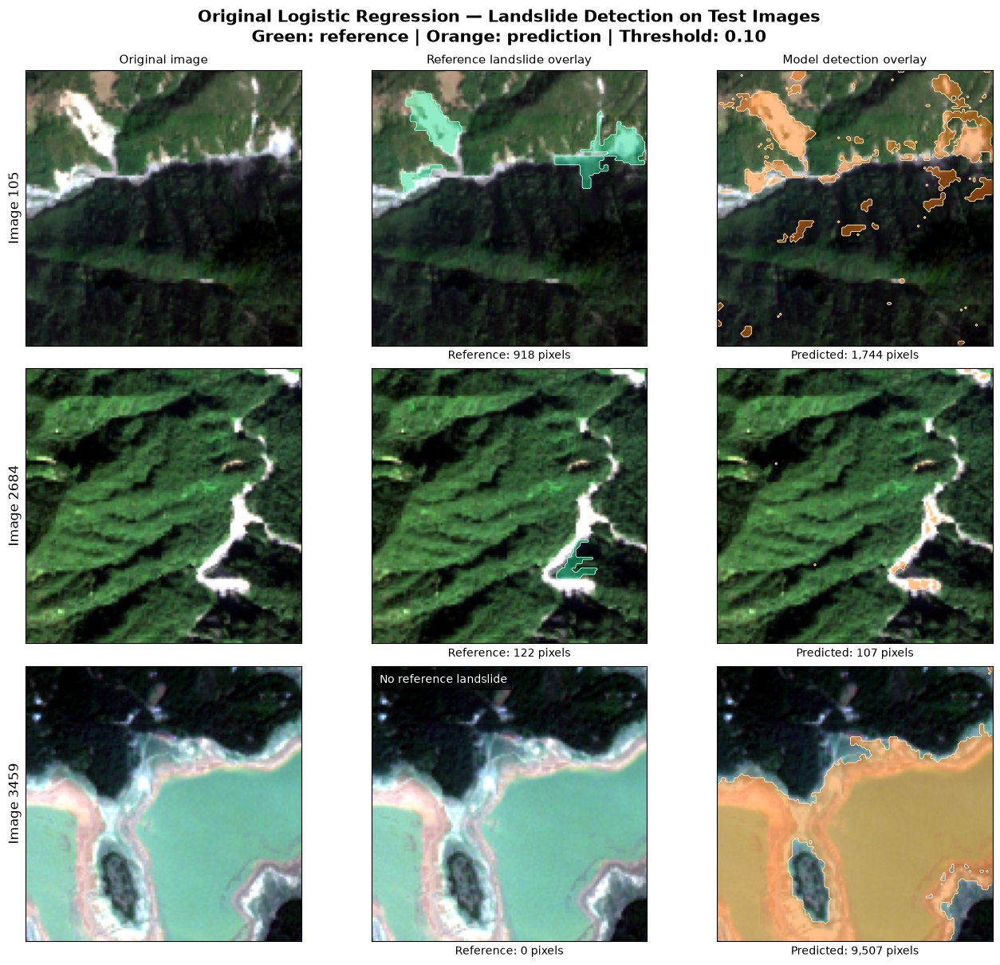

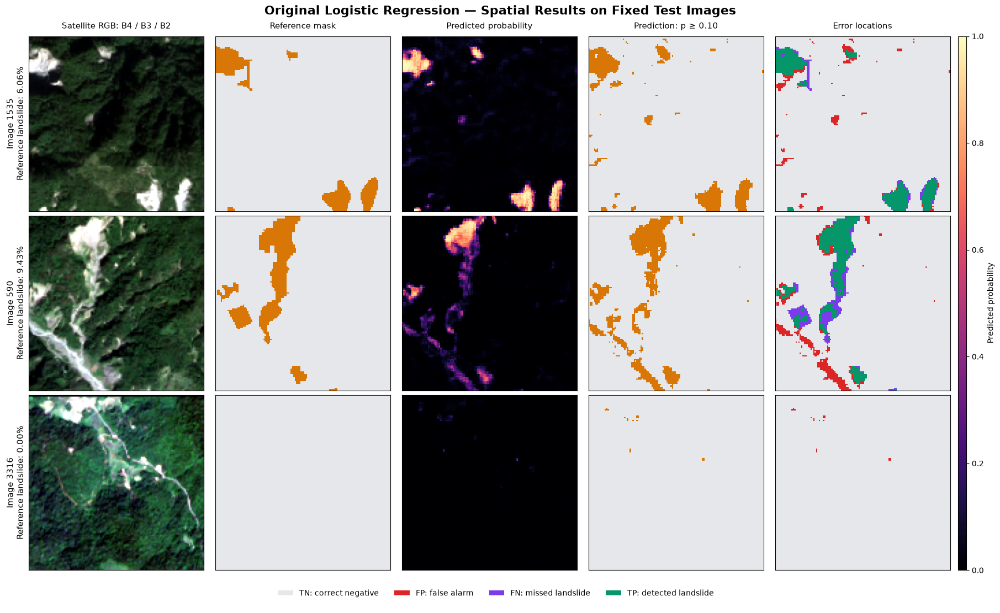

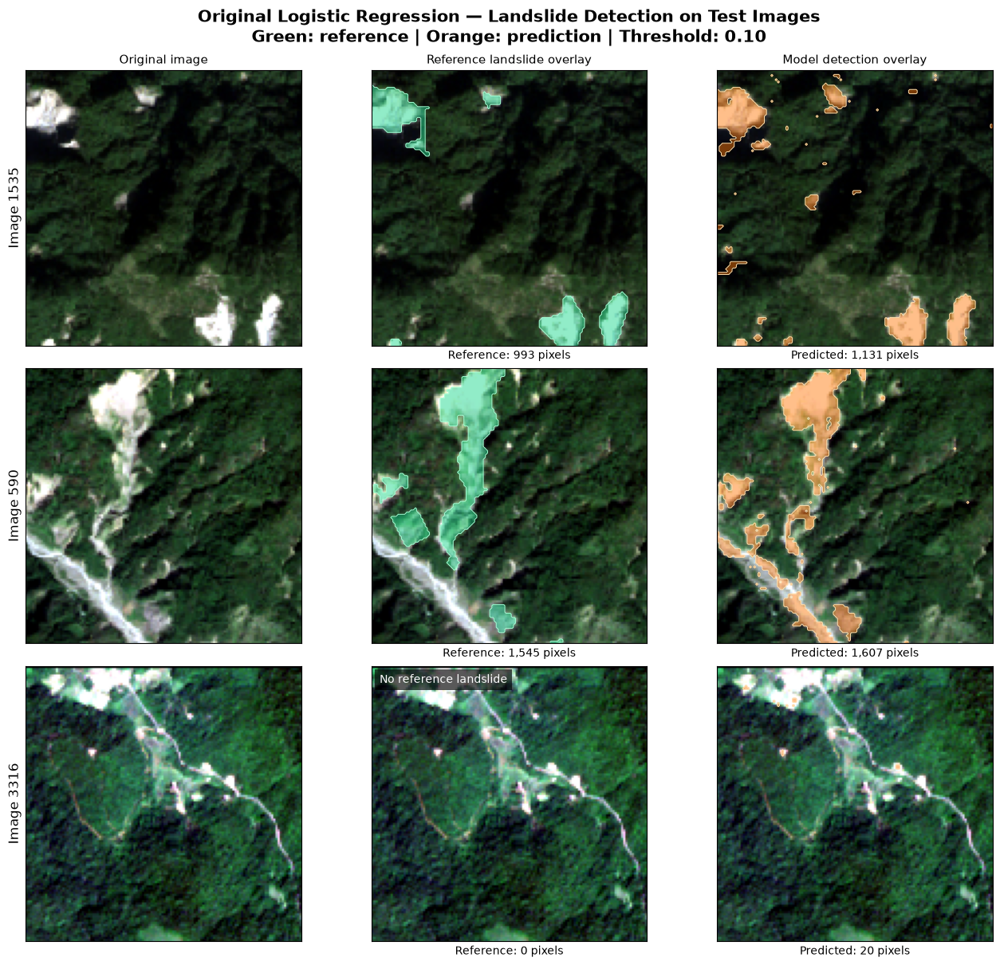

Original Logistic Regression — results for the six fixed images


,Image_ID,Reference_landslide_percent,TN,FP,FN,TP,Precision,Recall,F2,IoU
0,105,5.603027,14402,1064,238,680,0.389908,0.740741,0.627770,0.343088
1,2684,0.744629,16155,107,122,0,0.000000,0.000000,0.000000,0.000000
2,3459,0.000000,6877,9507,0,0,0.000000,NaN,0.000000,0.000000
3,1535,6.060791,15109,282,144,849,0.750663,0.854985,0.831864,0.665882
4,590,9.429932,14319,520,458,1087,0.676416,0.703560,0.697958,0.526392
5,3316,0.000000,16364,20,0,0,0.000000,NaN,0.000000,0.000000


In [7]:
lr_original_fixed_image_results = lr_plot_fixed_images(
    model_title="Original Logistic Regression",
    file_prefix="lr_original",
    probabilities=lr_test_probability,
    threshold=float(lr_final_threshold),
    patch_results=lr_test_patch_results
)

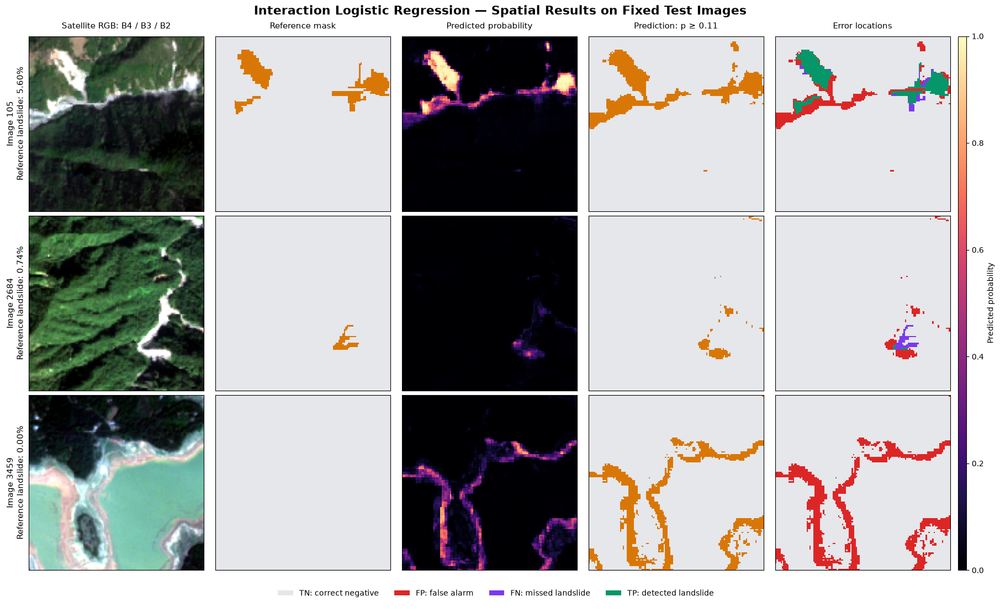

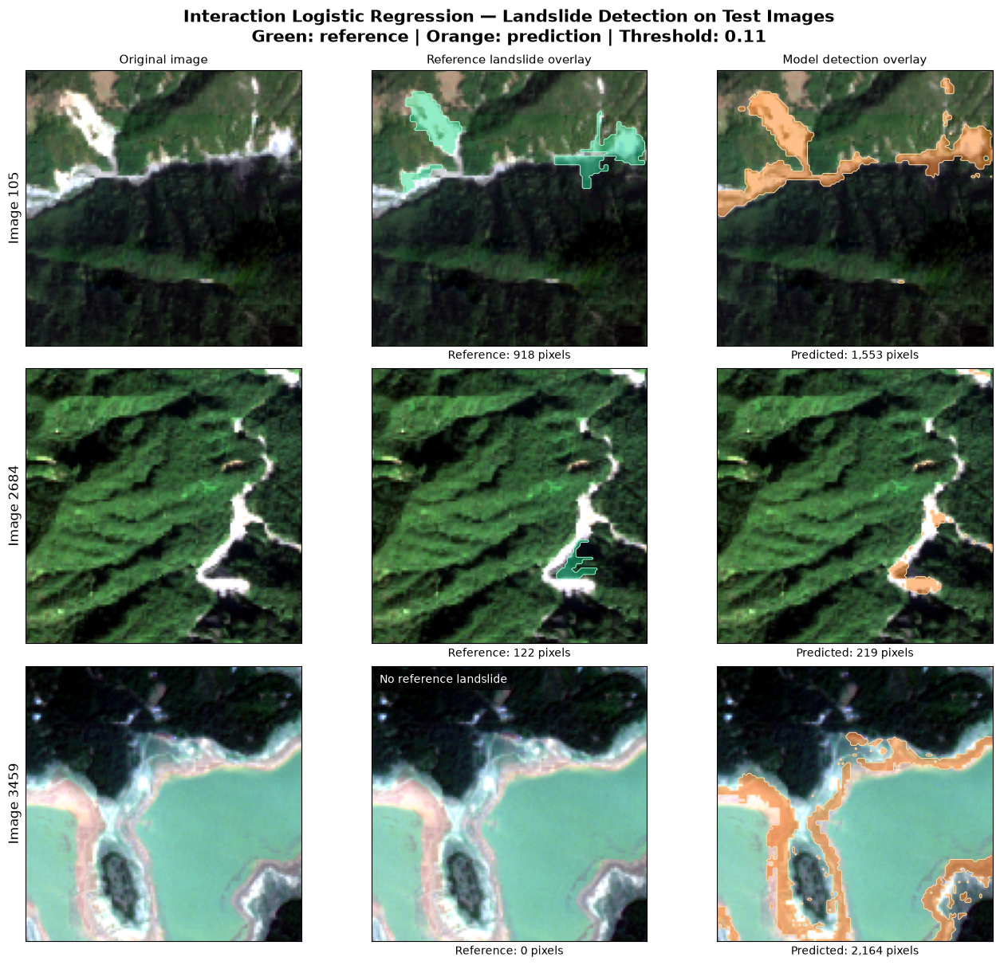

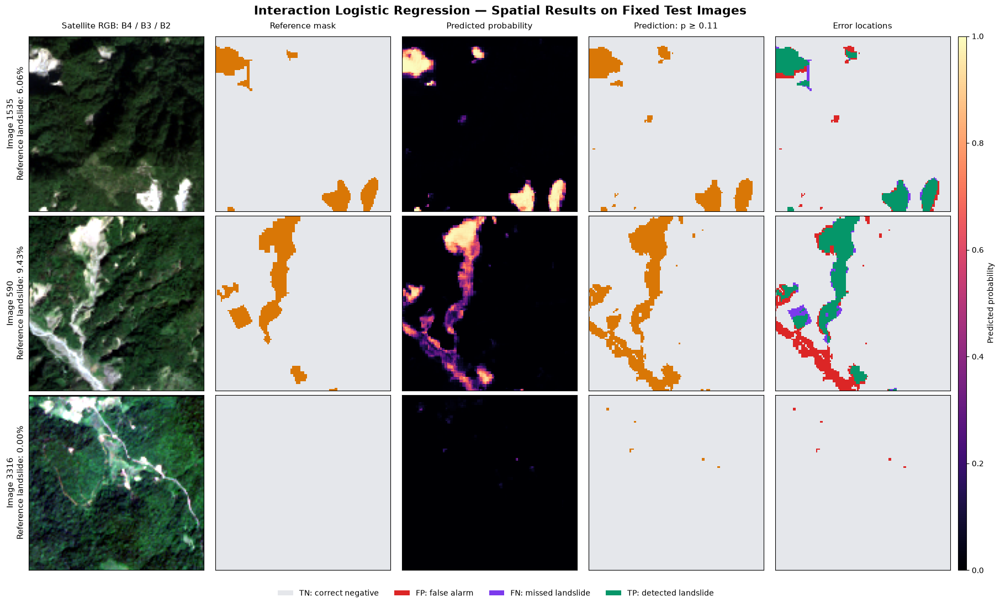

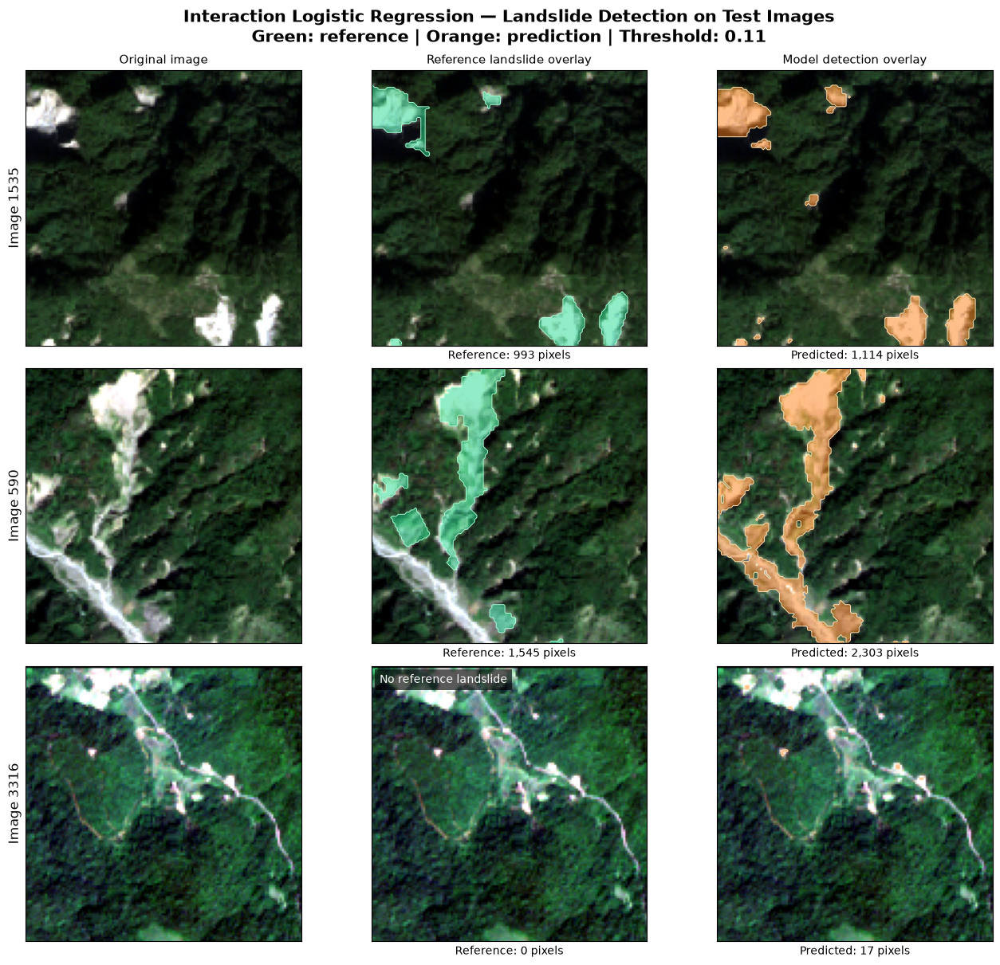

Interaction Logistic Regression — results for the six fixed images


,Image_ID,Reference_landslide_percent,TN,FP,FN,TP,Precision,Recall,F2,IoU
0,105,5.603027,14729,737,102,816,0.525435,0.888889,0.780861,0.493051
1,2684,0.744629,16054,208,111,11,0.050228,0.090164,0.077793,0.033333
2,3459,0.000000,14220,2164,0,0,0.000000,NaN,0.000000,0.000000
3,1535,6.060791,15187,204,83,910,0.816876,0.916415,0.894613,0.760234
4,590,9.429932,13889,950,192,1353,0.587495,0.875728,0.797477,0.542285
5,3316,0.000000,16367,17,0,0,0.000000,NaN,0.000000,0.000000


In [8]:
lr_interaction_fixed_image_results = lr_plot_fixed_images(
    model_title="Interaction Logistic Regression",
    file_prefix="lr_interaction",
    probabilities=lr_interaction_secondary_test_probability,
    threshold=float(lr_interaction_final_threshold),
    patch_results=lr_interaction_secondary_test_patch_results
)